In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Hackstone-proposal (2).pdf', 'Hackstone-proposal (1).pdf', 'Hackstone-proposal.pdf', 'Untitled form (File responses) (1)', 'Untitled form (File responses)', 'Untitled form.gform', 'Shortlisted team details.gsheet', 'Participant feedback form.gform', 'Participant feedback form (Responses).gsheet', 'Team Submissions Details.gsheet', 'HackStone Registrations.gsheet', 'unit 3 Data Structure .gdoc', 'unit 3 Data Structure .pdf', 'Unit 3 software assurance.gdoc', 'Unit 4 software assurance .gdoc', 'Unit 3 introduction to .gdoc', 'Unit 3 introduction to .pdf', 'Project Synopsis.docx', 'Screenshot (338).png', 'Screenshot (339).png', 'Grassland trip', 'CSS_LAB 1.gdoc', 'Untitled spreadsheet.gsheet', 'Budget_Expenses.gsheet', 'Budget_Expenses.pdf', 'Client-Side-Assignment 1.gdoc', 'Client-Side-Assignment 1.pdf', 'Colab Notebooks', 'Dataset_B_Final_Audit_Report.gdoc', 'Muscular_Dystrophy_Project']


In [ ]:
project_path = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

print(os.listdir(project_path))

['01_Project_Planning', '02_Dataset_Audit', '03_Literature_Review', '04_Preprocessing', '05_Baseline_Model', '06_Advanced_Model', '07_Evaluation_Explainability', '08_Report', '09_Figures', '10_Final_Submission']


In [ ]:

from pathlib import Path

# Main project folder
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

# Dataset folders
AUDIT_DIR = PROJECT_DIR / "02_Dataset_Audit"

DATASET_A = AUDIT_DIR / "Dataset_A_MRI"
DATASET_B = AUDIT_DIR / "Dataset_B_FSHD_Ultrasound"

# Original files folders
A_ORIGINAL = DATASET_A / "Original_Files"
B_ORIGINAL = DATASET_B / "Original_Files"

# Check that the folders exist
print("Dataset A folder exists:", A_ORIGINAL.exists())
print("Dataset B folder exists:", B_ORIGINAL.exists())

# Display files stored in each folder
for name, folder in [
    ("DATASET A - MRI", A_ORIGINAL),
    ("DATASET B - FSHD ULTRASOUND", B_ORIGINAL)
]:
    print(f"\n===== {name} =====")

    if folder.exists():
        files = [p for p in folder.rglob("*") if p.is_file()]

        for file in files:
            size_mb = file.stat().st_size / (1024 ** 2)
            print(f"{file.name} — {size_mb:.2f} MB")

        if not files:
            print("No files found. Please check the upload.")
    else:
        print("Folder not found. Check the folder path.")


Dataset A folder exists: True
Dataset B folder exists: True

===== DATASET A - MRI =====
Benchmark Diagnostic MRI and Medical Imaging Dataset.zip — 876.20 MB

===== DATASET B - FSHD ULTRASOUND =====
Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy A novel pathway for musculoskeletal ultrasound analysis.zip — 2664.30 MB


In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

PREPROCESS_DIR = PROJECT_DIR / "04_Preprocessing"

print("Preprocessing folder exists:", PREPROCESS_DIR.exists())
print("\nFiles and folders found:\n")

for path in sorted(PREPROCESS_DIR.iterdir()):
    item_type = "FOLDER" if path.is_dir() else "FILE"
    print(f"[{item_type}] {path.name}")

Preprocessing folder exists: True

Files and folders found:

[FOLDER] Dataset_B_FSHD_Preprocessing
[FILE] Dataset_B_FSHD_Preprocessing_Rupam.ipynb


In [ ]:
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "04_Preprocessing/Dataset_B_FSHD_Preprocessing"
)

print("Output folder exists:", OUTPUT_DIR.exists())
print("\nContents:\n")

for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_dir():
        print(f"[FOLDER] {path.name}")
    else:
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"[FILE] {path.name} — {size_mb:.2f} MB")

Output folder exists: True

Contents:

[FOLDER] processed_masks
[FOLDER] reports
[FOLDER] splits


In [ ]:
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "04_Preprocessing/Dataset_B_FSHD_Preprocessing"
)

for folder_name in ["processed_masks", "reports", "splits"]:
    folder = OUTPUT_DIR / folder_name

    print(f"\n{'=' * 50}")
    print(f"FOLDER: {folder_name}")
    print(f"{'=' * 50}")

    files = sorted(p for p in folder.rglob("*") if p.is_file())

    print("Total files:", len(files))

    for file in files[:30]:
        print(file.relative_to(OUTPUT_DIR))

    if len(files) > 30:
        print(f"... and {len(files) - 30} more files")


FOLDER: processed_masks
Total files: 25005
processed_masks/00006_001_00_1.png
processed_masks/00006_001_00_2.png
processed_masks/00006_001_00_3.png
processed_masks/00006_001_01_1.png
processed_masks/00006_001_01_2.png
processed_masks/00006_001_01_3.png
processed_masks/00006_001_01_4.png
processed_masks/00006_004_00_1.png
processed_masks/00006_004_00_2.png
processed_masks/00006_004_00_3.png
processed_masks/00006_004_01_1.png
processed_masks/00006_004_01_2.png
processed_masks/00006_004_01_3.png
processed_masks/00006_008_00_1.png
processed_masks/00006_008_00_2.png
processed_masks/00006_008_00_3.png
processed_masks/00006_008_00_4.png
processed_masks/00006_008_01_1.png
processed_masks/00006_008_01_2.png
processed_masks/00006_008_01_3.png
processed_masks/00006_009_00_1.png
processed_masks/00006_009_00_2.png
processed_masks/00006_009_00_3.png
processed_masks/00006_009_00_4.png
processed_masks/00006_011_00_1.png
processed_masks/00006_011_00_2.png
processed_masks/00006_011_00_3.png
processed_m

In [ ]:

import zipfile
from collections import Counter
from pathlib import Path

def inspect_zip(zip_path, max_examples=15):
    zip_path = Path(zip_path)

    print("\n" + "=" * 60)
    print("ZIP FILE:", zip_path.name)

    with zipfile.ZipFile(zip_path, "r") as archive:
        files = [
            item for item in archive.infolist()
            if not item.is_dir()
        ]

        print("Total files inside:", len(files))

        total_size_mb = sum(
            item.file_size for item in files
        ) / (1024 ** 2)

        print(f"Uncompressed size: {total_size_mb:.2f} MB")

        extensions = Counter(
            Path(item.filename).suffix.lower() or "[no extension]"
            for item in files
        )

        print("\nFile extensions:")
        for extension, count in extensions.most_common():
            print(f"{extension}: {count}")

        print(f"\nFirst {max_examples} file paths:")
        for item in files[:max_examples]:
            print(item.filename)


# Locate the two downloaded ZIP archives
zip_A = list(A_ORIGINAL.rglob("*.zip"))
zip_B = list(B_ORIGINAL.rglob("*.zip"))

print("Dataset A ZIP files found:", len(zip_A))
print("Dataset B ZIP files found:", len(zip_B))


Dataset A ZIP files found: 1
Dataset B ZIP files found: 1


In [ ]:

if len(zip_A) == 1:
    inspect_zip(zip_A[0], max_examples=15)
elif len(zip_A) == 0:
    print("No ZIP file found in Dataset A.")
else:
    print("Multiple ZIP files found in Dataset A:")
    for i, path in enumerate(zip_A):
        print(i, path.name)
    print("We need to select the main archive before inspecting it.")



ZIP FILE: Benchmark Diagnostic MRI and Medical Imaging Dataset.zip
Total files inside: 40
Uncompressed size: 934.33 MB

File extensions:
.zip: 40

First 15 file paths:
Benchmark Diagnostic MRI and Medical Imaging Dataset/Medical Imaging Dataset/Neurofibromatosis Type 1 (NF1) with Optic Glioma and Intracranial Extension.zip
Benchmark Diagnostic MRI and Medical Imaging Dataset/Medical Imaging Dataset/Typical Adrenoleukodystrophy.zip
Benchmark Diagnostic MRI and Medical Imaging Dataset/Medical Imaging Dataset/Tuberous Sclerosis.zip
Benchmark Diagnostic MRI and Medical Imaging Dataset/Medical Imaging Dataset/Sjögrens Syndrome.zip
Benchmark Diagnostic MRI and Medical Imaging Dataset/Medical Imaging Dataset/Gamekeepers Thumb.zip
Benchmark Diagnostic MRI and Medical Imaging Dataset/Medical Imaging Dataset/Two-Week Follow-Up with Spectroscopy.zip
Benchmark Diagnostic MRI and Medical Imaging Dataset/Medical Imaging Dataset/Retinoblastoma with Intracranial Spread Along Cranial Nerve.zip
Benchma

In [ ]:

if len(zip_B) == 1:
    inspect_zip(zip_B[0], max_examples=15)
elif len(zip_B) == 0:
    print("No ZIP file found in Dataset B.")
else:
    print("Multiple ZIP files found in Dataset B:")
    for i, path in enumerate(zip_B):
        print(i, path.name)
    print("We need to select the main archive before inspecting it.")



ZIP FILE: Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy A novel pathway for musculoskeletal ultrasound analysis.zip
Total files inside: 8
Uncompressed size: 2670.28 MB

File extensions:
.zip: 6
.xlsx: 1
.txt: 1

First 15 file paths:
Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy A novel pathway for musculoskeletal ultrasound analysis/images.zip
Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy A novel pathway for musculoskeletal ultrasound analysis/masks.zip
Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy A novel pathway for musculoskeletal ultrasound analysis/XGB_models.zip
Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy A novel pathway for musculoskeletal ultrasound analysis/SubjectsInfo.xlsx
Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy A novel pathway for musculoskeletal 

In [ ]:

import zipfile
from pathlib import Path

# Find the main Dataset B ZIP
zip_B = list(B_ORIGINAL.rglob("*.zip"))

if len(zip_B) != 1:
    print("Expected one main ZIP. Found:", len(zip_B))

else:
    with zipfile.ZipFile(zip_B[0], "r") as archive:
        readme_files = [
            name for name in archive.namelist()
            if Path(name).name.lower() == "readme.txt"
        ]

        if not readme_files:
            print("README.txt was not found inside the ZIP.")
        else:
            readme_name = readme_files[0]

            print("README path:", readme_name)
            print("\n========== README CONTENT ==========\n")

            readme_text = archive.read(readme_name).decode(
                "utf-8", errors="replace"
            )

            print(readme_text)


README path: Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy A novel pathway for musculoskeletal ultrasound analysis/README.txt

========== README CONTENT ==========

If you find this dataset useful, please cite:

@article{MARZOLA2025,
  title   = {Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy: A novel pathway for musculoskeletal ultrasound analysis},
  journal = {Clinical Neurophysiology},
  year    = {2025},
  issn    = {1388-2457},
  doi     = {https://doi.org/10.1016/j.clinph.2025.01.016},
  url     = {https://www.sciencedirect.com/science/article/pii/S1388245725000367},
  author  = {Francesco Marzola and Nens {van Alfen} and Jonne Doorduin and Kristen Mariko Meiburger},
  keywords= {Muscle ultrasound, Machine learning, Muscle segmentation, Heckmatt grading, Neuromuscular disease diagnosis}
}

@article{MARZOLA2021104623,
  title   = {Deep learning segmentation of transverse musculoskeletal ultrasound images for

In [ ]:

import zipfile
from pathlib import Path
import pandas as pd

# Find the main Dataset B ZIP
zip_B = list(B_ORIGINAL.rglob("*.zip"))

if len(zip_B) != 1:
    print("Expected one main Dataset B ZIP. Found:", len(zip_B))

else:
    with zipfile.ZipFile(zip_B[0], "r") as archive:

        excel_files = [
            name for name in archive.namelist()
            if Path(name).name.lower() == "subjectsinfo.xlsx"
        ]

        if not excel_files:
            print("SubjectsInfo.xlsx was not found.")
        else:
            excel_name = excel_files[0]

            # Read the spreadsheet directly from the ZIP
            with archive.open(excel_name) as excel_file:
                workbook = pd.ExcelFile(excel_file)

                print("Sheets:", workbook.sheet_names)

                for sheet in workbook.sheet_names:
                    df = pd.read_excel(workbook, sheet_name=sheet)

                    print("\nSheet:", sheet)
                    print("Rows and columns:", df.shape)
                    print("\nColumn names:")
                    print(df.columns.tolist())

                    print("\nFirst 5 rows:")
                    display(df.head())


Sheets: ['Sheet1']

Sheet: Sheet1
Rows and columns: (110, 20)

Column names:
['Code', 'Sex', 'age', 'BMI', 'Weight', 'Length', '019_00', '019_01', '001_00', '001_01', '015_00', '015_01', '016_00', '016_01', '020_00', '020_01', '018_00', '018_01', '008_00', '008_01']

First 5 rows:


,Code,Sex,age,BMI,Weight,Length,019_00,019_01,001_00,001_01,015_00,015_01,016_00,016_01,020_00,020_01,018_00,018_01,008_00,008_01
0,6,0,49,30.79,110,189,3.0,3.0,3.0,3.0,2.0,2.0,3.0,3.0,4.0,4.0,4.0,4.0,2.0,2.0
1,13,1,77,32.87,95,170,NaN,NaN,3.0,3.0,NaN,NaN,3.0,3.0,4.0,4.0,4.0,3.0,2.0,2.0
2,19,0,42,22.40,75,183,3.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,25,0,57,26.59,96,190,3.0,3.0,1.0,1.0,2.0,2.0,1.0,2.0,1.0,2.0,3.0,2.0,2.0,2.0
4,76,1,59,28.65,78,165,3.0,3.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,3.0


In [ ]:

import zipfile
from pathlib import Path

B_ORIGINAL = DATASET_B / "Original_Files"
B_EXTRACTED = DATASET_B / "Extracted_Files"

# Create a separate folder for documentation and metadata
METADATA_DIR = B_EXTRACTED / "Metadata"
METADATA_DIR.mkdir(parents=True, exist_ok=True)

zip_B = list(B_ORIGINAL.rglob("*.zip"))

if len(zip_B) != 1:
    print("Expected one main Dataset B ZIP. Found:", len(zip_B))

else:
    with zipfile.ZipFile(zip_B[0], "r") as archive:

        wanted_files = {
            "readme.txt",
            "subjectsinfo.xlsx"
        }

        for member in archive.infolist():
            if (
                not member.is_dir()
                and Path(member.filename).name.lower() in wanted_files
            ):
                destination = METADATA_DIR / Path(member.filename).name

                if destination.exists():
                    print("Already exists; skipping:", destination.name)
                    continue

                with archive.open(member) as source:
                    destination.write_bytes(source.read())

                print("Saved:", destination)

print("\nMetadata folder:", METADATA_DIR)


Saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Metadata/SubjectsInfo.xlsx
Saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Metadata/README.txt

Metadata folder: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Metadata


In [ ]:

for file in sorted(METADATA_DIR.iterdir()):
    if file.is_file():
        print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")


README.txt - 4.83 KB
SubjectsInfo.xlsx - 13.14 KB


In [ ]:

import zipfile
from pathlib import Path
from collections import Counter

# Find the main Dataset B ZIP
main_zips = list(B_ORIGINAL.rglob("*.zip"))

if len(main_zips) != 1:
    print("Expected one main Dataset B ZIP. Found:", len(main_zips))
else:
    with zipfile.ZipFile(main_zips[0], "r") as archive:
        for target_name in ["images.zip", "masks.zip"]:
            matches = [
                name for name in archive.namelist()
                if Path(name).name.lower() == target_name
            ]

            print("\n" + "=" * 50)
            print("TARGET:", target_name)

            if len(matches) != 1:
                print("Expected one matching file. Found:", len(matches))
                for name in matches:
                    print(name)
                continue

            member = matches[0]
            info = archive.getinfo(member)

            print("Archive path:", member)
            print("Compressed size (MB):",
                  round(info.compress_size / (1024 ** 2), 2))
            print("Uncompressed size (MB):",
                  round(info.file_size / (1024 ** 2), 2))

            # Open the nested ZIP in memory; do not extract it
            with archive.open(member) as nested_file:
                with zipfile.ZipFile(nested_file, "r") as nested:
                    files = [
                        item for item in nested.infolist()
                        if not item.is_dir()
                    ]

                    print("Files inside:", len(files))

                    extensions = Counter(
                        Path(item.filename).suffix.lower()
                        or "[no extension]"
                        for item in files
                    )
                    print("Extensions:", dict(extensions))

                    print("First 10 paths:")
                    for item in files[:10]:
                        print(" ", item.filename)



TARGET: images.zip
Archive path: Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy A novel pathway for musculoskeletal ultrasound analysis/images.zip
Compressed size (MB): 2648.4
Uncompressed size (MB): 2649.53
Files inside: 25005
Extensions: {'.png': 25005}
First 10 paths:
  images/00076_020_01_2.png
  images/00149_011_00_2.png
  images/00151_015_00_1.png
  images/00158_015_00_1.png
  images/00199_021_01_2.png
  images/00205_016_01_2.png
  images/00225_001_01_1.png
  images/00225_003_00_1.png
  images/00231_015_01_3.png
  images/00248_009_01_1.png

TARGET: masks.zip
Archive path: Machine learning-driven Heckmatt grading in facioscapulohumeral muscular dystrophy A novel pathway for musculoskeletal ultrasound analysis/masks.zip
Compressed size (MB): 15.13
Uncompressed size (MB): 19.88
Files inside: 25005
Extensions: {'.png': 25005}
First 10 paths:
  masks/00076_020_01_2.png
  masks/00149_011_00_2.png
  masks/00151_015_00_1.png
  masks/00158_015_00_1.png

In [ ]:

import zipfile
from pathlib import Path

def get_nested_zip_names(main_zip_path, target_name):
    with zipfile.ZipFile(main_zip_path, "r") as outer:
        matches = [
            name for name in outer.namelist()
            if Path(name).name.lower() == target_name.lower()
        ]

        if len(matches) != 1:
            raise ValueError(
                f"Expected one {target_name}, found {len(matches)}"
            )

        with outer.open(matches[0]) as nested_file:
            with zipfile.ZipFile(nested_file, "r") as nested:
                return {
                    Path(name).name
                    for name in nested.namelist()
                    if not name.endswith("/")
                    and name.lower().endswith(".png")
                }

# Find the main Dataset B ZIP
main_zips = list(B_ORIGINAL.rglob("*.zip"))

if len(main_zips) != 1:
    print("Expected one main ZIP. Found:", len(main_zips))
else:
    main_zip = main_zips[0]

    image_names = get_nested_zip_names(main_zip, "images.zip")
    mask_names = get_nested_zip_names(main_zip, "masks.zip")

    images_without_masks = sorted(image_names - mask_names)
    masks_without_images = sorted(mask_names - image_names)

    print("Image PNG files:", len(image_names))
    print("Mask PNG files:", len(mask_names))
    print("Images without matching masks:", len(images_without_masks))
    print("Masks without matching images:", len(masks_without_images))

    print("\nFirst unmatched images:", images_without_masks[:10])
    print("First unmatched masks:", masks_without_images[:10])

    if image_names == mask_names:
        print("\nSUCCESS: All image filenames have matching mask filenames.")
    else:
        print("\nWARNING: Some filenames differ. Investigate before proceeding.")


Image PNG files: 25005
Mask PNG files: 25005
Images without matching masks: 0
Masks without matching images: 0

First unmatched images: []
First unmatched masks: []

SUCCESS: All image filenames have matching mask filenames.


In [ ]:

import shutil
from pathlib import Path

# Check Colab's temporary disk
disk = shutil.disk_usage("/content")

print("===== COLAB RUNTIME DISK =====")
print(f"Total: {disk.total / (1024**3):.2f} GB")
print(f"Used: {disk.used / (1024**3):.2f} GB")
print(f"Free: {disk.free / (1024**3):.2f} GB")

# Check the Google Drive folders used by this project
print("\n===== GOOGLE DRIVE DATASET FOLDERS =====")

for folder in [B_ORIGINAL, B_EXTRACTED]:
    print(f"\n{folder}")
    print("Exists:", folder.exists())

    if folder.exists():
        total_bytes = sum(
            p.stat().st_size
            for p in folder.rglob("*")
            if p.is_file()
        )
        print(f"Current files: {total_bytes / (1024**3):.2f} GB")


===== COLAB RUNTIME DISK =====
Total: 107.72 GB
Used: 23.12 GB
Free: 84.58 GB

===== GOOGLE DRIVE DATASET FOLDERS =====

/content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Original_Files
Exists: True
Current files: 2.60 GB

/content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files
Exists: True
Current files: 0.00 GB


In [ ]:

from pathlib import Path

B_EXTRACTED = DATASET_B / "Extracted_Files"

IMAGES_DIR = B_EXTRACTED / "Images"
MASKS_DIR = B_EXTRACTED / "Masks"

IMAGES_DIR.mkdir(parents=True, exist_ok=True)
MASKS_DIR.mkdir(parents=True, exist_ok=True)

print("Images destination:", IMAGES_DIR)
print("Masks destination:", MASKS_DIR)

print("\nImages folder exists:", IMAGES_DIR.exists())
print("Masks folder exists:", MASKS_DIR.exists())


Images destination: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Images
Masks destination: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Masks

Images folder exists: True
Masks folder exists: True


In [ ]:

import zipfile
from pathlib import Path

def extract_nested_zip(main_zip_path, target_name, destination):
    main_zip_path = Path(main_zip_path)
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)

    # Avoid accidental overwriting or duplicate extraction
    if any(destination.iterdir()):
        print(f"STOP: Destination is not empty: {destination}")
        print("Inspect the folder before extracting again.")
        return

    with zipfile.ZipFile(main_zip_path, "r") as outer:
        matches = [
            name for name in outer.namelist()
            if Path(name).name.lower() == target_name.lower()
        ]

        if len(matches) != 1:
            raise ValueError(
                f"Expected one {target_name}; found {len(matches)}"
            )

        nested_name = matches[0]

        with outer.open(nested_name) as nested_file:
            with zipfile.ZipFile(nested_file, "r") as nested:
                root = destination.resolve()

                # Validate archive paths before extracting
                for member in nested.infolist():
                    target = (
                        destination / member.filename
                    ).resolve()

                    if target != root and root not in target.parents:
                        raise ValueError(
                            f"Unsafe path: {member.filename}"
                        )

                nested.extractall(destination)

    print(f"Successfully extracted {target_name}")
    print(f"Destination: {destination}")


main_zips = list(B_ORIGINAL.rglob("*.zip"))

if len(main_zips) != 1:
    print("Expected one main Dataset B ZIP. Found:", len(main_zips))
else:
    main_zip = main_zips[0]

    extract_nested_zip(main_zip, "images.zip", IMAGES_DIR)
    extract_nested_zip(main_zip, "masks.zip", MASKS_DIR)


Successfully extracted images.zip
Destination: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Images
Successfully extracted masks.zip
Destination: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Masks


In [ ]:

from pathlib import Path

IMAGES_DIR = DATASET_B / "Extracted_Files" / "Images"
MASKS_DIR = DATASET_B / "Extracted_Files" / "Masks"

def inspect_folder(folder):
    print(f"\n===== {folder.name} =====")
    print("Path:", folder)
    print("Exists:", folder.exists())

    if not folder.exists():
        return

    items = list(folder.iterdir())
    print("Items directly inside:", len(items))

    for item in items[:10]:
        kind = "Folder" if item.is_dir() else "File"
        print(f"{kind}: {item.name}")

    all_files = [p for p in folder.rglob("*") if p.is_file()]
    png_files = [p for p in all_files if p.suffix.lower() == ".png"]

    print("Total files recursively:", len(all_files))
    print("PNG files recursively:", len(png_files))

inspect_folder(IMAGES_DIR)
inspect_folder(MASKS_DIR)



===== Images =====
Path: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Images
Exists: True
Items directly inside: 1
Folder: images
Total files recursively: 25005
PNG files recursively: 25005

===== Masks =====
Path: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Masks
Exists: True
Items directly inside: 1
Folder: masks
Total files recursively: 25005
PNG files recursively: 25005


In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np

IMAGES_DIR = DATASET_B / "Extracted_Files" / "Images"
MASKS_DIR = DATASET_B / "Extracted_Files" / "Masks"

image_root = IMAGES_DIR / "images"
mask_root = MASKS_DIR / "masks"

image_files = sorted(image_root.glob("*.png"))

print("Total images:", len(image_files))
print("Total masks:", len(list(mask_root.glob("*.png"))))

for image_path in image_files[:5]:
    mask_path = mask_root / image_path.name

    print(f"\nImage: {image_path.name}")

    if not mask_path.exists():
        print("ERROR: Matching mask not found!")
        continue

    with Image.open(image_path) as img:
        image_array = np.array(img)

    with Image.open(mask_path) as mask:
        mask_array = np.array(mask)

    print("Image shape:", image_array.shape)
    print("Image dtype:", image_array.dtype)
    print("Mask shape:", mask_array.shape)
    print("Mask dtype:", mask_array.dtype)
    print("Mask pixel values:", np.unique(mask_array))
    print("Image and mask dimensions match:",
          image_array.shape == mask_array.shape)


Total images: 25005
Total masks: 25005

Image: 00006_001_00_1.png
Image shape: (512, 512)
Image dtype: uint8
Mask shape: (512, 512)
Mask dtype: uint8
Mask pixel values: [  0 255]
Image and mask dimensions match: True

Image: 00006_001_00_2.png
Image shape: (512, 512)
Image dtype: uint8
Mask shape: (512, 512)
Mask dtype: uint8
Mask pixel values: [  0 255]
Image and mask dimensions match: True

Image: 00006_001_00_3.png
Image shape: (512, 512)
Image dtype: uint8
Mask shape: (512, 512)
Mask dtype: uint8
Mask pixel values: [  0 255]
Image and mask dimensions match: True

Image: 00006_001_01_1.png
Image shape: (512, 512)
Image dtype: uint8
Mask shape: (512, 512)
Mask dtype: uint8
Mask pixel values: [  0 255]
Image and mask dimensions match: True

Image: 00006_001_01_2.png
Image shape: (512, 512)
Image dtype: uint8
Mask shape: (512, 512)
Mask dtype: uint8
Mask pixel values: [  0 255]
Image and mask dimensions match: True


Image-mask pair: 00006_001_00_1.png
Image-mask pair: 00006_001_00_2.png
Image-mask pair: 00006_001_00_3.png


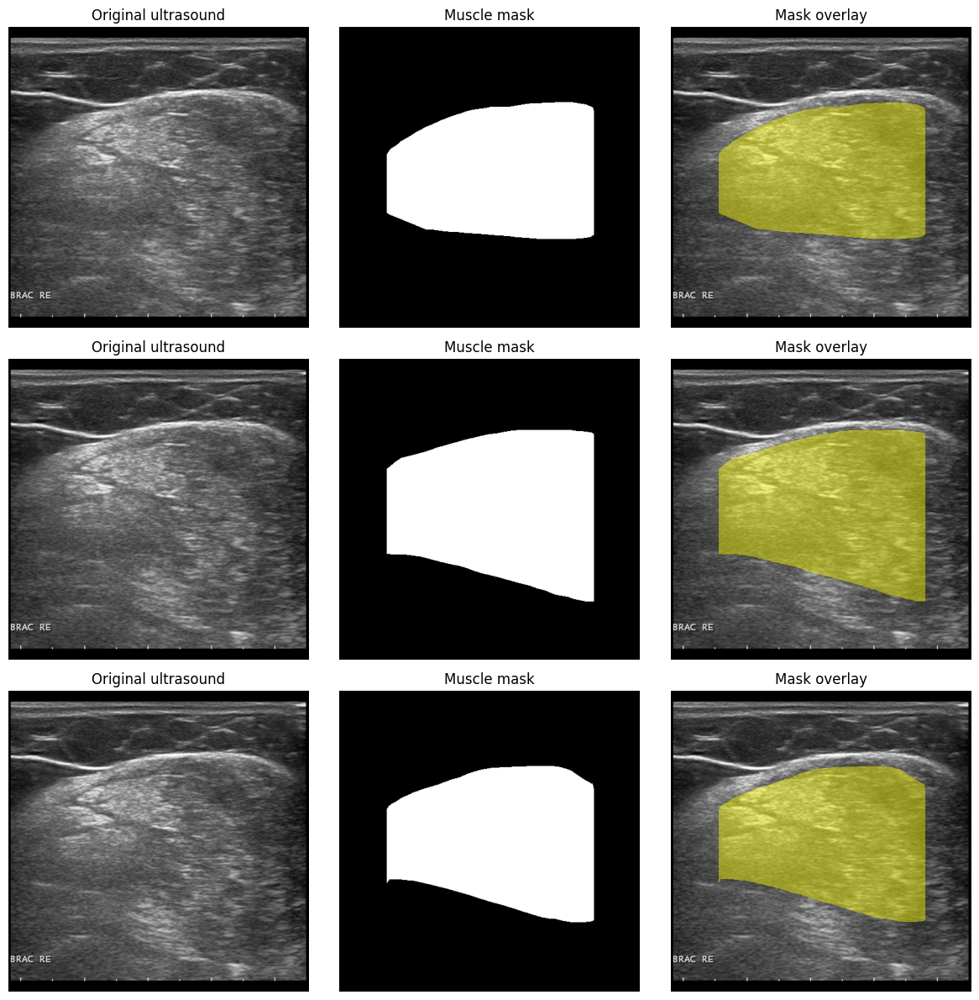

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

image_root = DATASET_B / "Extracted_Files" / "Images" / "images"
mask_root = DATASET_B / "Extracted_Files" / "Masks" / "masks"

sample_files = sorted(image_root.glob("*.png"))[:3]

fig, axes = plt.subplots(
    len(sample_files), 3,
    figsize=(12, 4 * len(sample_files))
)

if len(sample_files) == 1:
    axes = np.expand_dims(axes, axis=0)

for i, image_path in enumerate(sample_files):
    mask_path = mask_root / image_path.name

    with Image.open(image_path) as img:
        image = np.array(img)

    with Image.open(mask_path) as mask:
        mask = np.array(mask)

    # Overlay the mask boundary on the original image
    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title("Original ultrasound")

    axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("Muscle mask")

    axes[i, 2].imshow(image, cmap="gray")
    axes[i, 2].imshow(
        np.ma.masked_where(mask == 0, mask),
        cmap="spring",
        alpha=0.45,
        vmin=0,
        vmax=255
    )
    axes[i, 2].set_title("Mask overlay")

    for ax in axes[i]:
        ax.axis("off")

    print("Image-mask pair:", image_path.name)

plt.tight_layout()
plt.show()


In [ ]:

import zipfile
from pathlib import Path

A_ORIGINAL = DATASET_A / "Original_Files"

main_zips = list(A_ORIGINAL.rglob("*.zip"))

print("Main ZIP files found:", len(main_zips))

for path in main_zips:
    print(path.name)

if len(main_zips) == 1:
    main_zip = main_zips[0]

    with zipfile.ZipFile(main_zip, "r") as archive:
        nested_archives = [
            item for item in archive.infolist()
            if not item.is_dir()
            and item.filename.lower().endswith(".zip")
        ]

        print("\nNested ZIP archive count:", len(nested_archives))
        print("\nAvailable archives:")

        for i, item in enumerate(
            sorted(nested_archives, key=lambda x: x.filename.lower()),
            start=1
        ):
            print(
                f"{i:02d}. {Path(item.filename).name}"
                f" | {item.file_size / (1024**2):.2f} MB uncompressed"
            )


Main ZIP files found: 1
Benchmark Diagnostic MRI and Medical Imaging Dataset.zip

Nested ZIP archive count: 40

Available archives:
01. Acute Cerebellitis in HIV.zip | 33.77 MB uncompressed
02. Acute Unilateral Cerebellitis in HIV.zip | 17.13 MB uncompressed
03. Adenomyosis in Gravid Uterus.zip | 11.95 MB uncompressed
04. Balloon Cell Cortical Dysplasia.zip | 35.54 MB uncompressed
05. Bilateral Osgood-Schlatter Disease with Chronic Inflammatory Arthritis.zip | 23.88 MB uncompressed
06. Bilateral Ulnar Impaction Syndrome.zip | 17.03 MB uncompressed
07. Carolis Disease.zip | 50.86 MB uncompressed
08. Congenital Toxoplasmosis.zip | 11.61 MB uncompressed
09. Congenital Vaginal Cyst.zip | 10.77 MB uncompressed
10. Dermatomyositis.zip | 15.98 MB uncompressed
11. Fukuyama Muscular Dystrophy.zip | 25.93 MB uncompressed
12. Gamekeepers Thumb.zip | 19.04 MB uncompressed
13. Hallervorden-Spatz Disease (now called Pantothenate Kinase-Associated Neurodegeneration).zip | 33.35 MB uncompressed
14. He

In [ ]:

import zipfile
from pathlib import Path
from collections import Counter

A_ORIGINAL = DATASET_A / "Original_Files"
main_zip = list(A_ORIGINAL.rglob("*.zip"))[0]

target_name = "Fukuyama Muscular Dystrophy.zip"

with zipfile.ZipFile(main_zip, "r") as outer:
    matches = [
        item.filename
        for item in outer.infolist()
        if Path(item.filename).name.lower() == target_name.lower()
    ]

    if len(matches) != 1:
        print("Expected one matching archive. Found:", len(matches))

    else:
        with outer.open(matches[0]) as nested_file:
            with zipfile.ZipFile(nested_file, "r") as inner:
                files = [
                    item for item in inner.infolist()
                    if not item.is_dir()
                ]

                print("Archive:", target_name)
                print("Total files:", len(files))
                print(
                    "Uncompressed size (MB):",
                    round(sum(item.file_size for item in files) / (1024**2), 2)
                )

                print("\nFile extensions:")
                print(Counter(
                    Path(item.filename).suffix.lower() or "[no extension]"
                    for item in files
                ))

                print("\nFirst 20 file paths:")
                for item in files[:20]:
                    print(item.filename)


Archive: Fukuyama Muscular Dystrophy.zip
Total files: 920
Uncompressed size (MB): 25.55

File extensions:
Counter({'.jpg': 920})

First 20 file paths:
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy916.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy910.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy908.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy918.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy901.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy915.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy912.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy919.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy917.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy920.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy911.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy899.jpg
Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy913.jpg
Fukuyama Muscular Dystrophy/Fu

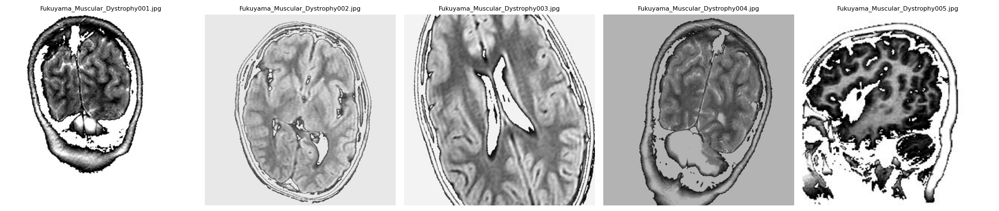

In [ ]:

import zipfile
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

A_ORIGINAL = DATASET_A / "Original_Files"
main_zip = list(A_ORIGINAL.rglob("*.zip"))[0]

target_name = "Fukuyama Muscular Dystrophy.zip"

with zipfile.ZipFile(main_zip, "r") as outer:
    matches = [
        item.filename
        for item in outer.infolist()
        if Path(item.filename).name.lower() == target_name.lower()
    ]

    if len(matches) != 1:
        print("Expected one archive. Found:", len(matches))
    else:
        with outer.open(matches[0]) as nested_file:
            with zipfile.ZipFile(nested_file, "r") as inner:
                image_files = sorted([
                    name for name in inner.namelist()
                    if name.lower().endswith((".jpg", ".jpeg"))
                ])[:5]

                fig, axes = plt.subplots(
                    1, len(image_files), figsize=(18, 4)
                )

                for ax, name in zip(axes, image_files):
                    with inner.open(name) as file:
                        with Image.open(file) as image:
                            ax.imshow(image.copy())
                            ax.set_title(Path(name).name, fontsize=8)
                            ax.axis("off")

                plt.tight_layout()
                plt.show()


In [ ]:

import zipfile
from pathlib import Path
from collections import Counter

A_ORIGINAL = DATASET_A / "Original_Files"
main_zip = list(A_ORIGINAL.rglob("*.zip"))[0]

target_name = "Dermatomyositis.zip"

with zipfile.ZipFile(main_zip, "r") as outer:
    matches = [
        item.filename
        for item in outer.infolist()
        if Path(item.filename).name.lower() == target_name.lower()
    ]

    if len(matches) != 1:
        print("Expected one matching archive. Found:", len(matches))

    else:
        with outer.open(matches[0]) as nested_file:
            with zipfile.ZipFile(nested_file, "r") as inner:
                files = [
                    item for item in inner.infolist()
                    if not item.is_dir()
                ]

                print("Archive:", target_name)
                print("Total files:", len(files))
                print(
                    "Uncompressed size (MB):",
                    round(sum(item.file_size for item in files) / (1024**2), 2)
                )

                print("\nFile extensions:")
                print(Counter(
                    Path(item.filename).suffix.lower() or "[no extension]"
                    for item in files
                ))

                print("\nFirst 15 file paths:")
                for item in files[:15]:
                    print(item.filename)


Archive: Dermatomyositis.zip
Total files: 576
Uncompressed size (MB): 15.79

File extensions:
Counter({'.jpg': 576})

First 15 file paths:
Dermatomyositis/Dermatomyositis552.jpg
Dermatomyositis/Dermatomyositis572.jpg
Dermatomyositis/Dermatomyositis569.jpg
Dermatomyositis/Dermatomyositis563.jpg
Dermatomyositis/Dermatomyositis562.jpg
Dermatomyositis/Dermatomyositis575.jpg
Dermatomyositis/Dermatomyositis559.jpg
Dermatomyositis/Dermatomyositis570.jpg
Dermatomyositis/Dermatomyositis555.jpg
Dermatomyositis/Dermatomyositis571.jpg
Dermatomyositis/Dermatomyositis574.jpg
Dermatomyositis/Dermatomyositis565.jpg
Dermatomyositis/Dermatomyositis564.jpg
Dermatomyositis/Dermatomyositis553.jpg
Dermatomyositis/Dermatomyositis560.jpg


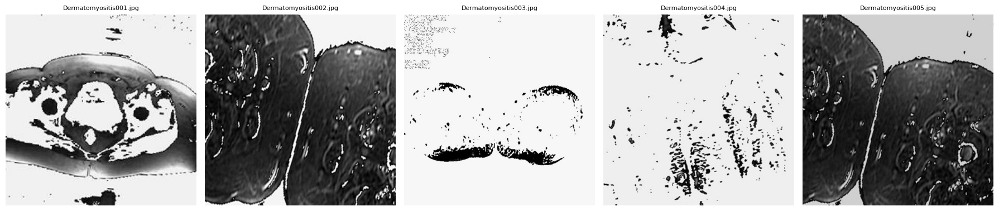

In [ ]:

import zipfile
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

A_ORIGINAL = DATASET_A / "Original_Files"
main_zip = list(A_ORIGINAL.rglob("*.zip"))[0]

target_name = "Dermatomyositis.zip"

with zipfile.ZipFile(main_zip, "r") as outer:
    matches = [
        item.filename
        for item in outer.infolist()
        if Path(item.filename).name.lower() == target_name.lower()
    ]

    if len(matches) != 1:
        print("Expected one archive. Found:", len(matches))
    else:
        with outer.open(matches[0]) as nested_file:
            with zipfile.ZipFile(nested_file, "r") as inner:
                image_files = sorted([
                    name for name in inner.namelist()
                    if name.lower().endswith((".jpg", ".jpeg"))
                ])[:5]

                fig, axes = plt.subplots(
                    1, len(image_files), figsize=(18, 4)
                )

                for ax, name in zip(axes, image_files):
                    with inner.open(name) as file:
                        with Image.open(file) as image:
                            ax.imshow(image.copy())
                            ax.set_title(Path(name).name, fontsize=8)
                            ax.axis("off")

                plt.tight_layout()
                plt.show()


In [ ]:

import zipfile
from pathlib import Path
from PIL import Image
from collections import Counter

A_ORIGINAL = DATASET_A / "Original_Files"
main_zip = list(A_ORIGINAL.rglob("*.zip"))[0]

target_name = "Dermatomyositis.zip"

with zipfile.ZipFile(main_zip, "r") as outer:
    matches = [
        item.filename
        for item in outer.infolist()
        if Path(item.filename).name.lower() == target_name.lower()
    ]

    if len(matches) != 1:
        print("Expected one archive. Found:", len(matches))

    else:
        with outer.open(matches[0]) as nested_file:
            with zipfile.ZipFile(nested_file, "r") as inner:
                image_files = [
                    name for name in inner.namelist()
                    if name.lower().endswith((".jpg", ".jpeg"))
                ]

                dimensions = Counter()
                modes = Counter()
                errors = []

                for name in image_files:
                    try:
                        with inner.open(name) as file:
                            with Image.open(file) as img:
                                img.verify()

                        with inner.open(name) as file:
                            with Image.open(file) as img:
                                dimensions[img.size] += 1
                                modes[img.mode] += 1

                    except Exception as error:
                        errors.append((name, str(error)))

                print("Total images:", len(image_files))
                print("Dimensions and counts:", dimensions)
                print("Image modes and counts:", modes)
                print("Images that failed integrity checks:", len(errors))

                for name, error in errors[:10]:
                    print("ERROR:", name, "|", error)


Total images: 576
Dimensions and counts: Counter({(512, 512): 404, (256, 256): 172})
Image modes and counts: Counter({'RGB': 576})
Images that failed integrity checks: 0


In [ ]:

import zipfile
from pathlib import Path
from collections import Counter

A_ORIGINAL = DATASET_A / "Original_Files"
main_zip = list(A_ORIGINAL.rglob("*.zip"))[0]

target_name = "Walker-Warburg Syndrome.zip"

with zipfile.ZipFile(main_zip, "r") as outer:
    matches = [
        item.filename
        for item in outer.infolist()
        if Path(item.filename).name.lower() == target_name.lower()
    ]

    if len(matches) != 1:
        print("Expected one archive. Found:", len(matches))

    else:
        with outer.open(matches[0]) as nested_file:
            with zipfile.ZipFile(nested_file, "r") as inner:
                files = [
                    item for item in inner.infolist()
                    if not item.is_dir()
                ]

                print("Archive:", target_name)
                print("Total files:", len(files))
                print(
                    "Uncompressed size (MB):",
                    round(sum(item.file_size for item in files) / (1024**2), 2)
                )

                print("\nFile extensions:")
                print(Counter(
                    Path(item.filename).suffix.lower() or "[no extension]"
                    for item in files
                ))

                print("\nFirst 15 file paths:")
                for item in files[:15]:
                    print(item.filename)


Archive: Walker-Warburg Syndrome.zip
Total files: 808
Uncompressed size (MB): 18.01

File extensions:
Counter({'.jpg': 808})

First 15 file paths:
Walker-Warburg Syndrome/Walker-Warburg_Syndrome777.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome784.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome806.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome793.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome780.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome790.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome798.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome776.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome799.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome803.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome782.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome795.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome800.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome808.jpg
Walker-Warburg Syndrome/Walker-Warburg_Syndrome791.jpg


In [ ]:

import zipfile
from pathlib import Path
from collections import Counter

A_ORIGINAL = DATASET_A / "Original_Files"
main_zip = list(A_ORIGINAL.rglob("*.zip"))[0]

target_name = "Myositis Ossificans Progressiva.zip"

with zipfile.ZipFile(main_zip, "r") as outer:
    matches = [
        item.filename
        for item in outer.infolist()
        if Path(item.filename).name.lower() == target_name.lower()
    ]

    if len(matches) != 1:
        print("Expected one archive. Found:", len(matches))
    else:
        with outer.open(matches[0]) as nested_file:
            with zipfile.ZipFile(nested_file, "r") as inner:
                files = [
                    item for item in inner.infolist()
                    if not item.is_dir()
                ]

                print("Archive:", target_name)
                print("Total files:", len(files))
                print(
                    "Uncompressed size (MB):",
                    round(sum(item.file_size for item in files) / (1024**2), 2)
                )
                print("\nFile extensions:")
                print(Counter(
                    Path(item.filename).suffix.lower() or "[no extension]"
                    for item in files
                ))
                print("\nFirst 15 file paths:")
                for item in files[:15]:
                    print(item.filename)



Archive: Myositis Ossificans Progressiva.zip
Total files: 808
Uncompressed size (MB): 22.6

File extensions:
Counter({'.jpg': 808})

First 15 file paths:
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva808.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva807.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva805.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva803.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva806.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva802.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva804.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva800.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva799.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva797.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva801.jpg
Myositis Ossificans Progressiva/Myositis_Ossificans_Progressiva79

In [ ]:

import zipfile
from pathlib import Path
from collections import Counter
import pandas as pd

A_ORIGINAL = DATASET_A / "Original_Files"
A_AUDIT = DATASET_A / "Audit_Results"
A_AUDIT.mkdir(parents=True, exist_ok=True)

main_zips = list(A_ORIGINAL.rglob("*.zip"))

if len(main_zips) != 1:
    print("Expected one main Dataset A ZIP. Found:", len(main_zips))
else:
    main_zip = main_zips[0]
    rows = []

    with zipfile.ZipFile(main_zip, "r") as outer:
        nested_archives = [
            item for item in outer.infolist()
            if not item.is_dir()
            and item.filename.lower().endswith(".zip")
        ]

        for index, item in enumerate(nested_archives, start=1):
            with outer.open(item.filename) as nested_file:
                with zipfile.ZipFile(nested_file, "r") as inner:
                    image_files = [
                        name for name in inner.namelist()
                        if not name.endswith("/")
                        and Path(name).suffix.lower() in {
                            ".jpg", ".jpeg", ".png", ".bmp",
                            ".tif", ".tiff", ".webp"
                        }
                    ]

                    extension_counts = Counter(
                        Path(name).suffix.lower()
                        for name in image_files
                    )

                    rows.append({
                        "Archive": Path(item.filename).name,
                        "Image_Count": len(image_files),
                        "Formats": ", ".join(
                            f"{ext}: {count}"
                            for ext, count in sorted(extension_counts.items())
                        ),
                        "Archive_Uncompressed_MB": round(
                            item.file_size / (1024**2), 2
                        )
                    })

            if index % 10 == 0:
                print(f"Inspected {index}/{len(nested_archives)} archives")

    counts_df = pd.DataFrame(rows).sort_values("Archive")
    display(counts_df)

    print("\nNested archives:", len(counts_df))
    print("Total image files:", int(counts_df["Image_Count"].sum()))

    output_path = A_AUDIT / "Dataset_A_All_Archive_Image_Counts.csv"
    counts_df.to_csv(output_path, index=False)

    print("\nSaved archive counts to:", output_path)


Inspected 10/40 archives
Inspected 20/40 archives
Inspected 30/40 archives
Inspected 40/40 archives


,Archive,Image_Count,Formats,Archive_Uncompressed_MB
35,Acute Cerebellitis in HIV.zip,976,.jpg: 976,33.77
32,Acute Unilateral Cerebellitis in HIV.zip,488,.jpg: 488,17.13
30,Adenomyosis in Gravid Uterus.zip,784,.jpg: 784,11.95
18,Balloon Cell Cortical Dysplasia.zip,1424,.jpg: 1424,35.54
31,Bilateral Osgood-Schlatter Disease with Chroni...,656,.jpg: 656,23.88
29,Bilateral Ulnar Impaction Syndrome.zip,592,.jpg: 592,17.03
33,Carolis Disease.zip,1464,.jpg: 1464,50.86
25,Congenital Toxoplasmosis.zip,640,.jpg: 640,11.61
36,Congenital Vaginal Cyst.zip,552,.jpg: 552,10.77
26,Dermatomyositis.zip,576,.jpg: 576,15.98



Nested archives: 40
Total image files: 34192

Saved archive counts to: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_A_MRI/Audit_Results/Dataset_A_All_Archive_Image_Counts.csv


In [ ]:

import pandas as pd

duplicate_rows = [
    {
        "Archive": "Dermatomyositis.zip",
        "Duplicate_Group": 1,
        "Filename": "Dermatomyositis453.jpg",
        "Group_Size": 2,
        "Action": "Keep one copy during preprocessing"
    },
    {
        "Archive": "Dermatomyositis.zip",
        "Duplicate_Group": 1,
        "Filename": "Dermatomyositis156.jpg",
        "Group_Size": 2,
        "Action": "Keep one copy during preprocessing"
    },
    {
        "Archive": "Dermatomyositis.zip",
        "Duplicate_Group": 2,
        "Filename": "Dermatomyositis141.jpg",
        "Group_Size": 3,
        "Action": "Keep one copy during preprocessing"
    },
    {
        "Archive": "Dermatomyositis.zip",
        "Duplicate_Group": 2,
        "Filename": "Dermatomyositis130.jpg",
        "Group_Size": 3,
        "Action": "Keep one copy during preprocessing"
    },
    {
        "Archive": "Dermatomyositis.zip",
        "Duplicate_Group": 2,
        "Filename": "Dermatomyositis043.jpg",
        "Group_Size": 3,
        "Action": "Keep one copy during preprocessing"
    }
]

duplicate_df = pd.DataFrame(duplicate_rows)

report_path = A_RESULTS / "Dermatomyositis_Exact_Duplicates.csv"
report_path.parent.mkdir(parents=True, exist_ok=True)
duplicate_df.to_csv(report_path, index=False)

print("Duplicate report saved to:", report_path)
print("Duplicate groups:", duplicate_df["Duplicate_Group"].nunique())
print("Files listed:", len(duplicate_df))


Duplicate report saved to: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_A_MRI/Audit_Results/Dermatomyositis_Exact_Duplicates.csv
Duplicate groups: 2
Files listed: 5


In [ ]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Muscular_Dystrophy_Project")
AUDIT_DIR = PROJECT_DIR / "02_Dataset_Audit"
DATASET_A = AUDIT_DIR / "Dataset_A_MRI"
A_RESULTS = DATASET_A / "Audit_Results"

A_RESULTS.mkdir(parents=True, exist_ok=True)

print("Output directory:", A_RESULTS)
print("Directory exists:", A_RESULTS.exists())


Output directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_A_MRI/Audit_Results
Directory exists: True


In [ ]:

import pandas as pd

source_path = A_RESULTS / "Dataset_A_Source_Record.csv"
source_df = pd.read_csv(source_path)

verified_values = {
    "Dataset version": (
        "Version 1",
        "Verified on official Mendeley Data page"
    ),
    "Licence": (
        "CC BY 4.0",
        "Verified on official Mendeley Data page"
    ),
    "Intended classification task": (
        "Broad medical-image classification; 40 disease classes",
        "Dataset description and associated paper reviewed; "
        "specific muscular-dystrophy task not established"
    ),
    "Actual image count": (
        "34,192",
        "Official source count matches local archive audit; "
        "associated paper reports 33,616; discrepancy unresolved"
    ),
    "Subject identifiers and patient-level grouping": (
        "Not yet verified",
        "Requires documentation or metadata inspection"
    )
}

for field, (value, verification) in verified_values.items():
    mask = source_df["Field"].eq(field)

    if mask.any():
        source_df.loc[mask, "Value"] = value
        source_df.loc[mask, "Verification"] = verification

source_df.to_csv(source_path, index=False)

print("Updated source record:", source_path)
print(source_df.to_string(index=False))


Updated source record: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_A_MRI/Audit_Results/Dataset_A_Source_Record.csv
                                         Field                                                  Value                                                                                               Verification
                                 Dataset title   Benchmark Diagnostic MRI and Medical Imaging Dataset                                                              Archive filename; confirm against source page
                            Dataset source URL        https://data.mendeley.com/datasets/d73rs38yk6/1                                                                                  Official source to review
                                           DOI             https://doi.org/10.3389/fradi.2025.1723272                                                 Associated paper; confirm its relationship to this archive
                  

In [ ]:

import io
import zipfile
from pathlib import Path

outer_zip = next(A_ORIGINAL.glob("*.zip"))

targets = [
    "Fukuyama Muscular Dystrophy.zip",
    "Dermatomyositis.zip",
    "Myositis Ossificans Progressiva.zip",
    "Walker-Warburg Syndrome.zip",
]

with zipfile.ZipFile(outer_zip, "r") as outer:
    outer_names = outer.namelist()

    for target in targets:
        nested_path = next(
            (name for name in outer_names
             if Path(name).name == target),
            None
        )

        print(f"\n{'=' * 65}")
        print("Archive:", target)

        if nested_path is None:
            print("Nested ZIP not found.")
            continue

        nested_bytes = outer.read(nested_path)

        with zipfile.ZipFile(io.BytesIO(nested_bytes), "r") as inner:
            names = inner.namelist()
            image_names = [
                name for name in names
                if name.lower().endswith((".jpg", ".jpeg", ".png"))
            ]
            other_files = [
                name for name in names
                if not name.endswith("/")
                and name not in image_names
            ]

            print("Images:", len(image_names))
            print("Other files:", other_files[:10])
            print("First 10 image filenames:")

            for name in image_names[:10]:
                print(" ", name)



Archive: Fukuyama Muscular Dystrophy.zip
Images: 920
Other files: []
First 10 image filenames:
  Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy916.jpg
  Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy910.jpg
  Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy908.jpg
  Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy918.jpg
  Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy901.jpg
  Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy915.jpg
  Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy912.jpg
  Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy919.jpg
  Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy917.jpg
  Fukuyama Muscular Dystrophy/Fukuyama_Muscular_Dystrophy920.jpg

Archive: Dermatomyositis.zip
Images: 576
Other files: []
First 10 image filenames:
  Dermatomyositis/Dermatomyositis552.jpg
  Dermatomyositis/Dermatomyositis572.jpg
  Dermatomyositis/Dermatomyositis569.jpg
  Dermatomyositis/Dermatomyositis563.jpg
  Derm

In [ ]:

import io
import zipfile
import hashlib
from pathlib import Path
from collections import defaultdict

outer_zip = next(A_ORIGINAL.glob("*.zip"))

targets = [
    "Fukuyama Muscular Dystrophy.zip",
    "Dermatomyositis.zip",
    "Myositis Ossificans Progressiva.zip",
    "Walker-Warburg Syndrome.zip",
]

hash_to_images = defaultdict(list)

with zipfile.ZipFile(outer_zip, "r") as outer:
    outer_names = outer.namelist()

    for target in targets:
        nested_path = next(
            name for name in outer_names
            if Path(name).name == target
        )

        nested_bytes = outer.read(nested_path)

        with zipfile.ZipFile(io.BytesIO(nested_bytes), "r") as inner:
            image_names = [
                name for name in inner.namelist()
                if name.lower().endswith((".jpg", ".jpeg", ".png"))
            ]

            for name in image_names:
                with inner.open(name) as f:
                    digest = hashlib.sha256(f.read()).hexdigest()

                hash_to_images[digest].append(
                    (target, name)
                )

cross_archive_groups = []

for digest, entries in hash_to_images.items():
    archives = {archive for archive, _ in entries}

    if len(archives) > 1:
        cross_archive_groups.append(entries)

print("Total images checked:", sum(map(len, hash_to_images.values())))
print("Exact duplicate groups spanning multiple archives:",
      len(cross_archive_groups))

for i, group in enumerate(cross_archive_groups[:10], start=1):
    print(f"\nGroup {i}:")
    for archive, filename in group:
        print(f"  {archive}: {filename}")


Total images checked: 3112
Exact duplicate groups spanning multiple archives: 0


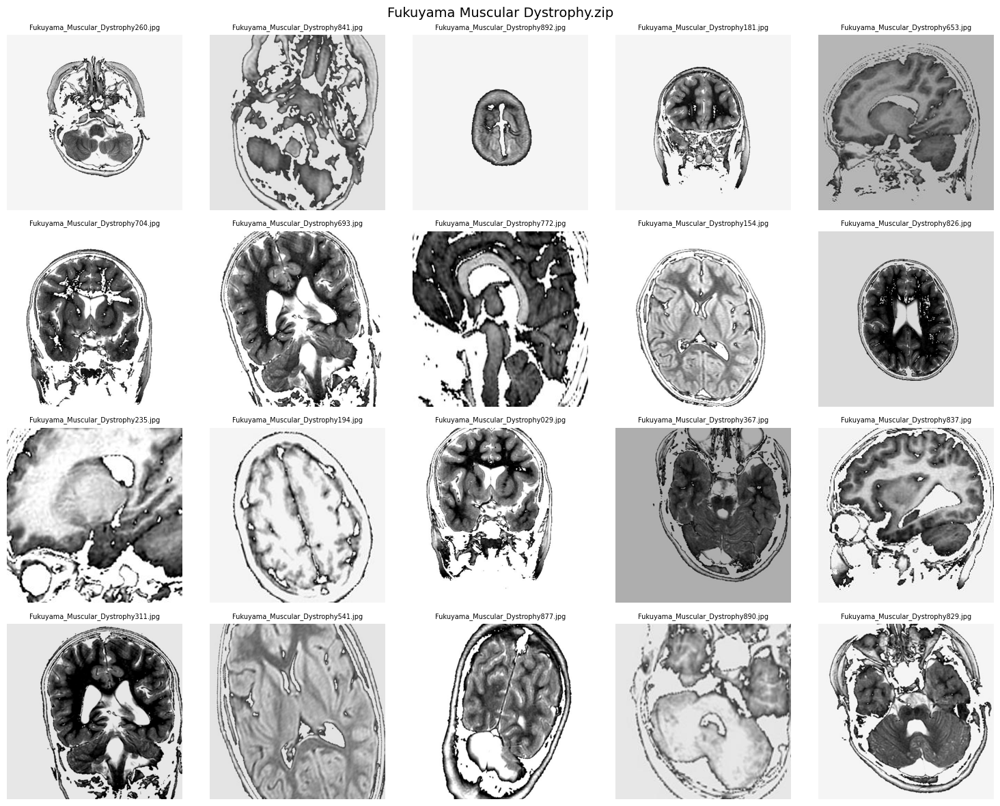

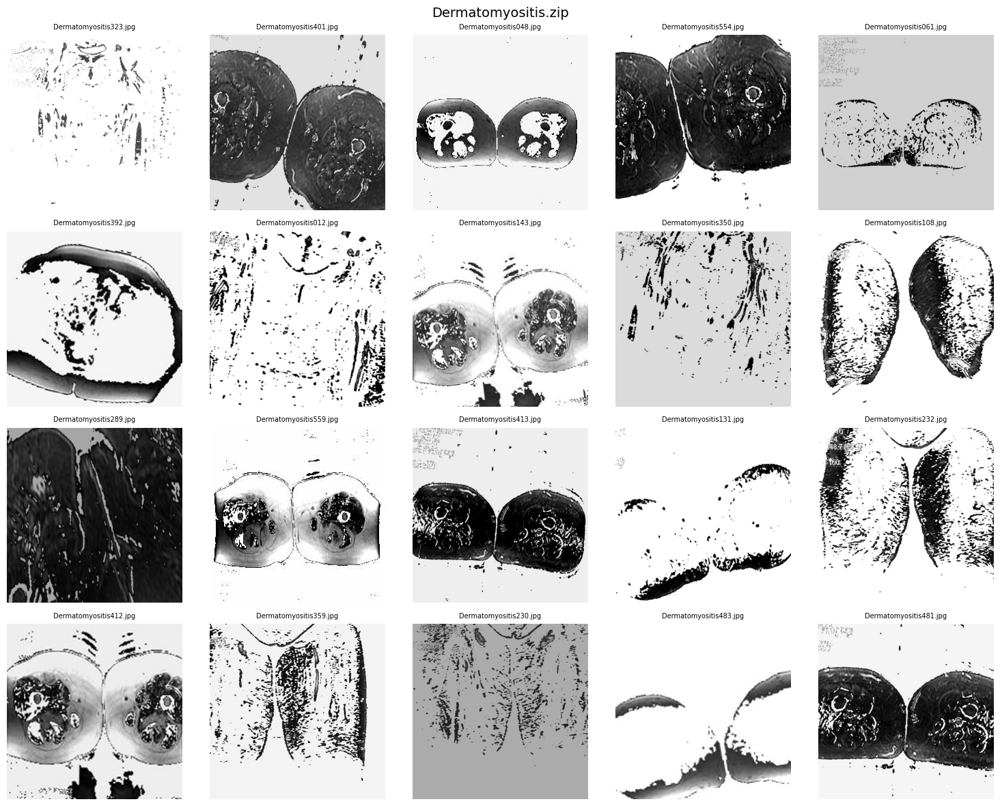

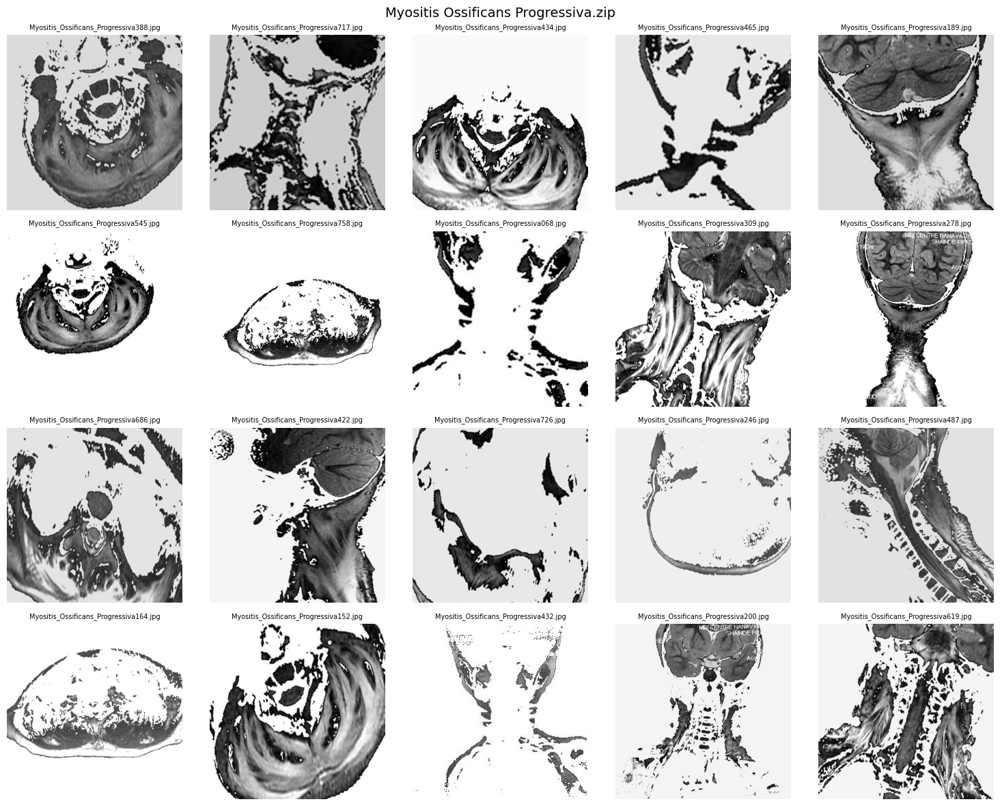

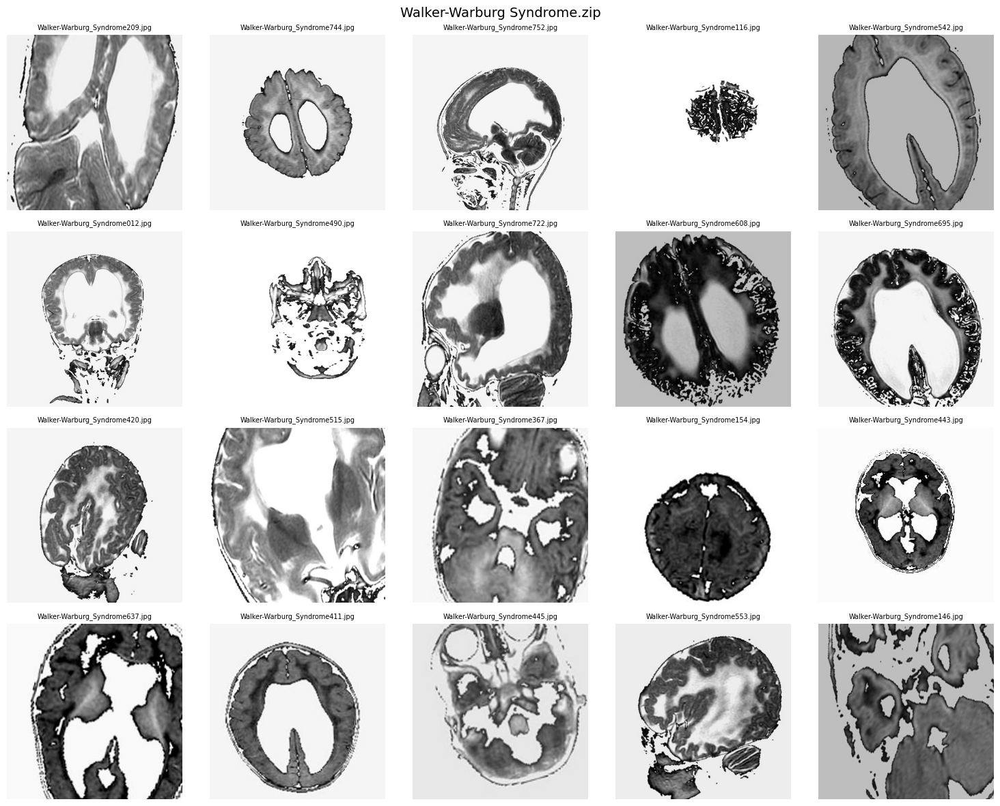

In [ ]:

import io
import random
import zipfile
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

outer_zip = next(A_ORIGINAL.glob("*.zip"))

targets = [
    "Fukuyama Muscular Dystrophy.zip",
    "Dermatomyositis.zip",
    "Myositis Ossificans Progressiva.zip",
    "Walker-Warburg Syndrome.zip",
]

random.seed(42)

with zipfile.ZipFile(outer_zip, "r") as outer:
    outer_names = outer.namelist()

    for target in targets:
        nested_path = next(
            name for name in outer_names
            if Path(name).name == target
        )
        nested_bytes = outer.read(nested_path)

        with zipfile.ZipFile(io.BytesIO(nested_bytes), "r") as inner:
            image_files = [
                name for name in inner.namelist()
                if name.lower().endswith((".jpg", ".jpeg", ".png"))
            ]
            samples = random.sample(
                image_files, min(20, len(image_files))
            )

            fig, axes = plt.subplots(4, 5, figsize=(15, 12))
            fig.suptitle(target, fontsize=14)
            axes = axes.flatten()

            for ax, name in zip(axes, samples):
                with inner.open(name) as f:
                    img = Image.open(f).convert("RGB")
                    ax.imshow(img)

                ax.set_title(Path(name).name, fontsize=7)
                ax.axis("off")

            plt.tight_layout()
            plt.show()


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)
DATASET_A = PROJECT_DIR / "02_Dataset_Audit" / "Dataset_A_MRI"
A_RESULTS = DATASET_A / "Audit_Results"
A_RESULTS.mkdir(parents=True, exist_ok=True)

audit_rows = [
    {
        "Audit_Area": "Archive inventory",
        "Finding": "40 nested ZIP archives; 34,192 images counted",
        "Status": "Completed"
    },
    {
        "Audit_Area": "Image integrity",
        "Finding": "34,192 images checked; zero failed integrity checks",
        "Status": "Completed"
    },
    {
        "Audit_Area": "Image dimensions and modes",
        "Finding": "Images are RGB; dimensions vary, mainly 256x256 and 512x512",
        "Status": "Completed"
    },
    {
        "Audit_Area": "Visual inspection",
        "Finding": (
            "Four archives sampled. Three predominantly show head/brain "
            "anatomy; Dermatomyositis samples include cross-sectional "
            "thigh muscle images and degraded/unclear images."
        ),
        "Status": "Preliminary sample review"
    },
    {
        "Audit_Area": "Exact duplicate checks",
        "Finding": (
            "Dermatomyositis contains two exact-duplicate groups "
            "with three extra copies; no exact duplicates found across "
            "the four inspected archives."
        ),
        "Status": "Completed for inspected archives"
    },
    {
        "Audit_Area": "Source metadata",
        "Finding": (
            "Version 1 and CC BY 4.0 recorded. Official dataset page "
            "and local count report 34,192 images; associated paper "
            "reports 33,616. Difference remains unexplained."
        ),
        "Status": "Partially verified"
    },
    {
        "Audit_Area": "Clinical label validity",
        "Finding": (
            "Disease labels and image anatomy have not been clinically "
            "verified for every image."
        ),
        "Status": "Unverified"
    },
    {
        "Audit_Area": "Patient-level grouping",
        "Finding": (
            "Subject identifiers and patient-level independence "
            "have not been established."
        ),
        "Status": "Unverified"
    },
    {
        "Audit_Area": "Research suitability",
        "Finding": (
            "Do not yet use the full dataset as a muscular dystrophy "
            "classification dataset. Investigate relevant subsets "
            "only after label and anatomy validation."
        ),
        "Status": "Provisional decision"
    }
]

summary_df = pd.DataFrame(audit_rows)
report_path = A_RESULTS / "Dataset_A_Final_Audit_Summary.csv"
summary_df.to_csv(report_path, index=False)

print("Dataset A audit summary saved:")
print(report_path)
print("\nAudit overview:")
print(summary_df[["Audit_Area", "Status"]].to_string(index=False))


Dataset A audit summary saved:
/content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_A_MRI/Audit_Results/Dataset_A_Final_Audit_Summary.csv

Audit overview:
                Audit_Area                           Status
         Archive inventory                        Completed
           Image integrity                        Completed
Image dimensions and modes                        Completed
         Visual inspection        Preliminary sample review
    Exact duplicate checks Completed for inspected archives
           Source metadata               Partially verified
   Clinical label validity                       Unverified
    Patient-level grouping                       Unverified
      Research suitability             Provisional decision


In [ ]:

from pathlib import Path

from google.colab import drive
drive.mount("/content/drive")

report_path = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_A_MRI/Audit_Results/"
    "Dataset_A_Initial_Audit_Report.txt"
)

report_path.parent.mkdir(parents=True, exist_ok=True)

report = r"""
DATASET A — INITIAL DATASET AUDIT REPORT

Project:
Advanced Hybrid Deep Learning Framework for Muscular Dystrophy Classification
Using Multi-Scale Feature Fusion, Radiomics, Attention Mechanisms, and
Explainable Artificial Intelligence

1. DATASET IDENTIFICATION

Dataset title: Benchmark Diagnostic MRI and Medical Imaging Dataset
Source: https://data.mendeley.com/datasets/d73rs38yk6/1
Version: Version 1
Licence recorded: CC BY 4.0
Associated paper:
https://doi.org/10.3389/fradi.2025.1723272

The dataset contains 40 disease-labelled archives and represents a broad
medical-imaging collection, not a dataset exclusively dedicated to
muscular dystrophy.

2. ARCHIVE INVENTORY

- Nested ZIP archives: 40
- Images counted locally: 34,192
- Source-page image count: 34,192
- Associated paper image count: 33,616
- Difference between the paper and source-page/local count: 576 images

The reason for the difference has not been established.

Related file: Dataset_A_All_Archive_Image_Counts.csv
Related file: Dataset_A_Preliminary_Archive_Summary.csv

3. IMAGE INTEGRITY AND PROPERTIES

All 34,192 inventoried images passed the reported file-integrity checks.
No failed integrity checks were reported.

All images were reported as RGB. Most images were 256x256 or 512x512 pixels.
The MR Spine archive also included images sized 2048x1536 and 1536x2048.

Related file: Dataset_A_Image_Quality_Audit.csv

Passing file-integrity checks confirms that files could be opened and decoded.
It does not verify their clinical labels, provenance, or patient independence.

4. VISUAL REVIEW

Four disease-labelled archives were inspected using image samples and
contact sheets. These are preliminary visual observations, not clinical
verification of every image.

Fukuyama Muscular Dystrophy:
- 920 images.
- Samples predominantly appeared to show brain MRI.
- Suitability for skeletal-muscle classification is unconfirmed.

Dermatomyositis:
- 576 images.
- Samples included cross-sectional images that appeared to show thigh
  muscle groups.
- Some images were degraded or difficult to interpret.
- Clinical labels, provenance, and task suitability remain unverified.

Myositis Ossificans Progressiva:
- 808 images.
- Samples predominantly appeared to show head, brain, or neck anatomy.
- Suitability for skeletal-muscle classification is unconfirmed.

Walker-Warburg Syndrome:
- 808 images.
- Samples predominantly appeared to show brain MRI.
- Suitability for skeletal-muscle classification is unconfirmed.

Visual appearance alone does not confirm a diagnosis or label correctness.

5. EXACT-DUPLICATE AUDIT

Dermatomyositis archive:
- Images checked: 576
- Unique file hashes: 573
- Exact-duplicate groups: 2
- Extra duplicate files: 3

Duplicate group 1:
Dermatomyositis453.jpg
Dermatomyositis156.jpg

Duplicate group 2:
Dermatomyositis141.jpg
Dermatomyositis130.jpg
Dermatomyositis043.jpg

Related file: Dermatomyositis_Exact_Duplicates.csv

Cross-archive exact-duplicate check:
- Archives checked: Fukuyama Muscular Dystrophy, Dermatomyositis,
  Myositis Ossificans Progressiva, and Walker-Warburg Syndrome.
- Images checked: 3,112
- Exact duplicate groups spanning archives: 0

These checks detect byte-for-byte duplicates only. Near-duplicates and
multiple images from the same patient may still exist.

6. FILENAMES AND PATIENT METADATA

The four inspected nested ZIPs contained image files but no additional
documentation files within those archives. Filenames used disease/archive
names and sequential-looking identifiers.

Patient identifiers and reliable patient-level grouping were not established
from the inspected filenames. This does not prove such information is absent
from all external documentation.

7. SOURCE RECORD

Related file: Dataset_A_Source_Record.csv

The record documents Version 1, CC BY 4.0, the broad 40-class medical-imaging
task, the 34,192 local/source-page image count, the unresolved 576-image
difference from the associated paper, and unverified patient grouping.

8. COMPLETED AUDIT ACTIVITIES

- Inventory of all 40 nested ZIP archives.
- Local count of 34,192 images.
- Integrity checks of all 34,192 images, with zero failures reported.
- Image dimensions and RGB-mode audit.
- Preliminary visual review of four archives.
- Exact-duplicate check within Dermatomyositis.
- Cross-archive exact-duplicate check across the four inspected archives.
- Source record and audit reports saved.

9. OUTSTANDING ISSUES

- Explain the 576-image discrepancy between the paper and dataset page/local
  audit, if further source information becomes available.
- Verify clinical labels and image content across relevant classes.
- Verify modality and anatomy for images beyond the sampled subsets.
- Establish patient identifiers and patient-level independence.
- Determine whether any subset is reliable and sufficiently sized for the
  intended research task.
- Validate the Dermatomyositis subset's labels and provenance before
  considering a separate experiment.
- Investigate near-duplicate and same-patient leakage risks.

10. PROVISIONAL RESEARCH DECISION

Dataset A should not yet be treated as a validated muscular-dystrophy
classification dataset. Samples from several disease-labelled archives
appeared to show brain or head anatomy. The Dermatomyositis subset includes
samples that appear to show thigh muscle cross-sections, but this does not
validate its clinical labels or establish its suitability.

Retain Dataset A as a separately audited dataset. Do not train on it for the
proposed muscular-dystrophy task until the relevant subset, clinical labels,
provenance, and patient-level grouping are adequately validated.

Do not directly merge Dataset A with Dataset B, which contains FSHD muscle
ultrasound images, because their imaging modalities and task contexts differ.

11. LIMITATIONS

This is a preliminary data audit, not a clinical assessment. No model was
trained on Dataset A during the activities documented here. No diagnostic
performance claims are made. Sampled visual observations do not confirm
diagnoses. File-integrity and exact-duplicate checks do not establish clinical
validity or patient independence.

RELATED AUDIT FILES

- Dataset_A_Source_Record.csv
- Dataset_A_All_Archive_Image_Counts.csv
- Dataset_A_Preliminary_Archive_Summary.csv
- Dataset_A_Image_Quality_Audit.csv
- Dermatomyositis_Exact_Duplicates.csv
- Dataset_A_Final_Audit_Summary.csv

END OF REPORT
"""

report_path.write_text(report.strip() + "\n", encoding="utf-8")

print("Audit report saved successfully!")
print("Path:", report_path)
print("File size:", report_path.stat().st_size, "bytes")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Audit report saved successfully!
Path: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_A_MRI/Audit_Results/Dataset_A_Initial_Audit_Report.txt
File size: 6424 bytes


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

B_EXTRACTED = (
    PROJECT_DIR
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Extracted_Files"
)

metadata_file = next(
    B_EXTRACTED.rglob("SubjectsInfo.xlsx"),
    None
)

if metadata_file is None:
    print("SubjectsInfo.xlsx not found in:", B_EXTRACTED)
else:
    excel = pd.ExcelFile(metadata_file)

    print("Metadata file:", metadata_file)
    print("Sheets:", excel.sheet_names)

    for sheet in excel.sheet_names:
        df = pd.read_excel(metadata_file, sheet_name=sheet)

        print("\n" + "=" * 60)
        print("Sheet:", sheet)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print("\nFirst five rows:")
        print(df.head().to_string(index=False))


Metadata file: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Metadata/SubjectsInfo.xlsx
Sheets: ['Sheet1']

Sheet: Sheet1
Shape: (110, 20)
Columns: ['Code', 'Sex', 'age', 'BMI', 'Weight', 'Length', '019_00', '019_01', '001_00', '001_01', '015_00', '015_01', '016_00', '016_01', '020_00', '020_01', '018_00', '018_01', '008_00', '008_01']

First five rows:
 Code  Sex  age   BMI  Weight  Length  019_00  019_01  001_00  001_01  015_00  015_01  016_00  016_01  020_00  020_01  018_00  018_01  008_00  008_01
    6    0   49 30.79     110     189     3.0     3.0     3.0     3.0     2.0     2.0     3.0     3.0     4.0     4.0     4.0     4.0     2.0     2.0
   13    1   77 32.87      95     170     NaN     NaN     3.0     3.0     NaN     NaN     3.0     3.0     4.0     4.0     4.0     3.0     2.0     2.0
   19    0   42 22.40      75     183     3.0     3.0     1.0     1.0     1.0     1.0     1.0     1.0     1.0     1.0     1.0     1

In [ ]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

B_EXTRACTED = (
    PROJECT_DIR
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Extracted_Files"
)

metadata_file = next(B_EXTRACTED.rglob("SubjectsInfo.xlsx"))
df = pd.read_excel(metadata_file)

grade_cols = [
    col for col in df.columns
    if isinstance(col, str) and "_" in col
]

print("=== DATASET METADATA QUALITY AUDIT ===")
print("Total subjects/rows:", len(df))
print("Duplicate subject IDs:", df["Code"].duplicated().sum())
print("Missing subject IDs:", df["Code"].isna().sum())

print("\n=== MISSING VALUES BY COLUMN ===")
print(df.isna().sum().to_string())

print("\n=== GRADE VALUE COUNTS ===")
grade_values = df[grade_cols].stack().value_counts().sort_index()
print(grade_values.to_string())

invalid_grades = df[grade_cols].notna() & ~df[grade_cols].isin([1, 2, 3, 4])

print("\n=== INVALID GRADES ===")
print("Number of invalid grade entries:", invalid_grades.sum().sum())

print("\n=== SUBJECT ID SAMPLE ===")
print(df["Code"].head(10).tolist())


=== DATASET METADATA QUALITY AUDIT ===
Total subjects/rows: 110
Duplicate subject IDs: 0
Missing subject IDs: 0

=== MISSING VALUES BY COLUMN ===
Code      0
Sex       0
age       0
BMI       0
Weight    0
Length    0
019_00    7
019_01    7
001_00    2
001_01    2
015_00    4
015_01    4
016_00    4
016_01    3
020_00    4
020_01    3
018_00    4
018_01    2
008_00    4
008_01    2

=== GRADE VALUE COUNTS ===
1.0    506
2.0    541
3.0    382
4.0     59

=== INVALID GRADES ===
Number of invalid grade entries: 0

=== SUBJECT ID SAMPLE ===
[6, 13, 19, 25, 76, 82, 97, 103, 111, 133]


In [ ]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

B_EXTRACTED = (
    PROJECT_DIR
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Extracted_Files"
)

images_dir = B_EXTRACTED / "Images" / "images"
masks_dir = B_EXTRACTED / "Masks" / "masks"

image_files = sorted(images_dir.glob("*.png"))
mask_files = sorted(masks_dir.glob("*.png"))

print("Image directory:", images_dir)
print("Image files found:", len(image_files))
print("Mask files found:", len(mask_files))

print("\nFirst 20 image filenames:")
for p in image_files[:20]:
    print(p.name)

print("\nFirst 20 mask filenames:")
for p in mask_files[:20]:
    print(p.name)


Image directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Images/images
Image files found: 25005
Mask files found: 25005

First 20 image filenames:
00006_001_00_1.png
00006_001_00_2.png
00006_001_00_3.png
00006_001_01_1.png
00006_001_01_2.png
00006_001_01_3.png
00006_001_01_4.png
00006_004_00_1.png
00006_004_00_2.png
00006_004_00_3.png
00006_004_01_1.png
00006_004_01_2.png
00006_004_01_3.png
00006_008_00_1.png
00006_008_00_2.png
00006_008_00_3.png
00006_008_00_4.png
00006_008_01_1.png
00006_008_01_2.png
00006_008_01_3.png

First 20 mask filenames:
00006_001_00_1.png
00006_001_00_2.png
00006_001_00_3.png
00006_001_01_1.png
00006_001_01_2.png
00006_001_01_3.png
00006_001_01_4.png
00006_004_00_1.png
00006_004_00_2.png
00006_004_00_3.png
00006_004_01_1.png
00006_004_01_2.png
00006_004_01_3.png
00006_008_00_1.png
00006_008_00_2.png
00006_008_00_3.png
00006_008_00_4.png
00006_008_01_1.png
00006_008_01_2.png
00006_008_01_3.pn

In [ ]:

import re
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

B_EXTRACTED = (
    PROJECT_DIR
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Extracted_Files"
)

images_dir = B_EXTRACTED / "Images" / "images"
masks_dir = B_EXTRACTED / "Masks" / "masks"
metadata_file = next(B_EXTRACTED.rglob("SubjectsInfo.xlsx"))

df = pd.read_excel(metadata_file)

image_names = {p.name for p in images_dir.glob("*.png")}
mask_names = {p.name for p in masks_dir.glob("*.png")}

pattern = re.compile(r"^(\d+)_(\d+)_(\d{2})_(\d+)\.png$")

parsed = []
invalid_names = []

for filename in sorted(image_names):
    match = pattern.match(filename)

    if not match:
        invalid_names.append(filename)
        continue

    subject_id, muscle_code, side_code, image_index = match.groups()

    parsed.append({
        "filename": filename,
        "subject_id": int(subject_id),
        "muscle_code": muscle_code,
        "side_code": side_code,
        "image_index": int(image_index)
    })

parsed_df = pd.DataFrame(parsed)

metadata_ids = set(df["Code"].dropna().astype(int))
filename_ids = set(parsed_df["subject_id"]) if not parsed_df.empty else set()

print("=== FILENAME AND SUBJECT MAPPING AUDIT ===")
print("Image filenames:", len(image_names))
print("Mask filenames:", len(mask_names))
print("Image files without matching masks:", len(image_names - mask_names))
print("Masks without matching images:", len(mask_names - image_names))
print("Filenames not matching expected pattern:", len(invalid_names))
print("Unique subjects in image filenames:", len(filename_ids))
print("Unique subjects in metadata:", len(metadata_ids))
print("Filename subject IDs absent from metadata:", len(filename_ids - metadata_ids))
print("Metadata IDs absent from filenames:", len(metadata_ids - filename_ids))

if invalid_names:
    print("\nExamples of unexpected filenames:", invalid_names[:10])

if filename_ids - metadata_ids:
    print("\nExample IDs absent from metadata:", sorted(filename_ids - metadata_ids)[:20])

if metadata_ids - filename_ids:
    print("\nExample metadata IDs absent from images:", sorted(metadata_ids - filename_ids)[:20])


=== FILENAME AND SUBJECT MAPPING AUDIT ===
Image filenames: 25005
Mask filenames: 25005
Image files without matching masks: 0
Masks without matching images: 0
Filenames not matching expected pattern: 0
Unique subjects in image filenames: 290
Unique subjects in metadata: 110
Filename subject IDs absent from metadata: 180
Metadata IDs absent from filenames: 0

Example IDs absent from metadata: [26, 27, 28, 29, 30, 77, 83, 98, 99, 100, 101, 147, 148, 149, 152, 153, 154, 155, 156, 158]


In [ ]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

B_EXTRACTED = (
    PROJECT_DIR
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Extracted_Files"
)

readme_file = next(B_EXTRACTED.rglob("README.txt"), None)

if readme_file is None:
    print("README.txt not found.")
else:
    text = readme_file.read_text(
        encoding="utf-8",
        errors="replace"
    )

    print("README:", readme_file)
    print("\nRelevant documentation lines:\n")

    keywords = [
        "subject", "participant", "control", "patient",
        "FSHD", "Heckmatt", "score", "code", "metadata"
    ]

    for line_number, line in enumerate(text.splitlines(), start=1):
        if any(word in line.lower() for word in keywords):
            print(f"{line_number}: {line}")


README: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Metadata/README.txt

Relevant documentation lines:

42:     SubjectsInfo.xlsx
80:     SubjectsInfo.xlsx
81:         An Excel file containing subject characteristics and ground-truth Heckmatt scores.
83:             Code: Subject number (categorical)
84:             Sex: Subject sex (0 = female; 1 = male)
85:             Age: Subject age (numerical)
86:             BMI: Subject BMI (numerical)
87:             Weight: Subject weight in kilograms (numerical)
88:             Length: Subject height in centimeters (numerical)
89:             0XX_0Y: Heckmatt score for each muscle-side combination (ordinal, 1 → 4)
91:                 XX indicates muscle group code (see table below)
93: Muscle	Code


In [ ]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

B_EXTRACTED = (
    PROJECT_DIR
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Extracted_Files"
)

readme_file = next(B_EXTRACTED.rglob("README.txt"))
lines = readme_file.read_text(
    encoding="utf-8",
    errors="replace"
).splitlines()

print("\n".join(
    f"{i + 1}: {lines[i]}"
    for i in range(70, min(len(lines), 150))
))


71:     FSHD_musclespecific_models.zip
72:         Includes 5  configuration files (one for each cross-validation fold) for muscle-specific binary segmentation.
73:         This approach fine-tunes one of the multi-label models for a specific muscle.
74:         Training requires segmentation maps in the mmsegmentation format (0 = background; 1 = muscle).
75:         Only fold 0 is included here to keep the file size manageable. If you need configs for other folds, please contact the corresponding author.
76: 
77:     XGB_models.zip
78:         Contains the XGBoost models used for the classification tasks as described in the paper.
79: 
80:     SubjectsInfo.xlsx
81:         An Excel file containing subject characteristics and ground-truth Heckmatt scores.
82:         Columns:
83:             Code: Subject number (categorical)
84:             Sex: Subject sex (0 = female; 1 = male)
85:             Age: Subject age (numerical)
86:             BMI: Subject BMI (numerical)
87:             

In [ ]:

from pathlib import Path
from collections import Counter
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

B_EXTRACTED = (
    PROJECT_DIR
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Extracted_Files"
)

images_dir = B_EXTRACTED / "Images" / "images"
metadata_file = next(B_EXTRACTED.rglob("SubjectsInfo.xlsx"))

df = pd.read_excel(metadata_file)
metadata_ids = set(df["Code"].dropna().astype(int))

subject_counts = Counter()

for path in images_dir.glob("*.png"):
    parts = path.stem.split("_")
    if len(parts) == 4 and parts[0].isdigit():
        subject_counts[int(parts[0])] += 1

image_ids = set(subject_counts)

print("Unique subjects in images:", len(image_ids))
print("Subjects in metadata:", len(metadata_ids))
print("Subjects in both:", len(image_ids & metadata_ids))
print("Subjects only in images:", len(image_ids - metadata_ids))
print("Subjects only in metadata:", len(metadata_ids - image_ids))

print("\nImages per subject — summary:")
counts = pd.Series(subject_counts, name="image_count")
print(counts.describe().to_string())

print("\nFirst 20 subjects missing from metadata:")
print(sorted(image_ids - metadata_ids)[:20])

print("\nFirst 20 subjects present in metadata:")
print(sorted(metadata_ids & image_ids)[:20])


Unique subjects in images: 290
Subjects in metadata: 110
Subjects in both: 110
Subjects only in images: 180
Subjects only in metadata: 0

Images per subject — summary:
count    290.000000
mean      86.224138
std       20.338862
min       32.000000
25%       85.000000
50%       96.000000
75%       99.000000
max      113.000000

First 20 subjects missing from metadata:
[26, 27, 28, 29, 30, 77, 83, 98, 99, 100, 101, 147, 148, 149, 152, 153, 154, 155, 156, 158]

First 20 subjects present in metadata:
[6, 13, 19, 25, 76, 82, 97, 103, 111, 133, 151, 157, 177, 194, 196, 198, 204, 219, 222, 227]


In [ ]:

from pathlib import Path
from datetime import date

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

B_RESULTS = (
    PROJECT_DIR
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Audit_Results"
)

B_RESULTS.mkdir(parents=True, exist_ok=True)

note = f"""
DATASET B — SUBJECT MAPPING AUDIT NOTE
Date: {date.today().isoformat()}

Files inspected:
- Ultrasound images: 25,005
- Segmentation masks: 25,005
- Subject metadata: SubjectsInfo.xlsx

Findings:
- Unique subject IDs in image filenames: 290
- Subject IDs in metadata: 110
- Subject IDs present in both: 110
- Subject IDs found in images but absent from metadata: 180
- Metadata subject IDs absent from images: 0
- Image filenames without matching masks: 0
- Masks without matching images: 0

Interpretation:
All 110 metadata subjects are represented in the image collection.
The other 180 image subject IDs have no matching row in SubjectsInfo.xlsx.
Their diagnosis, role in the study, and availability of ground-truth
Heckmatt labels have not yet been verified.

Action:
Do not assign labels or discard these subjects based on this result alone.
Verify the published study design and documentation before defining
the training dataset or subject-level splits.
"""

note_path = B_RESULTS / "Dataset_B_Subject_Mapping_Audit_Note.txt"
note_path.write_text(note.strip() + "\n", encoding="utf-8")

print("Audit note saved:", note_path)


Audit note saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Subject_Mapping_Audit_Note.txt


In [ ]:
from pathlib import Path
from datetime import date

note_path = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/"
    "Audit_Results/Dataset_B_Subject_Mapping_Audit_Note.txt"
)

with open(note_path, "a", encoding="utf-8") as f:
    f.write("\n\nPUBLISHED STUDY CROSS-CHECK\n")
    f.write(f"Updated: {date.today().isoformat()}\n\n")
    f.write(
        "The associated 2025 paper reports 290 participants: "
        "180 healthy controls and 110 participants with FSHD.\n"
    )
    f.write(
        "The image filenames contain 290 unique subject IDs, "
        "while SubjectsInfo.xlsx contains 110 subject IDs.\n"
    )
    f.write(
        "The Heckmatt grading metadata relates to the FSHD "
        "grading subset. Confirm label availability before "
        "assigning grades to any additional subjects.\n"
    )
    f.write(
        "Reference DOI: 10.1016/j.clinph.2025.01.016\n"
    )
    f.write(
        "Dataset DOI: 10.17632/yzg86vb895.1\n"
    )

print("Audit note updated:", note_path.exists())
print("Saved at:", note_path)

Audit note updated: True
Saved at: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Subject_Mapping_Audit_Note.txt


In [ ]:
from pathlib import Path
import pandas as pd
import re

base = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/"
    "Extracted_Files"
)

image_dir = base / "Images" / "images"
mask_dir = base / "Masks" / "masks"
metadata_path = base / "Metadata" / "SubjectsInfo.xlsx"

output_path = (
    Path("/content/drive/MyDrive/Muscular_Dystrophy_Project/")
    / "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/"
      "Audit_Results/Dataset_B_Image_Mask_Manifest.csv"
)

# Load subject-level clinical metadata
metadata = pd.read_excel(metadata_path)

# Map metadata column names to their values for each subject
metadata["Code"] = pd.to_numeric(metadata["Code"], errors="raise").astype(int)
metadata_by_id = metadata.set_index("Code")

pattern = re.compile(r"^(\d+)_(\d+)_(\d{2})_(\d+)\.png$")
records = []

for image_path in sorted(image_dir.glob("*.png")):
    match = pattern.match(image_path.name)

    if not match:
        continue

    subject_id, muscle_code, side_code, image_index = map(
        int, match.groups()
    )

    mask_path = mask_dir / image_path.name

    # Add a Heckmatt grade only when a corresponding metadata
    # column exists and contains a value.
    grade_column = f"{muscle_code:03d}_{side_code:02d}"
    grade = None

    if subject_id in metadata_by_id.index:
        if grade_column in metadata_by_id.columns:
            grade = metadata_by_id.loc[subject_id, grade_column]

    records.append({
        "filename": image_path.name,
        "image_path": str(image_path),
        "mask_path": str(mask_path),
        "mask_exists": mask_path.is_file(),
        "subject_id": subject_id,
        "muscle_code": f"{muscle_code:03d}",
        "side_code": side_code,
        "side": {0: "left", 1: "right"}.get(side_code, "unknown"),
        "image_index": image_index,
        "heckmatt_grade": grade,
        "metadata_available": subject_id in metadata_by_id.index
    })

manifest = pd.DataFrame(records)
manifest.to_csv(output_path, index=False)

print("Manifest saved:", output_path)
print("Total image records:", len(manifest))
print("Missing masks:", (~manifest["mask_exists"]).sum())
print("Subjects:", manifest["subject_id"].nunique())
print("Records with metadata:", manifest["metadata_available"].sum())
print("Records with Heckmatt grades:", manifest["heckmatt_grade"].notna().sum())
print("\nPreview:")
print(manifest.head())

Manifest saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Image_Mask_Manifest.csv
Total image records: 25005
Missing masks: 0
Subjects: 290
Records with metadata: 9496
Records with Heckmatt grades: 4727

Preview:
             filename                                         image_path  \
0  00006_001_00_1.png  /content/drive/MyDrive/Muscular_Dystrophy_Proj...   
1  00006_001_00_2.png  /content/drive/MyDrive/Muscular_Dystrophy_Proj...   
2  00006_001_00_3.png  /content/drive/MyDrive/Muscular_Dystrophy_Proj...   
3  00006_001_01_1.png  /content/drive/MyDrive/Muscular_Dystrophy_Proj...   
4  00006_001_01_2.png  /content/drive/MyDrive/Muscular_Dystrophy_Proj...   

                                           mask_path  mask_exists  subject_id  \
0  /content/drive/MyDrive/Muscular_Dystrophy_Proj...         True           6   
1  /content/drive/MyDrive/Muscular_Dystrophy_Proj...         True           6   
2  /content/

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

project = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound"
)

manifest_path = project / "Audit_Results/Dataset_B_Image_Mask_Manifest.csv"
report_path = project / "Audit_Results/Dataset_B_Preprocessing_Inspection.csv"

manifest = pd.read_csv(manifest_path)

# Inspect a small, reproducible sample rather than loading all images.
sample = manifest.sample(
    n=min(100, len(manifest)),
    random_state=42
)

results = []

for _, row in sample.iterrows():
    with Image.open(row["image_path"]) as img:
        image = np.array(img)

    with Image.open(row["mask_path"]) as msk:
        mask = np.array(msk)

    results.append({
        "filename": row["filename"],
        "image_shape": str(image.shape),
        "image_dtype": str(image.dtype),
        "image_min": int(image.min()),
        "image_max": int(image.max()),
        "mask_shape": str(mask.shape),
        "mask_dtype": str(mask.dtype),
        "mask_unique_values": str(np.unique(mask).tolist()),
        "muscle_pixel_percentage": round(
            100 * np.count_nonzero(mask) / mask.size, 2
        ),
        "image_mask_dimensions_match": image.shape[:2] == mask.shape[:2]
    })

inspection = pd.DataFrame(results)
inspection.to_csv(report_path, index=False)

print("Sampled images:", len(inspection))
print("Image shapes:\n", inspection["image_shape"].value_counts().to_string())
print("\nImage dtypes:\n", inspection["image_dtype"].value_counts().to_string())
print("\nImage intensity ranges:")
print(inspection[["image_min", "image_max"]].describe().round(2))
print("\nMask values:")
print(inspection["mask_unique_values"].value_counts().to_string())
print("\nImage-mask dimension mismatches:",
      (~inspection["image_mask_dimensions_match"]).sum())
print("Muscle pixel percentage:")
print(inspection["muscle_pixel_percentage"].describe().round(2))
print("\nReport saved:", report_path)

Sampled images: 100
Image shapes:
 image_shape
(512, 512)    100

Image dtypes:
 image_dtype
uint8    100

Image intensity ranges:
       image_min  image_max
count      100.0     100.00
mean         0.0     249.08
std          0.0      10.74
min          0.0     205.00
25%          0.0     250.75
50%          0.0     253.00
75%          0.0     255.00
max          0.0     255.00

Mask values:
mask_unique_values
[0, 255]    100

Image-mask dimension mismatches: 0
Muscle pixel percentage:
count    100.00
mean       9.63
std        8.53
min        0.11
25%        1.76
50%        7.22
75%       18.80
max       35.58
Name: muscle_pixel_percentage, dtype: float64

Report saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Preprocessing_Inspection.csv


In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

project = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound"
)

manifest_path = project / "Audit_Results/Dataset_B_Image_Mask_Manifest.csv"
output_path = project / "Audit_Results/Dataset_B_Full_Mask_Quality.csv"

manifest = pd.read_csv(manifest_path)
results = []

for row in manifest.itertuples(index=False):
    with Image.open(row.mask_path) as img:
        mask = np.asarray(img)

    muscle_pixels = np.count_nonzero(mask)
    total_pixels = mask.size

    results.append({
        "filename": row.filename,
        "subject_id": row.subject_id,
        "muscle_code": row.muscle_code,
        "side": row.side,
        "mask_shape": str(mask.shape),
        "mask_values_valid": bool(np.isin(mask, [0, 255]).all()),
        "muscle_pixels": int(muscle_pixels),
        "muscle_coverage_pct": 100 * muscle_pixels / total_pixels,
        "empty_mask": muscle_pixels == 0,
        "very_small_mask_lt_1pct": muscle_pixels / total_pixels < 0.01
    })

quality = pd.DataFrame(results)
quality.to_csv(output_path, index=False)

print("Masks inspected:", len(quality))
print("Invalid mask values:", (~quality["mask_values_valid"]).sum())
print("Empty masks:", quality["empty_mask"].sum())
print("Masks with coverage below 1%:",
      quality["very_small_mask_lt_1pct"].sum())
print("\nMuscle coverage (%):")
print(quality["muscle_coverage_pct"].describe().round(3))
print("\nReport saved:", output_path)

Masks inspected: 25005
Invalid mask values: 0
Empty masks: 0
Masks with coverage below 1%: 5086

Muscle coverage (%):
count    25005.000
mean         9.128
std          8.022
min          0.028
25%          1.501
50%          7.014
75%         15.289
max         43.981
Name: muscle_coverage_pct, dtype: float64

Report saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Full_Mask_Quality.csv


In [ ]:

from pathlib import Path
from datetime import date

# --------------------------------------------------
# DATASET B — FINAL AUDIT REPORT
# --------------------------------------------------

project = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound"
)

audit_dir = project / "Audit_Results"
audit_dir.mkdir(parents=True, exist_ok=True)

report_path = audit_dir / "Dataset_B_Final_Audit_Report.txt"

report = r"""
============================================================
FINAL DATASET AUDIT REPORT
============================================================

Project:
Advanced Hybrid Deep Learning Framework for Muscular
Dystrophy Classification Using Multi-Scale Feature Fusion,
Radiomics, Attention Mechanisms, and Explainable AI

Dataset:
Machine Learning-Driven Heckmatt Grading in FSHD

Audit date: DATE_PLACEHOLDER
Report format: Plain text (TXT)
Audit status: Initial audit completed; preprocessing pending

============================================================
1. DATASET SOURCE AND DESCRIPTION
============================================================

Dataset title:
Machine Learning-Driven Heckmatt Grading in FSHD

Dataset repository:
Mendeley Data

Dataset URL:
https://data.mendeley.com/datasets/yzg86vb895/1

Associated publication DOI:
10.1016/j.clinph.2025.01.016

Dataset DOI:
10.17632/yzg86vb895.1

The dataset contains ultrasound images, corresponding muscle
segmentation masks, and a spreadsheet containing participant
characteristics and Heckmatt grades.

The dataset is relevant to research involving facioscapulohumeral
muscular dystrophy (FSHD), muscle ultrasound analysis, muscle
segmentation, and muscle quality grading.

This dataset is not an MRI dataset. It represents a separate
ultrasound modality and must be treated accordingly in the
research pipeline.

The published study population is reported as 290 participants,
including 110 participants with FSHD and 180 healthy controls.
The clinical metadata spreadsheet contains 110 participant IDs.
The precise availability of diagnostic labels for each image
must be established before supervised diagnostic classification.

============================================================
2. LOCAL DIRECTORY ORGANIZATION
============================================================

Project root:
Muscular_Dystrophy_Project/

Dataset audit directory:
02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/

Extracted dataset directories:

Extracted_Files/
    Images/
        images/
    Masks/
        masks/
    Metadata/
        SubjectsInfo.xlsx
        README.txt

Audit output directory:

Audit_Results/
    Dataset_B_Subject_Mapping_Audit_Note.txt
    Dataset_B_Image_Mask_Manifest.csv
    Dataset_B_Preprocessing_Inspection.csv
    Dataset_B_Full_Mask_Quality.csv
    Dataset_B_Final_Audit_Report.txt

The audit reports and CSV files document the inspection.
Original image and mask files were not modified by the audit.

============================================================
3. AUDIT OBJECTIVES
============================================================

The audit was conducted to:

1. Verify the extracted dataset organization.
2. Inspect the dataset README and metadata spreadsheet.
3. Count image and mask files.
4. Verify image-mask filename correspondence.
5. Inspect filename structure and derive subject-level fields.
6. Check metadata completeness and Heckmatt grade validity.
7. Examine image dimensions and data types.
8. Inspect mask dimensions, pixel values, and muscle coverage.
9. Create a reusable image-mask-metadata manifest.
10. Record unresolved issues before preprocessing and modeling.

============================================================
4. DOCUMENTATION REVIEW
============================================================

Files reviewed:
- README.txt
- SubjectsInfo.xlsx

The README describes:
- Ultrasound images stored in images.zip.
- Muscle segmentation masks stored in masks.zip.
- Subject information and ground-truth Heckmatt scores in
  SubjectsInfo.xlsx.
- Additional model-related archives, including configuration
  files and XGBoost models.

The provided README states that the images are 512 x 512,
8-bit grayscale PNG files. Masks are grayscale binary images.
The raw masks use 0 for background and 255 for muscle.
A model-training representation using 0 for background and
1 for muscle is also described in the documentation.

The audit focused on the extracted images, masks, README,
and subject metadata. The supplied pretrained model archives
were not evaluated as part of this audit.

============================================================
5. IMAGE AND MASK FILE COUNTS
============================================================

Images found: 25,005
Masks found: 25,005

Filename matching:
- Image filenames without matching masks: 0
- Mask filenames without matching images: 0
- Image filenames failing the expected naming pattern: 0

The expected filename pattern was:

<subject_id>_<muscle_code>_<side_code>_<image_index>.png

Equivalent regular expression:

^(\\d+)_(\\d+)_(\\d{2})_(\\d+)\\.png$

All 25,005 image records were included in the generated
manifest. The manifest recorded whether the corresponding
mask file existed.

Observed result:
- Total manifest records: 25,005
- Missing masks reported by the manifest: 0

These results establish filename-level correspondence.
They do not by themselves establish that every mask is
clinically correct or anatomically perfect.

============================================================
6. IMAGE FILE INSPECTION
============================================================

A reproducible random sample of 100 images was inspected.

Sampling method:
- Random sampling without replacement.
- Fixed random seed: 42.
- Image files were opened using Pillow.
- Image arrays were inspected using NumPy.

Observed results:
- Images inspected: 100
- Image dimensions: 512 x 512 for all 100 sampled images.
- Image data type: uint8 for all 100 sampled images.
- Minimum pixel intensity: 0 in all sampled images.
- Maximum pixel intensity ranged from 205 to 255.
- Mean of the per-image maximum intensity: approximately 249.08.

The image inspection supports the expected dimensions and
8-bit data representation in the sampled files.

Limitation:
The 100-image sample is not a complete pixel-level audit
of all 25,005 image files. The complete dataset should be
checked for corrupt files and unexpected dimensions before
large-scale preprocessing if this has not already been done
by a separate integrity audit.

============================================================
7. METADATA STRUCTURE AND QUALITY
============================================================

Metadata file:
SubjectsInfo.xlsx

Worksheet inspected:
Sheet1

Spreadsheet shape:
110 rows x 20 columns

Columns:
Code
Sex
age
BMI
Weight
Length
019_00
019_01
001_00
001_01
015_00
015_01
016_00
016_01
020_00
020_01
018_00
018_01
008_00
008_01

The Code field represents participant identifiers.
The remaining demographic fields include sex, age, BMI,
weight, and length.

The grade columns encode muscle-specific, side-specific
Heckmatt grades.

The naming convention associates:
- 00 with the left side.
- 01 with the right side.
- The preceding three-digit code with a muscle group.

The README lists the following muscle codes:

001 Biceps brachii
002 Deltoideus
003 Depressor anguli oris
004 Digastricus
005 Extensor digitorum brevis
006 Flexor carpi radialis
007 Flexor digitorum profundus
008 Gastrocnemius medial head
009 Geniohyoideus
010 Levator labii superior
011 Masseter
012 Mentalis
013 Orbicularis oris
014 Peroneus tertius
015 Rectus abdominis
016 Rectus femoris
017 Temporalis
018 Tibialis anterior
019 Trapezius
020 Vastus lateralis
021 Zygomaticus

Metadata integrity findings:
- Duplicate participant IDs: 0
- Missing participant IDs: 0
- Invalid non-missing Heckmatt grades outside 1-4: 0
- Non-missing grade entries: 1,488
- Missing grade entries: 48

Observed grade distribution across non-missing spreadsheet
entries:
- Grade 1: 506
- Grade 2: 541
- Grade 3: 382
- Grade 4: 59

These counts refer to spreadsheet grade entries, not to
independent image samples.

Missing grade counts by column:

019_00: 7
019_01: 7
001_00: 2
001_01: 2
015_00: 4
015_01: 4
016_00: 4
016_01: 3
020_00: 4
020_01: 3
018_00: 4
018_01: 2
008_00: 4
008_01: 2

Grades are ordinal values from 1 to 4. They should not
automatically be treated as nominal categories without
considering the ordinal nature of the clinical scale.

============================================================
8. SUBJECT ID MAPPING
============================================================

Unique subject IDs in image filenames: 290
Unique subject IDs in metadata: 110

Subject ID intersection:
- Metadata IDs also present in image filenames: 110
- Image subject IDs without a metadata row: 180
- Metadata IDs absent from image filenames: 0

All 110 metadata participant IDs were found in the image
collection.

The associated study reports 290 participants, comprising
110 participants with FSHD and 180 healthy controls.
This is consistent with the observed total number of image
subject IDs and the metadata subject count at the population
level.

However, the presence or absence of a metadata row must not
be used as the sole basis for assigning a diagnostic label.
The diagnostic status and intended use of every subject
must be grounded in the study documentation and available
label sources.

The Heckmatt grade metadata appears to describe a grading
subset rather than providing grades for every image from
all 290 participants. The mapping between images, muscle,
side, participant and clinical grade must be preserved.

Recommended action:
Before diagnostic classification, explicitly verify subject
diagnosis labels and define the eligible labelled cohort.
Do not infer that every image from a participant has an
independent label or that every grade entry represents a
separate participant.

============================================================
9. IMAGE-MASK PAIR INSPECTION
============================================================

A random sample of 100 image-mask pairs was inspected.

Sampling method:
- Random sampling without replacement.
- Fixed random seed: 42.
- Pillow used to load the images and masks.
- NumPy used to inspect dimensions, data types and values.

Results:
- Sampled pairs: 100
- Image-mask dimension mismatches: 0
- Sampled mask values: [0, 255] in all 100 masks.
- Sampled images: 512 x 512, uint8.

The visual and numeric checks support the expected mask
representation for the sampled pairs.

============================================================
10. FULL MASK QUALITY AUDIT
============================================================

A full scan was performed over all 25,005 masks.

Method:
- Each mask was opened with Pillow.
- Each mask was converted to a NumPy array.
- Pixel values were checked against the allowed raw values
  0 and 255.
- Nonzero pixels were counted as muscle pixels.
- Muscle coverage was calculated as:

  muscle coverage (%) =
      100 x nonzero mask pixels / total mask pixels

Results:
- Masks inspected: 25,005
- Masks with invalid pixel values: 0
- Empty masks: 0
- Masks with muscle coverage below 1%: 5,086
- Minimum muscle coverage: approximately 0.028%
- 25th percentile coverage: approximately 1.501%
- Median coverage: approximately 7.014%
- Mean coverage: approximately 9.128%
- 75th percentile coverage: approximately 15.289%
- Maximum coverage: approximately 43.981%

Interpretation:
All masks passed the tested pixel-value check and none
was completely empty.

A total of 5,086 masks have less than 1% nonzero pixels.
These masks are flagged for review, not automatically
classified as errors.

Small mask coverage may reflect legitimate anatomy,
annotation choices, muscle visibility, or a possible
segmentation issue. A coverage threshold alone is not
sufficient evidence for deleting samples.

Recommended action:
Review a stratified sample of low-coverage masks across
muscles, sides and subjects. Confirm that the masks align
with the intended muscle anatomy before defining any
exclusion rules.

============================================================
11. MANIFEST GENERATION
============================================================

Manifest file:
Dataset_B_Image_Mask_Manifest.csv

The manifest was generated by reading the image directory,
parsing image filenames using the expected regular expression,
matching masks by exact filename, and joining the available
subject-level metadata.

Manifest fields include:
- filename
- image_path
- mask_path
- mask_exists
- subject_id
- muscle_code
- side_code
- side
- image_index
- heckmatt_grade
- metadata_available

Manifest results:
- Total image records: 25,005
- Unique subject IDs: 290
- Records with matching metadata subject IDs: 9,496
- Records with a non-missing Heckmatt grade: 4,727

These record counts describe image-level rows in the manifest.
They are not counts of independent participants or independent
clinical labels.

The grade value is obtained from the matching subject's
muscle-and-side metadata column when that column is available
and non-missing.

A grade can therefore be repeated across multiple images
belonging to the same subject, muscle and side. This is a
group-level label attached to multiple image records, not
independent ground truth for each image.

The manifest is a bookkeeping and linkage artifact.
It is not yet a final model-ready dataset.

============================================================
12. PREPROCESSING INSPECTION REPORT
============================================================

File:
Dataset_B_Preprocessing_Inspection.csv

A random sample of 100 image-mask pairs was inspected.

Results:
- Images inspected: 100
- Image dimensions: 512 x 512 for all sampled images
- Image data type: uint8 for all sampled images
- Mask values: [0, 255] for all sampled masks
- Image-mask dimension mismatches: 0

Sampled image maximum intensity:
- Mean of image-level maximum values: approximately 249.08
- Minimum observed image-level maximum: 205
- Maximum observed image-level maximum: 255

Sampled muscle coverage:
- Mean: approximately 9.63%
- Median: approximately 7.22%
- Minimum: approximately 0.11%
- Maximum: approximately 35.58%

This report was an initial sample inspection. It did not
apply image normalization, resizing, cropping, augmentation
or any other transformation to the original images.

============================================================
13. AUDIT ARTIFACTS CREATED
============================================================

1. Dataset_B_Subject_Mapping_Audit_Note.txt
   Documents the mismatch between image subject IDs and
   metadata subject IDs, together with the study-level
   interpretation and remaining label verification needs.

2. Dataset_B_Image_Mask_Manifest.csv
   Contains one row per image and links image paths, mask
   paths, parsed filename fields and available metadata.

3. Dataset_B_Preprocessing_Inspection.csv
   Contains sample-level image and mask dimension, data type,
   pixel-value and muscle-coverage observations.

4. Dataset_B_Full_Mask_Quality.csv
   Contains mask quality statistics for all 25,005 masks.

5. Dataset_B_Final_Audit_Report.txt
   This comprehensive narrative audit report.

============================================================
14. LIMITATIONS AND UNRESOLVED QUESTIONS
============================================================

1. The 100-image image-property inspection is a sample-based
   inspection, not an exhaustive image integrity test.

2. Mask pixel-value validation does not prove that every
   mask anatomically delineates the correct muscle.

3. The 5,086 masks with coverage below 1% require contextual
   review. They must not be automatically deleted.

4. The availability of diagnosis labels for all 290 subjects
   must be verified before supervised FSHD-versus-control
   classification.

5. The metadata contains 110 subject IDs and 1,488 non-missing
   grade entries. These grade entries are not independent
   image-level labels.

6. Repeated images from the same subject and muscle-side
   combination may share a single grade. This creates a risk
   of data leakage if images are randomly split across
   training, validation and test sets.

7. The raw masks use values 0 and 255. If a training framework
   expects binary labels 0 and 1, a separate derived training
   mask can be created without overwriting the originals.

8. Normalization, resizing, cropping, augmentation, class
   balancing and exclusion criteria have not been finalized
   by this audit.

9. Radiomics and deep learning inputs must use the correct
   image modality and anatomically valid region of interest.
   MRI and ultrasound datasets should not be merged as if
   they were interchangeable images.

10. This audit evaluates file organization and basic data
    properties. It does not establish clinical validity,
    diagnostic performance or generalizability.

============================================================
15. RECOMMENDED NEXT STEPS
============================================================

1. Verify diagnostic label provenance for the 290 subjects.
2. Confirm the relationship between image files and
   subject-muscle-side Heckmatt grades.
3. Review low-coverage masks across representative muscles.
4. Complete any remaining whole-dataset image integrity
   checks, including image dimensions and readability.
5. Decide whether the first modeling task is segmentation,
   Heckmatt grading, or diagnostic classification.
6. Create subject-grouped train, validation and test splits
   before model fitting.
7. Define normalization using training data and document it.
8. Generate derived preprocessing outputs while preserving
   the raw images and masks.
9. Record the transformation parameters and data versions.
10. Only then begin model training and evaluation.

============================================================
16. OVERALL CONCLUSION
============================================================

The initial Dataset B audit and manifest preparation are
complete.

The extracted collection contains 25,005 ultrasound images
and 25,005 masks. Filename-level image-mask matching is
complete with no unmatched files. The generated manifest
contains 25,005 image records and 290 unique subject IDs.

The 100-pair inspection found consistent 512 x 512 uint8
images and masks with the expected binary pixel values.
The full mask scan found no empty masks and no invalid pixel
values under the tested 0/255 rule.

The metadata contains 110 subject IDs, 1,488 non-missing
Heckmatt grade entries and 48 missing grade entries.
The relationship between the image collection, clinical
metadata and study population has been documented, but
diagnostic labels must be verified before classification.

The dataset is suitable to proceed to a carefully controlled
preprocessing workflow, subject-level split design and
task-specific label verification. The audit does not certify
every image or mask as clinically valid, and it does not
constitute model training or clinical validation.

============================================================
END OF REPORT
============================================================
""".replace("DATE_PLACEHOLDER", date.today().isoformat())

report_path.write_text(report.strip() + "\n", encoding="utf-8")

print("Dataset B final audit report saved successfully.")
print("Path:", report_path)
print("File exists:", report_path.exists())
print("Report size:", f"{report_path.stat().st_size:,}", "bytes")


Dataset B final audit report saved successfully.
Path: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Final_Audit_Report.txt
File exists: True
Report size: 18,911 bytes


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

project_root = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

dataset_root = (
    project_root
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
)

preprocessing_root = (
    project_root
    / "04_Preprocessing"
    / "Dataset_B_FSHD_Preprocessing"
)

mask_dir = preprocessing_root / "processed_masks"

matching_report = (
    preprocessing_root
    / "reports"
    / "image_processed_mask_matching.csv"
)

print("Processed-mask directory exists:", mask_dir.exists())
print("Matching report exists:", matching_report.exists())

if not mask_dir.exists():
    print("STOP: processed_masks directory was not found.")
else:
    mask_files = sorted(mask_dir.glob("*.png"))
    print("Processed PNG masks:", len(mask_files))

    if matching_report.exists():
        report = pd.read_csv(matching_report)
        print("\nMatching report shape:", report.shape)
        print("Report columns:", report.columns.tolist())
        print(report.head(3).to_string(index=False))

    # Inspect up to 10 existing masks; do not scan all 25,005 pixels.
    print("\nSample mask checks:")

    for path in mask_files[:10]:
        with Image.open(path) as im:
            arr = np.asarray(im)

        values = np.unique(arr)
        print(
            path.name,
            "| shape:", arr.shape,
            "| dtype:", arr.dtype,
            "| values:", values.tolist()
        )


Processed-mask directory exists: True
Matching report exists: True
Processed PNG masks: 25005

Matching report shape: (1, 5)
Report columns: ['images', 'processed_masks', 'images_without_processed_masks', 'extra_processed_masks', 'result']
 images  processed_masks  images_without_processed_masks  extra_processed_masks result
  25005            25005                               0                      0   PASS

Sample mask checks:
00006_001_00_1.png | shape: (512, 512) | dtype: uint8 | values: [0, 1]
00006_001_00_2.png | shape: (512, 512) | dtype: uint8 | values: [0, 1]
00006_001_00_3.png | shape: (512, 512) | dtype: uint8 | values: [0, 1]
00006_001_01_1.png | shape: (512, 512) | dtype: uint8 | values: [0, 1]
00006_001_01_2.png | shape: (512, 512) | dtype: uint8 | values: [0, 1]
00006_001_01_3.png | shape: (512, 512) | dtype: uint8 | values: [0, 1]
00006_001_01_4.png | shape: (512, 512) | dtype: uint8 | values: [0, 1]
00006_004_00_1.png | shape: (512, 512) | dtype: uint8 | values: [0, 

In [ ]:

from pathlib import Path
import pandas as pd

project_root = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

manifest_path = (
    project_root
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Audit_Results"
    / "Dataset_B_Image_Mask_Manifest.csv"
)

if not manifest_path.exists():
    print("STOP: Manifest not found.")
    print("Expected location:", manifest_path)
else:
    df = pd.read_csv(manifest_path)

    print("Manifest shape:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst 5 records:")
    print(df.head().to_string(index=False))

    print("\nRelevant field availability:")
    for col in [
        "filename",
        "subject_id",
        "heckmatt_grade",
        "muscle_code",
        "side_code",
        "metadata_available",
        "mask_exists",
    ]:
        if col in df.columns:
            print(
                f"{col}: "
                f"{df[col].notna().sum()} non-null / {len(df)} rows"
            )
        else:
            print(f"{col}: NOT FOUND")


Manifest shape: (25005, 11)

Column names:
['filename', 'image_path', 'mask_path', 'mask_exists', 'subject_id', 'muscle_code', 'side_code', 'side', 'image_index', 'heckmatt_grade', 'metadata_available']

First 5 records:
          filename                                                                                                                                    image_path                                                                                                                                   mask_path  mask_exists  subject_id  muscle_code  side_code  side  image_index  heckmatt_grade  metadata_available
00006_001_00_1.png /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Images/images/00006_001_00_1.png /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Masks/masks/00006_001_00_1.png         True           6            1          0  left            1      

In [ ]:

import pandas as pd

# Reuse the manifest already loaded in the previous step.
df = pd.read_csv(manifest_path)

labelled = df[df["heckmatt_grade"].notna()].copy()

# Group identifier for grading records.
group_cols = ["subject_id", "muscle_code", "side_code"]

grouped = (
    labelled.groupby(group_cols)
    .agg(
        image_count=("filename", "count"),
        distinct_grades=("heckmatt_grade", "nunique"),
        grade=("heckmatt_grade", "first")
    )
    .reset_index()
)

print("TOTAL MANIFEST RECORDS:", len(df))
print("LABELLED IMAGE RECORDS:", len(labelled))
print("UNIQUE SUBJECTS IN MANIFEST:", df["subject_id"].nunique())
print("UNIQUE SUBJECTS WITH GRADES:",
      labelled["subject_id"].nunique())
print("LABELLED SUBJECT-MUSCLE-SIDE GROUPS:", len(grouped))

print("\nGRADE VALUES IN LABELLED RECORDS:")
print(labelled["heckmatt_grade"].value_counts().sort_index())

print("\nSUBJECT-MUSCLE-SIDE GROUPS BY GRADE:")
print(grouped["grade"].value_counts().sort_index())

print("\nGROUPS WITH CONFLICTING GRADES:",
      int((grouped["distinct_grades"] > 1).sum()))

print("\nSUBJECTS PER GRADE:")
print(
    grouped.groupby("grade")["subject_id"]
    .nunique()
    .sort_index()
)


TOTAL MANIFEST RECORDS: 25005
LABELLED IMAGE RECORDS: 4727
UNIQUE SUBJECTS IN MANIFEST: 290
UNIQUE SUBJECTS WITH GRADES: 109
LABELLED SUBJECT-MUSCLE-SIDE GROUPS: 1468

GRADE VALUES IN LABELLED RECORDS:
heckmatt_grade
1.0    1608
2.0    1739
3.0    1201
4.0     179
Name: count, dtype: int64

SUBJECT-MUSCLE-SIDE GROUPS BY GRADE:
grade
1.0    503
2.0    533
3.0    374
4.0     58
Name: count, dtype: int64

GROUPS WITH CONFLICTING GRADES: 0

SUBJECTS PER GRADE:
grade
1.0     90
2.0    106
3.0     87
4.0     37
Name: subject_id, dtype: int64


In [ ]:

import pandas as pd

df = pd.read_csv(manifest_path)

# Extract the subject prefix from filenames such as 00006_001_00_1.png.
df["filename_subject_id"] = (
    df["filename"].str.split("_").str[0]
)

df["filename_subject_id_numeric"] = pd.to_numeric(
    df["filename_subject_id"],
    errors="coerce"
)

# Check filename-derived IDs against manifest subject_id.
df["subject_id_matches_filename"] = (
    df["filename_subject_id_numeric"] == df["subject_id"]
)

labelled = df[df["heckmatt_grade"].notna()].copy()

print("TOTAL RECORDS:", len(df))
print(
    "RECORDS WITH SUBJECT-ID MISMATCH:",
    int((~df["subject_id_matches_filename"]).sum())
)
print(
    "UNIQUE FILENAME PREFIXES:",
    df["filename_subject_id"].nunique()
)
print(
    "UNIQUE MANIFEST SUBJECT IDs:",
    df["subject_id"].nunique()
)

print("\nMETADATA AVAILABILITY BY SUBJECT:")
subject_summary = (
    df.groupby("subject_id")
    .agg(
        metadata_available=("metadata_available", "max"),
        image_records=("filename", "count"),
        labelled_records=("heckmatt_grade",
                          lambda x: x.notna().sum())
    )
    .reset_index()
)

print(
    subject_summary["metadata_available"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nLABELLED RECORDS BY METADATA AVAILABILITY:")
print(
    labelled.groupby("metadata_available")
    .agg(
        labelled_records=("filename", "count"),
        unique_subjects=("subject_id", "nunique")
    )
    .to_string()
)

print("\nSUBJECTS WITH LABELS BUT NO METADATA MATCH:")
print(
    subject_summary.loc[
        (subject_summary["labelled_records"] > 0)
        & (~subject_summary["metadata_available"].astype(bool)),
        ["subject_id", "image_records", "labelled_records"]
    ].to_string(index=False)
)


TOTAL RECORDS: 25005
RECORDS WITH SUBJECT-ID MISMATCH: 0
UNIQUE FILENAME PREFIXES: 290
UNIQUE MANIFEST SUBJECT IDs: 290

METADATA AVAILABILITY BY SUBJECT:
metadata_available
False    180
True     110

LABELLED RECORDS BY METADATA AVAILABILITY:
                    labelled_records  unique_subjects
metadata_available                                   
True                            4727              109

SUBJECTS WITH LABELS BUT NO METADATA MATCH:
Empty DataFrame
Columns: [subject_id, image_records, labelled_records]
Index: []


In [ ]:

import pandas as pd

df = pd.read_csv(manifest_path)

labelled = df[df["heckmatt_grade"].notna()].copy()

group_cols = ["subject_id", "muscle_code", "side_code"]

groups = (
    labelled.groupby(group_cols)
    .agg(
        grade=("heckmatt_grade", "first"),
        distinct_grades=("heckmatt_grade", "nunique"),
        image_count=("filename", "count")
    )
    .reset_index()
)

subject_profile = (
    groups.groupby("subject_id")
    .agg(
        labelled_groups=("grade", "size"),
        distinct_grades=("grade", "nunique"),
        grade_1=("grade", lambda x: (x == 1).sum()),
        grade_2=("grade", lambda x: (x == 2).sum()),
        grade_3=("grade", lambda x: (x == 3).sum()),
        grade_4=("grade", lambda x: (x == 4).sum())
    )
    .reset_index()
)

print("Labelled subjects:", len(subject_profile))
print("\nNumber of distinct grades per subject:")
print(subject_profile["distinct_grades"].value_counts().sort_index())

print("\nLabelled groups per subject:")
print(subject_profile["labelled_groups"].describe())

print("\nSubjects with each grade represented:")
for grade in [1, 2, 3, 4]:
    count = int((subject_profile[f"grade_{grade}"] > 0).sum())
    print(f"Grade {grade}: {count} subjects")

print("\nSubject profile preview:")
print(subject_profile.head(10).to_string(index=False))


Labelled subjects: 109

Number of distinct grades per subject:
distinct_grades
1     1
2    32
3    49
4    27
Name: count, dtype: int64

Labelled groups per subject:
count    109.000000
mean      13.467890
std        1.601902
min        2.000000
25%       14.000000
50%       14.000000
75%       14.000000
max       14.000000
Name: labelled_groups, dtype: float64

Subjects with each grade represented:
Grade 1: 90 subjects
Grade 2: 106 subjects
Grade 3: 87 subjects
Grade 4: 37 subjects

Subject profile preview:
 subject_id  labelled_groups  distinct_grades  grade_1  grade_2  grade_3  grade_4
          6               12                3        0        4        5        3
         13               10                3        0        2        5        3
         19               14                2       12        0        2        0
         25               14                3        4        7        3        0
         76               14                3        4        7        3   

In [ ]:

import pandas as pd

df = pd.read_csv(manifest_path)
labelled = df[df["heckmatt_grade"].notna()].copy()

group_cols = ["subject_id", "muscle_code", "side_code"]

groups = (
    labelled.groupby(group_cols, as_index=False)
    .agg(grade=("heckmatt_grade", "first"))
)

# One row per participant; one column per grade.
subject_grade_presence = pd.crosstab(
    groups["subject_id"],
    groups["grade"]
).gt(0).astype(int)

subject_grade_presence = subject_grade_presence.reindex(
    columns=[1.0, 2.0, 3.0, 4.0],
    fill_value=0
)

subject_grade_presence.columns = [
    "grade_1_present",
    "grade_2_present",
    "grade_3_present",
    "grade_4_present"
]

print("Subject-by-grade matrix shape:",
      subject_grade_presence.shape)

print("\nSubjects containing each grade:")
print(subject_grade_presence.sum())

print("\nNumber of grades represented per subject:")
print(subject_grade_presence.sum(axis=1).value_counts().sort_index())

print("\nSubjects with Grade 4:")
print(
    subject_grade_presence.loc[
        subject_grade_presence["grade_4_present"] == 1
    ].index.tolist()
)


Subject-by-grade matrix shape: (109, 4)

Subjects containing each grade:
grade_1_present     90
grade_2_present    106
grade_3_present     87
grade_4_present     37
dtype: int64

Number of grades represented per subject:
1     1
2    32
3    49
4    27
Name: count, dtype: int64

Subjects with Grade 4:
[6, 13, 82, 97, 103, 111, 157, 194, 204, 219, 222, 240, 242, 255, 282, 305, 1387, 1656, 1705, 1815, 1828, 1854, 1981, 2031, 2130, 2141, 2176, 2178, 2185, 2199, 2296, 2301, 2332, 2368, 2370, 2479, 2490]


In [ ]:

# Reuse subject_grade_presence from the previous step.

print("Unique subject rows:", len(subject_grade_presence))
print("Duplicate subject IDs:",
      int(subject_grade_presence.index.duplicated().sum()))

print("\nMissing values:")
print(subject_grade_presence.isna().sum())

print("\nGrade-presence values (only 0 or 1 expected):")
print(
    sorted(
        pd.unique(subject_grade_presence.to_numpy().ravel())
    )
)

print("\nSubjects containing no grades:")
print(
    int((subject_grade_presence.sum(axis=1) == 0).sum())
)


Unique subject rows: 109
Duplicate subject IDs: 0

Missing values:
grade_1_present    0
grade_2_present    0
grade_3_present    0
grade_4_present    0
dtype: int64

Grade-presence values (only 0 or 1 expected):
[np.int64(0), np.int64(1)]

Subjects containing no grades:
0


In [ ]:

%pip install iterative-stratification


In [ ]:

import numpy as np
import pandas as pd
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# Use the verified subject-by-grade presence matrix.
X = np.zeros((len(subject_grade_presence), 1))
Y = subject_grade_presence.to_numpy(dtype=int)
subject_ids = subject_grade_presence.index.to_numpy()

# Fixed seed for reproducibility.
SEED = 42

# First, reserve approximately 15% of subjects for testing.
split_test = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=SEED
)

remaining_idx, test_idx = next(
    split_test.split(X, Y)
)

# Split the remaining subjects into train and validation.
# 15% of the full cohort is 15/85 of the remaining cohort.
X_remaining = X[remaining_idx]
Y_remaining = Y[remaining_idx]

split_val = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=SEED
)

train_rel_idx, val_rel_idx = next(
    split_val.split(X_remaining, Y_remaining)
)

train_idx = remaining_idx[train_rel_idx]
val_idx = remaining_idx[val_rel_idx]

train_subjects = set(subject_ids[train_idx])
val_subjects = set(subject_ids[val_idx])
test_subjects = set(subject_ids[test_idx])

# Verify subject separation.
print("SUBJECT COUNTS")
print("Train:", len(train_subjects))
print("Validation:", len(val_subjects))
print("Test:", len(test_subjects))
print("Total:", len(train_subjects | val_subjects | test_subjects))

print("\nOVERLAP CHECK")
print("Train ∩ Validation:", len(train_subjects & val_subjects))
print("Train ∩ Test:", len(train_subjects & test_subjects))
print("Validation ∩ Test:", len(val_subjects & test_subjects))

print("\nGRADE PRESENCE BY PARTITION")
grade_cols = subject_grade_presence.columns.tolist()

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    part = subject_grade_presence.iloc[idx]
    print(f"\n{name}:")
    print("Subjects:", len(part))
    print("Subjects with each grade:")
    print(part[grade_cols].sum().to_dict())

# Examine actual labelled group and image counts per partition.
labelled = df[df["heckmatt_grade"].notna()].copy()

group_cols = ["subject_id", "muscle_code", "side_code"]
groups = (
    labelled.groupby(group_cols, as_index=False)
    .agg(grade=("heckmatt_grade", "first"))
)

partition_subjects = {
    "Train": train_subjects,
    "Validation": val_subjects,
    "Test": test_subjects
}

print("\nLABELLED IMAGE AND GROUP COUNTS")
for name, ids in partition_subjects.items():
    part_images = labelled[labelled["subject_id"].isin(ids)]
    part_groups = groups[groups["subject_id"].isin(ids)]

    print(f"\n{name}:")
    print("Labelled images:", len(part_images))
    print("Labelled groups:", len(part_groups))
    print("Image counts by grade:")
    print(
        part_images["heckmatt_grade"]
        .value_counts()
        .sort_index()
        .to_dict()
    )
    print("Group counts by grade:")
    print(
        part_groups["grade"]
        .value_counts()
        .sort_index()
        .to_dict()
    )


SUBJECT COUNTS
Train: 76
Validation: 17
Test: 16
Total: 109

OVERLAP CHECK
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

GRADE PRESENCE BY PARTITION

Train:
Subjects: 76
Subjects with each grade:
{'grade_1_present': 63, 'grade_2_present': 75, 'grade_3_present': 60, 'grade_4_present': 25}

Validation:
Subjects: 17
Subjects with each grade:
{'grade_1_present': 13, 'grade_2_present': 17, 'grade_3_present': 13, 'grade_4_present': 6}

Test:
Subjects: 16
Subjects with each grade:
{'grade_1_present': 14, 'grade_2_present': 14, 'grade_3_present': 14, 'grade_4_present': 6}

LABELLED IMAGE AND GROUP COUNTS

Train:
Labelled images: 3342
Labelled groups: 1029
Image counts by grade:
{1.0: 1156, 2.0: 1248, 3.0: 815, 4.0: 123}
Group counts by grade:
{1.0: 359, 2.0: 378, 3.0: 252, 4.0: 40}

Validation:
Labelled images: 741
Labelled groups: 231
Image counts by grade:
{1.0: 233, 2.0: 309, 3.0: 176, 4.0: 23}
Group counts by grade:
{1.0: 73, 2.0: 97, 3.0: 54, 4.0: 7}

Test:
Labelled images: 

In [ ]:
# Final integrity check for the candidate subject-level split

all_subjects = train_subjects | val_subjects | test_subjects

assert len(all_subjects) == len(subject_grade_presence) == 109
assert not (train_subjects & val_subjects)
assert not (train_subjects & test_subjects)
assert not (val_subjects & test_subjects)

# Each labelled group must belong to exactly one partition.
group_subject_sets = [
    groups["subject_id"].isin(train_subjects),
    groups["subject_id"].isin(val_subjects),
    groups["subject_id"].isin(test_subjects),
]

membership_count = sum(
    mask.astype(int) for mask in group_subject_sets
)

assert (membership_count == 1).all()
assert len(groups) == 1468

# Every labelled image must also belong to exactly one partition.
image_membership_count = sum(
    labelled["subject_id"].isin(ids).astype(int)
    for ids in [train_subjects, val_subjects, test_subjects]
)

assert (image_membership_count == 1).all()
assert len(labelled) == 4727

print("FINAL INTEGRITY CHECK: PASS")
print("Unique subjects:", len(all_subjects))
print("Labelled groups assigned exactly once:", len(groups))
print("Labelled images assigned exactly once:", len(labelled))
print("Subject leakage: NONE")
print("Files saved: NO")

FINAL INTEGRITY CHECK: PASS
Unique subjects: 109
Labelled groups assigned exactly once: 1468
Labelled images assigned exactly once: 4727
Subject leakage: NONE
Files saved: NO


In [ ]:
from pathlib import Path
import pandas as pd
import json

# Dataset B audit output directory
output_dir = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Preserve the exact candidate split already validated
split_df = pd.DataFrame({
    "subject_id": subject_grade_presence.index.astype(str),
    "partition": [
        "train" if sid in train_subjects
        else "validation" if sid in val_subjects
        else "test"
        for sid in subject_grade_presence.index
    ]
})

# Save subject-level split assignments
split_path = output_dir / "Dataset_B_Subject_Level_Split.csv"
split_df.to_csv(split_path, index=False)

# Save reproducibility details
split_info = {
    "dataset": "Dataset B - FSHD Ultrasound",
    "split_method": "Iterative multilabel stratification",
    "stratification_unit": "Subject",
    "stratification_targets": [
        "grade_1_present",
        "grade_2_present",
        "grade_3_present",
        "grade_4_present"
    ],
    "random_seed": 42,
    "train_subjects": len(train_subjects),
    "validation_subjects": len(val_subjects),
    "test_subjects": len(test_subjects),
    "total_subjects": len(all_subjects),
    "labelled_groups": len(groups),
    "labelled_images": len(labelled),
    "subject_overlap": 0,
    "status": "Integrity checks passed; candidate split approved"
}

info_path = output_dir / "Dataset_B_Split_Design_Record.json"
with open(info_path, "w") as f:
    json.dump(split_info, f, indent=2)

# Verify the saved CSV
saved_split = pd.read_csv(split_path)

assert len(saved_split) == 109
assert saved_split["subject_id"].nunique() == 109
assert saved_split["partition"].value_counts().to_dict() == {
    "train": 76,
    "validation": 17,
    "test": 16
}

print("SPLIT FILES SAVED AND VERIFIED")
print(split_path)
print(info_path)
print("\nPartition counts:")
print(saved_split["partition"].value_counts())

SPLIT FILES SAVED AND VERIFIED
/content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Subject_Level_Split.csv
/content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Split_Design_Record.json

Partition counts:
partition
train         76
validation    17
test          16
Name: count, dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results"
)

# Load the saved split and the original manifest
saved_split = pd.read_csv(root / "Dataset_B_Subject_Level_Split.csv")
manifest_path = root / "Dataset_B_Image_Mask_Manifest.csv"
manifest = pd.read_csv(manifest_path)

# Use only records with known Heckmatt grades
labelled = manifest[manifest["heckmatt_grade"].notna()].copy()

# Attach the saved partition to each manifest record
labelled["subject_id"] = labelled["subject_id"].astype(str)
saved_split["subject_id"] = saved_split["subject_id"].astype(str)

labelled = labelled.merge(
    saved_split,
    on="subject_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Integrity checks
print("LABELLED RECORD MAPPING")
print("Labelled images:", len(labelled))
print("Unmatched records:", (labelled["_merge"] != "both").sum())
print("Missing partition assignments:", labelled["partition"].isna().sum())

assert len(labelled) == 4727
assert (labelled["_merge"] == "both").all()
assert labelled["partition"].notna().all()

# Image counts by partition and grade
print("\nLABELLED IMAGE COUNTS BY PARTITION AND GRADE")
print(pd.crosstab(labelled["partition"], labelled["heckmatt_grade"]).sort_index())

# Group counts by partition and grade
group_cols = ["subject_id", "muscle_code", "side_code"]
groups_check = (
    labelled.groupby(group_cols + ["partition"], as_index=False)
    .agg(grade=("heckmatt_grade", "first"))
)

print("\nLABELLED GROUP COUNTS BY PARTITION AND GRADE")
print(pd.crosstab(groups_check["partition"], groups_check["grade"]).sort_index())

print("\nSPLIT-TO-MANIFEST MAPPING: PASS")

LABELLED RECORD MAPPING
Labelled images: 4727
Unmatched records: 0
Missing partition assignments: 0

LABELLED IMAGE COUNTS BY PARTITION AND GRADE
heckmatt_grade   1.0   2.0  3.0  4.0
partition                           
test             219   182  210   33
train           1156  1248  815  123
validation       233   309  176   23

LABELLED GROUP COUNTS BY PARTITION AND GRADE
grade       1.0  2.0  3.0  4.0
partition                     
test         71   58   68   11
train       359  378  252   40
validation   73   97   54    7

SPLIT-TO-MANIFEST MAPPING: PASS


In [ ]:
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results"
)

protocol = """# Dataset B — Experimental Design Protocol

## 1. Dataset and analysis cohort
Dataset B is the FSHD ultrasound dataset used for Heckmatt grading.
The verified manifest contains 25,005 image-mask pairs.
There are 4,727 labelled image records belonging to 1,468
subject–muscle–side groups and 109 subjects with labelled groups.

## 2. Label handling
The available Heckmatt grades are 1, 2, 3, and 4.
Labels are associated with subject–muscle–side groups and may be
shared by multiple images within a group. Images sharing a group
label must not be described as independent ground-truth observations.

## 3. Subject-level data partitioning
A fixed-seed iterative multilabel stratification procedure was used
on a subject-by-grade-presence matrix.

Random seed: 42

- Training: 76 subjects
- Validation: 17 subjects
- Test: 16 subjects

The split was saved in Dataset_B_Subject_Level_Split.csv.
The corresponding design record is Dataset_B_Split_Design_Record.json.

## 4. Integrity and leakage prevention
All 109 labelled subjects were assigned to exactly one partition.
The subject sets have zero pairwise overlap.
All 1,468 labelled groups and 4,727 labelled image records map to
exactly one partition. The split-to-manifest mapping check passed.

All fitted preprocessing parameters and model-selection decisions
must use training data, with validation data used for model selection.
The test set must remain held out until the evaluation protocol and
model selection are finalized.

## 5. Label distribution

| Grade | Train groups | Validation groups | Test groups |
|---|---:|---:|---:|
| 1 | 359 | 73 | 71 |
| 2 | 378 | 97 | 58 |
| 3 | 252 | 54 | 68 |
| 4 | 40 | 7 | 11 |

## 6. Evaluation plan
Report overall accuracy, macro-F1, and per-class precision, recall,
and F1-score, with a confusion matrix. Consider balanced accuracy.
State explicitly whether metrics are calculated per image or per
subject–muscle–side group. If image predictions are used, also
consider group-level aggregation to account for multiple images
sharing the same group label.

## 7. Limitations and safeguards
Grade 4 is underrepresented, particularly in validation and test.
Its performance estimates may be unstable and must be interpreted
cautiously. The split's class stratification uses grade presence
per subject; it does not guarantee identical grade proportions.

The dataset contains 290 filename-derived subject IDs, whereas
109 subjects contribute labelled groups. Do not infer diagnostic
labels for subjects without metadata or Heckmatt labels.

## 8. Status
The subject-level split and split-to-manifest mapping passed the
recorded integrity checks. Model training has not been performed
as part of this audit and experimental-design checkpoint.
"""

protocol_path = output_dir / "Dataset_B_Experimental_Design_Protocol.md"
protocol_path.write_text(protocol, encoding="utf-8")

assert protocol_path.exists()
assert protocol_path.stat().st_size > 0

print("PROTOCOL FILE CREATED")
print(protocol_path)
print("Size:", protocol_path.stat().st_size, "bytes")

PROTOCOL FILE CREATED
/content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Experimental_Design_Protocol.md
Size: 2753 bytes


In [ ]:
from pathlib import Path

protocol_path = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/"
    "Audit_Results/Dataset_B_Experimental_Design_Protocol.md"
)

text = protocol_path.read_text(encoding="utf-8")

required_checks = {
    "Subject-level partitioning": "Subject-level data partitioning",
    "Random seed": "42",
    "Leakage prevention": "zero pairwise overlap",
    "Label distribution": "Grade 4",
    "Evaluation plan": "macro-F1",
    "Limitations": "underrepresented",
}

for name, phrase in required_checks.items():
    status = phrase.lower() in text.lower()
    print(f"{name}: {'PASS' if status else 'CHECK REQUIRED'}")

print("\nFile size:", len(text.encode("utf-8")), "bytes")
print("Protocol read-back complete.")

Subject-level partitioning: PASS
Random seed: PASS
Leakage prevention: PASS
Label distribution: PASS
Evaluation plan: PASS
Limitations: PASS

File size: 2753 bytes
Protocol read-back complete.


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Muscular_Dystrophy_Project")
PREPROCESS_DIR = PROJECT_DIR / "04_Preprocessing" / "Dataset_B_FSHD_Preprocessing"

print("Preprocessing folder exists:", PREPROCESS_DIR.exists())
print("\nContents:")

for item in PREPROCESS_DIR.iterdir():
    print("Folder:" if item.is_dir() else "File:", item.name)


Preprocessing folder exists: True

Contents:
Folder: processed_masks
Folder: reports
Folder: splits


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Muscular_Dystrophy_Project")

print("Searching for important files...\n")

for path in PROJECT_DIR.rglob("*"):
    if not path.is_file():
        continue

    name = path.name.lower()

    if (
        "manifest" in name
        or name == "subjectsinfo.xlsx"
        or "heckmatt" in name and path.suffix.lower() in [".csv", ".xlsx"]
    ):
        print(path)

Searching for important files...

/content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Image_Mask_Manifest.csv
/content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Heckmatt_Class_Distribution.csv
/content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Metadata/SubjectsInfo.xlsx


In [ ]:
import pandas as pd
from pathlib import Path

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/"
    "Audit_Results/Dataset_B_Image_Mask_Manifest.csv"
)

df = pd.read_csv(MANIFEST_PATH)

print("Manifest shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Manifest shape: (25005, 11)

Column names:
['filename', 'image_path', 'mask_path', 'mask_exists', 'subject_id', 'muscle_code', 'side_code', 'side', 'image_index', 'heckmatt_grade', 'metadata_available']

First 5 rows:


,filename,image_path,mask_path,mask_exists,subject_id,muscle_code,side_code,side,image_index,heckmatt_grade,metadata_available
0,00006_001_00_1.png,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,True,6,1,0,left,1,3.0,True
1,00006_001_00_2.png,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,True,6,1,0,left,2,3.0,True
2,00006_001_00_3.png,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,True,6,1,0,left,3,3.0,True
3,00006_001_01_1.png,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,True,6,1,1,right,1,3.0,True
4,00006_001_01_2.png,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,True,6,1,1,right,2,3.0,True


In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

MASK_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "04_Preprocessing/Dataset_B_FSHD_Preprocessing/processed_masks"
)

sample = df.head(10).copy()
results = []

for _, row in sample.iterrows():
    image_path = Path(row["image_path"])
    mask_path = MASK_DIR / row["filename"]

    result = {
        "filename": row["filename"],
        "image_exists": image_path.is_file(),
        "mask_exists": mask_path.is_file(),
        "image_size": None,
        "mask_size": None,
        "dimensions_match": False,
        "mask_values": None,
        "alignment_check": "NOT CHECKED"
    }

    if image_path.is_file() and mask_path.is_file():
        with Image.open(image_path) as im:
            image = np.array(im.convert("L"))

        with Image.open(mask_path) as mm:
            mask = np.array(mm)

        result["image_size"] = image.shape
        result["mask_size"] = mask.shape
        result["dimensions_match"] = image.shape == mask.shape
        result["mask_values"] = np.unique(mask).tolist()

        if image.shape == mask.shape:
            result["alignment_check"] = "DIMENSIONS MATCH"

    results.append(result)

alignment_df = pd.DataFrame(results)
display(alignment_df)

print("\nAll image files exist:", alignment_df["image_exists"].all())
print("All mask files exist:", alignment_df["mask_exists"].all())
print("All dimensions match:", alignment_df["dimensions_match"].all())

,filename,image_exists,mask_exists,image_size,mask_size,dimensions_match,mask_values,alignment_check
0,00006_001_00_1.png,True,True,"(512, 512)","(512, 512)",True,"[0, 1]",DIMENSIONS MATCH
1,00006_001_00_2.png,True,True,"(512, 512)","(512, 512)",True,"[0, 1]",DIMENSIONS MATCH
2,00006_001_00_3.png,True,True,"(512, 512)","(512, 512)",True,"[0, 1]",DIMENSIONS MATCH
3,00006_001_01_1.png,True,True,"(512, 512)","(512, 512)",True,"[0, 1]",DIMENSIONS MATCH
4,00006_001_01_2.png,True,True,"(512, 512)","(512, 512)",True,"[0, 1]",DIMENSIONS MATCH
5,00006_001_01_3.png,True,True,"(512, 512)","(512, 512)",True,"[0, 1]",DIMENSIONS MATCH
6,00006_001_01_4.png,True,True,"(512, 512)","(512, 512)",True,"[0, 1]",DIMENSIONS MATCH
7,00006_004_00_1.png,True,True,"(512, 512)","(512, 512)",True,"[0, 1]",DIMENSIONS MATCH
8,00006_004_00_2.png,True,True,"(512, 512)","(512, 512)",True,"[0, 1]",DIMENSIONS MATCH
9,00006_004_00_3.png,True,True,"(512, 512)","(512, 512)",True,"[0, 1]",DIMENSIONS MATCH



All image files exist: True
All mask files exist: True
All dimensions match: True


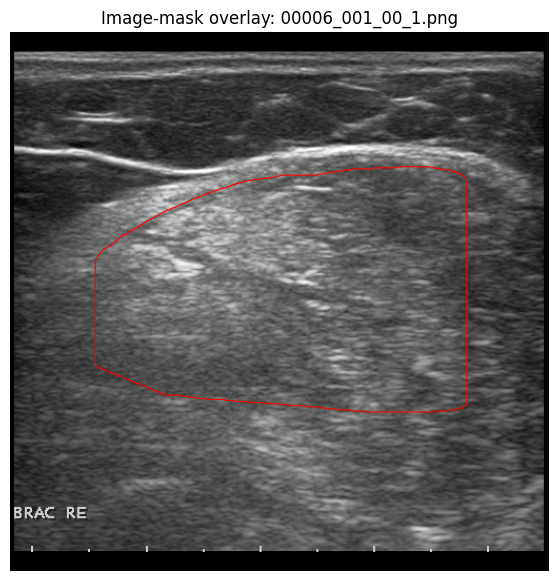

Image: (512, 512)
Mask coverage: 27.23 %


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pathlib import Path

row = df.iloc[0]

image_path = Path(row["image_path"])
mask_path = MASK_DIR / row["filename"]

with Image.open(image_path) as im:
    image = np.array(im.convert("L"))

with Image.open(mask_path) as mm:
    mask = np.array(mm) > 0

# Draw the mask boundary over the ultrasound image
boundary = mask & ~(
    np.roll(mask, 1, axis=0) &
    np.roll(mask, -1, axis=0) &
    np.roll(mask, 1, axis=1) &
    np.roll(mask, -1, axis=1)
)

plt.figure(figsize=(7, 7))
plt.imshow(image, cmap="gray")
plt.contour(mask, levels=[0.5], colors="red", linewidths=0.8)
plt.title(f"Image-mask overlay: {row['filename']}")
plt.axis("off")
plt.show()

print("Image:", image.shape)
print("Mask coverage:", round(mask.mean() * 100, 2), "%")

In [ ]:
%pip -q install pyradiomics


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'pyradiomics' when getting requirements to build wheel


In [ ]:
import sys
import pip

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Pip version:", pip.__version__)

try:
    import numpy
    print("NumPy version:", numpy.__version__)
except Exception as e:
    print("NumPy error:", e)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python executable: /usr/bin/python3
Pip version: 26.2.2
NumPy version: 2.1.3


In [ ]:
!pip index versions pyradiomics

pyradiomics (3.1.0)
Available versions: 3.1.0, 3.0.1, 3.0, 2.2.0, 2.1.2, 2.1.1, 2.1.0, 2.0.1, 2.0.0


In [ ]:
import importlib.util

packages = ["setuptools", "wheel", "Cython", "numpy", "SimpleITK", "pykwalify"]

for package in packages:
    print(f"{package}:",
          "available" if importlib.util.find_spec(package) else "missing")

setuptools: available
wheel: available
Cython: available
numpy: available
SimpleITK: missing
pykwalify: missing


In [ ]:
%pip install SimpleITK pykwalify PyWavelets

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 44.1 MB/s  0:00:01
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13781 sha256=39177cd98c3f1018ca6eefff54c3e818f93d9425f40614a32b613fc60714acae
  Stored in directory: /root/.cache/pip/wheels/0b/1d/03/175286677fb5a1341cc3e4755bf8ec0ed08f3329afd67446b0
Successfully built docopt
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pykwalify]


In [ ]:
%pip install --no-cache-dir "git+https://github.com/AIM-Harvard/pyradiomics.git"

  Cloning https://github.com/AIM-Harvard/pyradiomics.git to /tmp/pip-req-build-68ghp2i1
  Running command git clone --filter=blob:none --quiet https://github.com/AIM-Harvard/pyradiomics.git /tmp/pip-req-build-68ghp2i1
  Resolved https://github.com/AIM-Harvard/pyradiomics.git to commit 8ed579383b44806651c463d5e691f3b2b57522ab
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyradiomics: filename=pyradiomics-3.1.1.dev111+g8ed579383-cp313-cp313-linux_x86_64.whl size=122013 sha256=2d8bd1cfaa753bd8102433718061a1d97cb589d3bb1f451cb2959d17bc71bd75
  Stored in directory: /tmp/pip-ephem-wheel-cache-2ulya4wl/wheels/b1/68/13/3b4579837527049ea5bffdedba2c317d81e1d98f7e1ed0947d
Successfully built pyradiomics


In [ ]:
import radiomics
import SimpleITK as sitk
import pandas as pd

print("PyRadiomics version:", radiomics.__version__)
print("SimpleITK version:", sitk.Version_VersionString())

SPLIT_PATH = (
    PREPROCESS_DIR / "splits" / "Dataset_B_Subject_Level_Split.csv"
)

split_df = pd.read_csv(SPLIT_PATH)

print("\nSplit file shape:", split_df.shape)
print("Split columns:", split_df.columns.tolist())
print("\nFirst 5 rows:")
display(split_df.head())

PyRadiomics version: 3.1.1.dev111+g8ed579383
SimpleITK version: 2.5.6

Split file shape: (109, 2)
Split columns: ['subject_id', 'partition']

First 5 rows:


,subject_id,partition
0,6,train
1,13,test
2,19,test
3,25,train
4,76,validation


In [ ]:
# Join the manifest to the existing subject-level split.
pilot_df = df.merge(
    split_df,
    on="subject_id",
    how="left",
    validate="many_to_one"
)

# Keep only records with verified Heckmatt grades and a known partition.
labelled_df = pilot_df[
    pilot_df["heckmatt_grade"].isin([1, 2, 3, 4])
    & pilot_df["partition"].notna()
].copy()

# Select 3 records from training subjects only.
pilot_sample = (
    labelled_df[labelled_df["partition"] == "train"]
    .sort_values(["subject_id", "muscle_code", "side_code", "image_index"])
    .head(3)
    .copy()
)

required_columns = [
    "filename", "subject_id", "muscle_code", "side",
    "heckmatt_grade", "partition", "image_path", "mask_path"
]

print("Labelled records:", len(labelled_df))
print("Records without a partition:", pilot_df["partition"].isna().sum())
print("\nPilot sample:")
display(pilot_sample[required_columns])

print("\nAll pilot records are training records:",
      (pilot_sample["partition"] == "train").all())

print("All pilot grades are verified values:",
      pilot_sample["heckmatt_grade"].isin([1, 2, 3, 4]).all())

Labelled records: 4727
Records without a partition: 15606

Pilot sample:


,filename,subject_id,muscle_code,side,heckmatt_grade,partition,image_path,mask_path
0,00006_001_00_1.png,6,1,left,3.0,train,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...
1,00006_001_00_2.png,6,1,left,3.0,train,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...
2,00006_001_00_3.png,6,1,left,3.0,train,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...



All pilot records are training records: True
All pilot grades are verified values: True


In [ ]:
from radiomics import featureextractor
import SimpleITK as sitk
import pandas as pd
import numpy as np
from pathlib import Path

# Fixed pilot settings: do not fit or tune anything on validation/test data.
settings = {
    "binWidth": 25,
    "label": 1,
    "normalize": False,
    "resampledPixelSpacing": None
}

extractor = featureextractor.RadiomicsFeatureExtractor(**settings)

# Enable the intended feature families.
extractor.disableAllFeatures()
extractor.enableFeatureClassByName("firstorder")
extractor.enableFeatureClassByName("glcm")
extractor.enableFeatureClassByName("glrlm")
extractor.enableFeatureClassByName("glszm")
extractor.enableFeatureClassByName("gldm")
extractor.enableFeatureClassByName("ngtdm")

# Shape features for 2D masks.
extractor.enableFeatureClassByName("shape2D")

feature_rows = []
errors = []

for _, row in pilot_sample.iterrows():
    try:
        image_path = Path(row["image_path"])
        mask_path = MASK_DIR / row["filename"]

        image = sitk.ReadImage(str(image_path))
        mask = sitk.ReadImage(str(mask_path))

        if image.GetDimension() != 2 or mask.GetDimension() != 2:
            raise ValueError("Expected 2D ultrasound image and mask.")

        if image.GetSize() != mask.GetSize():
            raise ValueError("Image and mask sizes do not match.")

        result = extractor.execute(image, mask, label=1)

        # Keep identifiers separate from extracted features.
        record = {
            "filename": row["filename"],
            "subject_id": row["subject_id"],
            "muscle_code": row["muscle_code"],
            "side": row["side"],
            "group_id": (
                f"{row['subject_id']}_{row['muscle_code']}_{row['side_code']}"
            ),
            "heckmatt_grade": int(row["heckmatt_grade"]),
            "partition": row["partition"]
        }

        # Exclude diagnostic and diagnostic-image metadata fields.
        for key, value in result.items():
            if not key.startswith("diagnostics_"):
                record[key] = value

        feature_rows.append(record)

    except Exception as e:
        errors.append({
            "filename": row["filename"],
            "error": str(e)
        })

pilot_features = pd.DataFrame(feature_rows)

print("Successfully extracted:", len(pilot_features))
print("Extraction errors:", len(errors))
print("\nFeature table shape:", pilot_features.shape)
print("\nFirst extracted feature columns:")
print(pilot_features.columns.tolist()[:30])

if not pilot_features.empty:
    display(pilot_features.iloc[:, :15])

if errors:
    print("\nErrors:")
    display(pd.DataFrame(errors))

INFO:radiomics.featureextractor:No valid config parameter, using defaults: {'minimumROIDimensions': 2, 'minimumROISize': None, 'normalize': False, 'normalizeScale': 1, 'removeOutliers': None, 'resampledPixelSpacing': None, 'interpolator': 'sitkBSpline', 'preCrop': False, 'padDistance': 5, 'distances': [1], 'force2D': False, 'force2Ddimension': 0, 'resegmentRange': None, 'label': 1, 'additionalInfo': True}
INFO:radiomics.featureextractor:Enabled image types: {'Original': {}}
INFO:radiomics.featureextractor:Enabled features: {'firstorder': [], 'glcm': [], 'gldm': [], 'glrlm': [], 'glszm': [], 'ngtdm': [], 'shape': []}
INFO:radiomics.featureextractor:Applying custom setting overrides: {'binWidth': 25, 'label': 1, 'normalize': False, 'resampledPixelSpacing': None}
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape2D
INFO:radiomics.featureextractor:Adding image type "Origin

Successfully extracted: 3
Extraction errors: 0

Feature table shape: (3, 109)

First extracted feature columns:
['filename', 'subject_id', 'muscle_code', 'side', 'group_id', 'heckmatt_grade', 'partition', 'original_shape2D_Elongation', 'original_shape2D_MajorAxisLength', 'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface', 'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter', 'original_shape2D_PerimeterSurfaceRatio', 'original_shape2D_PixelSurface', 'original_shape2D_Sphericity', 'original_firstorder_10Percentile', 'original_firstorder_90Percentile', 'original_firstorder_Energy', 'original_firstorder_Entropy', 'original_firstorder_InterquartileRange', 'original_firstorder_Kurtosis', 'original_firstorder_Maximum', 'original_firstorder_MeanAbsoluteDeviation', 'original_firstorder_Mean', 'original_firstorder_Median', 'original_firstorder_Minimum', 'original_firstorder_Range', 'original_firstorder_RobustMeanAbsoluteDeviation', 'original_firstorder_RootMeanSquared

,filename,subject_id,muscle_code,side,group_id,heckmatt_grade,partition,original_shape2D_Elongation,original_shape2D_MajorAxisLength,original_shape2D_MaximumDiameter,original_shape2D_MeshSurface,original_shape2D_MinorAxisLength,original_shape2D_Perimeter,original_shape2D_PerimeterSurfaceRatio,original_shape2D_PixelSurface
0,00006_001_00_1.png,6,1,left,6_1_0,3,train,0.622723,389.464394,394.4464475692486,71387.5,242.528287,1084.1320343559657,0.015186580764923352,71388.0
1,00006_001_00_2.png,6,1,left,6_1_0,3,train,0.709380,396.894630,418.6096033298806,82025.5,281.548967,1198.617315730197,0.014612740132400255,82026.0
2,00006_001_00_3.png,6,1,left,6_1_0,3,train,0.663193,389.838116,400.48096084583096,74751.5,258.537719,1141.629509039021,0.015272329104285814,74752.0


In [ ]:
import SimpleITK as sitk
import numpy as np

sample_path = pilot_sample.iloc[0]["image_path"]
image = sitk.ReadImage(str(sample_path))
pixels = sitk.GetArrayFromImage(image)

print("Image:", pilot_sample.iloc[0]["filename"])
print("SimpleITK pixel type:", image.GetPixelIDTypeAsString())
print("NumPy data type:", pixels.dtype)
print("Minimum intensity:", pixels.min())
print("Maximum intensity:", pixels.max())
print("Unique intensity values:", len(np.unique(pixels)))

Image: 00006_001_00_1.png
SimpleITK pixel type: 8-bit unsigned integer
NumPy data type: uint8
Minimum intensity: 0
Maximum intensity: 254
Unique intensity values: 252


In [ ]:
import SimpleITK as sitk
import numpy as np
from pathlib import Path

row = pilot_sample.iloc[0]

# Read the image and mask
image = sitk.ReadImage(str(row["image_path"]))
mask = sitk.ReadImage(str(MASK_DIR / row["filename"]))

# Convert image to float32 without changing intensity values
image = sitk.Cast(image, sitk.sitkFloat32)

print("Image pixel type:", image.GetPixelIDTypeAsString())
print("Image size:", image.GetSize())
print("Mask size:", mask.GetSize())

# Extract features for this one image
result = extractor.execute(image, mask, label=1)

features = {
    key: value
    for key, value in result.items()
    if not key.startswith("diagnostics_")
}

feature_values = np.array(list(features.values()), dtype=float)

print("\nFeature count:", len(features))
print("NaN values:", np.isnan(feature_values).sum())
print("Infinite values:", np.isinf(feature_values).sum())
print("First 10 features:")
for key, value in list(features.items())[:10]:
    print(f"{key}: {value}")

INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape2D
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextractor:Calculating features for original image
INFO:radiomics.featureextractor:Computing firstorder


Image pixel type: 32-bit float
Image size: (512, 512)
Mask size: (512, 512)


INFO:radiomics.featureextractor:Computing glcm
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
INFO:radiomics.featureextractor:Computing glrlm
INFO:radiomics.featureextractor:Computing glszm
INFO:radiomics.featureextractor:Computing gldm
INFO:radiomics.featureextractor:Computing ngtdm



Feature count: 102
NaN values: 0
Infinite values: 0
First 10 features:
original_shape2D_Elongation: 0.6227226172770245
original_shape2D_MajorAxisLength: 389.4643938617518
original_shape2D_MaximumDiameter: 394.4464475692486
original_shape2D_MeshSurface: 71387.5
original_shape2D_MinorAxisLength: 242.52828668179998
original_shape2D_Perimeter: 1084.1320343559657
original_shape2D_PerimeterSurfaceRatio: 0.015186580764923352
original_shape2D_PixelSurface: 71388.0
original_shape2D_Sphericity: 0.8736426776858087
original_firstorder_10Percentile: 72.0


In [ ]:
feature_rows = []
errors = []

for _, row in pilot_sample.iterrows():
    try:
        image = sitk.ReadImage(str(row["image_path"]))
        mask = sitk.ReadImage(str(MASK_DIR / row["filename"]))

        # Prevent uint8 intensity-discretization overflow
        image = sitk.Cast(image, sitk.sitkFloat32)

        if image.GetDimension() != 2 or mask.GetDimension() != 2:
            raise ValueError("Expected 2D image and mask.")

        if image.GetSize() != mask.GetSize():
            raise ValueError("Image and mask sizes do not match.")

        result = extractor.execute(image, mask, label=1)

        record = {
            "filename": row["filename"],
            "subject_id": row["subject_id"],
            "muscle_code": row["muscle_code"],
            "side": row["side"],
            "group_id": f"{row['subject_id']}_{row['muscle_code']}_{row['side_code']}",
            "heckmatt_grade": int(row["heckmatt_grade"]),
            "partition": row["partition"]
        }

        for key, value in result.items():
            if not key.startswith("diagnostics_"):
                record[key] = value

        feature_rows.append(record)

    except Exception as e:
        errors.append({
            "filename": row["filename"],
            "error": str(e)
        })

pilot_features = pd.DataFrame(feature_rows)

print("Successfully extracted:", len(pilot_features))
print("Extraction errors:", len(errors))
print("Feature table shape:", pilot_features.shape)

if not pilot_features.empty:
    feature_cols = pilot_features.select_dtypes(include="number").columns
    print("Missing numeric values:", pilot_features[feature_cols].isna().sum().sum())
    print("Infinite numeric values:",
          np.isinf(pilot_features[feature_cols].to_numpy(dtype=float)).sum())
    print("\nIdentifiers and labels:")
    display(pilot_features[
        ["filename", "subject_id", "muscle_code", "side",
         "group_id", "heckmatt_grade", "partition"]
    ])

if errors:
    display(pd.DataFrame(errors))

INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape2D
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextractor:Calculating features for original image
INFO:radiomics.featureextractor:Computing firstorder
INFO:radiomics.featureextractor:Computing glcm
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
INFO:radiomics.featureextractor:Computing glrlm
INFO:radiomics.featureextractor:Computing glszm
INFO:radiomics.featureextractor:Computing gldm
INFO:radiomics.featureextractor:Computing ngtdm
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape2D
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextra

Successfully extracted: 3
Extraction errors: 0
Feature table shape: (3, 109)
Missing numeric values: 0
Infinite numeric values: 0

Identifiers and labels:


,filename,subject_id,muscle_code,side,group_id,heckmatt_grade,partition
0,00006_001_00_1.png,6,1,left,6_1_0,3,train
1,00006_001_00_2.png,6,1,left,6_1_0,3,train
2,00006_001_00_3.png,6,1,left,6_1_0,3,train


In [ ]:
import numpy as np
import pandas as pd
import SimpleITK as sitk

# Check feature values
feature_cols = [
    c for c in pilot_features.columns
    if c.startswith("original_")
]

print("Radiomics feature count:", len(feature_cols))
print("Features with zero variance:",
      (pilot_features[feature_cols].nunique() <= 1).sum())

# Inspect each mask's coverage and intensity range
checks = []

for _, row in pilot_sample.iterrows():
    image = sitk.GetArrayFromImage(
        sitk.ReadImage(str(row["image_path"]))
    )
    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(str(MASK_DIR / row["filename"]))
    )

    roi_pixels = np.count_nonzero(mask == 1)

    checks.append({
        "filename": row["filename"],
        "mask_pixels": int(roi_pixels),
        "mask_coverage_percent": round(
            100 * roi_pixels / mask.size, 2
        ),
        "image_min": int(image.min()),
        "image_max": int(image.max()),
        "mask_labels": np.unique(mask).tolist()
    })

display(pd.DataFrame(checks))

Radiomics feature count: 102


TypeError: unhashable type: 'numpy.ndarray'

In [ ]:
import numpy as np
import pandas as pd
import SimpleITK as sitk

feature_cols = [
    c for c in pilot_features.columns
    if c.startswith("original_")
]

# Keep only features containing scalar numeric values
scalar_feature_cols = [
    c for c in feature_cols
    if all(
        np.isscalar(v) and isinstance(v, (int, float, np.number))
        for v in pilot_features[c]
    )
]

print("Total radiomics features:", len(feature_cols))
print("Scalar numeric features:", len(scalar_feature_cols))

print(
    "Zero-variance features:",
    (pilot_features[scalar_feature_cols].nunique() <= 1).sum()
)

# Check mask coverage and image intensity range
checks = []

for _, row in pilot_sample.iterrows():
    image = sitk.GetArrayFromImage(
        sitk.ReadImage(str(row["image_path"]))
    )
    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(str(MASK_DIR / row["filename"]))
    )

    roi_pixels = np.count_nonzero(mask == 1)

    checks.append({
        "filename": row["filename"],
        "mask_pixels": int(roi_pixels),
        "mask_coverage_percent": round(
            100 * roi_pixels / mask.size, 2
        ),
        "image_min": int(image.min()),
        "image_max": int(image.max()),
        "mask_labels": np.unique(mask).tolist()
    })

display(pd.DataFrame(checks))

Total radiomics features: 102
Scalar numeric features: 5
Zero-variance features: 0


,filename,mask_pixels,mask_coverage_percent,image_min,image_max,mask_labels
0,00006_001_00_1.png,71388,27.23,0,254,"[0, 1]"
1,00006_001_00_2.png,82026,31.29,0,255,"[0, 1]"
2,00006_001_00_3.png,74752,28.52,0,255,"[0, 1]"


In [ ]:
from collections import Counter
import numpy as np

feature_cols = [
    c for c in pilot_features.columns
    if c.startswith("original_")
]

print("Feature value type counts:")
print(Counter(
    type(value).__name__
    for col in feature_cols
    for value in pilot_features[col]
))

print("\nSample feature values and types:")
for col in feature_cols[:15]:
    value = pilot_features[col].iloc[0]
    print(f"{col}: {value!r} | type={type(value).__name__}")

Feature value type counts:
Counter({'ndarray': 291, 'float': 15})

Sample feature values and types:
original_shape2D_Elongation: np.float64(0.6227226172770245) | type=float64
original_shape2D_MajorAxisLength: np.float64(389.4643938617518) | type=float64
original_shape2D_MaximumDiameter: array(394.44644757) | type=ndarray
original_shape2D_MeshSurface: array(71387.5) | type=ndarray
original_shape2D_MinorAxisLength: np.float64(242.52828668179998) | type=float64
original_shape2D_Perimeter: array(1084.13203436) | type=ndarray
original_shape2D_PerimeterSurfaceRatio: array(0.01518658) | type=ndarray
original_shape2D_PixelSurface: np.float64(71388.0) | type=float64
original_shape2D_Sphericity: np.float64(0.8736426776858087) | type=float64
original_firstorder_10Percentile: array(72.) | type=ndarray
original_firstorder_90Percentile: array(145.) | type=ndarray
original_firstorder_Energy: array(8.38712676e+08) | type=ndarray
original_firstorder_Entropy: array(2.22933745) | type=ndarray
original_fi

In [ ]:
import numpy as np
import pandas as pd

pilot_features_clean = pilot_features.copy()

feature_cols = [
    c for c in pilot_features_clean.columns
    if c.startswith("original_")
]

for col in feature_cols:
    pilot_features_clean[col] = pilot_features_clean[col].apply(
        lambda value: float(np.asarray(value).item())
        if np.asarray(value).size == 1
        else np.nan
    )

# Validate the cleaned feature table
feature_values = pilot_features_clean[feature_cols].to_numpy(dtype=float)

print("Feature table shape:", pilot_features_clean.shape)
print("Radiomics feature count:", len(feature_cols))
print("Missing feature values:", np.isnan(feature_values).sum())
print("Infinite feature values:", np.isinf(feature_values).sum())
print(
    "Zero-variance features:",
    (pilot_features_clean[feature_cols].nunique() <= 1).sum()
)

print("\nFirst 10 feature values:")
display(pilot_features_clean[feature_cols].iloc[:, :10])

Feature table shape: (3, 109)
Radiomics feature count: 102
Missing feature values: 0
Infinite feature values: 0
Zero-variance features: 0

First 10 feature values:


,original_shape2D_Elongation,original_shape2D_MajorAxisLength,original_shape2D_MaximumDiameter,original_shape2D_MeshSurface,original_shape2D_MinorAxisLength,original_shape2D_Perimeter,original_shape2D_PerimeterSurfaceRatio,original_shape2D_PixelSurface,original_shape2D_Sphericity,original_firstorder_10Percentile
0,0.622723,389.464394,394.446448,71387.5,242.528287,1084.132034,0.015187,71388.0,0.873643,72.0
1,0.709380,396.894630,418.609603,82025.5,281.548967,1198.617316,0.014613,82026.0,0.847030,71.0
2,0.663193,389.838116,400.480961,74751.5,258.537719,1141.629509,0.015272,74752.0,0.848965,71.0


In [ ]:
# Select one labelled training image from each of 10 distinct subjects
pilot_10 = (
    labelled_df[labelled_df["partition"] == "train"]
    .sort_values(["subject_id", "muscle_code", "side_code", "image_index"])
    .drop_duplicates(subset="subject_id", keep="first")
    .head(10)
    .copy()
)

print("Pilot records:", len(pilot_10))
print("Distinct subjects:", pilot_10["subject_id"].nunique())
print("\nSelected records:")
display(
    pilot_10[
        ["filename", "subject_id", "muscle_code", "side",
         "heckmatt_grade", "partition"]
    ]
)

Pilot records: 10
Distinct subjects: 10

Selected records:


,filename,subject_id,muscle_code,side,heckmatt_grade,partition
0,00006_001_00_1.png,6,1,left,3.0,train
232,00025_001_00_1.png,25,1,left,1.0,train
991,00082_001_00_1.png,82,1,left,3.0,train
1179,00097_001_00_1.png,97,1,left,2.0,train
1667,00103_001_00_1.png,103,1,left,1.0,train
1743,00111_001_00_1.png,111,1,left,2.0,train
1838,00133_001_00_1.png,133,1,left,1.0,train
2192,00151_001_00_1.png,151,1,left,3.0,train
2700,00157_001_00_1.png,157,1,left,1.0,train
3137,00177_008_00_1.png,177,8,left,1.0,train


In [ ]:
feature_rows_10 = []
errors_10 = []

for _, row in pilot_10.iterrows():
    try:
        image = sitk.ReadImage(str(row["image_path"]))
        mask = sitk.ReadImage(str(MASK_DIR / row["filename"]))

        image = sitk.Cast(image, sitk.sitkFloat32)

        if image.GetDimension() != 2 or mask.GetDimension() != 2:
            raise ValueError("Expected 2D image and mask.")

        if image.GetSize() != mask.GetSize():
            raise ValueError("Image and mask sizes do not match.")

        result = extractor.execute(image, mask, label=1)

        record = {
            "filename": row["filename"],
            "subject_id": row["subject_id"],
            "muscle_code": row["muscle_code"],
            "side": row["side"],
            "group_id": f"{row['subject_id']}_{row['muscle_code']}_{row['side_code']}",
            "heckmatt_grade": int(row["heckmatt_grade"]),
            "partition": row["partition"]
        }

        for key, value in result.items():
            if not key.startswith("diagnostics_"):
                arr = np.asarray(value)
                if arr.size != 1:
                    raise ValueError(
                        f"Feature {key} is not a single numeric value."
                    )
                record[key] = float(arr.item())

        feature_rows_10.append(record)

    except Exception as e:
        errors_10.append({
            "filename": row["filename"],
            "error": str(e)
        })

pilot_features_10 = pd.DataFrame(feature_rows_10)

feature_cols_10 = [
    c for c in pilot_features_10.columns
    if c.startswith("original_")
]

print("Successful extractions:", len(pilot_features_10))
print("Extraction errors:", len(errors_10))
print("Feature table shape:", pilot_features_10.shape)
print("Distinct subjects:", pilot_features_10["subject_id"].nunique()
      if not pilot_features_10.empty else 0)

if not pilot_features_10.empty:
    values = pilot_features_10[feature_cols_10].to_numpy(dtype=float)
    print("Missing feature values:", np.isnan(values).sum())
    print("Infinite feature values:", np.isinf(values).sum())

if errors_10:
    display(pd.DataFrame(errors_10))

INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape2D
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextractor:Calculating features for original image
INFO:radiomics.featureextractor:Computing firstorder
INFO:radiomics.featureextractor:Computing glcm
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
INFO:radiomics.featureextractor:Computing glrlm
INFO:radiomics.featureextractor:Computing glszm
INFO:radiomics.featureextractor:Computing gldm
INFO:radiomics.featureextractor:Computing ngtdm
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape2D
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextra

Successful extractions: 10
Extraction errors: 0
Feature table shape: (10, 109)
Distinct subjects: 10
Missing feature values: 0
Infinite feature values: 0


In [ ]:
import numpy as np
import pandas as pd
import SimpleITK as sitk

coverage_checks = []

for _, row in pilot_10.iterrows():
    image = sitk.ReadImage(str(row["image_path"]))
    mask = sitk.ReadImage(str(MASK_DIR / row["filename"]))

    image_array = sitk.GetArrayFromImage(image)
    mask_array = sitk.GetArrayFromImage(mask)

    roi_pixels = np.count_nonzero(mask_array == 1)

    coverage_checks.append({
        "filename": row["filename"],
        "subject_id": row["subject_id"],
        "heckmatt_grade": int(row["heckmatt_grade"]),
        "image_size": image.GetSize(),
        "mask_size": mask.GetSize(),
        "mask_coverage_percent": round(
            100 * roi_pixels / mask_array.size, 2
        ),
        "mask_labels": np.unique(mask_array).tolist()
    })

coverage_df = pd.DataFrame(coverage_checks)
display(coverage_df)

print("\nDimension mismatches:", sum(
    a != b for a, b in zip(
        coverage_df["image_size"],
        coverage_df["mask_size"]
    )
))
print(
    "Empty masks:",
    (coverage_df["mask_coverage_percent"] == 0).sum()
)

,filename,subject_id,heckmatt_grade,image_size,mask_size,mask_coverage_percent,mask_labels
0,00006_001_00_1.png,6,3,"(512, 512)","(512, 512)",27.23,"[0, 1]"
1,00025_001_00_1.png,25,1,"(512, 512)","(512, 512)",25.02,"[0, 1]"
2,00082_001_00_1.png,82,3,"(512, 512)","(512, 512)",14.03,"[0, 1]"
3,00097_001_00_1.png,97,2,"(512, 512)","(512, 512)",28.74,"[0, 1]"
4,00103_001_00_1.png,103,1,"(512, 512)","(512, 512)",16.04,"[0, 1]"
5,00111_001_00_1.png,111,2,"(512, 512)","(512, 512)",31.79,"[0, 1]"
6,00133_001_00_1.png,133,1,"(512, 512)","(512, 512)",27.25,"[0, 1]"
7,00151_001_00_1.png,151,3,"(512, 512)","(512, 512)",18.28,"[0, 1]"
8,00157_001_00_1.png,157,1,"(512, 512)","(512, 512)",29.21,"[0, 1]"
9,00177_008_00_1.png,177,1,"(512, 512)","(512, 512)",17.53,"[0, 1]"



Dimension mismatches: 0
Empty masks: 0


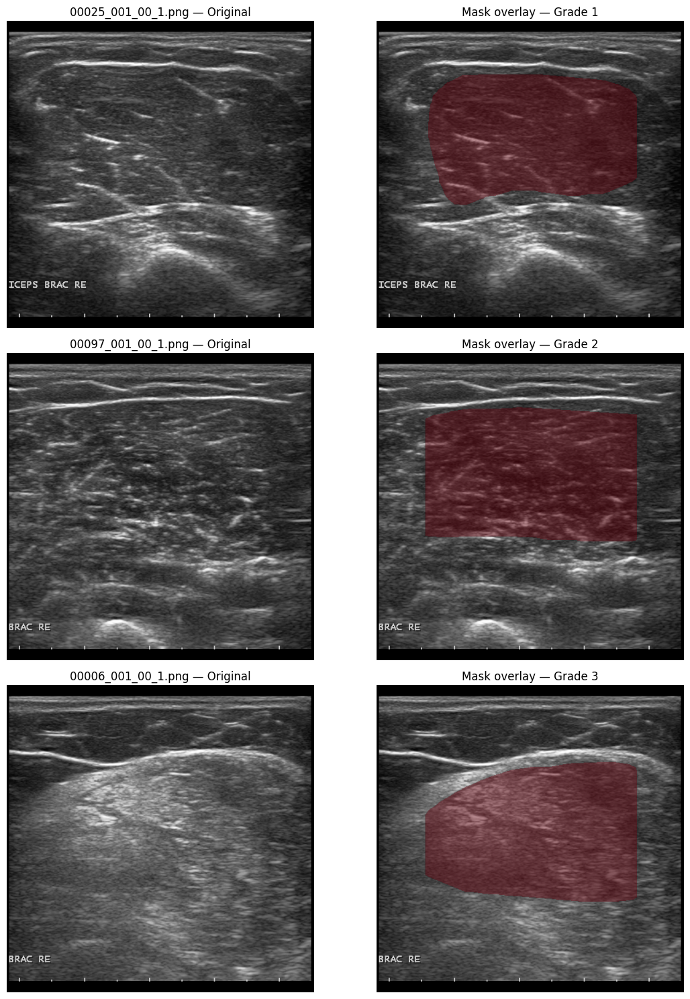

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import SimpleITK as sitk

# Inspect three samples with different Heckmatt grades
sample_files = [
    "00025_001_00_1.png",  # Grade 1
    "00097_001_00_1.png",  # Grade 2
    "00006_001_00_1.png"   # Grade 3
]

fig, axes = plt.subplots(len(sample_files), 2, figsize=(12, 15))

for i, filename in enumerate(sample_files):
    row = pilot_10[pilot_10["filename"] == filename].iloc[0]

    image = sitk.GetArrayFromImage(
        sitk.ReadImage(str(row["image_path"]))
    )
    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(str(MASK_DIR / filename))
    )

    # Original image
    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(f"{filename} — Original")
    axes[i, 0].axis("off")

    # Mask overlay: red indicates the selected ROI
    axes[i, 1].imshow(image, cmap="gray")
    overlay = np.ma.masked_where(mask != 1, mask)
    axes[i, 1].imshow(overlay, cmap="Reds", alpha=0.45, vmin=0, vmax=1)
    axes[i, 1].set_title(
        f"Mask overlay — Grade {int(row['heckmatt_grade'])}"
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

DATASET_ROOT = (
    PROJECT_ROOT
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
)

MANIFEST_PATH = (
    DATASET_ROOT
    / "Audit_Results"
    / "Dataset_B_Image_Mask_Manifest.csv"
)

SPLIT_PATH = (
    DATASET_ROOT
    / "Audit_Results"
    / "Dataset_B_Subject_Level_Split.csv"
)

PROCESSED_MASKS_DIR = (
    PROJECT_ROOT
    / "04_Preprocessing"
    / "Dataset_B_FSHD_Preprocessing"
    / "processed_masks"
)

required_paths = {
    "Manifest": MANIFEST_PATH,
    "Approved subject split": SPLIT_PATH,
    "Processed masks directory": PROCESSED_MASKS_DIR,
}

for name, path in required_paths.items():
    exists = path.exists()
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")
    print(f"  {path}")

assert all(path.exists() for path in required_paths.values()), (
    "A required path is missing. Stop here and share the output."
)

assert MANIFEST_PATH.is_file(), "Manifest path is not a file."
assert SPLIT_PATH.is_file(), "Split path is not a file."
assert PROCESSED_MASKS_DIR.is_dir(), "Processed masks path is not a directory."

print("\nSTEP 1 RESULT: PASS")

Manifest: FOUND
  /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Image_Mask_Manifest.csv
Approved subject split: FOUND
  /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/Dataset_B_Subject_Level_Split.csv
Processed masks directory: FOUND
  /content/drive/MyDrive/Muscular_Dystrophy_Project/04_Preprocessing/Dataset_B_FSHD_Preprocessing/processed_masks

STEP 1 RESULT: PASS


In [ ]:
import pandas as pd

manifest = pd.read_csv(MANIFEST_PATH, nrows=5)
split = pd.read_csv(SPLIT_PATH, nrows=5)

print("=" * 70)
print("MANIFEST — COLUMN NAMES AND DATA TYPES")
print("=" * 70)
print(manifest.dtypes.to_string())

print("\nMANIFEST — FIRST 3 RECORDS")
print(manifest.head(3).to_string(index=False))

print("\n" + "=" * 70)
print("SUBJECT SPLIT — COLUMN NAMES AND DATA TYPES")
print("=" * 70)
print(split.dtypes.to_string())

print("\nSUBJECT SPLIT — FIRST 5 RECORDS")
print(split.head().to_string(index=False))

print("\nSTEP 2 RESULT: SCHEMA INSPECTION COMPLETE")

MANIFEST — COLUMN NAMES AND DATA TYPES
filename               object
image_path             object
mask_path              object
mask_exists              bool
subject_id              int64
muscle_code             int64
side_code               int64
side                   object
image_index             int64
heckmatt_grade        float64
metadata_available       bool

MANIFEST — FIRST 3 RECORDS
          filename                                                                                                                                    image_path                                                                                                                                   mask_path  mask_exists  subject_id  muscle_code  side_code side  image_index  heckmatt_grade  metadata_available
00006_001_00_1.png /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Images/images/00006_001_00_1.png /content/drive/MyDrive/Muscular_Dystro

In [ ]:
import pandas as pd
from pathlib import Path

# Read the complete tables, without modifying the saved files
manifest_df = pd.read_csv(MANIFEST_PATH)
split_df = pd.read_csv(SPLIT_PATH)

# Keep only records with verified labels
labelled_df = manifest_df[
    manifest_df["heckmatt_grade"].notna()
].copy()

# Attach the approved subject-level partition
labelled_df = labelled_df.merge(
    split_df,
    on="subject_id",
    how="left",
    validate="many_to_one"
)

print("Labelled records:", len(labelled_df))
print("Records without a partition:", labelled_df["partition"].isna().sum())
print("\nPartition counts:")
print(labelled_df["partition"].value_counts(dropna=False).to_string())

# Check two deterministic samples from each partition
print("\n" + "=" * 85)
print("TARGETED FILE-EXISTENCE CHECK")
print("=" * 85)

all_pass = True

for partition in ["train", "validation", "test"]:
    part = labelled_df[labelled_df["partition"] == partition]

    if part.empty:
        print(f"\n{partition.upper()}: NO LABELLED RECORDS")
        all_pass = False
        continue

    samples = part.head(2)

    print(f"\n{partition.upper()} — checking {len(samples)} records")

    for _, row in samples.iterrows():
        image_path = Path(row["image_path"])
        original_mask_path = Path(row["mask_path"])
        processed_mask_path = PROCESSED_MASKS_DIR / str(row["filename"])

        checks = {
            "image": image_path.is_file(),
            "original mask": original_mask_path.is_file(),
            "processed mask": processed_mask_path.is_file(),
        }

        print(
            f"{row['filename']} | subject={row['subject_id']} "
            f"| grade={row['heckmatt_grade']} | "
            f"partition={row['partition']}"
        )

        for name, exists in checks.items():
            print(f"  {name}: {'FOUND' if exists else 'MISSING'}")

        if not all(checks.values()):
            all_pass = False

print("\nSTEP 3 RESULT:", "PASS" if all_pass else "CHECK REQUIRED")

Labelled records: 4727
Records without a partition: 0

Partition counts:
partition
train         3342
validation     741
test           644

TARGETED FILE-EXISTENCE CHECK

TRAIN — checking 2 records
00006_001_00_1.png | subject=6 | grade=3.0 | partition=train
  image: FOUND
  original mask: FOUND
  processed mask: FOUND
00006_001_00_2.png | subject=6 | grade=3.0 | partition=train
  image: FOUND
  original mask: FOUND
  processed mask: FOUND

VALIDATION — checking 2 records
00076_001_00_1.png | subject=76 | grade=2.0 | partition=validation
  image: FOUND
  original mask: FOUND
  processed mask: FOUND
00076_001_00_2.png | subject=76 | grade=2.0 | partition=validation
  image: FOUND
  original mask: FOUND
  processed mask: FOUND

TEST — checking 2 records
00013_001_00_1.png | subject=13 | grade=3.0 | partition=test
  image: FOUND
  original mask: FOUND
  processed mask: FOUND
00013_001_00_2.png | subject=13 | grade=3.0 | partition=test
  image: FOUND
  original mask: FOUND
  processed mas

In [ ]:
import numpy as np
from PIL import Image

print("=" * 75)
print("IMAGE + PROCESSED MASK LOADING TEST")
print("=" * 75)

all_pass = True

for partition in ["train", "validation", "test"]:
    part = labelled_df[labelled_df["partition"] == partition]
    samples = part.head(2)

    print(f"\n{partition.upper()}")

    for _, row in samples.iterrows():
        image_path = Path(row["image_path"])
        mask_path = PROCESSED_MASKS_DIR / str(row["filename"])

        try:
            # Load original ultrasound image as grayscale
            with Image.open(image_path) as img:
                image = np.asarray(img.convert("L"))

            # Load Rupam's processed mask without rescaling its pixel values
            with Image.open(mask_path) as msk:
                mask = np.asarray(msk)

            # Normalize image for model input
            image_float = image.astype(np.float32) / 255.0

            image_ok = (
                image.ndim == 2
                and image.shape == (512, 512)
                and image_float.dtype == np.float32
                and np.isfinite(image_float).all()
                and image_float.min() >= 0.0
                and image_float.max() <= 1.0
            )

            mask_values = set(np.unique(mask).tolist())
            mask_ok = (
                mask.ndim == 2
                and mask.shape == (512, 512)
                and mask_values.issubset({0, 1})
                and len(mask_values) > 0
            )

            pair_ok = image_ok and mask_ok
            all_pass = all_pass and pair_ok

            print(f"\n  File: {row['filename']}")
            print(f"  Image shape/dtype: {image.shape} / {image_float.dtype}")
            print(
                f"  Normalized image range: "
                f"{image_float.min():.4f} to {image_float.max():.4f}"
            )
            print(f"  Processed mask shape: {mask.shape}")
            print(f"  Processed mask pixel values: {sorted(mask_values)}")
            print(f"  Image check: {'PASS' if image_ok else 'FAIL'}")
            print(f"  Mask check:  {'PASS' if mask_ok else 'FAIL'}")
            print(f"  Pair check:  {'PASS' if pair_ok else 'FAIL'}")

        except Exception as exc:
            all_pass = False
            print(f"\n  File: {row['filename']}")
            print(f"  LOADING ERROR: {type(exc).__name__}: {exc}")

print("\n" + "=" * 75)
print("STEP 4 RESULT:", "PASS" if all_pass else "CHECK REQUIRED")

IMAGE + PROCESSED MASK LOADING TEST

TRAIN

  File: 00006_001_00_1.png
  Image shape/dtype: (512, 512) / float32
  Normalized image range: 0.0000 to 0.9961
  Processed mask shape: (512, 512)
  Processed mask pixel values: [0, 1]
  Image check: PASS
  Mask check:  PASS
  Pair check:  PASS

  File: 00006_001_00_2.png
  Image shape/dtype: (512, 512) / float32
  Normalized image range: 0.0000 to 1.0000
  Processed mask shape: (512, 512)
  Processed mask pixel values: [0, 1]
  Image check: PASS
  Mask check:  PASS
  Pair check:  PASS

VALIDATION

  File: 00076_001_00_1.png
  Image shape/dtype: (512, 512) / float32
  Normalized image range: 0.0000 to 1.0000
  Processed mask shape: (512, 512)
  Processed mask pixel values: [0, 1]
  Image check: PASS
  Mask check:  PASS
  Pair check:  PASS

  File: 00076_001_00_2.png
  Image shape/dtype: (512, 512) / float32
  Normalized image range: 0.0000 to 1.0000
  Processed mask shape: (512, 512)
  Processed mask pixel values: [0, 1]
  Image check: PASS
 

In [ ]:
# Confirm required fields are available for the supervised loader
required_columns = [
    "filename",
    "image_path",
    "subject_id",
    "muscle_code",
    "side_code",
    "side",
    "heckmatt_grade",
    "partition",
]

missing_columns = [
    col for col in required_columns
    if col not in labelled_df.columns
]

print("=" * 70)
print("SUPERVISED LOADER METADATA CHECK")
print("=" * 70)

print("Missing required columns:", missing_columns)

# Confirm that all records in this loader have verified labels
unlabelled_count = labelled_df["heckmatt_grade"].isna().sum()
print("Unlabelled records in supervised table:", unlabelled_count)

# Confirm expected Heckmatt grade values
print("\nGrade counts across labelled records:")
print(labelled_df["heckmatt_grade"].value_counts().sort_index().to_string())

# Check whether the subject–muscle–side grouping key can be constructed
group_columns = ["subject_id", "muscle_code", "side_code"]
group_key_missing = labelled_df[group_columns].isna().any(axis=1).sum()

print("\nRecords missing group identifiers:", group_key_missing)

# Check that each subject belongs to only one partition
subject_partition_counts = (
    labelled_df.groupby("subject_id")["partition"].nunique()
)
overlap_subjects = int((subject_partition_counts > 1).sum())

print("Subjects appearing in multiple partitions:", overlap_subjects)

passed = (
    len(missing_columns) == 0
    and unlabelled_count == 0
    and group_key_missing == 0
    and overlap_subjects == 0
)

print("\nSTEP 5 RESULT:", "PASS" if passed else "CHECK REQUIRED")

NameError: name 'labelled_df' is not defined

In [ ]:
from pathlib import Path
import pandas as pd
import torch

print("=" * 65)
print("STAGE 3 — CNN BASELINE: ENVIRONMENT CHECK")
print("=" * 65)

print("\n1. PyTorch")
print("Version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not currently available")

print("\n2. Existing project variables")

variables_to_check = [
    "PROJECT_ROOT",
    "DATASET_ROOT",
    "MANIFEST_PATH",
    "SPLIT_PATH",
    "PROCESSED_MASKS_DIR",
    "manifest_df",
    "labelled_df",
]

for name in variables_to_check:
    if name in globals():
        value = globals()[name]
        if isinstance(value, pd.DataFrame):
            print(f"{name}: available, shape={value.shape}")
        else:
            print(f"{name}: available")
    else:
        print(f"{name}: not defined in current runtime")

print("\n3. Saved split file")
split_path = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/"
    "Audit_Results/Dataset_B_Subject_Level_Split.csv"
)
print("Split file exists:", split_path.is_file())

print("\nSTEP 1 RESULT: ENVIRONMENT CHECK COMPLETE")

STAGE 3 — CNN BASELINE: ENVIRONMENT CHECK

1. PyTorch
Version: 2.11.0+cpu
CUDA available: False
GPU: Not currently available

2. Existing project variables
PROJECT_ROOT: not defined in current runtime
DATASET_ROOT: not defined in current runtime
MANIFEST_PATH: not defined in current runtime
SPLIT_PATH: not defined in current runtime
PROCESSED_MASKS_DIR: not defined in current runtime
manifest_df: not defined in current runtime
labelled_df: not defined in current runtime

3. Saved split file
Split file exists: True

STEP 1 RESULT: ENVIRONMENT CHECK COMPLETE


In [ ]:
from pathlib import Path
import pandas as pd

# Existing project paths
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

DATASET_ROOT = (
    PROJECT_ROOT
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
)

MANIFEST_PATH = (
    DATASET_ROOT
    / "Audit_Results"
    / "Dataset_B_Image_Mask_Manifest.csv"
)

SPLIT_PATH = (
    DATASET_ROOT
    / "Audit_Results"
    / "Dataset_B_Subject_Level_Split.csv"
)

PROCESSED_MASKS_DIR = (
    PROJECT_ROOT
    / "04_Preprocessing"
    / "Dataset_B_FSHD_Preprocessing"
    / "processed_masks"
)

# Load existing records
manifest_df = pd.read_csv(MANIFEST_PATH)
split_df = pd.read_csv(SPLIT_PATH)

# Use only records with verified Heckmatt labels
labelled_df = manifest_df[
    manifest_df["heckmatt_grade"].notna()
].copy()

# Attach the already-approved subject-level split
labelled_df = labelled_df.merge(
    split_df,
    on="subject_id",
    how="left",
    validate="many_to_one"
)

# Basic integrity checks
assert labelled_df["partition"].notna().all()
assert labelled_df["heckmatt_grade"].isin([1, 2, 3, 4]).all()
assert labelled_df["subject_id"].notna().all()

# Display dataset summary
print("=" * 65)
print("CNN BASELINE — DATASET INITIALIZATION")
print("=" * 65)

print("\nManifest records:", len(manifest_df))
print("Labelled records:", len(labelled_df))

print("\nPartition distribution:")
print(labelled_df["partition"].value_counts().to_string())

print("\nHeckmatt grade distribution:")
print(
    labelled_df["heckmatt_grade"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nSubject counts:")
print(
    labelled_df.groupby("partition")["subject_id"]
    .nunique()
    .to_string()
)

print("\nProcessed masks directory exists:",
      PROCESSED_MASKS_DIR.is_dir())

print("\nSTEP 2 RESULT: PASS")

CNN BASELINE — DATASET INITIALIZATION

Manifest records: 25005
Labelled records: 4727

Partition distribution:
partition
train         3342
validation     741
test           644

Heckmatt grade distribution:
heckmatt_grade
1.0    1608
2.0    1739
3.0    1201
4.0     179

Subject counts:
partition
test          16
train         76
validation    17

Processed masks directory exists: True

STEP 2 RESULT: PASS


In [ ]:
import torch
import torchvision

print("=" * 60)
print("CNN ARCHITECTURE ENVIRONMENT CHECK")
print("=" * 60)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("\nAvailable architecture:")
try:
    model = torchvision.models.resnet18(weights=None)
    print("ResNet-18: AVAILABLE")
    print("Classification output features:",
          model.fc.out_features)
except Exception as e:
    print("ResNet-18: NOT AVAILABLE")
    print("Error:", e)

print("\nGPU available:", torch.cuda.is_available())

print("\nSTEP 3 RESULT: CHECK COMPLETE")


STEP 3 RESULT: CHECK COMPLETE


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# Load pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
cnn_model = models.resnet18(weights=weights)

# Convert RGB input to grayscale
old_conv = cnn_model.conv1

new_conv = nn.Conv2d(
    1,
    old_conv.out_channels,
    kernel_size=old_conv.kernel_size,
    stride=old_conv.stride,
    padding=old_conv.padding,
    bias=False
)

with torch.no_grad():
    new_conv.weight.copy_(
        old_conv.weight.mean(dim=1, keepdim=True)
    )

cnn_model.conv1 = new_conv

# Four Heckmatt classes
cnn_model.fc = nn.Linear(512, 4)

# GPU
device = torch.device("cuda")
cnn_model = cnn_model.to(device)

print("Architecture: ResNet-18")
print("Pretrained: ImageNet")
print("Input channels:", cnn_model.conv1.in_channels)
print("Output classes:", cnn_model.fc.out_features)
print("Device:", next(cnn_model.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))

print("\nSTEP 4 RESULT: PASS")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 115MB/s]


Architecture: ResNet-18
Pretrained: ImageNet
Input channels: 1
Output classes: 4
Device: cuda:0
GPU: Tesla T4

STEP 4 RESULT: PASS


In [ ]:
# CNN baseline training configuration

NUM_CLASSES = 4
CLASS_NAMES = ["G1", "G2", "G3", "G4"]

IMAGE_SIZE = 224
BATCH_SIZE = 32

LEARNING_RATE = 0.0001
WEIGHT_DECAY = 0.0001

NUM_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 7

RANDOM_SEED = 42

print("=" * 60)
print("CNN BASELINE CONFIGURATION")
print("=" * 60)

print("Architecture: ResNet-18")
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", NUM_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Class names:", CLASS_NAMES)
print("Random seed:", RANDOM_SEED)
print("Device:", device)

assert cnn_model.fc.out_features == NUM_CLASSES
assert device.type == "cuda"

print("\nSTEP 5 RESULT: PASS")

CNN BASELINE CONFIGURATION
Architecture: ResNet-18
Image size: 224
Batch size: 32
Learning rate: 0.0001
Weight decay: 0.0001
Maximum epochs: 30
Early stopping patience: 7
Class names: ['G1', 'G2', 'G3', 'G4']
Random seed: 42
Device: cuda

STEP 5 RESULT: PASS


In [ ]:
import numpy as np
import pandas as pd

# Reproducibility
import random
import torch

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)

# Create independent partition dataframes
train_df = labelled_df[
    labelled_df["partition"] == "train"
].copy()

val_df = labelled_df[
    labelled_df["partition"] == "validation"
].copy()

test_df = labelled_df[
    labelled_df["partition"] == "test"
].copy()

# Convert grades 1, 2, 3, 4 into class indices 0, 1, 2, 3
for df in [train_df, val_df, test_df]:
    df["label"] = df["heckmatt_grade"].astype(int) - 1

    # Preserve group identity for later group-level evaluation
    df["group_id"] = (
        df["subject_id"].astype(str) + "_" +
        df["muscle_code"].astype(str) + "_" +
        df["side_code"].astype(str)
    )

# Verify partition sizes
print("=" * 65)
print("CNN TRAINING RECORD PREPARATION")
print("=" * 65)

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name}")
    print("Image records:", len(df))
    print("Unique subjects:", df["subject_id"].nunique())
    print("Unique groups:", df["group_id"].nunique())
    print("Class counts:")
    print(
        df["label"]
        .value_counts()
        .reindex(range(NUM_CLASSES), fill_value=0)
        .sort_index()
        .rename(index={0: "G1", 1: "G2", 2: "G3", 3: "G4"})
        .to_string()
    )

# Integrity checks
assert len(train_df) == 3342
assert len(val_df) == 741
assert len(test_df) == 644

assert sum(map(len, [train_df, val_df, test_df])) == 4727

assert all(
    df["label"].between(0, 3).all()
    for df in [train_df, val_df, test_df]
)

assert set(train_df["subject_id"]).isdisjoint(val_df["subject_id"])
assert set(train_df["subject_id"]).isdisjoint(test_df["subject_id"])
assert set(val_df["subject_id"]).isdisjoint(test_df["subject_id"])

print("\nSTEP 6 RESULT: PASS")

CNN TRAINING RECORD PREPARATION

TRAIN
Image records: 3342
Unique subjects: 76
Unique groups: 1029
Class counts:
label
G1    1156
G2    1248
G3     815
G4     123

VALIDATION
Image records: 741
Unique subjects: 17
Unique groups: 231
Class counts:
label
G1    233
G2    309
G3    176
G4     23

TEST
Image records: 644
Unique subjects: 16
Unique groups: 208
Class counts:
label
G1    219
G2    182
G3    210
G4     33

STEP 6 RESULT: PASS


In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd

# Reconnect Google Drive
drive.mount('/content/drive')

# Restore project paths
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

DATASET_ROOT = (
    PROJECT_ROOT
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
)

MANIFEST_PATH = (
    DATASET_ROOT
    / "Audit_Results"
    / "Dataset_B_Image_Mask_Manifest.csv"
)

SPLIT_PATH = (
    DATASET_ROOT
    / "Audit_Results"
    / "Dataset_B_Subject_Level_Split.csv"
)

PROCESSED_MASKS_DIR = (
    PROJECT_ROOT
    / "04_Preprocessing"
    / "Dataset_B_FSHD_Preprocessing"
    / "processed_masks"
)

# Load existing files
manifest_df = pd.read_csv(MANIFEST_PATH)
split_df = pd.read_csv(SPLIT_PATH)

# Select only verified labelled records
labelled_df = manifest_df[
    manifest_df["heckmatt_grade"].notna()
].copy()

# Attach existing subject-level split
labelled_df = labelled_df.merge(
    split_df,
    on="subject_id",
    how="left",
    validate="many_to_one"
)

assert labelled_df["partition"].notna().all()

print("Manifest records:", len(manifest_df))
print("Labelled records:", len(labelled_df))
print("\nPartition counts:")
print(labelled_df["partition"].value_counts())

print("\nGPU:", torch.cuda.get_device_name(0))
print("\nDATA RELOADING: SUCCESS")

Mounted at /content/drive
Manifest records: 25005
Labelled records: 4727

Partition counts:
partition
train         3342
validation     741
test           644
Name: count, dtype: int64

GPU: Tesla T4

DATA RELOADING: SUCCESS


In [ ]:
import torch
from torch.utils.data import Dataset
from PIL import Image
from torchvision import transforms

# Image preprocessing
cnn_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485],
        std=[0.229]
    )
])

# Custom PyTorch Dataset
class FSHDUltrasoundDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["image_path"]

        # Load original ultrasound image as grayscale
        image = Image.open(image_path).convert("L")

        if self.transform:
            image = self.transform(image)

        label = int(row["label"])

        return {
            "image": image,
            "label": torch.tensor(label, dtype=torch.long),
            "subject_id": int(row["subject_id"]),
            "group_id": row["group_id"],
            "filename": row["filename"]
        }


# Create three independent datasets
train_dataset = FSHDUltrasoundDataset(
    train_df,
    transform=cnn_transform
)

val_dataset = FSHDUltrasoundDataset(
    val_df,
    transform=cnn_transform
)

test_dataset = FSHDUltrasoundDataset(
    test_df,
    transform=cnn_transform
)

print("=" * 65)
print("PYTORCH DATASET INITIALIZATION")
print("=" * 65)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

# Inspect one training sample
sample = train_dataset[0]

print("\nSample inspection:")
print("Image tensor shape:", sample["image"].shape)
print("Image tensor dtype:", sample["image"].dtype)
print("Label:", sample["label"].item())
print("Subject ID:", sample["subject_id"])
print("Group ID:", sample["group_id"])
print("Filename:", sample["filename"])

assert sample["image"].shape == (1, 224, 224)
assert sample["image"].dtype == torch.float32
assert sample["label"].item() in [0, 1, 2, 3]

print("\nSTEP 7 RESULT: PASS")

PYTORCH DATASET INITIALIZATION
Training dataset: 3342
Validation dataset: 741
Test dataset: 644

Sample inspection:
Image tensor shape: torch.Size([1, 224, 224])
Image tensor dtype: torch.float32
Label: 2
Subject ID: 6
Group ID: 6_1_0
Filename: 00006_001_00_1.png

STEP 7 RESULT: PASS


In [ ]:
from torch.utils.data import DataLoader

# DataLoader configuration
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("=" * 65)
print("PYTORCH DATALOADER INITIALIZATION")
print("=" * 65)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Inspect one training batch
batch = next(iter(train_loader))

images = batch["image"]
labels = batch["label"]

print("\nTraining batch inspection:")
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Image device before transfer:", images.device)

# Verify batch dimensions
assert images.shape == (BATCH_SIZE, 1, IMAGE_SIZE, IMAGE_SIZE)
assert labels.shape == (BATCH_SIZE,)
assert labels.min().item() >= 0
assert labels.max().item() <= 3

print("\nGPU:", torch.cuda.get_device_name(0))
print("Pinned memory:", train_loader.pin_memory)

print("\nSTEP 8 RESULT: PASS")

PYTORCH DATALOADER INITIALIZATION
Training batches: 105
Validation batches: 24
Test batches: 21

Training batch inspection:
Image batch shape: torch.Size([32, 1, 224, 224])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
Image device before transfer: cpu

GPU: Tesla T4
Pinned memory: True

STEP 8 RESULT: PASS


In [ ]:
import torch

print("=" * 65)
print("CNN FORWARD PASS TEST")
print("=" * 65)

# Use one validation batch for a non-training test
batch = next(iter(val_loader))

images = batch["image"].to(device)

# Evaluation mode: no training or weight updates
cnn_model.eval()

with torch.no_grad():
    outputs = cnn_model(images)

print("Input batch shape:", images.shape)
print("Output shape:", outputs.shape)
print("Output dtype:", outputs.dtype)
print("Output device:", outputs.device)

# Verify expected output dimensions
assert outputs.shape == (images.shape[0], NUM_CLASSES)
assert outputs.device.type == "cuda"
assert torch.isfinite(outputs).all()

# Convert logits into probabilities for inspection
probabilities = torch.softmax(outputs, dim=1)

print("\nFirst sample class probabilities:")
for class_name, probability in zip(
    CLASS_NAMES,
    probabilities[0].tolist()
):
    print(f"{class_name}: {probability:.4f}")

print("\nProbability sum:",
      probabilities[0].sum().item())

print("\nSTEP 9 RESULT: PASS")

CNN FORWARD PASS TEST
Input batch shape: torch.Size([32, 1, 224, 224])
Output shape: torch.Size([32, 4])
Output dtype: torch.float32
Output device: cuda:0

First sample class probabilities:
G1: 0.2857
G2: 0.2780
G3: 0.1525
G4: 0.2838

Probability sum: 1.0

STEP 9 RESULT: PASS


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Calculate class counts using TRAINING DATA ONLY
class_counts = (
    train_df["label"]
    .value_counts()
    .reindex(range(NUM_CLASSES), fill_value=0)
    .sort_index()
)

# Calculate inverse-frequency weights
total_samples = len(train_df)

class_weights = (
    total_samples /
    (NUM_CLASSES * torch.tensor(
        class_counts.values,
        dtype=torch.float32
    ))
)

class_weights = class_weights.to(device)

# Weighted Cross Entropy Loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# AdamW optimizer
optimizer = optim.AdamW(
    cnn_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("=" * 65)
print("CLASS IMBALANCE AND OPTIMIZER CONFIGURATION")
print("=" * 65)

for i, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name}: "
        f"Count = {class_counts.iloc[i]}, "
        f"Weight = {class_weights[i].item():.4f}"
    )

print("\nLoss function: Weighted Cross Entropy")
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Optimizer device:", device)

assert torch.isfinite(class_weights).all()
assert (class_weights > 0).all()

print("\nSTEP 10 RESULT: PASS")

CLASS IMBALANCE AND OPTIMIZER CONFIGURATION
G1: Count = 1156, Weight = 0.7228
G2: Count = 1248, Weight = 0.6695
G3: Count = 815, Weight = 1.0252
G4: Count = 123, Weight = 6.7927

Loss function: Weighted Cross Entropy
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Optimizer device: cuda

STEP 10 RESULT: PASS


In [ ]:
from pathlib import Path

# CNN experiment directory
CNN_OUTPUT_DIR = (
    PROJECT_ROOT
    / "05_Model_Development"
    / "Dataset_B_CNN_Baseline"
)

CHECKPOINT_DIR = CNN_OUTPUT_DIR / "checkpoints"
HISTORY_DIR = CNN_OUTPUT_DIR / "training_history"

# Create directories
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

# Model checkpoint path
BEST_MODEL_PATH = (
    CHECKPOINT_DIR / "resnet18_best_model.pth"
)

# Training configuration
best_val_group_macro_f1 = -1.0
epochs_without_improvement = 0

EARLY_STOPPING_PATIENCE = 7
MAX_EPOCHS = 30

print("=" * 65)
print("CNN CHECKPOINT AND TRAINING CONTROL SETUP")
print("=" * 65)

print("CNN output directory:", CNN_OUTPUT_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("History directory:", HISTORY_DIR)

print("\nBest model path:", BEST_MODEL_PATH)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Model selection metric: Validation group-level macro-F1")

print("\nCheckpoint directory exists:", CHECKPOINT_DIR.is_dir())
print("History directory exists:", HISTORY_DIR.is_dir())

assert CHECKPOINT_DIR.is_dir()
assert HISTORY_DIR.is_dir()

print("\nSTEP 11 RESULT: PASS")

CNN CHECKPOINT AND TRAINING CONTROL SETUP
CNN output directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline
Checkpoint directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/checkpoints
History directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/training_history

Best model path: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/checkpoints/resnet18_best_model.pth
Maximum epochs: 30
Early stopping patience: 7
Model selection metric: Validation group-level macro-F1

Checkpoint directory exists: True
History directory exists: True

STEP 11 RESULT: PASS


In [ ]:
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

def evaluate_cnn(model, loader, device):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []
    all_subjects = []
    all_groups = []

    with torch.no_grad():

        for batch in loader:

            images = batch["image"].to(device)
            labels = batch["label"].cpu().numpy()

            outputs = model(images)
            probabilities = torch.softmax(
                outputs, dim=1
            ).cpu().numpy()

            predictions = np.argmax(
                probabilities, axis=1
            )

            all_labels.extend(labels)
            all_predictions.extend(predictions)
            all_probabilities.extend(probabilities)
            all_subjects.extend(
                batch["subject_id"].numpy().tolist()
            )
            all_groups.extend(batch["group_id"])

    # Image-level results
    image_labels = np.asarray(all_labels)
    image_predictions = np.asarray(all_predictions)
    image_probabilities = np.asarray(all_probabilities)

    image_accuracy = accuracy_score(
        image_labels, image_predictions
    )

    image_macro_f1 = f1_score(
        image_labels,
        image_predictions,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )

    # Group-level aggregation
    prediction_df = pd.DataFrame({
        "subject_id": all_subjects,
        "group_id": all_groups,
        "true_label": image_labels,
    })

    for class_index in range(NUM_CLASSES):
        prediction_df[f"prob_{class_index}"] = (
            image_probabilities[:, class_index]
        )

    group_records = []

    for group_id, group in prediction_df.groupby("group_id"):

        # Every image in a group must share the same true label
        assert group["true_label"].nunique() == 1, (
            f"Conflicting labels in group {group_id}"
        )

        mean_probabilities = (
            group[
                [f"prob_{i}" for i in range(NUM_CLASSES)]
            ].mean().to_numpy()
        )

        group_records.append({
            "group_id": group_id,
            "true_label": int(group["true_label"].iloc[0]),
            "predicted_label": int(np.argmax(mean_probabilities))
        })

    group_df = pd.DataFrame(group_records)

    group_labels = group_df["true_label"].to_numpy()
    group_predictions = group_df["predicted_label"].to_numpy()

    results = {
        "image_accuracy": accuracy_score(
            image_labels, image_predictions
        ),
        "image_macro_f1": f1_score(
            image_labels,
            image_predictions,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "group_accuracy": accuracy_score(
            group_labels, group_predictions
        ),
        "group_macro_f1": f1_score(
            group_labels,
            group_predictions,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "group_balanced_accuracy": balanced_accuracy_score(
            group_labels, group_predictions
        ),
        "group_report": classification_report(
            group_labels,
            group_predictions,
            labels=[0, 1, 2, 3],
            target_names=CLASS_NAMES,
            zero_division=0
        ),
        "group_confusion_matrix": confusion_matrix(
            group_labels,
            group_predictions,
            labels=[0, 1, 2, 3]
        ),
        "group_predictions": group_df
    }

    return results


# Test evaluation logic on validation data only
validation_results = evaluate_cnn(
    cnn_model,
    val_loader,
    device
)

print("=" * 65)
print("VALIDATION EVALUATION PIPELINE TEST")
print("=" * 65)

print("\nImage-level accuracy:",
      round(validation_results["image_accuracy"], 4))

print("Image-level macro-F1:",
      round(validation_results["image_macro_f1"], 4))

print("\nGroup-level accuracy:",
      round(validation_results["group_accuracy"], 4))

print("Group-level macro-F1:",
      round(validation_results["group_macro_f1"], 4))

print("Group-level balanced accuracy:",
      round(validation_results["group_balanced_accuracy"], 4))

print("\nGroup-level classification report:")
print(validation_results["group_report"])

print("Group-level confusion matrix:")
print(validation_results["group_confusion_matrix"])

print("\nValidation groups evaluated:",
      len(validation_results["group_predictions"]))

assert len(validation_results["group_predictions"]) == 231

print("\nSTEP 12 RESULT: PASS")
print("NOTE: These are untrained-model results, not scientific findings.")

VALIDATION EVALUATION PIPELINE TEST

Image-level accuracy: 0.2254
Image-level macro-F1: 0.1613

Group-level accuracy: 0.2251
Group-level macro-F1: 0.1613
Group-level balanced accuracy: 0.4007

Group-level classification report:
              precision    recall  f1-score   support

          G1       0.38      0.56      0.46        73
          G2       0.57      0.04      0.08        97
          G3       0.00      0.00      0.00        54
          G4       0.06      1.00      0.11         7

    accuracy                           0.23       231
   macro avg       0.25      0.40      0.16       231
weighted avg       0.36      0.23      0.18       231

Group-level confusion matrix:
[[41  2  0 30]
 [51  4  0 42]
 [15  1  0 38]
 [ 0  0  0  7]]

Validation groups evaluated: 231

STEP 12 RESULT: PASS
NOTE: These are untrained-model results, not scientific findings.


In [ ]:
import copy
import pandas as pd
import torch

def train_cnn(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    max_epochs,
    patience,
    checkpoint_path
):

    history = []

    best_score = -1.0
    epochs_without_improvement = 0
    best_epoch = 0

    for epoch in range(max_epochs):

        # -------------------------
        # TRAINING
        # -------------------------
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for batch in train_loader:

            images = batch["image"].to(
                device, non_blocking=True
            )
            labels = batch["label"].to(
                device, non_blocking=True
            )

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

        train_loss = running_loss / total
        train_accuracy = correct / total

        # -------------------------
        # VALIDATION
        # -------------------------
        val_results = evaluate_cnn(
            model,
            val_loader,
            device
        )

        val_group_f1 = val_results["group_macro_f1"]

        record = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_image_accuracy": val_results["image_accuracy"],
            "val_image_macro_f1": val_results["image_macro_f1"],
            "val_group_accuracy": val_results["group_accuracy"],
            "val_group_macro_f1": val_group_f1,
            "val_group_balanced_accuracy":
                val_results["group_balanced_accuracy"]
        }

        history.append(record)

        print(
            f"Epoch {epoch + 1}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Group Macro-F1: {val_group_f1:.4f}"
        )

        # -------------------------
        # CHECKPOINTING
        # -------------------------
        if val_group_f1 > best_score:

            best_score = val_group_f1
            best_epoch = epoch + 1
            epochs_without_improvement = 0

            torch.save(
                {
                    "epoch": best_epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_val_group_macro_f1": best_score
                },
                checkpoint_path
            )

            print("  Best model checkpoint saved.")

        else:
            epochs_without_improvement += 1

        # Save training history after each epoch
        pd.DataFrame(history).to_csv(
            HISTORY_DIR / "training_history.csv",
            index=False
        )

        # -------------------------
        # EARLY STOPPING
        # -------------------------
        if epochs_without_improvement >= patience:
            print("\nEarly stopping triggered.")
            break

    print("\nTraining function completed.")
    print("Best epoch:", best_epoch)
    print("Best validation group macro-F1:", best_score)

    return pd.DataFrame(history)


print("Training function defined successfully.")
print("Checkpoint path:", BEST_MODEL_PATH)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)

print("\nSTEP 13 RESULT: PASS")
print("NOTE: Training has NOT started.")

Training function defined successfully.
Checkpoint path: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/checkpoints/resnet18_best_model.pth
Maximum epochs: 30
Early stopping patience: 7

STEP 13 RESULT: PASS
NOTE: Training has NOT started.


In [ ]:
import torch
from pathlib import Path

print("=" * 65)
print("CNN BASELINE — FINAL TRAINING READINESS CHECK")
print("=" * 65)

checks = {
    "GPU available": torch.cuda.is_available(),
    "Model on GPU": next(cnn_model.parameters()).is_cuda,
    "Training loader ready": len(train_loader) > 0,
    "Validation loader ready": len(val_loader) > 0,
    "Test loader ready": len(test_loader) > 0,
    "Loss function ready": criterion is not None,
    "Optimizer ready": optimizer is not None,
    "Evaluation function ready": callable(evaluate_cnn),
    "Training function ready": callable(train_cnn),
    "Checkpoint directory available": CHECKPOINT_DIR.is_dir(),
    "History directory available": HISTORY_DIR.is_dir(),
}

for name, status in checks.items():
    print(f"{name}: {'PASS' if status else 'FAIL'}")

print("\nGPU:", torch.cuda.get_device_name(0))
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 3), "GB")

print("Checkpoint already exists:", BEST_MODEL_PATH.exists())

assert all(checks.values()), "A training component is not ready."

print("\nSTEP 14 RESULT: ALL CHECKS PASSED")
print("Training has NOT started.")

CNN BASELINE — FINAL TRAINING READINESS CHECK
GPU available: PASS
Model on GPU: PASS
Training loader ready: PASS
Validation loader ready: PASS
Test loader ready: PASS
Loss function ready: PASS
Optimizer ready: PASS
Evaluation function ready: PASS
Training function ready: PASS
Checkpoint directory available: PASS
History directory available: PASS

GPU: Tesla T4
GPU memory allocated: 0.057 GB
Checkpoint already exists: False

STEP 14 RESULT: ALL CHECKS PASSED
Training has NOT started.


In [ ]:

history_df = train_cnn(
    model=cnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    max_epochs=MAX_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    checkpoint_path=BEST_MODEL_PATH
)

print("\n" + "=" * 60)
print("CNN BASELINE TRAINING COMPLETED")
print("=" * 60)

print("\nTraining History:")
display(history_df)

print("\nBest model checkpoint:")
print(BEST_MODEL_PATH)

print("\nTraining history saved at:")
print(HISTORY_DIR / "training_history.csv")


Epoch 1/30 | Train Loss: 0.6894 | Train Acc: 0.6786 | Val Group Macro-F1: 0.7260
  Best model checkpoint saved.
Epoch 2/30 | Train Loss: 0.2527 | Train Acc: 0.8989 | Val Group Macro-F1: 0.7401
  Best model checkpoint saved.
Epoch 3/30 | Train Loss: 0.1258 | Train Acc: 0.9632 | Val Group Macro-F1: 0.7026
Epoch 4/30 | Train Loss: 0.0694 | Train Acc: 0.9820 | Val Group Macro-F1: 0.7342
Epoch 5/30 | Train Loss: 0.0417 | Train Acc: 0.9856 | Val Group Macro-F1: 0.7536
  Best model checkpoint saved.
Epoch 6/30 | Train Loss: 0.0282 | Train Acc: 0.9946 | Val Group Macro-F1: 0.7238
Epoch 7/30 | Train Loss: 0.0219 | Train Acc: 0.9952 | Val Group Macro-F1: 0.7124
Epoch 8/30 | Train Loss: 0.0191 | Train Acc: 0.9937 | Val Group Macro-F1: 0.7488
Epoch 9/30 | Train Loss: 0.0160 | Train Acc: 0.9952 | Val Group Macro-F1: 0.7276
Epoch 10/30 | Train Loss: 0.0075 | Train Acc: 0.9976 | Val Group Macro-F1: 0.7467
Epoch 11/30 | Train Loss: 0.0064 | Train Acc: 0.9991 | Val Group Macro-F1: 0.7080
Epoch 12/30 | 

,epoch,train_loss,train_accuracy,val_image_accuracy,val_image_macro_f1,val_group_accuracy,val_group_macro_f1,val_group_balanced_accuracy
0,1,0.689382,0.678636,0.747638,0.704113,0.770563,0.726024,0.766211
1,2,0.252706,0.898863,0.770580,0.727222,0.792208,0.740119,0.834621
2,3,0.125841,0.963196,0.785425,0.706141,0.805195,0.702560,0.683898
3,4,0.069362,0.982047,0.754386,0.703817,0.774892,0.734244,0.763347
4,5,0.041700,0.985637,0.770580,0.708169,0.792208,0.753626,0.745339
5,6,0.028169,0.994614,0.789474,0.723149,0.809524,0.723825,0.725901
6,7,0.021900,0.995212,0.781377,0.703683,0.796537,0.712361,0.712012
7,8,0.019104,0.993716,0.788124,0.727474,0.809524,0.748809,0.758548
8,9,0.015974,0.995212,0.794872,0.719288,0.813853,0.727559,0.731736
9,10,0.007497,0.997606,0.788124,0.708258,0.818182,0.746741,0.759109



Best model checkpoint:
/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/checkpoints/resnet18_best_model.pth

Training history saved at:
/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/training_history/training_history.csv


In [ ]:

# Load the best validation-selected checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

cnn_model.load_state_dict(checkpoint["model_state_dict"])
cnn_model = cnn_model.to(device)
cnn_model.eval()

print("=" * 60)
print("BEST CNN CHECKPOINT RESTORED")
print("=" * 60)

print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation group macro-F1:",
    round(checkpoint["best_val_group_macro_f1"], 4)
)
print("Model device:", next(cnn_model.parameters()).device)
print("Model mode: Evaluation")

assert checkpoint["epoch"] == 5
assert next(cnn_model.parameters()).device.type == "cuda"

print("\nSTEP 16 RESULT: PASS")


BEST CNN CHECKPOINT RESTORED
Best epoch: 5
Best validation group macro-F1: 0.7536
Model device: cuda:0
Model mode: Evaluation

STEP 16 RESULT: PASS


In [ ]:

# Evaluate the restored best checkpoint on validation data only
val_results = evaluate_cnn(
    model=cnn_model,
    loader=val_loader,
    device=device
)

print("=" * 65)
print("BEST CNN MODEL — VALIDATION EVALUATION")
print("=" * 65)

for key, value in val_results.items():
    print(f"\n{key}:")

    if isinstance(value, pd.DataFrame):
        print("Shape:", value.shape)
        display(value.head())

    elif isinstance(value, dict):
        display(pd.DataFrame(value).T)

    elif isinstance(value, np.ndarray):
        print(value)

    elif isinstance(value, (int, float, str, np.integer, np.floating)):
        print(value)

    else:
        print(value)

print("\nSTEP 17 RESULT: VALIDATION EVALUATION COMPLETED")


BEST CNN MODEL — VALIDATION EVALUATION

image_accuracy:
0.7705802968960864

image_macro_f1:
0.7081692909586799

group_accuracy:
0.7922077922077922

group_macro_f1:
0.7536261240356633

group_balanced_accuracy:
0.7453392676878061

group_report:
              precision    recall  f1-score   support

          G1       0.82      0.82      0.82        73
          G2       0.78      0.77      0.78        97
          G3       0.79      0.81      0.80        54
          G4       0.67      0.57      0.62         7

    accuracy                           0.79       231
   macro avg       0.76      0.75      0.75       231
weighted avg       0.79      0.79      0.79       231


group_confusion_matrix:
[[60 13  0  0]
 [13 75  9  0]
 [ 0  8 44  2]
 [ 0  0  3  4]]

group_predictions:
Shape: (231, 3)


,group_id,true_label,predicted_label
0,1182_15_0,0,0
1,1182_15_1,1,1
2,1182_16_0,0,0
3,1182_16_1,0,0
4,1182_18_0,0,0



STEP 17 RESULT: VALIDATION EVALUATION COMPLETED


In [ ]:

# FINAL TEST EVALUATION
# Use the restored best checkpoint from epoch 5.

test_results = evaluate_cnn(
    model=cnn_model,
    loader=test_loader,
    device=device
)

print("=" * 65)
print("FINAL CNN BASELINE — TEST SET EVALUATION")
print("=" * 65)

print("\nIMAGE-LEVEL METRICS")
print("Image Accuracy:", round(test_results["image_accuracy"], 4))
print("Image Macro-F1:", round(test_results["image_macro_f1"], 4))

print("\nGROUP-LEVEL METRICS")
print("Group Accuracy:", round(test_results["group_accuracy"], 4))
print("Group Macro-F1:", round(test_results["group_macro_f1"], 4))
print(
    "Group Balanced Accuracy:",
    round(test_results["group_balanced_accuracy"], 4)
)

print("\nGROUP-LEVEL CLASSIFICATION REPORT")
print(test_results["group_report"])

print("\nGROUP-LEVEL CONFUSION MATRIX")
print(test_results["group_confusion_matrix"])

print("\nTest groups evaluated:", len(test_results["group_predictions"]))

print("\nSTEP 18 RESULT: FINAL TEST EVALUATION COMPLETED")


FINAL CNN BASELINE — TEST SET EVALUATION

IMAGE-LEVEL METRICS
Image Accuracy: 0.7236
Image Macro-F1: 0.6868

GROUP-LEVEL METRICS
Group Accuracy: 0.726
Group Macro-F1: 0.7024
Group Balanced Accuracy: 0.7037

GROUP-LEVEL CLASSIFICATION REPORT
              precision    recall  f1-score   support

          G1       0.83      0.69      0.75        71
          G2       0.58      0.62      0.60        58
          G3       0.78      0.87      0.82        68
          G4       0.64      0.64      0.64        11

    accuracy                           0.73       208
   macro avg       0.71      0.70      0.70       208
weighted avg       0.73      0.73      0.73       208


GROUP-LEVEL CONFUSION MATRIX
[[49 21  1  0]
 [10 36 12  0]
 [ 0  5 59  4]
 [ 0  0  4  7]]

Test groups evaluated: 208

STEP 18 RESULT: FINAL TEST EVALUATION COMPLETED


In [ ]:

import json

# Create a dedicated evaluation-results directory
EVALUATION_DIR = CNN_OUTPUT_DIR / "evaluation_results"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save validation and test metrics
metrics_summary = pd.DataFrame([
    {
        "dataset": "validation",
        "image_accuracy": val_results["image_accuracy"],
        "image_macro_f1": val_results["image_macro_f1"],
        "group_accuracy": val_results["group_accuracy"],
        "group_macro_f1": val_results["group_macro_f1"],
        "group_balanced_accuracy": val_results["group_balanced_accuracy"]
    },
    {
        "dataset": "test",
        "image_accuracy": test_results["image_accuracy"],
        "image_macro_f1": test_results["image_macro_f1"],
        "group_accuracy": test_results["group_accuracy"],
        "group_macro_f1": test_results["group_macro_f1"],
        "group_balanced_accuracy": test_results["group_balanced_accuracy"]
    }
])

metrics_summary.to_csv(
    EVALUATION_DIR / "validation_test_metrics.csv",
    index=False
)

# 2. Save group-level test predictions
test_results["group_predictions"].to_csv(
    EVALUATION_DIR / "test_group_predictions.csv",
    index=False
)

# 3. Save group-level confusion matrices
pd.DataFrame(
    val_results["group_confusion_matrix"],
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(EVALUATION_DIR / "validation_confusion_matrix.csv")

pd.DataFrame(
    test_results["group_confusion_matrix"],
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(EVALUATION_DIR / "test_confusion_matrix.csv")

# 4. Save classification reports
with open(EVALUATION_DIR / "validation_classification_report.txt", "w") as f:
    f.write(str(val_results["group_report"]))

with open(EVALUATION_DIR / "test_classification_report.txt", "w") as f:
    f.write(str(test_results["group_report"]))

# 5. Save experiment summary
experiment_summary = {
    "model": "ResNet18",
    "dataset": "Dataset B - FSHD Ultrasound",
    "task": "Heckmatt grade classification",
    "classes": CLASS_NAMES,
    "best_epoch": int(checkpoint["epoch"]),
    "selection_metric": "Validation group-level macro-F1",
    "best_validation_group_macro_f1": float(
        checkpoint["best_val_group_macro_f1"]
    ),
    "test_group_macro_f1": float(test_results["group_macro_f1"]),
    "test_group_accuracy": float(test_results["group_accuracy"]),
    "test_group_balanced_accuracy": float(
        test_results["group_balanced_accuracy"]
    ),
    "test_image_accuracy": float(test_results["image_accuracy"]),
    "test_image_macro_f1": float(test_results["image_macro_f1"]),
    "random_seed": RANDOM_SEED,
    "maximum_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "primary_evaluation": "Group-level mean probability aggregation",
    "secondary_evaluation": "Image-level classification"
}

with open(EVALUATION_DIR / "experiment_summary.json", "w") as f:
    json.dump(experiment_summary, f, indent=4)

print("=" * 60)
print("CNN BASELINE RESULTS SAVED")
print("=" * 60)

print("\nSaved files:")
for file_path in sorted(EVALUATION_DIR.iterdir()):
    print("-", file_path.name)

print("\nMetrics summary:")
display(metrics_summary)

print("\nResults directory:")
print(EVALUATION_DIR)

print("\nSTEP 19 RESULT: ALL RESULTS SAVED")


CNN BASELINE RESULTS SAVED

Saved files:
- experiment_summary.json
- test_classification_report.txt
- test_confusion_matrix.csv
- test_group_predictions.csv
- validation_classification_report.txt
- validation_confusion_matrix.csv
- validation_test_metrics.csv

Metrics summary:


,dataset,image_accuracy,image_macro_f1,group_accuracy,group_macro_f1,group_balanced_accuracy
0,validation,0.770580,0.708169,0.792208,0.753626,0.745339
1,test,0.723602,0.686826,0.725962,0.702414,0.703710



Results directory:
/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/evaluation_results

STEP 19 RESULT: ALL RESULTS SAVED


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

RESULTS_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_CNN_Baseline/evaluation_results"
)

print("Results directory exists:", RESULTS_DIR.exists())

if RESULTS_DIR.exists():
    print("\nSaved files:")
    for file in sorted(RESULTS_DIR.iterdir()):
        print(f"{file.name} — {file.stat().st_size:,} bytes")

Mounted at /content/drive
Results directory exists: True

Saved files:
experiment_summary.json — 790 bytes
test_classification_report.txt — 434 bytes
test_confusion_matrix.csv — 63 bytes
test_group_predictions.csv — 2,812 bytes
validation_classification_report.txt — 434 bytes
validation_confusion_matrix.csv — 62 bytes
validation_test_metrics.csv — 298 bytes


In [ ]:
import json

summary_path = RESULTS_DIR / "experiment_summary.json"

with open(summary_path, "r") as f:
    experiment_summary = json.load(f)

print(json.dumps(experiment_summary, indent=4))

{
    "model": "ResNet18",
    "dataset": "Dataset B - FSHD Ultrasound",
    "task": "Heckmatt grade classification",
    "classes": [
        "G1",
        "G2",
        "G3",
        "G4"
    ],
    "best_epoch": 5,
    "selection_metric": "Validation group-level macro-F1",
    "best_validation_group_macro_f1": 0.7536261240356633,
    "test_group_macro_f1": 0.7024135586635586,
    "test_group_accuracy": 0.7259615384615384,
    "test_group_balanced_accuracy": 0.7037102988575005,
    "test_image_accuracy": 0.7236024844720497,
    "test_image_macro_f1": 0.6868259725119467,
    "random_seed": 42,
    "maximum_epochs": 30,
    "early_stopping_patience": 7,
    "primary_evaluation": "Group-level mean probability aggregation",
    "secondary_evaluation": "Image-level classification"
}


In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

keywords = ["radiomics", "radiomic", "feature"]

for path in PROJECT_DIR.rglob("*"):
    if path.is_file() and any(
        word in path.name.lower() for word in keywords
    ):
        print(path)

In [ ]:

import json
from pathlib import Path

# Re-establish project paths if the runtime was restarted
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

CNN_OUTPUT_DIR = (
    PROJECT_ROOT
    / "05_Model_Development"
    / "Dataset_B_CNN_Baseline"
)

CNN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Configuration from the completed CNN training experiment
cnn_config = {
    "experiment_name": "Dataset_B_CNN_Baseline",
    "dataset": "FSHD Ultrasound",
    "classification_task": "Heckmatt Grade Classification",
    "architecture": "ResNet18",
    "pretrained_weights": "ImageNet",
    "input_channels": 1,
    "image_size": 224,
    "num_classes": 4,
    "class_names": ["G1", "G2", "G3", "G4"],
    "batch_size": 32,
    "optimizer": "AdamW",
    "learning_rate": 0.0001,
    "weight_decay": 0.0001,
    "loss_function": "Weighted CrossEntropyLoss",
    "maximum_epochs": 30,
    "early_stopping_patience": 7,
    "random_seed": 42,
    "best_epoch": 5,
    "best_validation_group_macro_f1": 0.7536261240,
    "test_group_macro_f1": 0.702414,
    "test_group_accuracy": 0.725962,
    "test_group_balanced_accuracy": 0.703710,
    "test_image_accuracy": 0.723602,
    "test_image_macro_f1": 0.686826,
    "primary_evaluation": "Group-level mean probability aggregation",
    "secondary_evaluation": "Image-level classification",
    "split_strategy": "Subject-level split",
    "split_seed": 42
}

config_path = CNN_OUTPUT_DIR / "cnn_experiment_config.json"

with open(config_path, "w") as f:
    json.dump(cnn_config, f, indent=4)

# Verify saved file
with open(config_path, "r") as f:
    saved_config = json.load(f)

print("=" * 60)
print("CNN EXPERIMENT CONFIGURATION SAVED")
print("=" * 60)
print("File:", config_path)
print("Architecture:", saved_config["architecture"])
print("Best epoch:", saved_config["best_epoch"])
print("Test group macro-F1:", saved_config["test_group_macro_f1"])
print("\nSTEP 20 RESULT: PASS")


CNN EXPERIMENT CONFIGURATION SAVED
File: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/cnn_experiment_config.json
Architecture: ResNet18
Best epoch: 5
Test group macro-F1: 0.702414

STEP 20 RESULT: PASS


Training history loaded successfully.
Available columns: ['epoch', 'train_loss', 'train_accuracy', 'val_image_accuracy', 'val_image_macro_f1', 'val_group_accuracy', 'val_group_macro_f1', 'val_group_balanced_accuracy']


,epoch,train_loss,train_accuracy,val_image_accuracy,val_image_macro_f1,val_group_accuracy,val_group_macro_f1,val_group_balanced_accuracy
0,1,0.689382,0.678636,0.747638,0.704113,0.770563,0.726024,0.766211
1,2,0.252706,0.898863,0.770580,0.727222,0.792208,0.740119,0.834621
2,3,0.125841,0.963196,0.785425,0.706141,0.805195,0.702560,0.683898
3,4,0.069362,0.982047,0.754386,0.703817,0.774892,0.734244,0.763347
4,5,0.041700,0.985637,0.770580,0.708169,0.792208,0.753626,0.745339
5,6,0.028169,0.994614,0.789474,0.723149,0.809524,0.723825,0.725901
6,7,0.021900,0.995212,0.781377,0.703683,0.796537,0.712361,0.712012
7,8,0.019104,0.993716,0.788124,0.727474,0.809524,0.748809,0.758548
8,9,0.015974,0.995212,0.794872,0.719288,0.813853,0.727559,0.731736
9,10,0.007497,0.997606,0.788124,0.708258,0.818182,0.746741,0.759109


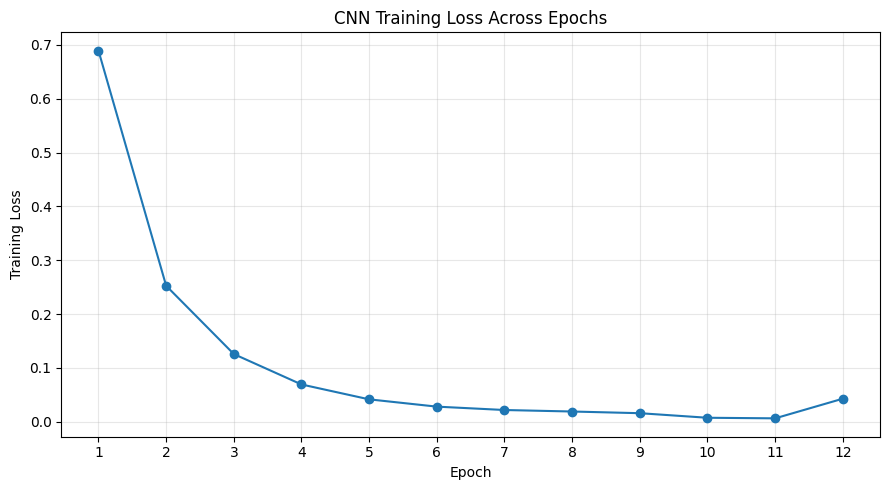

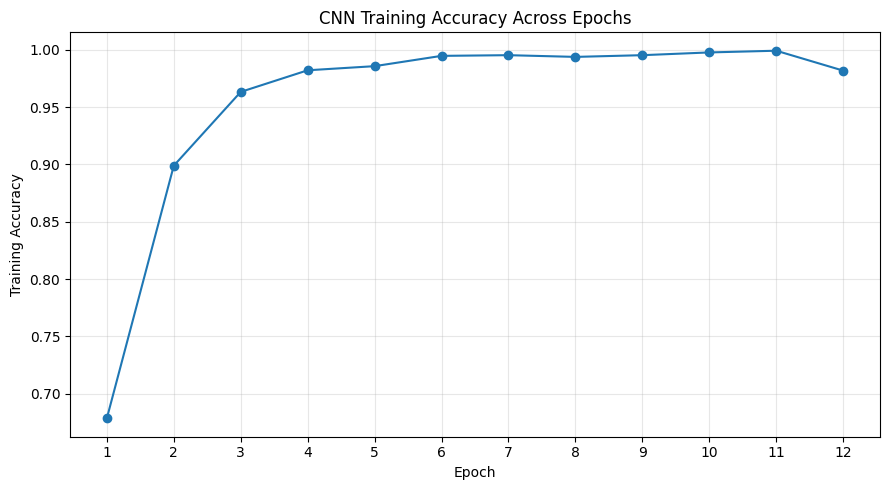

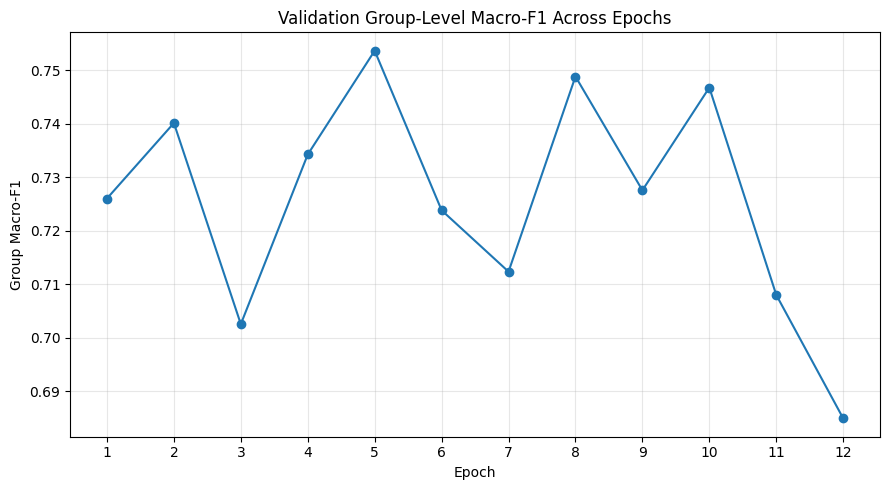

TRAINING GRAPHS GENERATED SUCCESSFULLY
training_accuracy.png
training_loss.png
validation_group_macro_f1.png

Graph directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/training_graphs

STEP 21 RESULT: PASS


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Define paths
CNN_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_CNN_Baseline"
)

HISTORY_DIR = CNN_OUTPUT_DIR / "training_history"
GRAPH_DIR = CNN_OUTPUT_DIR / "training_graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

history_path = HISTORY_DIR / "training_history.csv"

# Load saved training history
history_df = pd.read_csv(history_path)

print("Training history loaded successfully.")
print("Available columns:", history_df.columns.tolist())
display(history_df)

# Helper function to save graphs
def save_training_graph(column, title, ylabel, filename):
    plt.figure(figsize=(9, 5))
    plt.plot(
        history_df["epoch"],
        history_df[column],
        marker="o"
    )
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.xticks(history_df["epoch"])
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(GRAPH_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# Graph 1: Training loss
save_training_graph(
    "train_loss",
    "CNN Training Loss Across Epochs",
    "Training Loss",
    "training_loss.png"
)

# Graph 2: Training accuracy
save_training_graph(
    "train_accuracy",
    "CNN Training Accuracy Across Epochs",
    "Training Accuracy",
    "training_accuracy.png"
)

# Graph 3: Validation group macro-F1
save_training_graph(
    "val_group_macro_f1",
    "Validation Group-Level Macro-F1 Across Epochs",
    "Group Macro-F1",
    "validation_group_macro_f1.png"
)

print("=" * 60)
print("TRAINING GRAPHS GENERATED SUCCESSFULLY")
print("=" * 60)

for file in sorted(GRAPH_DIR.iterdir()):
    print(file.name)

print("\nGraph directory:", GRAPH_DIR)
print("\nSTEP 21 RESULT: PASS")


In [ ]:

from pathlib import Path

CNN_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_CNN_Baseline"
)

report = r"""
# CNN Baseline: FSHD Ultrasound Heckmatt Grade Classification

## 1. Experiment Overview

This experiment develops a CNN baseline for classifying
FSHD ultrasound images into four Heckmatt grades: G1, G2, G3 and G4.

The baseline uses ResNet18 with ImageNet-pretrained weights
and a modified grayscale input layer.

## 2. Dataset

Dataset: Dataset B - FSHD Ultrasound

Total labelled images: 4,727
Total labelled subject-muscle-side groups: 1,468
Total labelled subjects: 109

Unlabelled images were excluded from supervised classification.

### Subject-Level Data Split

| Partition | Subjects | Images | Groups |
|---|---:|---:|---:|
| Training | 76 | 3,342 | 1,029 |
| Validation | 17 | 741 | 231 |
| Testing | 16 | 644 | 208 |
| Total | 109 | 4,727 | 1,468 |

The subject-level split used iterative multilabel stratification
with random seed 42. Subject overlap between partitions was zero.

## 3. CNN Architecture

- Architecture: ResNet18
- Initial weights: ImageNet pretrained weights
- Input channels: 1 (grayscale)
- Output classes: 4
- Final classification layer: 512 input features to 4 outputs
- Input image size: 224 x 224 pixels

The original three-channel convolution weights were averaged
across the RGB input channels to initialize the grayscale
convolution layer.

## 4. Image Preprocessing

- Images converted to grayscale.
- Images resized to 224 x 224.
- Images converted to PyTorch tensors.
- Normalization applied using mean 0.485 and standard deviation 0.229.

## 5. Training Configuration

| Parameter | Configuration |
|---|---|
| Optimizer | AdamW |
| Learning rate | 0.0001 |
| Weight decay | 0.0001 |
| Batch size | 32 |
| Maximum epochs | 30 |
| Early stopping patience | 7 |
| Loss function | Weighted CrossEntropyLoss |
| Random seed | 42 |
| Hardware | NVIDIA Tesla T4 |

Class weights were calculated using training-set class frequencies.

## 6. Model Selection

The model was selected using validation group-level macro-F1.

Best epoch: 5

Best validation group macro-F1: 0.7536

Training stopped after epoch 12 because validation performance
did not improve for seven consecutive epochs.

The best checkpoint from epoch 5 was restored before final
test-set evaluation.

## 7. Evaluation Methodology

### Primary evaluation

Group-level evaluation was performed by grouping images using
subject ID, muscle code and side code.

Class probabilities from images belonging to the same group
were averaged to obtain one group-level prediction.

### Secondary evaluation

Image-level classification metrics were also calculated.

Metrics:
- Accuracy
- Macro-F1
- Balanced accuracy
- Per-class precision, recall and F1-score
- Confusion matrix

The test set was reserved for final evaluation after model selection.

## 8. Validation Results

| Metric | Result |
|---|---:|
| Image accuracy | 0.7706 |
| Image macro-F1 | 0.7082 |
| Group accuracy | 0.7922 |
| Group macro-F1 | 0.7536 |
| Group balanced accuracy | 0.7453 |

### Validation Per-Class Results

| Grade | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| G1 | 0.82 | 0.82 | 0.82 | 73 |
| G2 | 0.78 | 0.77 | 0.78 | 97 |
| G3 | 0.79 | 0.81 | 0.80 | 54 |
| G4 | 0.67 | 0.57 | 0.62 | 7 |

## 9. Final Test Results

| Metric | Result |
|---|---:|
| Image accuracy | 0.7236 |
| Image macro-F1 | 0.6868 |
| Group accuracy | 0.7260 |
| Group macro-F1 | 0.7024 |
| Group balanced accuracy | 0.7037 |

### Test Per-Class Results

| Grade | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| G1 | 0.83 | 0.69 | 0.75 | 71 |
| G2 | 0.58 | 0.62 | 0.60 | 58 |
| G3 | 0.78 | 0.87 | 0.82 | 68 |
| G4 | 0.64 | 0.64 | 0.64 | 11 |

### Test Confusion Matrix

Rows represent actual classes and columns represent predicted classes.

| Actual / Predicted | G1 | G2 | G3 | G4 |
|---|---:|---:|---:|---:|
| G1 | 49 | 21 | 1 | 0 |
| G2 | 10 | 36 | 12 | 0 |
| G3 | 0 | 5 | 59 | 4 |
| G4 | 0 | 0 | 4 | 7 |

## 10. Observations

1. The best validation group macro-F1 was 0.7536 at epoch 5.
2. Final test group macro-F1 was 0.7024.
3. G3 achieved the highest test F1-score of 0.82.
4. G2 had the lowest test F1-score of 0.60.
5. Training accuracy approached 99%, while validation performance
   fluctuated, indicating possible overfitting.
6. Group-level probability aggregation performed better than
   image-level classification in macro-F1 on both validation and
   test partitions.

## 11. Limitations

- The number of G4 groups is limited, particularly in validation.
- Performance differs across Heckmatt grades.
- The gap between training and validation performance suggests
  potential overfitting.
- Results are specific to this dataset and experimental setup.
- These results do not establish clinical diagnostic performance.

## 12. Conclusion

The ResNet18 CNN baseline achieved a test group-level macro-F1
of 0.7024 and group-level accuracy of 0.7260 for FSHD ultrasound
Heckmatt grade classification.

This experiment provides a reproducible deep-learning baseline
for subsequent research comparisons.

It represents the CNN baseline component and not the complete
proposed hybrid framework.
"""

report_path = CNN_OUTPUT_DIR / "CNN_Baseline_Methodology_and_Results.md"

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("=" * 65)
print("CNN BASELINE RESEARCH DOCUMENT CREATED")
print("=" * 65)
print("File:", report_path)
print("File size:", round(report_path.stat().st_size / 1024, 2), "KB")
print("\nSTEP 22 RESULT: PASS")


CNN BASELINE RESEARCH DOCUMENT CREATED
File: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/CNN_Baseline_Methodology_and_Results.md
File size: 4.99 KB

STEP 22 RESULT: PASS


In [ ]:

import torch
import torch.nn as nn
import pandas as pd
import numpy as np

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

# --------------------------------------------------
# 1. RESTORE PROJECT PATHS
# --------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

DATASET_ROOT = (
    PROJECT_ROOT
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
)

MANIFEST_PATH = (
    DATASET_ROOT / "Audit_Results"
    / "Dataset_B_Image_Mask_Manifest.csv"
)

SPLIT_PATH = (
    DATASET_ROOT / "Audit_Results"
    / "Dataset_B_Subject_Level_Split.csv"
)

CNN_OUTPUT_DIR = (
    PROJECT_ROOT
    / "05_Model_Development"
    / "Dataset_B_CNN_Baseline"
)

BEST_MODEL_PATH = (
    CNN_OUTPUT_DIR
    / "checkpoints"
    / "resnet18_best_model.pth"
)

# --------------------------------------------------
# 2. CHECK REQUIRED FILES
# --------------------------------------------------

required_paths = [
    MANIFEST_PATH,
    SPLIT_PATH,
    BEST_MODEL_PATH
]

for path in required_paths:
    print(
        f"{path.name}:",
        "FOUND" if path.exists() else "MISSING"
    )

assert all(path.exists() for path in required_paths), (
    "A required file is missing. Check the Google Drive paths."
)

# --------------------------------------------------
# 3. RESTORE DATAFRAMES
# --------------------------------------------------

manifest_df = pd.read_csv(MANIFEST_PATH)
split_df = pd.read_csv(SPLIT_PATH)

labelled_df = manifest_df[
    manifest_df["heckmatt_grade"].notna()
].copy()

labelled_df["subject_id"] = (
    labelled_df["subject_id"].astype(str)
)

split_df["subject_id"] = split_df["subject_id"].astype(str)

labelled_df = labelled_df.merge(
    split_df[["subject_id", "partition"]],
    on="subject_id",
    how="left",
    validate="many_to_one"
)

assert labelled_df["partition"].notna().all()
assert len(labelled_df) == 4727

test_df = labelled_df[
    labelled_df["partition"] == "test"
].copy()

test_df["label"] = (
    test_df["heckmatt_grade"].astype(int) - 1
)

test_df["group_id"] = (
    test_df["subject_id"].astype(str)
    + "_"
    + test_df["muscle_code"].astype(str)
    + "_"
    + test_df["side_code"].astype(str)
)

assert len(test_df) == 644
assert test_df["group_id"].nunique() == 208

print("\nTest images:", len(test_df))
print("Test groups:", test_df["group_id"].nunique())

# --------------------------------------------------
# 4. RESTORE IMAGE TRANSFORM
# --------------------------------------------------

IMAGE_SIZE = 224
BATCH_SIZE = 32
CLASS_NAMES = ["G1", "G2", "G3", "G4"]

cnn_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485], std=[0.229])
])

# --------------------------------------------------
# 5. RESTORE TEST DATASET
# --------------------------------------------------

class FSHDUltrasoundDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["image_path"]).convert("L")

        if self.transform:
            image = self.transform(image)

        return {
            "image": image,
            "label": torch.tensor(
                int(row["label"]),
                dtype=torch.long
            ),
            "subject_id": str(row["subject_id"]),
            "group_id": str(row["group_id"]),
            "filename": str(row["image_path"])
        }

test_dataset = FSHDUltrasoundDataset(
    test_df,
    transform=cnn_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------------
# 6. RESTORE RESNET18 ARCHITECTURE
# --------------------------------------------------

cnn_model = models.resnet18(weights=None)

old_conv = cnn_model.conv1

cnn_model.conv1 = nn.Conv2d(
    1,
    old_conv.out_channels,
    kernel_size=old_conv.kernel_size,
    stride=old_conv.stride,
    padding=old_conv.padding,
    bias=False
)

cnn_model.fc = nn.Linear(512, 4)

# --------------------------------------------------
# 7. LOAD BEST CHECKPOINT
# --------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

cnn_model.load_state_dict(
    checkpoint["model_state_dict"]
)

cnn_model = cnn_model.to(device)
cnn_model.eval()

# --------------------------------------------------
# 8. VERIFY RESTORATION
# --------------------------------------------------

print("\n" + "=" * 60)
print("CNN MODEL AND TEST DATA RESTORED")
print("=" * 60)

print("Checkpoint epoch:", checkpoint["epoch"])
print(
    "Best validation group macro-F1:",
    round(checkpoint["best_val_group_macro_f1"], 4)
)
print("Model device:", next(cnn_model.parameters()).device)
print("Test dataset:", len(test_dataset))
print("Test batches:", len(test_loader))
print("Test groups:", test_df["group_id"].nunique())

assert checkpoint["epoch"] == 5
assert len(test_dataset) == 644

print("\nSTEP 24 RESULT: PASS")


Dataset_B_Image_Mask_Manifest.csv: FOUND
Dataset_B_Subject_Level_Split.csv: FOUND
resnet18_best_model.pth: FOUND

Test images: 644
Test groups: 208

CNN MODEL AND TEST DATA RESTORED
Checkpoint epoch: 5
Best validation group macro-F1: 0.7536
Model device: cuda:0
Test dataset: 644
Test batches: 21
Test groups: 208

STEP 24 RESULT: PASS


In [ ]:

import torch
import pandas as pd
import numpy as np

# Ensure evaluation mode
cnn_model.eval()

all_filenames = []
all_subject_ids = []
all_group_ids = []
all_true_labels = []
all_predicted_labels = []
all_probabilities = []

with torch.no_grad():

    for batch in test_loader:

        images = batch["image"].to(
            device,
            non_blocking=True
        )

        labels = batch["label"].to(device)

        outputs = cnn_model(images)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_filenames.extend(batch["filename"])
        all_subject_ids.extend(batch["subject_id"])
        all_group_ids.extend(batch["group_id"])

        all_true_labels.extend(
            labels.cpu().numpy().tolist()
        )

        all_predicted_labels.extend(
            predictions.cpu().numpy().tolist()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy().tolist()
        )

# Create image-level prediction DataFrame
image_predictions_df = pd.DataFrame({
    "filename": all_filenames,
    "subject_id": all_subject_ids,
    "group_id": all_group_ids,
    "true_label": all_true_labels,
    "predicted_label": all_predicted_labels,
    "true_grade": [
        CLASS_NAMES[i] for i in all_true_labels
    ],
    "predicted_grade": [
        CLASS_NAMES[i] for i in all_predicted_labels
    ]
})

# Add individual class probabilities
probability_array = np.array(all_probabilities)

for i, class_name in enumerate(CLASS_NAMES):
    image_predictions_df[
        f"{class_name}_probability"
    ] = probability_array[:, i]

# Save CSV
EVALUATION_DIR = CNN_OUTPUT_DIR / "evaluation_results"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_PREDICTIONS_PATH = (
    EVALUATION_DIR / "test_image_predictions.csv"
)

image_predictions_df.to_csv(
    IMAGE_PREDICTIONS_PATH,
    index=False
)

# Verification
assert len(image_predictions_df) == 644
assert image_predictions_df["group_id"].nunique() == 208
assert image_predictions_df["filename"].is_unique

print("=" * 65)
print("IMAGE-LEVEL TEST PREDICTIONS GENERATED")
print("=" * 65)

print("Total predictions:", len(image_predictions_df))
print("Unique subjects:", image_predictions_df["subject_id"].nunique())
print("Unique groups:", image_predictions_df["group_id"].nunique())

print("\nPrediction distribution:")
print(
    image_predictions_df["predicted_grade"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

print("\nSaved file:")
print(IMAGE_PREDICTIONS_PATH)

print("\nSample predictions:")
display(image_predictions_df.head())

print("\nSTEP 25 RESULT: PASS")


IMAGE-LEVEL TEST PREDICTIONS GENERATED
Total predictions: 644
Unique subjects: 16
Unique groups: 208

Prediction distribution:
predicted_grade
G1    185
G2    201
G3    227
G4     31
Name: count, dtype: int64

Saved file:
/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_CNN_Baseline/evaluation_results/test_image_predictions.csv

Sample predictions:


,filename,subject_id,group_id,true_label,predicted_label,true_grade,predicted_grade,G1_probability,G2_probability,G3_probability,G4_probability
0,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,13,13_1_0,2,2,G3,G3,0.000123,0.027425,0.968522,0.003930
1,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,13,13_1_0,2,2,G3,G3,0.000226,0.081437,0.916585,0.001751
2,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,13,13_1_0,2,1,G3,G2,0.000005,0.776594,0.223384,0.000018
3,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,13,13_1_1,2,2,G3,G3,0.000044,0.336974,0.660291,0.002690
4,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,13,13_1_1,2,2,G3,G3,0.008183,0.017485,0.943248,0.031084



STEP 25 RESULT: PASS


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Recalculate metrics from saved image-level predictions
y_true = image_predictions_df["true_label"]
y_pred = image_predictions_df["predicted_label"]

image_accuracy_verified = accuracy_score(y_true, y_pred)
image_macro_f1_verified = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)
image_balanced_accuracy_verified = balanced_accuracy_score(
    y_true, y_pred
)

print("=" * 65)
print("INDEPENDENT IMAGE-LEVEL METRIC VERIFICATION")
print("=" * 65)

print("Image accuracy:", round(image_accuracy_verified, 6))
print("Image macro-F1:", round(image_macro_f1_verified, 6))
print(
    "Image balanced accuracy:",
    round(image_balanced_accuracy_verified, 6)
)

print("\nCLASSIFICATION REPORT:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

print("\nCONFUSION MATRIX:")
print(
    confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3]
    )
)

# Compare with original recorded image-level test metrics
original_accuracy = 0.723602
original_macro_f1 = 0.686826

print("\nORIGINAL VS VERIFIED")

print(
    "Accuracy matches:",
    np.isclose(image_accuracy_verified, original_accuracy, atol=0.00001)
)

print(
    "Macro-F1 matches:",
    np.isclose(image_macro_f1_verified, original_macro_f1, atol=0.00001)
)

print("\nSTEP 26 RESULT: VERIFICATION COMPLETED")


INDEPENDENT IMAGE-LEVEL METRIC VERIFICATION
Image accuracy: 0.723602
Image macro-F1: 0.686826
Image balanced accuracy: 0.683677

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

          G1       0.84      0.71      0.77       219
          G2       0.59      0.65      0.62       182
          G3       0.77      0.83      0.80       210
          G4       0.58      0.55      0.56        33

    accuracy                           0.72       644
   macro avg       0.69      0.68      0.69       644
weighted avg       0.73      0.72      0.73       644


CONFUSION MATRIX:
[[156  60   3   0]
 [ 28 118  36   0]
 [  1  22 174  13]
 [  0   1  14  18]]

ORIGINAL VS VERIFIED
Accuracy matches: True
Macro-F1 matches: True

STEP 26 RESULT: VERIFICATION COMPLETED


In [ ]:

# STEP 27: Save independently verified image-level results

from sklearn.metrics import classification_report, confusion_matrix
import json

EVALUATION_DIR = CNN_OUTPUT_DIR / "evaluation_results"

# 1. Save image-level confusion matrix
image_cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

pd.DataFrame(
    image_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    EVALUATION_DIR / "test_image_confusion_matrix.csv"
)

# 2. Save image-level classification report
image_report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=CLASS_NAMES,
    zero_division=0,
    output_dict=True
)

with open(
    EVALUATION_DIR / "test_image_classification_report.json",
    "w"
) as f:
    json.dump(image_report, f, indent=4)

# 3. Save independently verified metrics
verified_metrics = {
    "evaluation_level": "Image-level",
    "dataset": "Dataset B - FSHD Ultrasound",
    "partition": "Test",
    "number_of_images": int(len(y_true)),
    "number_of_subjects": int(image_predictions_df["subject_id"].nunique()),
    "number_of_groups": int(image_predictions_df["group_id"].nunique()),
    "accuracy": float(image_accuracy_verified),
    "macro_f1": float(image_macro_f1_verified),
    "balanced_accuracy": float(image_balanced_accuracy_verified),
    "verification_status": "Matched original recorded accuracy and macro-F1"
}

with open(
    EVALUATION_DIR / "test_image_verified_metrics.json",
    "w"
) as f:
    json.dump(verified_metrics, f, indent=4)

print("=" * 65)
print("IMAGE-LEVEL VERIFICATION FILES SAVED")
print("=" * 65)

for filename in [
    "test_image_predictions.csv",
    "test_image_confusion_matrix.csv",
    "test_image_classification_report.json",
    "test_image_verified_metrics.json"
]:
    path = EVALUATION_DIR / filename
    print(filename, ":", "SAVED" if path.exists() else "MISSING")

print("\nSTEP 27 RESULT: PASS")


IMAGE-LEVEL VERIFICATION FILES SAVED
test_image_predictions.csv : SAVED
test_image_confusion_matrix.csv : SAVED
test_image_classification_report.json : SAVED
test_image_verified_metrics.json : SAVED

STEP 27 RESULT: PASS


In [ ]:

from pathlib import Path

RAD_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

print("=" * 65)
print("RADIOMICS DIRECTORY FILE INSPECTION")
print("=" * 65)

print("\nDirectory exists:", RAD_DIR.exists())

print("\nAll CSV files found:")

for path in sorted(RAD_DIR.rglob("*.csv")):
    print(
        f"\nFilename: {path.name}"
        f"\nFull path: {path}"
        f"\nSize: {path.stat().st_size / (1024 * 1024):.2f} MB"
    )

print("\n" + "=" * 65)
print("FEATURE FILE CANDIDATES")
print("=" * 65)

for path in sorted(RAD_DIR.rglob("*")):
    if path.is_file() and "feature" in path.name.lower():
        print(path)


RADIOMICS DIRECTORY FILE INSPECTION

Directory exists: True

All CSV files found:

Filename: Dataset_B_Radiomics_Extraction_Errors.csv
Full path: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Extraction_Errors.csv
Size: 0.00 MB

Filename: Dataset_B_Radiomics_Training_Features.csv
Full path: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Training_Features.csv
Size: 5.91 MB

Filename: Dataset_B_Radiomics_Training_Manifest.csv
Full path: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Training_Manifest.csv
Size: 1.52 MB

FEATURE FILE CANDIDATES
/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Training_Features.csv


In [ ]:

from pathlib import Path
import pandas as pd

RAD_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics (2)"
)

assert RAD_DIR.exists(), f"Folder not found: {RAD_DIR}"

files = sorted(
    p for p in RAD_DIR.rglob("*") if p.is_file()
)

inventory_df = pd.DataFrame([
    {
        "file": str(p.relative_to(RAD_DIR)),
        "extension": p.suffix.lower(),
        "size_kb": round(p.stat().st_size / 1024, 2)
    }
    for p in files
])

print("=" * 70)
print("RADIOMICS COMPLETE FILE INVENTORY")
print("=" * 70)

display(inventory_df)

print("\nTotal files:", len(files))
print(
    "Total size (MB):",
    round(sum(p.stat().st_size for p in files) / (1024 * 1024), 2)
)

print("\nFEATURE FILE CHECK")

expected_files = [
    "Dataset_B_Radiomics_Training_Features.csv",
    "Dataset_B_Radiomics_Validation_Features.csv",
    "Dataset_B_Radiomics_Test_Features.csv"
]

for filename in expected_files:
    path = RAD_DIR / filename
    print(filename, "FOUND" if path.exists() else "MISSING")

print("\nSTEP 29C RESULT: INVENTORY COMPLETED")


RADIOMICS COMPLETE FILE INVENTORY


,file,extension,size_kb
0,Dataset_B_Radiomics_Experiment_Config (1).json,.json,0.82
1,Dataset_B_Radiomics_Experiment_Config.json,.json,0.61
2,Dataset_B_Radiomics_Extraction (1).py,.py,3.17
3,Dataset_B_Radiomics_Extraction.py,.py,2.28
4,Dataset_B_Radiomics_Split_Documentation.json,.json,0.90
5,Dataset_B_Radiomics_Subject_Level_Split.csv,.csv,1.21
6,Dataset_B_Radiomics_Test_Features.csv,.csv,1167.21
7,Dataset_B_Radiomics_Training_Features.csv,.csv,6049.51
8,Dataset_B_Radiomics_Training_Manifest.csv,.csv,1529.88
9,Dataset_B_Radiomics_Validation_Errors.csv,.csv,0.00



Total files: 26
Total size (MB): 14.61

FEATURE FILE CHECK
Dataset_B_Radiomics_Training_Features.csv FOUND
Dataset_B_Radiomics_Validation_Features.csv FOUND
Dataset_B_Radiomics_Test_Features.csv FOUND

STEP 29C RESULT: INVENTORY COMPLETED


In [ ]:

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

AUDIT_ROOT = PROJECT_ROOT / "02_Dataset_Audit"

print("=" * 70)
print("DATASET AUDIT FOLDER INVESTIGATION")
print("=" * 70)

print("Project exists:", PROJECT_ROOT.exists())
print("02_Dataset_Audit exists:", AUDIT_ROOT.exists())

if AUDIT_ROOT.exists():

    print("\nContents of 02_Dataset_Audit:")

    for item in sorted(AUDIT_ROOT.iterdir()):
        print(
            "[DIR] " if item.is_dir() else "[FILE]",
            item.name
        )

    print("\nSearching all subfolders for Audit_Results:")

    for item in AUDIT_ROOT.rglob("*"):
        if item.is_dir() and item.name == "Audit_Results":
            print("\nFOUND:", item)

            print("Files inside:")
            for file in sorted(item.iterdir()):
                print(
                    " -", file.name,
                    f"({file.stat().st_size:,} bytes)"
                    if file.is_file() else "(folder)"
                )

else:
    print("\n02_Dataset_Audit itself was not found.")

print("\nSTEP 30C RESULT: INVESTIGATION COMPLETED")


DATASET AUDIT FOLDER INVESTIGATION
Project exists: True
02_Dataset_Audit exists: True

Contents of 02_Dataset_Audit:
[DIR]  Dataset_A_MRI
[DIR]  Dataset_B_FSHD_Ultrasound

Searching all subfolders for Audit_Results:

FOUND: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_A_MRI/Audit_Results
Files inside:
 - Dataset_A_All_Archive_Image_Counts.csv (2,521 bytes)
 - Dataset_A_Final_Audit_Summary.csv (1,304 bytes)
 - Dataset_A_Image_Quality_Audit.csv (4,118 bytes)
 - Dataset_A_Initial_Audit_Report.txt (6,424 bytes)
 - Dataset_A_Preliminary_Archive_Summary.csv (370 bytes)
 - Dataset_A_Source_Record.csv (892 bytes)
 - Dermatomyositis_Exact_Duplicates.csv (461 bytes)

FOUND: /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results
Files inside:
 - Dataset_B_Experimental_Design_Protocol.md (2,753 bytes)
 - Dataset_B_Final_Audit_Report.txt (18,911 bytes)
 - Dataset_B_Full_Mask_Quality.csv (2,131,463 bytes)
 - Dataset_B_

In [ ]:

import pandas as pd
from pathlib import Path

AUDIT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results"
)

MANIFEST_PATH = AUDIT_DIR / "Dataset_B_Image_Mask_Manifest.csv"
SPLIT_PATH = AUDIT_DIR / "Dataset_B_Subject_Level_Split.csv"

assert MANIFEST_PATH.is_file(), "Manifest is not accessible"
assert SPLIT_PATH.is_file(), "Subject split is not accessible"

manifest = pd.read_csv(MANIFEST_PATH)
split = pd.read_csv(SPLIT_PATH)

print("=" * 65)
print("CANONICAL DATASET FILES LOADED")
print("=" * 65)

print("\nManifest:")
print("Rows:", len(manifest))
print("Columns:", len(manifest.columns))
print("Available columns:", manifest.columns.tolist())

print("\nSubject-level split:")
print("Rows:", len(split))
print("Columns:", len(split.columns))
print("Available columns:", split.columns.tolist())

print("\nSplit distribution:")
print(split["partition"].value_counts().to_string())

print("\nManifest sample:")
display(manifest.head(3))

print("\nSplit sample:")
display(split.head(3))

print("\nSTEP 30D RESULT: FILES LOADED SUCCESSFULLY")


CANONICAL DATASET FILES LOADED

Manifest:
Rows: 25005
Columns: 11
Available columns: ['filename', 'image_path', 'mask_path', 'mask_exists', 'subject_id', 'muscle_code', 'side_code', 'side', 'image_index', 'heckmatt_grade', 'metadata_available']

Subject-level split:
Rows: 109
Columns: 2
Available columns: ['subject_id', 'partition']

Split distribution:
partition
train         76
validation    17
test          16

Manifest sample:


,filename,image_path,mask_path,mask_exists,subject_id,muscle_code,side_code,side,image_index,heckmatt_grade,metadata_available
0,00006_001_00_1.png,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,True,6,1,0,left,1,3.0,True
1,00006_001_00_2.png,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,True,6,1,0,left,2,3.0,True
2,00006_001_00_3.png,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,/content/drive/MyDrive/Muscular_Dystrophy_Proj...,True,6,1,0,left,3,3.0,True



Split sample:


,subject_id,partition
0,6,train
1,13,test
2,19,test



STEP 30D RESULT: FILES LOADED SUCCESSFULLY


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

# --------------------------------------------------
# 1. PATHS
# --------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

RAD_DIR = (
    PROJECT_ROOT / "05_Model_Development"
    / "Dataset_B_Radiomics"
)

AUDIT_DIR = (
    PROJECT_ROOT / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Audit_Results"
)

MANIFEST_PATH = AUDIT_DIR / "Dataset_B_Image_Mask_Manifest.csv"
SPLIT_PATH = AUDIT_DIR / "Dataset_B_Subject_Level_Split.csv"

FEATURE_FILES = {
    "train": RAD_DIR / "Dataset_B_Radiomics_Training_Features.csv",
    "validation": RAD_DIR / "Dataset_B_Radiomics_Validation_Features.csv",
    "test": RAD_DIR / "Dataset_B_Radiomics_Test_Features.csv"
}

EXPECTED = {
    "train": {"records": 3342, "groups": 1029, "subjects": 76},
    "validation": {"records": 741, "groups": 231, "subjects": 17},
    "test": {"records": 644, "groups": 208, "subjects": 16}
}

# --------------------------------------------------
# 2. LOAD CANONICAL DATA
# --------------------------------------------------

manifest = pd.read_csv(MANIFEST_PATH)
split = pd.read_csv(SPLIT_PATH)

manifest["subject_id"] = manifest["subject_id"].astype(str)
split["subject_id"] = split["subject_id"].astype(str)

canonical = manifest[
    manifest["heckmatt_grade"].notna()
].copy()

canonical = canonical.merge(
    split,
    on="subject_id",
    how="left",
    validate="many_to_one"
)

canonical["group_id"] = (
    canonical["subject_id"]
    + "_"
    + canonical["muscle_code"].astype(str)
    + "_"
    + canonical["side_code"].astype(str)
)

assert canonical["partition"].notna().all()

print("Canonical labelled records:", len(canonical))
print("Canonical groups:", canonical["group_id"].nunique())

# --------------------------------------------------
# 3. AUDIT EACH PARTITION
# --------------------------------------------------

results = []
feature_columns_by_partition = {}

for partition, path in FEATURE_FILES.items():

    print("\n" + "=" * 65)
    print(partition.upper(), "RADIOMICS AUDIT")
    print("=" * 65)

    assert path.is_file(), f"Missing feature file: {path}"

    df = pd.read_csv(path)

    required = [
        "filename", "subject_id", "muscle_code",
        "side_code", "group_id", "heckmatt_grade"
    ]

    missing_columns = [
        c for c in required if c not in df.columns
    ]

    assert not missing_columns, (
        f"Missing required columns: {missing_columns}"
    )

    df["subject_id"] = df["subject_id"].astype(str)
    df["group_id"] = df["group_id"].astype(str)

    expected_df = canonical[
        canonical["partition"] == partition
    ].copy()

    # Exact filename matching
    expected_files = set(expected_df["filename"].astype(str))
    actual_files = set(df["filename"].astype(str))

    missing_files = expected_files - actual_files
    extra_files = actual_files - expected_files

    # Subject and group matching
    expected_subjects = set(expected_df["subject_id"])
    actual_subjects = set(df["subject_id"])

    expected_groups = set(expected_df["group_id"].astype(str))
    actual_groups = set(df["group_id"])

    # Check subject-to-partition consistency
    wrong_partition_subjects = set(
        df.loc[
            ~df["subject_id"].isin(
                split.loc[
                    split["partition"] == partition,
                    "subject_id"
                ],
            ),
            "subject_id"
        ]
    )

    # Compare filename-level labels and identifiers
    comparison = df.merge(
        expected_df[
            ["filename", "subject_id", "group_id", "heckmatt_grade"]
        ],
        on="filename",
        how="inner",
        suffixes=("_actual", "_expected"),
        validate="one_to_one"
    )

    subject_mismatches = int(
        (
            comparison["subject_id_actual"]
            != comparison["subject_id_expected"]
        ).sum()
    )

    group_mismatches = int(
        (
            comparison["group_id_actual"]
            != comparison["group_id_expected"]
        ).sum()
    )

    label_mismatches = int(
        (
            pd.to_numeric(comparison["heckmatt_grade_actual"])
            != pd.to_numeric(comparison["heckmatt_grade_expected"])
        ).sum()
    )

    # Feature columns
    metadata_columns = [
        "filename", "subject_id", "muscle_code",
        "side_code", "side", "group_id",
        "heckmatt_grade", "partition"
    ]

    feature_columns = [
        c for c in df.columns if c not in metadata_columns
    ]

    feature_columns_by_partition[partition] = set(feature_columns)

    numeric_features = df[feature_columns].select_dtypes(
        include=[np.number]
    )

    nan_count = int(numeric_features.isna().sum().sum())

    inf_count = int(
        np.isinf(numeric_features.to_numpy()).sum()
    )

    groups_with_multiple_labels = int(
        (df.groupby("group_id")["heckmatt_grade"].nunique() > 1).sum()
    )

    result = {
        "partition": partition,
        "records": len(df),
        "groups": len(actual_groups),
        "subjects": len(actual_subjects),
        "radiomics_features": len(feature_columns),
        "numeric_features": len(numeric_features.columns),
        "missing_files": len(missing_files),
        "extra_files": len(extra_files),
        "subject_mismatches": subject_mismatches,
        "group_mismatches": group_mismatches,
        "label_mismatches": label_mismatches,
        "wrong_partition_subjects": len(wrong_partition_subjects),
        "duplicate_filenames": int(df["filename"].duplicated().sum()),
        "groups_with_multiple_labels": groups_with_multiple_labels,
        "NaN_values": nan_count,
        "infinite_values": inf_count
    }

    results.append(result)

    print(pd.Series(result).to_string())

    print(
        "\nExpected records/groups/subjects:",
        EXPECTED[partition]["records"],
        EXPECTED[partition]["groups"],
        EXPECTED[partition]["subjects"]
    )

# --------------------------------------------------
# 4. FEATURE COLUMN CONSISTENCY
# --------------------------------------------------

print("\n" + "=" * 65)
print("FEATURE COLUMN CONSISTENCY")
print("=" * 65)

reference_features = feature_columns_by_partition["train"]

for partition, columns in feature_columns_by_partition.items():
    print(
        partition,
        "| Feature count:", len(columns),
        "| Same as training:", columns == reference_features
    )

# --------------------------------------------------
# 5. FINAL SUMMARY
# --------------------------------------------------

results_df = pd.DataFrame(results).set_index("partition")

print("\n" + "=" * 65)
print("RADIOMICS PARTITION AUDIT SUMMARY")
print("=" * 65)

display(results_df)

print("\nSTEP 31 RESULT: AUDIT COMPLETED")
print("Review all counts and mismatch fields before approval.")


Canonical labelled records: 4727
Canonical groups: 1468

TRAIN RADIOMICS AUDIT
partition                      train
records                         3342
groups                          1029
subjects                          76
radiomics_features               102
numeric_features                 102
missing_files                      0
extra_files                        0
subject_mismatches                 0
group_mismatches                   0
label_mismatches                   0
wrong_partition_subjects           0
duplicate_filenames                0
groups_with_multiple_labels        0
NaN_values                         0
infinite_values                    0

Expected records/groups/subjects: 3342 1029 76

VALIDATION RADIOMICS AUDIT
partition                      validation
records                               741
groups                                231
subjects                               17
radiomics_features                    102
numeric_features                      102
m

,records,groups,subjects,radiomics_features,numeric_features,missing_files,extra_files,subject_mismatches,group_mismatches,label_mismatches,wrong_partition_subjects,duplicate_filenames,groups_with_multiple_labels,NaN_values,infinite_values
partition,,,,,,,,,,,,,,,
train,3342,1029,76,102,102,0,0,0,0,0,0,0,0,0,0
validation,741,231,17,102,102,0,0,0,0,0,0,0,0,0,0
test,644,208,16,102,102,0,0,0,0,0,0,0,0,0,0



STEP 31 RESULT: AUDIT COMPLETED
Review all counts and mismatch fields before approval.


In [ ]:
import os

RAD_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

print("Folder exists:", os.path.exists(RAD_DIR))

if os.path.exists(RAD_DIR):
    files = sorted(os.listdir(RAD_DIR))

    print("\nTotal items:", len(files))
    print("\nFolder contents:")

    for name in files:
        path = os.path.join(RAD_DIR, name)

        if os.path.isdir(path):
            print(f"[FOLDER] {name}")
        else:
            print(f"[FILE]   {name} ({os.path.getsize(path):,} bytes)")
else:
    print("Folder not found. Check the Google Drive mount and path.")


Folder exists: True

Total items: 13

Folder contents:
[FILE]   Dataset_B_Radiomics_Experiment_Config (1).json (841 bytes)
[FILE]   Dataset_B_Radiomics_Experiment_Config.json (625 bytes)
[FILE]   Dataset_B_Radiomics_Extraction (1).py (3,248 bytes)
[FILE]   Dataset_B_Radiomics_Extraction.py (2,339 bytes)
[FILE]   Dataset_B_Radiomics_Split_Documentation.json (918 bytes)
[FILE]   Dataset_B_Radiomics_Subject_Level_Split.csv (1,237 bytes)
[FILE]   Dataset_B_Radiomics_Test_Features.csv (1,195,224 bytes)
[FILE]   Dataset_B_Radiomics_Training_Features.csv (6,194,702 bytes)
[FILE]   Dataset_B_Radiomics_Training_Manifest.csv (1,566,592 bytes)
[FILE]   Dataset_B_Radiomics_Validation_Errors.csv (1 bytes)
[FILE]   Dataset_B_Radiomics_Validation_Features.csv (1,379,252 bytes)
[FILE]   Radiomics_10_Subject_Pilot.csv (21,921 bytes)
[FOLDER] XGBoost


In [ ]:
import os
import hashlib
import difflib

files_to_compare = [
    (
        "Dataset_B_Radiomics_Extraction.py",
        "Dataset_B_Radiomics_Extraction (1).py"
    ),
    (
        "Dataset_B_Radiomics_Experiment_Config.json",
        "Dataset_B_Radiomics_Experiment_Config (1).json"
    )
]

def get_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

for original, duplicate in files_to_compare:
    path1 = os.path.join(RAD_DIR, original)
    path2 = os.path.join(RAD_DIR, duplicate)

    print("\n" + "=" * 70)
    print("COMPARISON:", original, "vs", duplicate)

    if not os.path.exists(path1) or not os.path.exists(path2):
        print("One or both files are missing.")
        continue

    print("Original size:", os.path.getsize(path1), "bytes")
    print("Duplicate size:", os.path.getsize(path2), "bytes")

    hash1 = get_hash(path1)
    hash2 = get_hash(path2)

    print("Identical content:", hash1 == hash2)

    if hash1 != hash2:
        with open(path1, "r", encoding="utf-8") as f:
            content1 = f.readlines()

        with open(path2, "r", encoding="utf-8") as f:
            content2 = f.readlines()

        print("\nDifferences:")
        diff = difflib.unified_diff(
            content1,
            content2,
            fromfile=original,
            tofile=duplicate
        )

        print("".join(diff))


COMPARISON: Dataset_B_Radiomics_Extraction.py vs Dataset_B_Radiomics_Extraction (1).py
Original size: 2339 bytes
Duplicate size: 3248 bytes
Identical content: False

Differences:
--- Dataset_B_Radiomics_Extraction.py
+++ Dataset_B_Radiomics_Extraction (1).py
@@ -1,81 +1,124 @@
 
 import pandas as pd
+import numpy as np
 import SimpleITK as sitk
+from pathlib import Path
 from radiomics import featureextractor
-from pathlib import Path
-import argparse
 
-def create_extractor():
-    settings = {
-        "binWidth": 25,
-        "label": 1,
-        "normalize": False,
-        "resampledPixelSpacing": None
-    }
+BASE = Path("/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development")
 
-    extractor = featureextractor.RadiomicsFeatureExtractor(**settings)
-    extractor.disableAllFeatures()
+MANIFEST = BASE / "Dataset_B_Radiomics_Training_Manifest.csv"
+OUTPUT = BASE / "Dataset_B_Radiomics_Full_Training_Features.csv"
+ERRORS = BASE / "Dataset_B_Radiomics_Extraction_Er

In [ ]:
import os
import json
import pandas as pd

# 1. Inspect both experiment configurations
config_files = [
    "Dataset_B_Radiomics_Experiment_Config.json",
    "Dataset_B_Radiomics_Experiment_Config (1).json"
]

for filename in config_files:
    path = os.path.join(RAD_DIR, filename)

    print("\n" + "=" * 60)
    print("CONFIG:", filename)

    with open(path, "r") as f:
        config = json.load(f)

    print(json.dumps(config, indent=2))


# 2. Inspect all three existing feature CSVs
feature_files = [
    "Dataset_B_Radiomics_Training_Features.csv",
    "Dataset_B_Radiomics_Validation_Features.csv",
    "Dataset_B_Radiomics_Test_Features.csv"
]

for filename in feature_files:
    path = os.path.join(RAD_DIR, filename)
    df = pd.read_csv(path)

    print("\n" + "=" * 60)
    print("FEATURE FILE:", filename)
    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())

    print("\nFirst 2 rows:")
    print(df.head(2).to_string(index=False))

    print("\nMissing values:", df.isna().sum().sum())
    print("Duplicate filenames:", df["filename"].duplicated().sum())


CONFIG: Dataset_B_Radiomics_Experiment_Config.json
{
  "dataset": "Dataset B - FSHD Ultrasound",
  "task": "Heckmatt grade classification",
  "image_count": 3342,
  "subjects": 76,
  "partition": "train",
  "label_column": "heckmatt_grade",
  "identifiers": [
    "subject_id",
    "muscle_code",
    "side_code",
    "group_id",
    "filename"
  ],
  "settings": {
    "binWidth": 25,
    "label": 1,
    "normalize": false,
    "resampledPixelSpacing": null
  },
  "feature_classes": [
    "firstorder",
    "glcm",
    "glrlm",
    "glszm",
    "gldm",
    "ngtdm",
    "shape2D"
  ]
}

CONFIG: Dataset_B_Radiomics_Experiment_Config (1).json
{
  "dataset": "Dataset B - FSHD Ultrasound",
  "task": "Heckmatt grade classification",
  "image_count": 3342,
  "subjects": 76,
  "groups": 1029,
  "partition": "train",
  "label_column": "heckmatt_grade",
  "identifiers": [
    "subject_id",
    "muscle_code",
    "side_code",
    "group_id",
    "filename"
  ],
  "radiomics_settings": {
    "binWid

In [ ]:
import os
import pandas as pd

AUDIT_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results"
)

manifest_path = os.path.join(
    AUDIT_DIR, "Dataset_B_Image_Mask_Manifest.csv"
)

split_path = os.path.join(
    AUDIT_DIR, "Dataset_B_Subject_Level_Split.csv"
)

manifest = pd.read_csv(manifest_path)
split = pd.read_csv(split_path)

# Reconstruct canonical labelled records
canonical = manifest[
    manifest["heckmatt_grade"].notna()
].copy()

canonical["group_id"] = (
    canonical["subject_id"].astype(str) + "_" +
    canonical["muscle_code"].astype(str) + "_" +
    canonical["side_code"].astype(str)
)

canonical = canonical.merge(
    split,
    on="subject_id",
    how="left",
    validate="many_to_one"
)

feature_files = {
    "train": "Dataset_B_Radiomics_Training_Features.csv",
    "validation": "Dataset_B_Radiomics_Validation_Features.csv",
    "test": "Dataset_B_Radiomics_Test_Features.csv"
}

checks = [
    "subject_id",
    "muscle_code",
    "side_code",
    "group_id",
    "heckmatt_grade",
    "partition"
]

print("CANONICAL LABELLED RECORDS:", len(canonical))
print("\nEXPECTED SPLIT COUNTS:")
print(canonical["partition"].value_counts())

all_passed = True

for partition, filename in feature_files.items():

    print("\n" + "=" * 65)
    print("CHECKING:", partition.upper())

    features = pd.read_csv(os.path.join(RAD_DIR, filename))

    expected = canonical[
        canonical["partition"] == partition
    ].copy()

    merged = features.merge(
        expected[["filename"] + checks],
        on="filename",
        how="outer",
        suffixes=("_actual", "_expected"),
        indicator=True,
        validate="one_to_one"
    )

    missing = (merged["_merge"] == "right_only").sum()
    extra = (merged["_merge"] == "left_only").sum()

    print("Feature records:", len(features))
    print("Expected records:", len(expected))
    print("Missing filenames:", missing)
    print("Unexpected filenames:", extra)

    mismatch_counts = {}

    for col in checks:
        actual = merged[f"{col}_actual"]
        expected_col = merged[f"{col}_expected"]

        mismatch = (
            merged["_merge"].eq("both") &
            actual.astype(str).ne(expected_col.astype(str))
        )

        mismatch_counts[col] = int(mismatch.sum())

    print("Metadata mismatches:", mismatch_counts)

    passed = (
        missing == 0 and
        extra == 0 and
        all(v == 0 for v in mismatch_counts.values())
    )

    print("RESULT:", "PASS" if passed else "FAIL")

    all_passed = all_passed and passed

print("\n" + "=" * 65)
print("OVERALL RESULT:", "PASS" if all_passed else "FAIL")

CANONICAL LABELLED RECORDS: 4727

EXPECTED SPLIT COUNTS:
partition
train         3342
validation     741
test           644
Name: count, dtype: int64

CHECKING: TRAIN
Feature records: 3342
Expected records: 3342
Missing filenames: 0
Unexpected filenames: 0
Metadata mismatches: {'subject_id': 0, 'muscle_code': 0, 'side_code': 0, 'group_id': 0, 'heckmatt_grade': 0, 'partition': 0}
RESULT: PASS

CHECKING: VALIDATION
Feature records: 741
Expected records: 741
Missing filenames: 0
Unexpected filenames: 0
Metadata mismatches: {'subject_id': 0, 'muscle_code': 0, 'side_code': 0, 'group_id': 0, 'heckmatt_grade': 0, 'partition': 0}
RESULT: PASS

CHECKING: TEST
Feature records: 644
Expected records: 644
Missing filenames: 0
Unexpected filenames: 0
Metadata mismatches: {'subject_id': 0, 'muscle_code': 0, 'side_code': 0, 'group_id': 0, 'heckmatt_grade': 0, 'partition': 0}
RESULT: PASS

OVERALL RESULT: PASS


In [ ]:
import os

XGB_DIR = os.path.join(RAD_DIR, "XGBoost")

print("XGBoost folder exists:", os.path.exists(XGB_DIR))

for root, dirs, files in os.walk(XGB_DIR):
    level = root.replace(XGB_DIR, "").count(os.sep)

    indent = "  " * level
    print(f"\n{indent}[FOLDER] {os.path.basename(root)}")

    for filename in sorted(files):
        path = os.path.join(root, filename)

        print(
            f"{indent}  [FILE] {filename} "
            f"({os.path.getsize(path):,} bytes)"
        )

XGBoost folder exists: True

[FOLDER] XGBoost
  [FILE] Dataset_B_Radiomics_XGBoost.json (3,071,159 bytes)
  [FILE] Dataset_B_Radiomics_XGBoost_Feature_Importance.csv (4,635 bytes)
  [FILE] Dataset_B_Radiomics_XGBoost_Test_Classification_Report.txt (434 bytes)
  [FILE] Dataset_B_Radiomics_XGBoost_Test_Confusion_Matrix.csv (109 bytes)
  [FILE] Dataset_B_Radiomics_XGBoost_Test_Group_Predictions.csv (12,851 bytes)
  [FILE] Dataset_B_Radiomics_XGBoost_Test_Image_Predictions.csv (64,815 bytes)
  [FILE] Dataset_B_Radiomics_XGBoost_Test_Metrics.json (319 bytes)
  [FILE] Dataset_B_Radiomics_XGBoost_Validation_Metrics.json (1,688 bytes)
  [FILE] Dataset_B_Radiomics_XGBoost_Validation_Predictions.csv (78,835 bytes)

  [FOLDER] SHAP
    [FILE] Dataset_B_SHAP_Classwise_Feature_Importance.csv (8,267 bytes)
    [FILE] Dataset_B_SHAP_Experiment_Metadata.json (393 bytes)
    [FILE] Dataset_B_SHAP_Global_Feature_Importance.csv (4,606 bytes)
    [FILE] Dataset_B_SHAP_Global_Importance.png (301,688 bytes)

In [ ]:
import os
import json
import pandas as pd

XGB_DIR = os.path.join(RAD_DIR, "XGBoost")

files_to_inspect = [
    "Dataset_B_Radiomics_XGBoost_Test_Metrics.json",
    "Dataset_B_Radiomics_XGBoost_Validation_Metrics.json",
    "Dataset_B_Radiomics_XGBoost_Test_Classification_Report.txt"
]

for filename in files_to_inspect:
    path = os.path.join(XGB_DIR, filename)

    print("\n" + "=" * 65)
    print(filename)

    with open(path, "r") as f:
        print(f.read())


prediction_files = [
    "Dataset_B_Radiomics_XGBoost_Test_Image_Predictions.csv",
    "Dataset_B_Radiomics_XGBoost_Test_Group_Predictions.csv",
    "Dataset_B_Radiomics_XGBoost_Validation_Predictions.csv"
]

for filename in prediction_files:
    path = os.path.join(XGB_DIR, filename)
    df = pd.read_csv(path)

    print("\n" + "=" * 65)
    print("FILE:", filename)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))
    print("\nMissing values:", df.isna().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())


Dataset_B_Radiomics_XGBoost_Test_Metrics.json
{
    "image_accuracy": 0.7096273291925466,
    "image_macro_f1": 0.603241555573717,
    "image_balanced_accuracy": 0.5997800145060419,
    "group_accuracy": 0.7259615384615384,
    "group_macro_f1": 0.6104248484902874,
    "group_balanced_accuracy": 0.6051565709952134,
    "test_images": 644,
    "test_groups": 208
}

Dataset_B_Radiomics_XGBoost_Validation_Metrics.json
{
    "best_iteration": 386,
    "image_accuracy": 0.7935222672064778,
    "image_macro_f1": 0.6950214960699461,
    "balanced_accuracy": 0.698700949798029,
    "classification_report": {
        "0": {
            "precision": 0.8305084745762712,
            "recall": 0.8412017167381974,
            "f1-score": 0.835820895522388,
            "support": 233.0
        },
        "1": {
            "precision": 0.7943037974683544,
            "recall": 0.8122977346278317,
            "f1-score": 0.8032,
            "support": 309.0
        },
        "2": {
            "preci

In [ ]:
import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

XGB_DIR = os.path.join(RAD_DIR, "XGBoost")

test_image = pd.read_csv(
    os.path.join(
        XGB_DIR,
        "Dataset_B_Radiomics_XGBoost_Test_Image_Predictions.csv"
    )
)

test_group = pd.read_csv(
    os.path.join(
        XGB_DIR,
        "Dataset_B_Radiomics_XGBoost_Test_Group_Predictions.csv"
    )
)

validation = pd.read_csv(
    os.path.join(
        XGB_DIR,
        "Dataset_B_Radiomics_XGBoost_Validation_Predictions.csv"
    )
)

prob_cols = [
    "probability_G1",
    "probability_G2",
    "probability_G3",
    "probability_G4"
]

# 1. Recalculate test image-level metrics
y_true = test_image["heckmatt_grade"].astype(int)
y_pred = test_image["predicted_grade"].astype(int)

print("=" * 65)
print("TEST IMAGE-LEVEL METRICS")

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Macro F1:", f1_score(y_true, y_pred, average="macro"))
print("Balanced accuracy:", balanced_accuracy_score(y_true, y_pred))

print("\nConfusion matrix (grades 1–4):")
print(confusion_matrix(y_true, y_pred, labels=[1, 2, 3, 4]))

# 2. Recalculate validation image-level metrics
val_true = validation["heckmatt_grade"].astype(int)
val_pred = validation["predicted_grade"].astype(int)

print("\n" + "=" * 65)
print("VALIDATION IMAGE-LEVEL METRICS")

print("Accuracy:", accuracy_score(val_true, val_pred))
print("Macro F1:", f1_score(val_true, val_pred, average="macro"))
print("Balanced accuracy:", balanced_accuracy_score(val_true, val_pred))

print("\nClassification report (grades 1–4):")
print(classification_report(
    val_true, val_pred,
    labels=[1, 2, 3, 4],
    target_names=["G1", "G2", "G3", "G4"],
    zero_division=0
))

# 3. Aggregate test image probabilities by group
aggregated = (
    test_image.groupby("group_id")
    .agg(
        true_grade=("heckmatt_grade", "first"),
        **{
            col: (col, "mean")
            for col in prob_cols
        }
    )
    .reset_index()
)

aggregated["predicted_grade"] = (
    aggregated[prob_cols].to_numpy().argmax(axis=1) + 1
)

# 4. Compare with saved group predictions
comparison = aggregated.merge(
    test_group,
    on="group_id",
    suffixes=("_calculated", "_saved"),
    validate="one_to_one"
)

print("\n" + "=" * 65)
print("GROUP PREDICTION CONSISTENCY")

print("Calculated groups:", len(aggregated))
print("Saved groups:", len(test_group))

for col in ["true_grade", "predicted_grade"]:
    mismatch = (
        comparison[f"{col}_calculated"].astype(int) !=
        comparison[f"{col}_saved"].astype(int)
    )
    print(f"{col} mismatches:", mismatch.sum())

for col in prob_cols:
    difference = np.abs(
        comparison[f"{col}_calculated"] -
        comparison[f"{col}_saved"]
    )
    print(f"{col} maximum probability difference:", difference.max())

print("\nGROUP-LEVEL METRICS FROM IMAGE PROBABILITY MEAN")

print(
    "Accuracy:",
    accuracy_score(
        aggregated["true_grade"],
        aggregated["predicted_grade"]
    )
)

print(
    "Macro F1:",
    f1_score(
        aggregated["true_grade"],
        aggregated["predicted_grade"],
        average="macro"
    )
)

print(
    "Balanced accuracy:",
    balanced_accuracy_score(
        aggregated["true_grade"],
        aggregated["predicted_grade"]
    )
)

TEST IMAGE-LEVEL METRICS
Accuracy: 0.7096273291925466
Macro F1: 0.603241555573717
Balanced accuracy: 0.5997800145060419

Confusion matrix (grades 1–4):
[[175  44   0   0]
 [ 36 107  39   0]
 [  2  22 168  18]
 [  0   3  23   7]]

VALIDATION IMAGE-LEVEL METRICS
Accuracy: 0.7935222672064778
Macro F1: 0.6950214960699461
Balanced accuracy: 0.698700949798029

Classification report (grades 1–4):
              precision    recall  f1-score   support

          G1       0.83      0.84      0.84       233
          G2       0.79      0.81      0.80       309
          G3       0.81      0.75      0.78       176
          G4       0.33      0.39      0.36        23

    accuracy                           0.79       741
   macro avg       0.69      0.70      0.70       741
weighted avg       0.80      0.79      0.79       741


GROUP PREDICTION CONSISTENCY
Calculated groups: 208
Saved groups: 208
true_grade mismatches: 0
predicted_grade mismatches: 0
probability_G1 maximum probability difference:

In [ ]:
import os
import pandas as pd
import numpy as np

XGB_DIR = os.path.join(RAD_DIR, "XGBoost")

# Load saved confusion matrix
cm_path = os.path.join(
    XGB_DIR,
    "Dataset_B_Radiomics_XGBoost_Test_Confusion_Matrix.csv"
)

saved_cm = pd.read_csv(cm_path, header=None).values

# Independently calculated confusion matrix
calculated_cm = confusion_matrix(
    test_image["heckmatt_grade"].astype(int),
    test_image["predicted_grade"].astype(int),
    labels=[1, 2, 3, 4]
)

print("=" * 60)
print("CONFUSION MATRIX VERIFICATION")

print("\nSaved matrix:")
print(saved_cm)

print("\nCalculated matrix:")
print(calculated_cm)

print("\nMatrices identical:", np.array_equal(saved_cm, calculated_cm))


# Inspect feature importance
importance_path = os.path.join(
    XGB_DIR,
    "Dataset_B_Radiomics_XGBoost_Feature_Importance.csv"
)

importance = pd.read_csv(importance_path)

print("\n" + "=" * 60)
print("FEATURE IMPORTANCE")

print("Shape:", importance.shape)
print("Columns:", importance.columns.tolist())

print("\nTop 15 features:")
print(importance.head(15).to_string(index=False))

print("\nMissing values:", importance.isna().sum().sum())
print("Duplicate feature names:", importance.iloc[:, 0].duplicated().sum())

CONFUSION MATRIX VERIFICATION

Saved matrix:
[[nan 'Pred_G1' 'Pred_G2' 'Pred_G3' 'Pred_G4']
 ['True_G1' '175' '44' '0' '0']
 ['True_G2' '36' '107' '39' '0']
 ['True_G3' '2' '22' '168' '18']
 ['True_G4' '0' '3' '23' '7']]

Calculated matrix:
[[175  44   0   0]
 [ 36 107  39   0]
 [  2  22 168  18]
 [  0   3  23   7]]

Matrices identical: False

FEATURE IMPORTANCE
Shape: (102, 2)
Columns: ['feature', 'importance']

Top 15 features:
                                        feature  importance
                     original_firstorder_Median    0.069587
               original_firstorder_10Percentile    0.040951
                   original_firstorder_Kurtosis    0.035769
                original_glcm_DifferenceEntropy    0.034978
          original_gldm_SmallDependenceEmphasis    0.030842
                original_glrlm_ShortRunEmphasis    0.026005
                       original_firstorder_Mean    0.022534
          original_gldm_DependenceNonUniformity    0.019579
                      orig

In [ ]:
import pandas as pd
import numpy as np
import os

cm_path = os.path.join(
    XGB_DIR,
    "Dataset_B_Radiomics_XGBoost_Test_Confusion_Matrix.csv"
)

saved_cm_df = pd.read_csv(cm_path, index_col=0)

saved_cm_numeric = saved_cm_df.apply(
    pd.to_numeric
).to_numpy()

print("Saved matrix:")
print(saved_cm_numeric)

print("\nCalculated matrix:")
print(calculated_cm)

print(
    "\nCONFUSION MATRIX VERIFIED:",
    np.array_equal(saved_cm_numeric, calculated_cm)
)

print(
    "\nFeature importance sum:",
    importance["importance"].sum()
)

Saved matrix:
[[175  44   0   0]
 [ 36 107  39   0]
 [  2  22 168  18]
 [  0   3  23   7]]

Calculated matrix:
[[175  44   0   0]
 [ 36 107  39   0]
 [  2  22 168  18]
 [  0   3  23   7]]

CONFUSION MATRIX VERIFIED: True

Feature importance sum: 0.9999999424


In [ ]:
import os
import json
import pandas as pd
import numpy as np

SHAP_DIR = os.path.join(XGB_DIR, "SHAP")

# 1. SHAP experiment metadata
metadata_path = os.path.join(
    SHAP_DIR,
    "Dataset_B_SHAP_Experiment_Metadata.json"
)

with open(metadata_path, "r") as f:
    metadata = json.load(f)

print("=" * 65)
print("SHAP EXPERIMENT METADATA")
print(json.dumps(metadata, indent=2))


# 2. Global feature importance
global_path = os.path.join(
    SHAP_DIR,
    "Dataset_B_SHAP_Global_Feature_Importance.csv"
)

global_shap = pd.read_csv(global_path)

print("\n" + "=" * 65)
print("GLOBAL SHAP IMPORTANCE")

print("Shape:", global_shap.shape)
print("Columns:", global_shap.columns.tolist())

print("\nTop 15 features:")
print(global_shap.head(15).to_string(index=False))

print("Missing values:", global_shap.isna().sum().sum())


# 3. Class-wise feature importance
classwise_path = os.path.join(
    SHAP_DIR,
    "Dataset_B_SHAP_Classwise_Feature_Importance.csv"
)

classwise = pd.read_csv(classwise_path)

print("\n" + "=" * 65)
print("CLASS-WISE SHAP IMPORTANCE")

print("Shape:", classwise.shape)
print("Columns:", classwise.columns.tolist())

print("\nFirst 12 rows:")
print(classwise.head(12).to_string(index=False))

print("Missing values:", classwise.isna().sum().sum())


# 4. SHAP values
shap_values_path = os.path.join(
    SHAP_DIR,
    "Dataset_B_SHAP_Values_200_Test_Samples.csv"
)

shap_values = pd.read_csv(shap_values_path)

print("\n" + "=" * 65)
print("SHAP VALUES")

print("Shape:", shap_values.shape)
print("Columns:", shap_values.columns.tolist())

print("Missing values:", shap_values.isna().sum().sum())
print("Duplicate rows:", shap_values.duplicated().sum())

print("\nFirst 3 rows:")
print(shap_values.head(3).to_string(index=False))

SHAP EXPERIMENT METADATA
{
  "model": "XGBoost Radiomics Baseline",
  "explainer": "SHAP TreeExplainer",
  "shap_version": "0.54.1",
  "xgboost_version": "3.4.1",
  "explained_samples": 200,
  "radiomics_features": 102,
  "classes": [
    "G1",
    "G2",
    "G3",
    "G4"
  ],
  "background_data": "TreeExplainer model-based",
  "sample_method": "Random sample, random_state=42"
}

GLOBAL SHAP IMPORTANCE
Shape: (102, 2)
Columns: ['feature', 'mean_abs_shap']

Top 15 features:
                                    feature  mean_abs_shap
                 original_firstorder_Median       0.471436
           original_firstorder_10Percentile       0.394239
               original_firstorder_Kurtosis       0.228994
                original_firstorder_Minimum       0.207757
               original_firstorder_Skewness       0.122427
           original_shape2D_MajorAxisLength       0.117889
                 original_firstorder_Energy       0.110779
                   original_firstorder_Mean      

In [ ]:
import os
import json
import numpy as np
import pandas as pd

SHAP_DIR = os.path.join(XGB_DIR, "SHAP")

# Load SHAP metadata
metadata_path = os.path.join(
    SHAP_DIR,
    "Dataset_B_SHAP_Experiment_Metadata.json"
)

with open(metadata_path, "r") as f:
    shap_metadata = json.load(f)

print("=" * 65)
print("SHAP METADATA")
print(json.dumps(shap_metadata, indent=2))


# Load SHAP files
global_shap = pd.read_csv(
    os.path.join(
        SHAP_DIR,
        "Dataset_B_SHAP_Global_Feature_Importance.csv"
    )
)

classwise = pd.read_csv(
    os.path.join(
        SHAP_DIR,
        "Dataset_B_SHAP_Classwise_Feature_Importance.csv"
    )
)

shap_values = pd.read_csv(
    os.path.join(
        SHAP_DIR,
        "Dataset_B_SHAP_Values_200_Test_Samples.csv"
    )
)

# Identify original and class-specific columns
features = global_shap["feature"].tolist()

classes = ["G1", "G2", "G3", "G4"]

print("\n" + "=" * 65)
print("SHAP COLUMN STRUCTURE")

print("Original feature columns:", sum(
    col in shap_values.columns for col in features
))

for cls in classes:
    cols = [f"{cls}__{feature}" for feature in features]
    print(f"{cls} SHAP columns:", sum(
        col in shap_values.columns for col in cols
    ))


# Recalculate class-wise mean absolute SHAP
print("\n" + "=" * 65)
print("CLASS-WISE SHAP RECONSTRUCTION")

for cls in classes:
    cols = [f"{cls}__{feature}" for feature in features]

    recalculated = shap_values[cols].abs().mean(axis=0).to_numpy()
    saved = (
        classwise.set_index("feature")
        .loc[features, cls]
        .to_numpy()
    )

    difference = np.abs(recalculated - saved)

    print(
        cls,
        "| Maximum difference:",
        difference.max()
    )


# Recalculate global mean absolute SHAP
all_shap_cols = [
    f"{cls}__{feature}"
    for cls in classes
    for feature in features
]

recalculated_global = (
    shap_values[all_shap_cols]
    .abs()
    .to_numpy()
    .reshape(len(shap_values), len(classes), len(features))
    .mean(axis=(0, 1))
)

saved_global = (
    global_shap.set_index("feature")
    .loc[features, "mean_abs_shap"]
    .to_numpy()
)

print("\nGLOBAL SHAP MAXIMUM DIFFERENCE:")
print(np.abs(recalculated_global - saved_global).max())

SHAP METADATA
{
  "model": "XGBoost Radiomics Baseline",
  "explainer": "SHAP TreeExplainer",
  "shap_version": "0.54.1",
  "xgboost_version": "3.4.1",
  "explained_samples": 200,
  "radiomics_features": 102,
  "classes": [
    "G1",
    "G2",
    "G3",
    "G4"
  ],
  "background_data": "TreeExplainer model-based",
  "sample_method": "Random sample, random_state=42"
}

SHAP COLUMN STRUCTURE
Original feature columns: 102
G1 SHAP columns: 102
G2 SHAP columns: 102
G3 SHAP columns: 102
G4 SHAP columns: 102

CLASS-WISE SHAP RECONSTRUCTION
G1 | Maximum difference: 1.535600000490689e-07
G2 | Maximum difference: 7.792649997506729e-08
G3 | Maximum difference: 3.957499999929226e-08
G4 | Maximum difference: 6.048999995345028e-08

GLOBAL SHAP MAXIMUM DIFFERENCE:
1.1615003747689201e-07


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Muscular_Dystrophy_Project"
MODEL_DIR = os.path.join(PROJECT_DIR, "05_Model_Development")

print("PYTHON SCRIPTS IN MODEL DEVELOPMENT")
print("=" * 70)

for root, dirs, files in os.walk(MODEL_DIR):
    dirs[:] = [d for d in dirs if d != "__pycache__"]

    for file in files:
        if file.endswith(".py"):
            path = os.path.join(root, file)
            print(path)

PYTHON SCRIPTS IN MODEL DEVELOPMENT
/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Extraction (1).py
/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Extraction.py


In [ ]:
import os

XGB_DIR = os.path.join(
    MODEL_DIR,
    "Dataset_B_Radiomics",
    "XGBoost"
)

print("XGBOOST FOLDER CONTENTS")
print("=" * 70)

for root, dirs, files in os.walk(XGB_DIR):
    dirs[:] = [d for d in dirs if d != "__pycache__"]

    for file in files:
        path = os.path.join(root, file)
        print(f"{file}  |  {os.path.getsize(path):,} bytes")

XGBOOST FOLDER CONTENTS
Dataset_B_Radiomics_XGBoost_Validation_Predictions.csv  |  78,835 bytes
Dataset_B_Radiomics_XGBoost.json  |  3,071,159 bytes
Dataset_B_Radiomics_XGBoost_Validation_Metrics.json  |  1,688 bytes
Dataset_B_Radiomics_XGBoost_Test_Image_Predictions.csv  |  64,815 bytes
Dataset_B_Radiomics_XGBoost_Test_Group_Predictions.csv  |  12,851 bytes
Dataset_B_Radiomics_XGBoost_Test_Classification_Report.txt  |  434 bytes
Dataset_B_Radiomics_XGBoost_Test_Confusion_Matrix.csv  |  109 bytes
Dataset_B_Radiomics_XGBoost_Test_Metrics.json  |  319 bytes
Dataset_B_Radiomics_XGBoost_Feature_Importance.csv  |  4,635 bytes
Dataset_B_SHAP_Global_Feature_Importance.csv  |  4,606 bytes
Dataset_B_SHAP_Classwise_Feature_Importance.csv  |  8,267 bytes
Dataset_B_SHAP_Global_Importance.png  |  301,688 bytes
Dataset_B_SHAP_Values_200_Test_Samples.csv  |  1,403,388 bytes
Dataset_B_SHAP_Experiment_Metadata.json  |  393 bytes


In [ ]:
import json
import os

MODEL_PATH = os.path.join(
    XGB_DIR,
    "Dataset_B_Radiomics_XGBoost.json"
)

import xgboost as xgb

model = xgb.XGBClassifier()
model.load_model(MODEL_PATH)

print("XGBOOST MODEL CONFIGURATION")
print("=" * 70)

config = json.loads(model.get_booster().save_config())

print(json.dumps(config, indent=2))

print("\nBEST ITERATION:", getattr(model, "best_iteration", "Not stored"))
print("BEST SCORE:", getattr(model, "best_score", "Not stored"))
print("NUMBER OF FEATURES:", model.n_features_in_)
print("NUMBER OF CLASSES:", model.n_classes_)

XGBOOST MODEL CONFIGURATION
{
  "learner": {
    "generic_param": {
      "device": "cpu",
      "fail_on_invalid_gpu_id": "0",
      "n_jobs": "0",
      "nthread": "0",
      "random_state": "0",
      "rng_state": "0 1 1812433255 1900727105 1208447044 2481403966 4042607538 337614300 3232553940 1018809052 3202401494 1775180719 3192392114 594215549 184016991 829906058 610491522 3879932251 3139825610 297902587 4075895579 2943625357 3530655617 1423771745 2135928312 2891506774 1066338622 135451537 933040465 2759011858 2273819758 3545703099 2516396728 1272276355 3172048492 3267256201 2332199830 1975469449 392443598 1132453229 2900699076 1998300999 3847713992 512669506 1227792182 1629110240 112303347 2142631694 3647635483 1715036585 2508091258 1355887243 1884998310 3906360088 952450269 3647883368 3962623343 3077504981 2023096077 3791588343 3937487744 3455116780 1218485897 1374508007 2815569918 1367263917 472908318 2263147545 1461547499 4126813079 2383504810 64750479 2963140275 1709368606 4

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

print("SEARCHING FOR TRAINING NOTEBOOKS")
print("=" * 70)

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [
        d for d in dirs
        if d not in ["__pycache__", ".ipynb_checkpoints"]
    ]

    for file in files:
        if file.endswith((".ipynb", ".py")):
            print(os.path.join(root, file))

SEARCHING FOR TRAINING NOTEBOOKS


In [ ]:
import os
import json
import xgboost as xgb

RAD_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

config_files = [
    "Dataset_B_Radiomics_Experiment_Config.json",
    "Dataset_B_Radiomics_Experiment_Config (1).json"
]

for filename in config_files:
    path = os.path.join(RAD_DIR, filename)

    print("\n" + "=" * 70)
    print("CONFIGURATION:", filename)
    print("=" * 70)

    with open(path, "r") as f:
        config = json.load(f)

    print(json.dumps(config, indent=2))

MODEL_PATH = os.path.join(
    RAD_DIR,
    "XGBoost",
    "Dataset_B_Radiomics_XGBoost.json"
)

booster = xgb.Booster()
booster.load_model(MODEL_PATH)

print("\n" + "=" * 70)
print("ACTUAL SAVED MODEL PARAMETERS")
print("=" * 70)

params = booster.save_config()
model_config = json.loads(params)

tree_params = model_config["learner"]["gradient_booster"][
    "tree_train_param"
]

print(json.dumps(tree_params, indent=2))


CONFIGURATION: Dataset_B_Radiomics_Experiment_Config.json
{
  "dataset": "Dataset B - FSHD Ultrasound",
  "task": "Heckmatt grade classification",
  "image_count": 3342,
  "subjects": 76,
  "partition": "train",
  "label_column": "heckmatt_grade",
  "identifiers": [
    "subject_id",
    "muscle_code",
    "side_code",
    "group_id",
    "filename"
  ],
  "settings": {
    "binWidth": 25,
    "label": 1,
    "normalize": false,
    "resampledPixelSpacing": null
  },
  "feature_classes": [
    "firstorder",
    "glcm",
    "glrlm",
    "glszm",
    "gldm",
    "ngtdm",
    "shape2D"
  ]
}

CONFIGURATION: Dataset_B_Radiomics_Experiment_Config (1).json
{
  "dataset": "Dataset B - FSHD Ultrasound",
  "task": "Heckmatt grade classification",
  "image_count": 3342,
  "subjects": 76,
  "groups": 1029,
  "partition": "train",
  "label_column": "heckmatt_grade",
  "identifiers": [
    "subject_id",
    "muscle_code",
    "side_code",
    "group_id",
    "filename"
  ],
  "radiomics_settings":

In [ ]:
import os

XGB_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics/XGBoost"
)

print("COMPLETE XGBOOST ARTIFACT INVENTORY")
print("=" * 70)

for root, dirs, files in os.walk(XGB_DIR):
    print("\nFOLDER:", root)

    for file in sorted(files):
        path = os.path.join(root, file)

        print(
            f"  {file} | "
            f"{os.path.getsize(path):,} bytes | "
            f"Extension: {os.path.splitext(file)[1]}"
        )

COMPLETE XGBOOST ARTIFACT INVENTORY

FOLDER: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics/XGBoost
  Dataset_B_Radiomics_XGBoost.json | 3,071,159 bytes | Extension: .json
  Dataset_B_Radiomics_XGBoost_Feature_Importance.csv | 4,635 bytes | Extension: .csv
  Dataset_B_Radiomics_XGBoost_Test_Classification_Report.txt | 434 bytes | Extension: .txt
  Dataset_B_Radiomics_XGBoost_Test_Confusion_Matrix.csv | 109 bytes | Extension: .csv
  Dataset_B_Radiomics_XGBoost_Test_Group_Predictions.csv | 12,851 bytes | Extension: .csv
  Dataset_B_Radiomics_XGBoost_Test_Image_Predictions.csv | 64,815 bytes | Extension: .csv
  Dataset_B_Radiomics_XGBoost_Test_Metrics.json | 319 bytes | Extension: .json
  Dataset_B_Radiomics_XGBoost_Validation_Metrics.json | 1,688 bytes | Extension: .json
  Dataset_B_Radiomics_XGBoost_Validation_Predictions.csv | 78,835 bytes | Extension: .csv

FOLDER: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Datase

In [ ]:
import os
import pandas as pd

RAD_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

files = {
    "Train": "Dataset_B_Radiomics_Training_Features.csv",
    "Validation": "Dataset_B_Radiomics_Validation_Features.csv",
    "Test": "Dataset_B_Radiomics_Test_Features.csv"
}

datasets = {
    name: pd.read_csv(os.path.join(RAD_DIR, filename))
    for name, filename in files.items()
}

subject_sets = {}

print("SUBJECT-LEVEL DATA LEAKAGE AUDIT")
print("=" * 65)

for name, df in datasets.items():
    subject_sets[name] = set(df["subject_id"].astype(str))

    print(f"\n{name}:")
    print("Records:", len(df))
    print("Unique subjects:", len(subject_sets[name]))
    print("Unique groups:", df["group_id"].nunique())

print("\nSUBJECT OVERLAP CHECK")
print("=" * 65)

for a, b in [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]:
    overlap = subject_sets[a] & subject_sets[b]

    print(f"\n{a} vs {b}")
    print("Overlapping subjects:", len(overlap))
    print("Status:", "PASS" if not overlap else "FAIL")

print("\nTOTAL UNIQUE SUBJECTS:",
      len(set.union(*subject_sets.values())))

SUBJECT-LEVEL DATA LEAKAGE AUDIT

Train:
Records: 3342
Unique subjects: 76
Unique groups: 1029

Validation:
Records: 741
Unique subjects: 17
Unique groups: 231

Test:
Records: 644
Unique subjects: 16
Unique groups: 208

SUBJECT OVERLAP CHECK

Train vs Validation
Overlapping subjects: 0
Status: PASS

Train vs Test
Overlapping subjects: 0
Status: PASS

Validation vs Test
Overlapping subjects: 0
Status: PASS

TOTAL UNIQUE SUBJECTS: 109


In [ ]:
import os
import pandas as pd

AUDIT_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/"
    "Audit_Results"
)

SPLIT_PATH = os.path.join(
    AUDIT_DIR,
    "Dataset_B_Subject_Level_Split.csv"
)

canonical = pd.read_csv(SPLIT_PATH)

print("CANONICAL SPLIT COLUMNS:")
print(canonical.columns.tolist())

print("\nCANONICAL SPLIT SAMPLE:")
print(canonical.head())

print("\nCANONICAL SPLIT SHAPE:", canonical.shape)

CANONICAL SPLIT COLUMNS:
['subject_id', 'partition']

CANONICAL SPLIT SAMPLE:
   subject_id   partition
0           6       train
1          13        test
2          19        test
3          25       train
4          76  validation

CANONICAL SPLIT SHAPE: (109, 2)


In [ ]:
import os
import pandas as pd

RAD_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

AUDIT_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/"
    "Audit_Results"
)

canonical = pd.read_csv(
    os.path.join(AUDIT_DIR, "Dataset_B_Subject_Level_Split.csv")
)

files = {
    "train": "Dataset_B_Radiomics_Training_Features.csv",
    "validation": "Dataset_B_Radiomics_Validation_Features.csv",
    "test": "Dataset_B_Radiomics_Test_Features.csv"
}

print("CANONICAL SPLIT CONSISTENCY AUDIT")
print("=" * 70)

canonical["subject_id"] = canonical["subject_id"].astype(str)
canonical_map = dict(zip(canonical["subject_id"], canonical["partition"]))

for partition, filename in files.items():

    df = pd.read_csv(os.path.join(RAD_DIR, filename))
    df["subject_id"] = df["subject_id"].astype(str)

    expected = df["subject_id"].map(canonical_map)

    missing_subjects = expected.isna().sum()
    wrong_partition = (expected != partition).sum()

    print(f"\n{partition.upper()}")
    print("Records:", len(df))
    print("Subjects missing from canonical split:", missing_subjects)
    print("Records assigned to wrong partition:", wrong_partition)

    print(
        "Status:",
        "PASS" if missing_subjects == 0 and wrong_partition == 0
        else "FAIL"
    )

print("\nAUDIT COMPLETE")

CANONICAL SPLIT CONSISTENCY AUDIT

TRAIN
Records: 3342
Subjects missing from canonical split: 0
Records assigned to wrong partition: 0
Status: PASS

VALIDATION
Records: 741
Subjects missing from canonical split: 0
Records assigned to wrong partition: 0
Status: PASS

TEST
Records: 644
Subjects missing from canonical split: 0
Records assigned to wrong partition: 0
Status: PASS

AUDIT COMPLETE


In [ ]:
import os
import pandas as pd

XGB_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics/XGBoost"
)

prediction_files = {
    "Validation": "Dataset_B_Radiomics_XGBoost_Validation_Predictions.csv",
    "Test": "Dataset_B_Radiomics_XGBoost_Test_Image_Predictions.csv"
}

print("XGBOOST PREDICTION PARTITION AUDIT")
print("=" * 70)

for partition, filename in prediction_files.items():

    path = os.path.join(XGB_DIR, filename)
    df = pd.read_csv(path)

    print(f"\n{partition.upper()} PREDICTIONS")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))

XGBOOST PREDICTION PARTITION AUDIT

VALIDATION PREDICTIONS
Shape: (741, 13)
Columns: ['filename', 'subject_id', 'muscle_code', 'side_code', 'side', 'group_id', 'heckmatt_grade', 'partition', 'predicted_grade', 'probability_G1', 'probability_G2', 'probability_G3', 'probability_G4']

First 3 rows:
          filename  subject_id  muscle_code  side_code side group_id  heckmatt_grade  partition  predicted_grade  probability_G1  probability_G2  probability_G3  probability_G4
00076_001_00_1.png          76            1          0 left   76_1_0             2.0 validation                2        0.015397        0.877755        0.086032        0.020816
00076_001_00_2.png          76            1          0 left   76_1_0             2.0 validation                2        0.003045        0.803685        0.178709        0.014560
00076_001_00_3.png          76            1          0 left   76_1_0             2.0 validation                2        0.011286        0.969514        0.016632        0.00

In [ ]:
import os
import pandas as pd
import numpy as np

XGB_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics/XGBoost"
)

RAD_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

canonical = pd.read_csv(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/"
    "Audit_Results/Dataset_B_Subject_Level_Split.csv"
)

canonical["subject_id"] = canonical["subject_id"].astype(str)
canonical_map = dict(zip(canonical["subject_id"], canonical["partition"]))

prediction_files = {
    "validation": "Dataset_B_Radiomics_XGBoost_Validation_Predictions.csv",
    "test": "Dataset_B_Radiomics_XGBoost_Test_Image_Predictions.csv"
}

feature_files = {
    "validation": "Dataset_B_Radiomics_Validation_Features.csv",
    "test": "Dataset_B_Radiomics_Test_Features.csv"
}

for partition, filename in prediction_files.items():

    pred = pd.read_csv(os.path.join(XGB_DIR, filename))
    features = pd.read_csv(
        os.path.join(RAD_DIR, feature_files[partition])
    )

    pred["subject_id"] = pred["subject_id"].astype(str)

    print("\n" + "=" * 65)
    print(partition.upper(), "PREDICTION AUDIT")
    print("=" * 65)

    print("Missing canonical subjects:",
          pred["subject_id"].map(canonical_map).isna().sum())

    print("Wrong subject partitions:",
          (pred["subject_id"].map(canonical_map) != partition).sum())

    print("Incorrect partition labels:",
          (pred["partition"] != partition).sum())

    print("Duplicate filenames:", pred["filename"].duplicated().sum())

    print("Duplicate prediction records:",
          pred.duplicated(
              subset=["filename", "subject_id", "group_id"]
          ).sum())

    print("Missing feature records:",
          len(set(features["filename"]) - set(pred["filename"])))

    print("Unexpected prediction records:",
          len(set(pred["filename"]) - set(features["filename"])))

    probability_cols = [
        "probability_G1",
        "probability_G2",
        "probability_G3",
        "probability_G4"
    ]

    probability_sums = pred[probability_cols].sum(axis=1)

    print("Maximum probability-sum error:",
          np.abs(probability_sums - 1).max())

    print("Missing prediction values:", pred.isnull().sum().sum())


VALIDATION PREDICTION AUDIT
Missing canonical subjects: 0
Wrong subject partitions: 0
Incorrect partition labels: 0
Duplicate filenames: 0
Duplicate prediction records: 0
Missing feature records: 0
Unexpected prediction records: 0
Maximum probability-sum error: 1.1199999994104815e-07
Missing prediction values: 0

TEST PREDICTION AUDIT
Missing canonical subjects: 0
Wrong subject partitions: 0
Incorrect partition labels: 0
Duplicate filenames: 0
Duplicate prediction records: 0
Missing feature records: 0
Unexpected prediction records: 0
Maximum probability-sum error: 1.0449999998662918e-07
Missing prediction values: 0


In [ ]:
import os
import pandas as pd
import numpy as np

XGB_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics/XGBoost"
)

image_path = os.path.join(
    XGB_DIR,
    "Dataset_B_Radiomics_XGBoost_Test_Image_Predictions.csv"
)

group_path = os.path.join(
    XGB_DIR,
    "Dataset_B_Radiomics_XGBoost_Test_Group_Predictions.csv"
)

image_df = pd.read_csv(image_path)
group_df = pd.read_csv(group_path)

prob_cols = [
    "probability_G1",
    "probability_G2",
    "probability_G3",
    "probability_G4"
]

calculated = image_df.groupby("group_id").agg(
    true_grade=("heckmatt_grade", "first"),
    subject_id=("subject_id", "first"),
    **{
        col: (col, "mean")
        for col in prob_cols
    }
).reset_index()

calculated["predicted_grade"] = (
    calculated[prob_cols].values.argmax(axis=1) + 1
)

saved = group_df.sort_values("group_id").reset_index(drop=True)
calculated = calculated.sort_values("group_id").reset_index(drop=True)

print("GROUP-LEVEL PREDICTION VERIFICATION")
print("=" * 65)

print("Calculated groups:", len(calculated))
print("Saved groups:", len(saved))

print(
    "Group ID mismatches:",
    (calculated["group_id"] != saved["group_id"]).sum()
)

print(
    "Maximum probability difference:",
    np.abs(
        calculated[prob_cols].values -
        saved[prob_cols].values
    ).max()
)

print(
    "True grade mismatches:",
    (calculated["true_grade"] != saved["true_grade"]).sum()
)

print(
    "Predicted grade mismatches:",
    (calculated["predicted_grade"] != saved["predicted_grade"]).sum()
)

GROUP-LEVEL PREDICTION VERIFICATION
Calculated groups: 208
Saved groups: 208
Group ID mismatches: 0
Maximum probability difference: 7.999999995789153e-08
True grade mismatches: 0
Predicted grade mismatches: 0


In [ ]:
import os
import torch
import psutil
import numpy as np
import pandas as pd

from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

print("=" * 60)
print("HYBRID FEATURE FUSION - ENVIRONMENT CHECK")
print("=" * 60)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CPU cores:", os.cpu_count())

memory = psutil.virtual_memory()

print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")

print("\nGoogle Drive mounted successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
HYBRID FEATURE FUSION - ENVIRONMENT CHECK
PyTorch version: 2.11.0+cpu
CUDA available: False
CPU cores: 2
Total RAM: 12.67 GB
Available RAM: 10.43 GB

Google Drive mounted successfully.


In [ ]:
import os

PROJECT_DIR = (
    "/content/drive/MyDrive/"
    "Muscular_Dystrophy_Project"
)

CNN_DIR = os.path.join(
    PROJECT_DIR,
    "05_Model_Development",
    "Dataset_B_CNN_Baseline"
)

RAD_DIR = os.path.join(
    PROJECT_DIR,
    "05_Model_Development",
    "Dataset_B_Radiomics"
)

AUDIT_DIR = os.path.join(
    PROJECT_DIR,
    "02_Dataset_Audit",
    "Dataset_B_FSHD_Ultrasound",
    "Audit_Results"
)

required_files = {
    "CNN checkpoint": os.path.join(
        CNN_DIR, "checkpoints",
        "resnet18_best_model.pth"
    ),
    "Canonical manifest": os.path.join(
        AUDIT_DIR,
        "Dataset_B_Image_Mask_Manifest.csv"
    ),
    "Canonical subject split": os.path.join(
        AUDIT_DIR,
        "Dataset_B_Subject_Level_Split.csv"
    ),
    "Radiomics training features": os.path.join(
        RAD_DIR,
        "Dataset_B_Radiomics_Training_Features.csv"
    ),
    "Radiomics validation features": os.path.join(
        RAD_DIR,
        "Dataset_B_Radiomics_Validation_Features.csv"
    ),
    "Radiomics test features": os.path.join(
        RAD_DIR,
        "Dataset_B_Radiomics_Test_Features.csv"
    )
}

print("=" * 70)
print("HYBRID FEATURE FUSION - FILE VERIFICATION")
print("=" * 70)

all_found = True

for name, path in required_files.items():
    exists = os.path.isfile(path)
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")

    if exists:
        print(f"  Size: {os.path.getsize(path):,} bytes")
    else:
        print(f"  Path: {path}")
        all_found = False

print("\nOVERALL:", "PASS" if all_found else "CHECK MISSING FILES")

HYBRID FEATURE FUSION - FILE VERIFICATION
CNN checkpoint: FOUND
  Size: 134,203,279 bytes
Canonical manifest: FOUND
  Size: 8,281,767 bytes
Canonical subject split: FOUND
  Size: 1,237 bytes
Radiomics training features: FOUND
  Size: 6,194,702 bytes
Radiomics validation features: FOUND
  Size: 1,379,252 bytes
Radiomics test features: FOUND
  Size: 1,195,224 bytes

OVERALL: PASS


In [ ]:
import torch
import os

CHECKPOINT_PATH = os.path.join(
    CNN_DIR,
    "checkpoints",
    "resnet18_best_model.pth"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("=" * 65)
print("RESNET18 CHECKPOINT INSPECTION")
print("=" * 65)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")

    for key in checkpoint.keys():
        value = checkpoint[key]

        if isinstance(value, dict):
            print(f"{key}: Dictionary ({len(value)} entries)")
        else:
            print(f"{key}: {value}")

print("\nCheckpoint loaded successfully on CPU.")

RESNET18 CHECKPOINT INSPECTION
Checkpoint type: <class 'dict'>

Checkpoint keys:
epoch: 5
model_state_dict: Dictionary (122 entries)
optimizer_state_dict: Dictionary (2 entries)
best_val_group_macro_f1: 0.7536261240356633

Checkpoint loaded successfully on CPU.


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# Reconstruct ResNet18 architecture
model = models.resnet18(weights=None)

# Replace RGB input with grayscale input
model.conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=64,
    kernel_size=7,
    stride=2,
    padding=3,
    bias=False
)

# Replace classifier with 4 output classes
model.fc = nn.Linear(512, 4)

# Restore the trained checkpoint
model.load_state_dict(checkpoint["model_state_dict"])

# CPU execution
device = torch.device("cpu")
model = model.to(device)

# Evaluation mode
model.eval()

print("=" * 65)
print("RESNET18 MODEL RESTORATION")
print("=" * 65)

print("Architecture: ResNet18")
print("Input channels:", model.conv1.in_channels)
print("Output classes:", model.fc.out_features)
print("Feature dimensions:", model.fc.in_features)
print("Device:", next(model.parameters()).device)
print("Training epoch:", checkpoint["epoch"])
print("Validation group macro-F1:",
      checkpoint["best_val_group_macro_f1"])

print("\nMODEL RESTORED SUCCESSFULLY")

RESNET18 MODEL RESTORATION
Architecture: ResNet18
Input channels: 1
Output classes: 4
Feature dimensions: 512
Device: cpu
Training epoch: 5
Validation group macro-F1: 0.7536261240356633

MODEL RESTORED SUCCESSFULLY


In [ ]:
import torch.nn as nn

# Remove the final classification layer
model.fc = nn.Identity()

# Keep the entire model frozen
for param in model.parameters():
    param.requires_grad = False

model.eval()

print("=" * 65)
print("CNN FEATURE EXTRACTOR CONFIGURATION")
print("=" * 65)

print("Architecture: ResNet18")
print("Final layer:", model.fc)
print("Feature dimensions:", 512)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Total parameters:",
      sum(p.numel() for p in model.parameters()))

print("\nCNN FEATURE EXTRACTOR READY")

CNN FEATURE EXTRACTOR CONFIGURATION
Architecture: ResNet18
Final layer: Identity()
Feature dimensions: 512
Trainable parameters: 0
Total parameters: 11170240

CNN FEATURE EXTRACTOR READY


In [ ]:
import pandas as pd
import os

MANIFEST_PATH = os.path.join(
    AUDIT_DIR,
    "Dataset_B_Image_Mask_Manifest.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

print("=" * 70)
print("CANONICAL IMAGE MANIFEST INSPECTION")
print("=" * 70)

print("Shape:", manifest.shape)

print("\nColumns:")
print(manifest.columns.tolist())

print("\nFirst 5 records:")
print(manifest.head().to_string(index=False))

print("\nMissing values:")
print(manifest.isnull().sum().to_string())

print("\nUnique subjects:", manifest["subject_id"].nunique())

if "heckmatt_grade" in manifest.columns:
    print("\nGrade distribution:")
    print(manifest["heckmatt_grade"].value_counts().sort_index())

if "filename" in manifest.columns:
    print("\nUnique filenames:", manifest["filename"].nunique())

CANONICAL IMAGE MANIFEST INSPECTION
Shape: (25005, 11)

Columns:
['filename', 'image_path', 'mask_path', 'mask_exists', 'subject_id', 'muscle_code', 'side_code', 'side', 'image_index', 'heckmatt_grade', 'metadata_available']

First 5 records:
          filename                                                                                                                                    image_path                                                                                                                                   mask_path  mask_exists  subject_id  muscle_code  side_code  side  image_index  heckmatt_grade  metadata_available
00006_001_00_1.png /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Images/images/00006_001_00_1.png /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Masks/masks/00006_001_00_1.png         True           6            1          0  l

In [ ]:
import os
import pandas as pd

# Load canonical subject-level split
split_df = pd.read_csv(
    os.path.join(AUDIT_DIR, "Dataset_B_Subject_Level_Split.csv")
)

# Keep only labelled images
labelled_df = manifest[
    manifest["heckmatt_grade"].notna()
].copy()

# Standardize subject IDs for safe merging
labelled_df["subject_id"] = labelled_df["subject_id"].astype(int)
split_df["subject_id"] = split_df["subject_id"].astype(int)

# Attach approved partition
labelled_df = labelled_df.merge(
    split_df,
    on="subject_id",
    how="left",
    validate="many_to_one"
)

# Create group ID
labelled_df["group_id"] = (
    labelled_df["subject_id"].astype(str) + "_" +
    labelled_df["muscle_code"].astype(str) + "_" +
    labelled_df["side_code"].astype(str)
)

# Verify image paths
labelled_df["image_exists"] = labelled_df["image_path"].apply(
    os.path.isfile
)

print("=" * 70)
print("LABELLED CNN DATASET PREPARATION")
print("=" * 70)

print("Total manifest images:", len(manifest))
print("Labelled images:", len(labelled_df))
print("Unlabelled images excluded:", manifest["heckmatt_grade"].isna().sum())

print("\nMissing partition assignments:",
      labelled_df["partition"].isna().sum())

print("Missing image files:",
      (~labelled_df["image_exists"]).sum())

print("Duplicate filenames:",
      labelled_df["filename"].duplicated().sum())

print("\nPARTITION DISTRIBUTION")

for partition in ["train", "validation", "test"]:
    subset = labelled_df[labelled_df["partition"] == partition]

    print(
        f"{partition.upper()}: "
        f"{len(subset)} images | "
        f"{subset['subject_id'].nunique()} subjects | "
        f"{subset['group_id'].nunique()} groups"
    )

print("\nGRADE DISTRIBUTION BY PARTITION")

print(
    labelled_df.groupby(
        ["partition", "heckmatt_grade"]
    ).size().unstack(fill_value=0)
)

print("\nOVERALL STATUS:",
      "PASS" if (
          labelled_df["partition"].notna().all()
          and labelled_df["image_exists"].all()
          and not labelled_df["filename"].duplicated().any()
      ) else "CHECK REQUIRED")

LABELLED CNN DATASET PREPARATION
Total manifest images: 25005
Labelled images: 4727
Unlabelled images excluded: 20278

Missing partition assignments: 0
Missing image files: 0
Duplicate filenames: 0

PARTITION DISTRIBUTION
TRAIN: 3342 images | 76 subjects | 1029 groups
VALIDATION: 741 images | 17 subjects | 231 groups
TEST: 644 images | 16 subjects | 208 groups

GRADE DISTRIBUTION BY PARTITION
heckmatt_grade   1.0   2.0  3.0  4.0
partition                           
test             219   182  210   33
train           1156  1248  815  123
validation       233   309  176   23

OVERALL STATUS: PASS


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np

# Limit CPU threads
torch.set_num_threads(2)

# Original CNN preprocessing
cnn_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485],
        std=[0.229]
    )
])

class FSHDCNNDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image = Image.open(
            row["image_path"]
        ).convert("L")

        if self.transform:
            image = self.transform(image)

        label = int(row["heckmatt_grade"]) - 1

        return {
            "image": image,
            "label": label,
            "filename": row["filename"],
            "group_id": row["group_id"]
        }

# Create a small training sample
sample_df = labelled_df[
    labelled_df["partition"] == "train"
].head(8)

sample_dataset = FSHDCNNDataset(
    sample_df,
    transform=cnn_transform
)

sample_loader = DataLoader(
    sample_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Load and inspect one batch
batch = next(iter(sample_loader))

images = batch["image"]
labels = batch["label"]

print("=" * 65)
print("CNN IMAGE LOADER VERIFICATION")
print("=" * 65)

print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Label values:", labels.tolist())
print("Image values finite:", torch.isfinite(images).all().item())
print("Image paths loaded:", len(batch["filename"]))

# Test feature extraction
with torch.inference_mode():
    features = model(images)

print("\nFEATURE EXTRACTION TEST")
print("Feature shape:", tuple(features.shape))
print("Features finite:", torch.isfinite(features).all().item())

print("\nSTATUS:",
      "PASS" if (
          tuple(images.shape) == (8, 1, 224, 224)
          and tuple(features.shape) == (8, 512)
          and torch.isfinite(features).all().item()
      ) else "CHECK REQUIRED")

CNN IMAGE LOADER VERIFICATION
Batch image shape: (8, 1, 224, 224)
Batch label shape: (8,)
Image dtype: torch.float32
Label dtype: torch.int64
Label values: [2, 2, 2, 2, 2, 2, 2, 1]
Image values finite: True
Image paths loaded: 8

FEATURE EXTRACTION TEST
Feature shape: (8, 512)
Features finite: True

STATUS: PASS


In [ ]:
import os
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader

# Create a separate output directory
FUSION_DIR = os.path.join(
    PROJECT_DIR,
    "05_Model_Development",
    "Dataset_B_Hybrid_Fusion"
)

CHUNK_DIR = os.path.join(
    FUSION_DIR,
    "CNN_Feature_Chunks",
    "train"
)

os.makedirs(CHUNK_DIR, exist_ok=True)

# Training partition only
train_df = labelled_df[
    labelled_df["partition"] == "train"
].copy().reset_index(drop=True)

# Dataset and DataLoader
train_dataset = FSHDCNNDataset(
    train_df,
    transform=cnn_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

model.eval()
torch.set_num_threads(2)

print("TRAINING CNN FEATURE EXTRACTION")
print("=" * 65)
print("Images:", len(train_dataset))
print("Batch size: 16")
print("Total batches:", len(train_loader))
print("Device: CPU")

features_buffer = []
metadata_buffer = []

with torch.inference_mode():

    for batch_idx, batch in enumerate(train_loader):

        images = batch["image"]

        features = model(images)

        features_buffer.append(
            features.cpu().numpy().astype(np.float32)
        )

        start = batch_idx * 16

        for j in range(len(batch["filename"])):

            row = train_df.iloc[start + j]

            metadata_buffer.append({
                "filename": row["filename"],
                "subject_id": row["subject_id"],
                "muscle_code": row["muscle_code"],
                "side_code": row["side_code"],
                "group_id": row["group_id"],
                "heckmatt_grade": int(row["heckmatt_grade"]),
                "partition": row["partition"]
            })

        # Save every 20 batches
        if (batch_idx + 1) % 20 == 0 or (
            batch_idx + 1 == len(train_loader)
        ):

            feature_array = np.concatenate(
                features_buffer,
                axis=0
            )

            metadata_df = pd.DataFrame(metadata_buffer)

            feature_columns = [
                f"cnn_feature_{i+1}"
                for i in range(512)
            ]

            chunk_df = pd.concat(
                [
                    metadata_df.reset_index(drop=True),
                    pd.DataFrame(
                        feature_array,
                        columns=feature_columns
                    )
                ],
                axis=1
            )

            chunk_number = (batch_idx + 1 - len(features_buffer) // 16 + 20) // 20

            # Use batch range to create a unique chunk name
            chunk_start = len(metadata_df) - len(feature_array)
            chunk_name = f"train_batch_{batch_idx+1:04d}.csv"

            chunk_path = os.path.join(
                CHUNK_DIR,
                chunk_name
            )

            chunk_df.to_csv(chunk_path, index=False)

            print(
                f"Saved batch {batch_idx+1}/{len(train_loader)} "
                f"| Images processed: {len(metadata_df)}"
            )

            features_buffer = []
            metadata_buffer = []

print("\nTRAINING FEATURE EXTRACTION FINISHED")
print("Saved chunks:", len([
    f for f in os.listdir(CHUNK_DIR)
    if f.endswith(".csv")
]))
print("Output folder:", CHUNK_DIR)

TRAINING CNN FEATURE EXTRACTION
Images: 3342
Batch size: 16
Total batches: 209
Device: CPU
Saved batch 20/209 | Images processed: 320
Saved batch 40/209 | Images processed: 320
Saved batch 60/209 | Images processed: 320
Saved batch 80/209 | Images processed: 320
Saved batch 100/209 | Images processed: 320
Saved batch 120/209 | Images processed: 320
Saved batch 140/209 | Images processed: 320
Saved batch 160/209 | Images processed: 320
Saved batch 180/209 | Images processed: 320
Saved batch 200/209 | Images processed: 320
Saved batch 209/209 | Images processed: 142

TRAINING FEATURE EXTRACTION FINISHED
Saved chunks: 11
Output folder: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/CNN_Feature_Chunks/train


In [ ]:
import os
import glob
import pandas as pd
import numpy as np

chunk_files = sorted(
    glob.glob(os.path.join(CHUNK_DIR, "*.csv"))
)

print("=" * 65)
print("TRAINING CNN FEATURE VERIFICATION")
print("=" * 65)

print("Number of chunks:", len(chunk_files))

train_features = pd.concat(
    [pd.read_csv(f) for f in chunk_files],
    ignore_index=True
)

feature_cols = [
    c for c in train_features.columns
    if c.startswith("cnn_feature_")
]

print("Total records:", len(train_features))
print("CNN feature columns:", len(feature_cols))
print("Unique filenames:", train_features["filename"].nunique())
print("Unique subjects:", train_features["subject_id"].nunique())
print("Unique groups:", train_features["group_id"].nunique())

print("Missing values:", train_features.isnull().sum().sum())
print("Duplicate filenames:", train_features["filename"].duplicated().sum())

print(
    "Non-finite feature values:",
    (~np.isfinite(train_features[feature_cols].to_numpy())).sum()
)

print("\nFeature matrix shape:",
      train_features[feature_cols].shape)

print("\nSTATUS:",
      "PASS" if (
          len(train_features) == 3342
          and len(feature_cols) == 512
          and train_features["filename"].nunique() == 3342
          and train_features.isnull().sum().sum() == 0
          and np.isfinite(train_features[feature_cols].to_numpy()).all()
      ) else "CHECK REQUIRED")

TRAINING CNN FEATURE VERIFICATION
Number of chunks: 11
Total records: 3342
CNN feature columns: 512
Unique filenames: 3342
Unique subjects: 76
Unique groups: 1029
Missing values: 0
Duplicate filenames: 0
Non-finite feature values: 0

Feature matrix shape: (3342, 512)

STATUS: PASS


In [ ]:
import os
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader

VAL_CHUNK_DIR = os.path.join(
    FUSION_DIR,
    "CNN_Feature_Chunks",
    "validation"
)

os.makedirs(VAL_CHUNK_DIR, exist_ok=True)

# Validation dataset
val_df = labelled_df[
    labelled_df["partition"] == "validation"
].copy().reset_index(drop=True)

val_dataset = FSHDCNNDataset(
    val_df,
    transform=cnn_transform
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("=" * 65)
print("VALIDATION CNN FEATURE EXTRACTION")
print("=" * 65)

print("Images:", len(val_dataset))
print("Batch size: 16")
print("Total batches:", len(val_loader))
print("Device: CPU")

model.eval()
torch.set_num_threads(2)

features_buffer = []
metadata_buffer = []

with torch.inference_mode():

    for batch_idx, batch in enumerate(val_loader):

        features = model(batch["image"])

        features_buffer.append(
            features.cpu().numpy().astype(np.float32)
        )

        start = batch_idx * 16

        for j in range(len(batch["filename"])):

            row = val_df.iloc[start + j]

            metadata_buffer.append({
                "filename": row["filename"],
                "subject_id": row["subject_id"],
                "muscle_code": row["muscle_code"],
                "side_code": row["side_code"],
                "group_id": row["group_id"],
                "heckmatt_grade": int(row["heckmatt_grade"]),
                "partition": row["partition"]
            })

        if (batch_idx + 1) % 20 == 0 or (
            batch_idx + 1 == len(val_loader)
        ):

            feature_array = np.concatenate(
                features_buffer,
                axis=0
            )

            metadata_df = pd.DataFrame(metadata_buffer)

            feature_columns = [
                f"cnn_feature_{i+1}"
                for i in range(512)
            ]

            chunk_df = pd.concat(
                [
                    metadata_df.reset_index(drop=True),
                    pd.DataFrame(
                        feature_array,
                        columns=feature_columns
                    )
                ],
                axis=1
            )

            chunk_path = os.path.join(
                VAL_CHUNK_DIR,
                f"validation_batch_{batch_idx+1:04d}.csv"
            )

            chunk_df.to_csv(chunk_path, index=False)

            print(
                f"Saved batch {batch_idx+1}/{len(val_loader)} "
                f"| Images in chunk: {len(metadata_df)}"
            )

            features_buffer = []
            metadata_buffer = []

print("\nVALIDATION EXTRACTION COMPLETED")
print("Saved chunks:", len(os.listdir(VAL_CHUNK_DIR)))
print("Output:", VAL_CHUNK_DIR)

VALIDATION CNN FEATURE EXTRACTION
Images: 741
Batch size: 16
Total batches: 47
Device: CPU
Saved batch 20/47 | Images in chunk: 320
Saved batch 40/47 | Images in chunk: 320
Saved batch 47/47 | Images in chunk: 101

VALIDATION EXTRACTION COMPLETED
Saved chunks: 3
Output: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/CNN_Feature_Chunks/validation


In [ ]:
import os
import torch
import pandas as pd
import numpy as np
import torch.nn as nn

from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# --------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------

PROJECT_DIR = (
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

CNN_DIR = os.path.join(
    PROJECT_DIR, "05_Model_Development",
    "Dataset_B_CNN_Baseline"
)

RAD_DIR = os.path.join(
    PROJECT_DIR, "05_Model_Development",
    "Dataset_B_Radiomics"
)

AUDIT_DIR = os.path.join(
    PROJECT_DIR, "02_Dataset_Audit",
    "Dataset_B_FSHD_Ultrasound", "Audit_Results"
)

FUSION_DIR = os.path.join(
    PROJECT_DIR, "05_Model_Development",
    "Dataset_B_Hybrid_Fusion"
)

CHUNK_DIR = os.path.join(
    FUSION_DIR, "CNN_Feature_Chunks"
)

CHECKPOINT_PATH = os.path.join(
    CNN_DIR, "checkpoints", "resnet18_best_model.pth"
)

# --------------------------------------------------
# 2. RESTORE CHECKPOINT
# --------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model = models.resnet18(weights=None)

model.conv1 = nn.Conv2d(
    1, 64, kernel_size=7,
    stride=2, padding=3, bias=False
)

model.fc = nn.Linear(512, 4)

model.load_state_dict(checkpoint["model_state_dict"])

# Convert to feature extractor
model.fc = nn.Identity()

for param in model.parameters():
    param.requires_grad = False

model.eval()

torch.set_num_threads(2)

# --------------------------------------------------
# 3. RESTORE PREPROCESSING
# --------------------------------------------------

cnn_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485],
        std=[0.229]
    )
])

# --------------------------------------------------
# 4. RESTORE DATASET CLASS
# --------------------------------------------------

class FSHDCNNDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        image = Image.open(
            row["image_path"]
        ).convert("L")

        if self.transform:
            image = self.transform(image)

        return {
            "image": image,
            "label": int(row["heckmatt_grade"]) - 1,
            "filename": row["filename"],
            "group_id": row["group_id"]
        }

# --------------------------------------------------
# 5. RESTORE LABELLED DATASET
# --------------------------------------------------

manifest = pd.read_csv(
    os.path.join(
        AUDIT_DIR, "Dataset_B_Image_Mask_Manifest.csv"
    )
)

split_df = pd.read_csv(
    os.path.join(
        AUDIT_DIR, "Dataset_B_Subject_Level_Split.csv"
    )
)

labelled_df = manifest[
    manifest["heckmatt_grade"].notna()
].copy()

labelled_df["subject_id"] = labelled_df["subject_id"].astype(int)
split_df["subject_id"] = split_df["subject_id"].astype(int)

labelled_df = labelled_df.merge(
    split_df,
    on="subject_id",
    how="left",
    validate="many_to_one"
)

labelled_df["group_id"] = (
    labelled_df["subject_id"].astype(str) + "_" +
    labelled_df["muscle_code"].astype(str) + "_" +
    labelled_df["side_code"].astype(str)
)

# --------------------------------------------------
# 6. VERIFY PREVIOUS TRAINING FEATURES
# --------------------------------------------------

train_chunks = [
    f for f in os.listdir(
        os.path.join(CHUNK_DIR, "train")
    ) if f.endswith(".csv")
]

print("=" * 65)
print("ENVIRONMENT RESTORATION")
print("=" * 65)

print("Model restored:", True)
print("Feature dimensions:", model.fc.in_features if isinstance(model.fc, nn.Linear) else 512)
print("Device:", next(model.parameters()).device)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Labelled images:", len(labelled_df))
print("Saved training chunks:", len(train_chunks))
print("Available RAM:",
      round(__import__("psutil").virtual_memory().available / 1024**3, 2),
      "GB")

print("\nENVIRONMENT READY")

ENVIRONMENT RESTORATION
Model restored: True
Feature dimensions: 512
Device: cpu
Checkpoint epoch: 5
Labelled images: 4727
Saved training chunks: 11
Available RAM: 10.06 GB

ENVIRONMENT READY


In [ ]:
import os
import glob
import pandas as pd
import numpy as np

VAL_CHUNK_DIR = os.path.join(
    FUSION_DIR,
    "CNN_Feature_Chunks",
    "validation"
)

val_chunk_files = sorted(
    glob.glob(os.path.join(VAL_CHUNK_DIR, "*.csv"))
)

val_features = pd.concat(
    [pd.read_csv(f) for f in val_chunk_files],
    ignore_index=True
)

val_feature_cols = [
    c for c in val_features.columns
    if c.startswith("cnn_feature_")
]

print("=" * 65)
print("VALIDATION CNN FEATURE VERIFICATION")
print("=" * 65)

print("Number of chunks:", len(val_chunk_files))
print("Total records:", len(val_features))
print("CNN feature columns:", len(val_feature_cols))
print("Unique filenames:", val_features["filename"].nunique())
print("Unique subjects:", val_features["subject_id"].nunique())
print("Unique groups:", val_features["group_id"].nunique())

print("Missing values:", val_features.isnull().sum().sum())
print("Duplicate filenames:", val_features["filename"].duplicated().sum())

print(
    "Non-finite feature values:",
    (~np.isfinite(
        val_features[val_feature_cols].to_numpy()
    )).sum()
)

print("\nFeature matrix shape:",
      val_features[val_feature_cols].shape)

print("\nSTATUS:",
      "PASS" if (
          len(val_features) == 741
          and len(val_feature_cols) == 512
          and val_features["filename"].nunique() == 741
          and val_features.isnull().sum().sum() == 0
          and np.isfinite(
              val_features[val_feature_cols].to_numpy()
          ).all()
      ) else "CHECK REQUIRED")

VALIDATION CNN FEATURE VERIFICATION
Number of chunks: 3
Total records: 741
CNN feature columns: 512
Unique filenames: 741
Unique subjects: 17
Unique groups: 231
Missing values: 0
Duplicate filenames: 0
Non-finite feature values: 0

Feature matrix shape: (741, 512)

STATUS: PASS


In [ ]:
import os
import torch
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader

TEST_CHUNK_DIR = os.path.join(
    FUSION_DIR,
    "CNN_Feature_Chunks",
    "test"
)

os.makedirs(TEST_CHUNK_DIR, exist_ok=True)

# Prepare test dataset
test_df = labelled_df[
    labelled_df["partition"] == "test"
].copy().reset_index(drop=True)

test_dataset = FSHDCNNDataset(
    test_df,
    transform=cnn_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("=" * 65)
print("TEST CNN FEATURE EXTRACTION")
print("=" * 65)

print("Images:", len(test_dataset))
print("Batch size: 16")
print("Total batches:", len(test_loader))
print("Device: CPU")

model.eval()
torch.set_num_threads(2)

features_buffer = []
metadata_buffer = []

with torch.inference_mode():

    for batch_idx, batch in enumerate(test_loader):

        features = model(batch["image"])

        features_buffer.append(
            features.cpu().numpy().astype(np.float32)
        )

        start = batch_idx * 16

        for j in range(len(batch["filename"])):

            row = test_df.iloc[start + j]

            metadata_buffer.append({
                "filename": row["filename"],
                "subject_id": row["subject_id"],
                "muscle_code": row["muscle_code"],
                "side_code": row["side_code"],
                "group_id": row["group_id"],
                "heckmatt_grade": int(row["heckmatt_grade"]),
                "partition": row["partition"]
            })

        if (batch_idx + 1) % 20 == 0 or (
            batch_idx + 1 == len(test_loader)
        ):

            feature_array = np.concatenate(
                features_buffer,
                axis=0
            )

            metadata_df = pd.DataFrame(metadata_buffer)

            feature_columns = [
                f"cnn_feature_{i+1}"
                for i in range(512)
            ]

            chunk_df = pd.concat(
                [
                    metadata_df.reset_index(drop=True),
                    pd.DataFrame(
                        feature_array,
                        columns=feature_columns
                    )
                ],
                axis=1
            )

            chunk_path = os.path.join(
                TEST_CHUNK_DIR,
                f"test_batch_{batch_idx+1:04d}.csv"
            )

            chunk_df.to_csv(chunk_path, index=False)

            print(
                f"Saved batch {batch_idx+1}/{len(test_loader)} "
                f"| Images in chunk: {len(metadata_df)}"
            )

            features_buffer = []
            metadata_buffer = []

print("\nTEST EXTRACTION COMPLETED")
print("Saved chunks:", len(os.listdir(TEST_CHUNK_DIR)))
print("Output:", TEST_CHUNK_DIR)

TEST CNN FEATURE EXTRACTION
Images: 644
Batch size: 16
Total batches: 41
Device: CPU
Saved batch 20/41 | Images in chunk: 320
Saved batch 40/41 | Images in chunk: 320
Saved batch 41/41 | Images in chunk: 4

TEST EXTRACTION COMPLETED
Saved chunks: 3
Output: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/CNN_Feature_Chunks/test


In [ ]:
import os
import glob
import pandas as pd
import numpy as np

partitions = ["train", "validation", "test"]

all_cnn_features = {}

print("=" * 70)
print("COMPLETE CNN FEATURE EXTRACTION AUDIT")
print("=" * 70)

for partition in partitions:

    folder = os.path.join(CHUNK_DIR, partition)

    files = sorted(
        glob.glob(os.path.join(folder, "*.csv"))
    )

    df = pd.concat(
        [pd.read_csv(f) for f in files],
        ignore_index=True
    )

    feature_cols = [
        c for c in df.columns
        if c.startswith("cnn_feature_")
    ]

    all_cnn_features[partition] = df

    finite = np.isfinite(
        df[feature_cols].to_numpy()
    ).all()

    print(f"\n{partition.upper()}")
    print("Chunks:", len(files))
    print("Records:", len(df))
    print("CNN features:", len(feature_cols))
    print("Unique filenames:", df["filename"].nunique())
    print("Unique subjects:", df["subject_id"].nunique())
    print("Unique groups:", df["group_id"].nunique())
    print("Missing values:", df.isnull().sum().sum())
    print("All features finite:", finite)

    expected = {
        "train": 3342,
        "validation": 741,
        "test": 644
    }[partition]

    assert len(df) == expected
    assert len(feature_cols) == 512
    assert df["filename"].nunique() == expected
    assert df.isnull().sum().sum() == 0
    assert finite

# Check filename overlap
print("\n" + "=" * 70)
print("CROSS-PARTITION FILENAME OVERLAP")
print("=" * 70)

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    overlap = (
        set(all_cnn_features[a]["filename"])
        & set(all_cnn_features[b]["filename"])
    )

    print(f"{a} vs {b}: {len(overlap)}")

print("\nTOTAL CNN RECORDS:",
      sum(len(df) for df in all_cnn_features.values()))

print("\nOVERALL STATUS: PASS")

COMPLETE CNN FEATURE EXTRACTION AUDIT


NameError: name 'CHUNK_DIR' is not defined

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

FUSION_DIR = os.path.join(
    PROJECT_DIR,
    "05_Model_Development",
    "Dataset_B_Hybrid_Fusion"
)

CHUNK_DIR = os.path.join(FUSION_DIR, "CNN_Feature_Chunks")

print("CNN Feature Chunk Directory:", CHUNK_DIR)
print("\nPartition folders:")

for partition in ["train", "validation", "test"]:
    folder = os.path.join(CHUNK_DIR, partition)
    print(partition, "->", "EXISTS" if os.path.isdir(folder) else "MISSING")
    if os.path.isdir(folder):
        print("CSV chunks:", len([
            f for f in os.listdir(folder) if f.endswith(".csv")
        ]))

CNN Feature Chunk Directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/CNN_Feature_Chunks

Partition folders:
train -> EXISTS
CSV chunks: 11
validation -> EXISTS
CSV chunks: 3
test -> EXISTS
CSV chunks: 3


In [ ]:
import os
import glob
import pandas as pd
import numpy as np

partitions = ["train", "validation", "test"]
all_cnn_features = {}

expected_counts = {
    "train": 3342,
    "validation": 741,
    "test": 644
}

print("=" * 70)
print("COMPLETE CNN FEATURE EXTRACTION AUDIT")
print("=" * 70)

for partition in partitions:
    folder = os.path.join(CHUNK_DIR, partition)
    files = sorted(glob.glob(os.path.join(folder, "*.csv")))

    assert len(files) > 0, f"No CSV chunks found for {partition}"

    df = pd.concat(
        [pd.read_csv(f) for f in files],
        ignore_index=True
    )

    feature_cols = [
        c for c in df.columns
        if c.startswith("cnn_feature_")
    ]

    all_cnn_features[partition] = df

    finite = np.isfinite(
        df[feature_cols].to_numpy(dtype=np.float32)
    ).all()

    expected = expected_counts[partition]

    print(f"\n{partition.upper()}")
    print("-" * 40)
    print("Chunks:", len(files))
    print("Records:", len(df))
    print("CNN features:", len(feature_cols))
    print("Unique filenames:", df["filename"].nunique())
    print("Unique subjects:", df["subject_id"].nunique())
    print("Unique groups:", df["group_id"].nunique())
    print("Missing values:", df.isnull().sum().sum())
    print("All features finite:", finite)

    assert len(df) == expected
    assert len(feature_cols) == 512
    assert df["filename"].nunique() == expected
    assert df.isnull().sum().sum() == 0
    assert finite

print("\n" + "=" * 70)
print("CROSS-PARTITION FILENAME OVERLAP")
print("=" * 70)

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    overlap = (
        set(all_cnn_features[a]["filename"])
        & set(all_cnn_features[b]["filename"])
    )
    print(f"{a} vs {b}: {len(overlap)}")

print("\nTOTAL CNN RECORDS:",
      sum(len(df) for df in all_cnn_features.values()))

print("\nOVERALL STATUS: PASS")

COMPLETE CNN FEATURE EXTRACTION AUDIT

TRAIN
----------------------------------------
Chunks: 11
Records: 3342
CNN features: 512
Unique filenames: 3342
Unique subjects: 76
Unique groups: 1029
Missing values: 0
All features finite: True

VALIDATION
----------------------------------------
Chunks: 3
Records: 741
CNN features: 512
Unique filenames: 741
Unique subjects: 17
Unique groups: 231
Missing values: 0
All features finite: True

TEST
----------------------------------------
Chunks: 3
Records: 644
CNN features: 512
Unique filenames: 644
Unique subjects: 16
Unique groups: 208
Missing values: 0
All features finite: True

CROSS-PARTITION FILENAME OVERLAP
train vs validation: 0
train vs test: 0
validation vs test: 0

TOTAL CNN RECORDS: 4727

OVERALL STATUS: PASS


In [ ]:
import os
import pandas as pd

RAD_FILES = {
    "train": os.path.join(
        RAD_DIR, "Dataset_B_Radiomics_Training_Features.csv"
    ),
    "validation": os.path.join(
        RAD_DIR, "Dataset_B_Radiomics_Validation_Features.csv"
    ),
    "test": os.path.join(
        RAD_DIR, "Dataset_B_Radiomics_Test_Features.csv"
    )
}

all_radiomics = {}

print("=" * 70)
print("LOADING RADIOMICS FEATURES")
print("=" * 70)

for partition, path in RAD_FILES.items():
    assert os.path.isfile(path), f"Missing file: {path}"

    df = pd.read_csv(path)
    all_radiomics[partition] = df

    feature_cols = [
        c for c in df.columns
        if c not in [
            "filename", "subject_id", "muscle_code",
            "side_code", "group_id", "heckmatt_grade",
            "partition"
        ]
    ]

    print(f"\n{partition.upper()}")
    print("Records:", len(df))
    print("Columns:", len(df.columns))
    print("Radiomics features:", len(feature_cols))
    print("Unique filenames:", df["filename"].nunique())

    assert len(df) == {
        "train": 3342,
        "validation": 741,
        "test": 644
    }[partition]

    assert len(feature_cols) == 102
    assert df["filename"].nunique() == len(df)

print("\nRadiomics files loaded successfully.")

NameError: name 'RAD_DIR' is not defined

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

RAD_DIR = os.path.join(
    PROJECT_DIR,
    "05_Model_Development",
    "Dataset_B_Radiomics"
)

print("Radiomics Directory:", RAD_DIR)
print("\nRequired files:")

required_files = [
    "Dataset_B_Radiomics_Training_Features.csv",
    "Dataset_B_Radiomics_Validation_Features.csv",
    "Dataset_B_Radiomics_Test_Features.csv"
]

for filename in required_files:
    path = os.path.join(RAD_DIR, filename)
    print(filename, "->", "EXISTS" if os.path.isfile(path) else "MISSING")

Radiomics Directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics

Required files:
Dataset_B_Radiomics_Training_Features.csv -> EXISTS
Dataset_B_Radiomics_Validation_Features.csv -> EXISTS
Dataset_B_Radiomics_Test_Features.csv -> EXISTS


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

RAD_DIR = os.path.join(
    PROJECT_DIR,
    "05_Model_Development",
    "Dataset_B_Radiomics"
)

print("Radiomics Directory:", RAD_DIR)

required_files = [
    "Dataset_B_Radiomics_Training_Features.csv",
    "Dataset_B_Radiomics_Validation_Features.csv",
    "Dataset_B_Radiomics_Test_Features.csv"
]

for filename in required_files:
    path = os.path.join(RAD_DIR, filename)
    print(filename, "->", "EXISTS" if os.path.isfile(path) else "MISSING")

Radiomics Directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics
Dataset_B_Radiomics_Training_Features.csv -> EXISTS
Dataset_B_Radiomics_Validation_Features.csv -> EXISTS
Dataset_B_Radiomics_Test_Features.csv -> EXISTS


In [ ]:
import pandas as pd
import os

train_path = os.path.join(
    RAD_DIR,
    "Dataset_B_Radiomics_Training_Features.csv"
)

df = pd.read_csv(train_path)

metadata_cols = [
    "filename", "subject_id", "muscle_code",
    "side_code", "group_id", "heckmatt_grade",
    "partition"
]

print("TOTAL COLUMNS:", len(df.columns))
print("\nALL COLUMN NAMES:")

for i, col in enumerate(df.columns, 1):
    print(i, "->", repr(col))

print("\nCOLUMNS NOT IN OUR METADATA LIST:")
for col in df.columns:
    if col not in metadata_cols:
        print(col)

TOTAL COLUMNS: 110

ALL COLUMN NAMES:
1 -> 'filename'
2 -> 'subject_id'
3 -> 'muscle_code'
4 -> 'side_code'
5 -> 'side'
6 -> 'group_id'
7 -> 'heckmatt_grade'
8 -> 'partition'
9 -> 'original_shape2D_Elongation'
10 -> 'original_shape2D_MajorAxisLength'
11 -> 'original_shape2D_MaximumDiameter'
12 -> 'original_shape2D_MeshSurface'
13 -> 'original_shape2D_MinorAxisLength'
14 -> 'original_shape2D_Perimeter'
15 -> 'original_shape2D_PerimeterSurfaceRatio'
16 -> 'original_shape2D_PixelSurface'
17 -> 'original_shape2D_Sphericity'
18 -> 'original_firstorder_10Percentile'
19 -> 'original_firstorder_90Percentile'
20 -> 'original_firstorder_Energy'
21 -> 'original_firstorder_Entropy'
22 -> 'original_firstorder_InterquartileRange'
23 -> 'original_firstorder_Kurtosis'
24 -> 'original_firstorder_Maximum'
25 -> 'original_firstorder_MeanAbsoluteDeviation'
26 -> 'original_firstorder_Mean'
27 -> 'original_firstorder_Median'
28 -> 'original_firstorder_Minimum'
29 -> 'original_firstorder_Range'
30 -> 'origin

In [ ]:
import os
import pandas as pd
import numpy as np

metadata_cols = [
    "filename",
    "subject_id",
    "muscle_code",
    "side_code",
    "side",
    "group_id",
    "heckmatt_grade",
    "partition"
]

all_radiomics = {}

print("=" * 65)
print("CORRECTED RADIOMICS FEATURE AUDIT")
print("=" * 65)

for partition, path in RAD_FILES.items():

    df = pd.read_csv(path)

    feature_cols = [
        c for c in df.columns
        if c not in metadata_cols
    ]

    all_radiomics[partition] = df

    finite = np.isfinite(
        df[feature_cols].to_numpy(dtype=np.float64)
    ).all()

    print(f"\n{partition.upper()}")
    print("Records:", len(df))
    print("Total columns:", len(df.columns))
    print("Metadata columns:", len(metadata_cols))
    print("Radiomics features:", len(feature_cols))
    print("Unique filenames:", df["filename"].nunique())
    print("Missing values:", df.isnull().sum().sum())
    print("All radiomics features finite:", finite)

    assert len(df) == {
        "train": 3342,
        "validation": 741,
        "test": 644
    }[partition]

    assert len(df.columns) == 110
    assert len(feature_cols) == 102
    assert df["filename"].nunique() == len(df)
    assert df.isnull().sum().sum() == 0
    assert finite

print("\n" + "=" * 65)
print("RADIOMICS AUDIT: PASS")
print("=" * 65)

CORRECTED RADIOMICS FEATURE AUDIT

TRAIN
Records: 3342
Total columns: 110
Metadata columns: 8
Radiomics features: 102
Unique filenames: 3342
Missing values: 0
All radiomics features finite: True

VALIDATION
Records: 741
Total columns: 110
Metadata columns: 8
Radiomics features: 102
Unique filenames: 741
Missing values: 0
All radiomics features finite: True

TEST
Records: 644
Total columns: 110
Metadata columns: 8
Radiomics features: 102
Unique filenames: 644
Missing values: 0
All radiomics features finite: True

RADIOMICS AUDIT: PASS


In [ ]:
import pandas as pd
import numpy as np

metadata_cols = [
    "subject_id",
    "muscle_code",
    "side_code",
    "side",
    "group_id",
    "heckmatt_grade",
    "partition"
]

all_fused = {}

print("=" * 70)
print("CNN + RADIOMICS FEATURE MATCHING AUDIT")
print("=" * 70)

for partition in ["train", "validation", "test"]:

    cnn_df = all_cnn_features[partition].copy()
    rad_df = all_radiomics[partition].copy()

    # Check filename uniqueness
    assert cnn_df["filename"].is_unique
    assert rad_df["filename"].is_unique

    # Match the filenames
    merged = cnn_df.merge(
        rad_df,
        on="filename",
        how="outer",
        suffixes=("_cnn", "_rad"),
        indicator=True
    )

    unmatched = merged["_merge"].value_counts().to_dict()

    # Verify every filename has a match
    assert (merged["_merge"] == "both").all()

    # Verify metadata consistency
    metadata_mismatches = {}

    for col in metadata_cols:
        cnn_col = f"{col}_cnn"
        rad_col = f"{col}_rad"

        mismatch = (
            merged[cnn_col].astype(str)
            != merged[rad_col].astype(str)
        ).sum()

        metadata_mismatches[col] = int(mismatch)
        assert mismatch == 0, f"{partition}: mismatch in {col}"

    # Retain one copy of the verified metadata
    for col in metadata_cols:
        merged[col] = merged[f"{col}_cnn"]
        merged.drop(
            columns=[f"{col}_cnn", f"{col}_rad"],
            inplace=True
        )

    merged.drop(columns=["_merge"], inplace=True)

    cnn_cols = [
        c for c in merged.columns
        if c.startswith("cnn_feature_")
    ]

    rad_cols = [
        c for c in merged.columns
        if c.startswith("original_")
    ]

    assert len(cnn_cols) == 512
    assert len(rad_cols) == 102

    all_fused[partition] = merged

    print(f"\n{partition.upper()}")
    print("-" * 45)
    print("Matched records:", len(merged))
    print("Unmatched records:", unmatched)
    print("CNN features:", len(cnn_cols))
    print("Radiomics features:", len(rad_cols))
    print("Combined features:", len(cnn_cols) + len(rad_cols))
    print("Metadata mismatches:", metadata_mismatches)

print("\n" + "=" * 70)
print("ALL PARTITIONS MATCHED SUCCESSFULLY")
print("=" * 70)

CNN + RADIOMICS FEATURE MATCHING AUDIT


KeyError: 'side_cnn'

In [ ]:
import pandas as pd
import numpy as np

# Metadata present in BOTH datasets
common_metadata = [
    "subject_id",
    "muscle_code",
    "side_code",
    "group_id",
    "heckmatt_grade",
    "partition"
]

all_fused = {}

print("=" * 70)
print("CNN + RADIOMICS FEATURE MATCHING AUDIT")
print("=" * 70)

for partition in ["train", "validation", "test"]:

    cnn_df = all_cnn_features[partition].copy()
    rad_df = all_radiomics[partition].copy()

    assert cnn_df["filename"].is_unique
    assert rad_df["filename"].is_unique

    merged = cnn_df.merge(
        rad_df,
        on="filename",
        how="outer",
        suffixes=("_cnn", "_rad"),
        indicator=True
    )

    # Verify every CNN record has a radiomics match
    merge_counts = merged["_merge"].value_counts().to_dict()

    assert (merged["_merge"] == "both").all()

    # Verify common metadata
    metadata_mismatches = {}

    for col in common_metadata:

        cnn_col = f"{col}_cnn"
        rad_col = f"{col}_rad"

        mismatch = (
            merged[cnn_col].astype(str)
            != merged[rad_col].astype(str)
        ).sum()

        metadata_mismatches[col] = int(mismatch)

        assert mismatch == 0, (
            f"{partition}: Metadata mismatch in {col}"
        )

    # Keep one copy of verified common metadata
    for col in common_metadata:
        merged[col] = merged[f"{col}_cnn"]
        merged.drop(
            columns=[f"{col}_cnn", f"{col}_rad"],
            inplace=True
        )

    # Keep side from the radiomics dataset
    # CNN does not contain this column
    assert "side" in merged.columns

    # Remove merge indicator
    merged.drop(columns=["_merge"], inplace=True)

    cnn_cols = [
        c for c in merged.columns
        if c.startswith("cnn_feature_")
    ]

    rad_cols = [
        c for c in merged.columns
        if c.startswith("original_")
    ]

    assert len(cnn_cols) == 512
    assert len(rad_cols) == 102
    assert len(merged) == len(cnn_df)

    all_fused[partition] = merged

    print(f"\n{partition.upper()}")
    print("-" * 45)
    print("Matched records:", len(merged))
    print("Merge status:", merge_counts)
    print("CNN features:", len(cnn_cols))
    print("Radiomics features:", len(rad_cols))
    print("Combined features:", len(cnn_cols) + len(rad_cols))
    print("Metadata mismatches:", metadata_mismatches)
    print("Side values:", merged["side"].value_counts().to_dict())

print("\n" + "=" * 70)
print("ALL PARTITIONS MATCHED SUCCESSFULLY")
print("=" * 70)

CNN + RADIOMICS FEATURE MATCHING AUDIT


AssertionError: train: Metadata mismatch in heckmatt_grade

In [ ]:
import pandas as pd

partition = "train"

cnn_df = all_cnn_features[partition].copy()
rad_df = all_radiomics[partition].copy()

check = cnn_df[
    ["filename", "heckmatt_grade"]
].merge(
    rad_df[["filename", "heckmatt_grade"]],
    on="filename",
    suffixes=("_cnn", "_rad"),
    how="inner"
)

print("=" * 65)
print("HECKMATT GRADE MISMATCH DIAGNOSTIC")
print("=" * 65)

print("\nCNN grade data type:")
print(check["heckmatt_grade_cnn"].dtype)

print("\nRadiomics grade data type:")
print(check["heckmatt_grade_rad"].dtype)

print("\nCNN grade values:")
print(check["heckmatt_grade_cnn"].value_counts(dropna=False))

print("\nRadiomics grade values:")
print(check["heckmatt_grade_rad"].value_counts(dropna=False))

mismatch = (
    check["heckmatt_grade_cnn"].astype(str)
    != check["heckmatt_grade_rad"].astype(str)
)

mismatch_df = check[mismatch]

print("\nTotal matched filenames:", len(check))
print("Grade mismatches:", len(mismatch_df))

print("\nFirst 20 mismatched records:")
display(mismatch_df.head(20))

print("\nCNN and radiomics grade combinations:")
print(
    pd.crosstab(
        check["heckmatt_grade_cnn"],
        check["heckmatt_grade_rad"],
        dropna=False
    )
)

HECKMATT GRADE MISMATCH DIAGNOSTIC

CNN grade data type:
int64

Radiomics grade data type:
float64

CNN grade values:
heckmatt_grade_cnn
2    1248
1    1156
3     815
4     123
Name: count, dtype: int64

Radiomics grade values:
heckmatt_grade_rad
2.0    1248
1.0    1156
3.0     815
4.0     123
Name: count, dtype: int64

Total matched filenames: 3342
Grade mismatches: 3342

First 20 mismatched records:


,filename,heckmatt_grade_cnn,heckmatt_grade_rad
0,00006_001_00_1.png,3,3.0
1,00006_001_00_2.png,3,3.0
2,00006_001_00_3.png,3,3.0
3,00006_001_01_1.png,3,3.0
4,00006_001_01_2.png,3,3.0
5,00006_001_01_3.png,3,3.0
6,00006_001_01_4.png,3,3.0
7,00006_008_00_1.png,2,2.0
8,00006_008_00_2.png,2,2.0
9,00006_008_00_3.png,2,2.0



CNN and radiomics grade combinations:
heckmatt_grade_rad   1.0   2.0  3.0  4.0
heckmatt_grade_cnn                      
1                   1156     0    0    0
2                      0  1248    0    0
3                      0     0  815    0
4                      0     0    0  123


In [ ]:
import pandas as pd
import numpy as np

common_metadata = [
    "subject_id",
    "muscle_code",
    "side_code",
    "group_id",
    "heckmatt_grade",
    "partition"
]

all_fused = {}

print("=" * 70)
print("CNN + RADIOMICS FEATURE MATCHING AUDIT")
print("=" * 70)

for partition in ["train", "validation", "test"]:

    cnn_df = all_cnn_features[partition].copy()
    rad_df = all_radiomics[partition].copy()

    assert cnn_df["filename"].is_unique
    assert rad_df["filename"].is_unique

    merged = cnn_df.merge(
        rad_df,
        on="filename",
        how="outer",
        suffixes=("_cnn", "_rad"),
        indicator=True
    )

    assert (merged["_merge"] == "both").all()

    metadata_mismatches = {}

    for col in common_metadata:

        cnn_col = f"{col}_cnn"
        rad_col = f"{col}_rad"

        if col == "heckmatt_grade":
            a = pd.to_numeric(merged[cnn_col])
            b = pd.to_numeric(merged[rad_col])
            mismatch = (a != b).sum()

        else:
            mismatch = (
                merged[cnn_col].astype(str)
                != merged[rad_col].astype(str)
            ).sum()

        metadata_mismatches[col] = int(mismatch)

        assert mismatch == 0, (
            f"{partition}: mismatch in {col}"
        )

    # Retain verified metadata
    for col in common_metadata:
        merged[col] = merged[f"{col}_cnn"]
        merged.drop(
            columns=[f"{col}_cnn", f"{col}_rad"],
            inplace=True
        )

    # Retain radiomics-only side metadata
    assert "side" in merged.columns

    merged.drop(columns=["_merge"], inplace=True)

    cnn_cols = [
        c for c in merged.columns
        if c.startswith("cnn_feature_")
    ]

    rad_cols = [
        c for c in merged.columns
        if c.startswith("original_")
    ]

    assert len(cnn_cols) == 512
    assert len(rad_cols) == 102
    assert len(merged) == len(cnn_df)

    all_fused[partition] = merged

    print(f"\n{partition.upper()}")
    print("Matched records:", len(merged))
    print("CNN features:", len(cnn_cols))
    print("Radiomics features:", len(rad_cols))
    print("Combined features:", len(cnn_cols) + len(rad_cols))
    print("Metadata mismatches:", metadata_mismatches)

print("\n" + "=" * 70)
print("OVERALL FUSION MATCHING AUDIT: PASS")
print("=" * 70)

CNN + RADIOMICS FEATURE MATCHING AUDIT

TRAIN
Matched records: 3342
CNN features: 512
Radiomics features: 102
Combined features: 614
Metadata mismatches: {'subject_id': 0, 'muscle_code': 0, 'side_code': 0, 'group_id': 0, 'heckmatt_grade': 0, 'partition': 0}

VALIDATION
Matched records: 741
CNN features: 512
Radiomics features: 102
Combined features: 614
Metadata mismatches: {'subject_id': 0, 'muscle_code': 0, 'side_code': 0, 'group_id': 0, 'heckmatt_grade': 0, 'partition': 0}

TEST
Matched records: 644
CNN features: 512
Radiomics features: 102
Combined features: 614
Metadata mismatches: {'subject_id': 0, 'muscle_code': 0, 'side_code': 0, 'group_id': 0, 'heckmatt_grade': 0, 'partition': 0}

OVERALL FUSION MATCHING AUDIT: PASS


In [ ]:
import pandas as pd
import numpy as np

feature_cols = [
    c for c in all_fused["train"].columns
    if c.startswith("cnn_feature_")
    or c.startswith("original_")
]

metadata_cols = [
    "subject_id",
    "muscle_code",
    "side_code",
    "side",
    "heckmatt_grade",
    "partition"
]

all_group_features = {}

expected_groups = {
    "train": 1029,
    "validation": 231,
    "test": 208
}

print("=" * 70)
print("GROUP-LEVEL FEATURE AGGREGATION")
print("=" * 70)

for partition in ["train", "validation", "test"]:

    df = all_fused[partition].copy()

    # Every group must have exactly one true grade
    grade_counts = df.groupby("group_id")[
        "heckmatt_grade"
    ].nunique()

    assert (grade_counts == 1).all()

    # Average 614 features within each group
    grouped_features = (
        df.groupby("group_id")[feature_cols]
        .mean()
        .reset_index()
    )

    # Collect one metadata record per group
    grouped_metadata = (
        df.groupby("group_id")[metadata_cols]
        .first()
        .reset_index()
    )

    # Combine group metadata and averaged features
    group_df = grouped_metadata.merge(
        grouped_features,
        on="group_id",
        validate="one_to_one"
    )

    # Validation checks
    assert len(group_df) == expected_groups[partition]
    assert group_df["group_id"].is_unique
    assert group_df["heckmatt_grade"].notna().all()

    X = group_df[feature_cols].to_numpy(dtype=np.float64)
    assert np.isfinite(X).all()

    all_group_features[partition] = group_df

    print(f"\n{partition.upper()}")
    print("Original image records:", len(df))
    print("Aggregated groups:", len(group_df))
    print("Feature dimensions:", len(feature_cols))
    print(
        "Grade distribution:",
        group_df["heckmatt_grade"].value_counts()
        .sort_index().to_dict()
    )
    print("All features finite:", np.isfinite(X).all())

print("\n" + "=" * 70)
print(
    "TOTAL GROUPS:",
    sum(len(df) for df in all_group_features.values())
)
print("TOTAL FEATURES:", len(feature_cols))
print("GROUP AGGREGATION STATUS: PASS")
print("=" * 70)

GROUP-LEVEL FEATURE AGGREGATION

TRAIN
Original image records: 3342
Aggregated groups: 1029
Feature dimensions: 614
Grade distribution: {1: 359, 2: 378, 3: 252, 4: 40}
All features finite: True

VALIDATION
Original image records: 741
Aggregated groups: 231
Feature dimensions: 614
Grade distribution: {1: 73, 2: 97, 3: 54, 4: 7}
All features finite: True

TEST
Original image records: 644
Aggregated groups: 208
Feature dimensions: 614
Grade distribution: {1: 71, 2: 58, 3: 68, 4: 11}
All features finite: True

TOTAL GROUPS: 1468
TOTAL FEATURES: 614
GROUP AGGREGATION STATUS: PASS


In [ ]:
import os
import json
import pandas as pd

FUSION_DIR = os.path.join(
    PROJECT_DIR,
    "05_Model_Development",
    "Dataset_B_Hybrid_Fusion"
)

os.makedirs(FUSION_DIR, exist_ok=True)

print("=" * 65)
print("SAVING GROUP-LEVEL FUSION DATASETS")
print("=" * 65)

for partition, df in all_group_features.items():

    filename = f"Dataset_B_Hybrid_Fusion_{partition.capitalize()}_Groups.csv"

    save_path = os.path.join(FUSION_DIR, filename)

    df.to_csv(save_path, index=False)

    print(f"\n{partition.upper()}")
    print("Saved:", save_path)
    print("Rows:", len(df))
    print("Columns:", len(df.columns))

# Save experiment configuration
config = {
    "experiment": "CNN-Radiomics Feature Concatenation",
    "cnn_architecture": "ResNet18",
    "cnn_features": 512,
    "radiomics_features": 102,
    "total_features": 614,
    "aggregation": "Mean aggregation by group_id",
    "group_definition": "Subject + Muscle + Side",
    "classification_classes": ["G1", "G2", "G3", "G4"],
    "random_seed": 42,
    "partitions": {
        "train": {"groups": 1029},
        "validation": {"groups": 231},
        "test": {"groups": 208}
    }
}

config_path = os.path.join(
    FUSION_DIR,
    "Dataset_B_Hybrid_Fusion_Config.json"
)

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("\nConfiguration saved:", config_path)
print("\nSAVE STATUS: PASS")

SAVING GROUP-LEVEL FUSION DATASETS

TRAIN
Saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/Dataset_B_Hybrid_Fusion_Train_Groups.csv
Rows: 1029
Columns: 621

VALIDATION
Saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/Dataset_B_Hybrid_Fusion_Validation_Groups.csv
Rows: 231
Columns: 621

TEST
Saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/Dataset_B_Hybrid_Fusion_Test_Groups.csv
Rows: 208
Columns: 621

Configuration saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/Dataset_B_Hybrid_Fusion_Config.json

SAVE STATUS: PASS


In [ ]:
import os
import pandas as pd
import numpy as np
import xgboost as xgb

print("=" * 65)
print("HYBRID FUSION TRAINING ENVIRONMENT")
print("=" * 65)

print("XGBoost version:", xgb.__version__)

partitions = {
    "train": 1029,
    "validation": 231,
    "test": 208
}

group_data = {}

for partition, expected_rows in partitions.items():

    filename = (
        f"Dataset_B_Hybrid_Fusion_"
        f"{partition.capitalize()}_Groups.csv"
    )

    path = os.path.join(FUSION_DIR, filename)

    assert os.path.isfile(path), f"Missing: {path}"

    df = pd.read_csv(path)

    assert len(df) == expected_rows
    assert df["group_id"].is_unique

    group_data[partition] = df

    print(f"\n{partition.upper()}")
    print("Records:", len(df))
    print("Columns:", len(df.columns))
    print("Unique groups:", df["group_id"].nunique())

print("\nXGBOOST IMPORT: SUCCESS")
print("SAVED DATASET VERIFICATION: PASS")

HYBRID FUSION TRAINING ENVIRONMENT
XGBoost version: 3.4.1

TRAIN
Records: 1029
Columns: 621
Unique groups: 1029

VALIDATION
Records: 231
Columns: 621
Unique groups: 231

TEST
Records: 208
Columns: 621
Unique groups: 208

XGBOOST IMPORT: SUCCESS
SAVED DATASET VERIFICATION: PASS


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Feature columns
feature_cols = [
    c for c in group_data["train"].columns
    if c.startswith("cnn_feature_")
    or c.startswith("original_")
]

assert len(feature_cols) == 614

# Prepare feature matrices
X_train = group_data["train"][feature_cols].to_numpy(dtype=np.float32)
X_val = group_data["validation"][feature_cols].to_numpy(dtype=np.float32)

# Convert grades G1-G4 to labels 0-3
y_train = (
    group_data["train"]["heckmatt_grade"].astype(int).to_numpy() - 1
)

y_val = (
    group_data["validation"]["heckmatt_grade"].astype(int).to_numpy() - 1
)

# Calculate balanced class weights using training labels only
classes = np.array([0, 1, 2, 3])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

sample_weights = np.array([
    class_weights[label] for label in y_train
])

# Validation checks
assert X_train.shape == (1029, 614)
assert X_val.shape == (231, 614)
assert y_train.shape == (1029,)
assert y_val.shape == (231,)
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert set(np.unique(y_train)) == {0, 1, 2, 3}

print("=" * 65)
print("HYBRID TRAINING MATRIX PREPARATION")
print("=" * 65)

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)

print("\nTraining class distribution:")
for grade in range(4):
    print(
        f"G{grade + 1}:",
        int((y_train == grade).sum())
    )

print("\nCalculated class weights:")
for grade, weight in class_weights.items():
    print(f"G{grade + 1}: {weight:.4f}")

print("\nAll features finite:", np.isfinite(X_train).all())
print("TRAINING MATRIX STATUS: PASS")

HYBRID TRAINING MATRIX PREPARATION
Training matrix: (1029, 614)
Validation matrix: (231, 614)

Training class distribution:
G1: 359
G2: 378
G3: 252
G4: 40

Calculated class weights:
G1: 0.7166
G2: 0.6806
G3: 1.0208
G4: 6.4313

All features finite: True
TRAINING MATRIX STATUS: PASS


In [ ]:
import xgboost as xgb
import time

print("=" * 70)
print("CNN + RADIOMICS HYBRID MODEL TRAINING")
print("=" * 70)

fusion_model = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=4,
    n_estimators=1000,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=2.0,
    reg_alpha=0.0,
    tree_method="hist",
    eval_metric="mlogloss",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=2
)

start_time = time.time()

fusion_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    eval_set=[(X_val, y_val)],
    verbose=50
)

training_time = time.time() - start_time

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print("Training time (minutes):", round(training_time / 60, 2))
print("Best iteration:", fusion_model.best_iteration)
print("Best validation log loss:", fusion_model.best_score)
print("Total boosting rounds:", fusion_model.get_booster().num_boosted_rounds())
print("Model features:", fusion_model.n_features_in_)

CNN + RADIOMICS HYBRID MODEL TRAINING
[0]	validation_0-mlogloss:1.34756
[50]	validation_0-mlogloss:0.69581
[100]	validation_0-mlogloss:0.64654
[139]	validation_0-mlogloss:0.69083

TRAINING COMPLETED
Training time (minutes): 0.41
Best iteration: 89
Best validation log loss: 0.6417695725118959
Total boosting rounds: 140
Model features: 614


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Validation predictions
y_val_pred = fusion_model.predict(X_val)

# Convert probabilities
y_val_proba = fusion_model.predict_proba(X_val)

# Calculate metrics
val_accuracy = accuracy_score(y_val, y_val_pred)

val_macro_f1 = f1_score(
    y_val, y_val_pred,
    average="macro",
    zero_division=0
)

val_balanced_accuracy = balanced_accuracy_score(
    y_val, y_val_pred
)

val_confusion = confusion_matrix(
    y_val, y_val_pred,
    labels=[0, 1, 2, 3]
)

print("=" * 70)
print("HYBRID MODEL — VALIDATION EVALUATION")
print("=" * 70)

print("Accuracy:", round(val_accuracy, 4))
print("Macro-F1:", round(val_macro_f1, 4))
print("Balanced Accuracy:", round(val_balanced_accuracy, 4))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1, 2, 3],
        target_names=["G1", "G2", "G3", "G4"],
        digits=4,
        zero_division=0
    )
)

print("CONFUSION MATRIX")
print(
    pd.DataFrame(
        val_confusion,
        index=["Actual G1", "Actual G2", "Actual G3", "Actual G4"],
        columns=["Pred G1", "Pred G2", "Pred G3", "Pred G4"]
    )
)

print("\nProbability matrix shape:", y_val_proba.shape)
print(
    "All probabilities finite:",
    np.isfinite(y_val_proba).all()
)

HYBRID MODEL — VALIDATION EVALUATION
Accuracy: 0.7835
Macro-F1: 0.659
Balanced Accuracy: 0.6437

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          G1     0.8026    0.8356    0.8188        73
          G2     0.7789    0.7629    0.7708        97
          G3     0.7627    0.8333    0.7965        54
          G4     1.0000    0.1429    0.2500         7

    accuracy                         0.7835       231
   macro avg     0.8361    0.6437    0.6590       231
weighted avg     0.7893    0.7835    0.7762       231

CONFUSION MATRIX
           Pred G1  Pred G2  Pred G3  Pred G4
Actual G1       61       12        0        0
Actual G2       15       74        8        0
Actual G3        0        9       45        0
Actual G4        0        0        6        1

Probability matrix shape: (231, 4)
All probabilities finite: True


In [ ]:
import pandas as pd
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

iteration_results = []

total_rounds = fusion_model.get_booster().num_boosted_rounds()

for n_rounds in range(1, total_rounds + 1):

    predictions = fusion_model.predict(
        X_val,
        iteration_range=(0, n_rounds)
    )

    iteration_results.append({
        "boosting_round": n_rounds,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, predictions
        )
    })

iteration_df = pd.DataFrame(iteration_results)

best_row = iteration_df.loc[
    iteration_df["macro_f1"].idxmax()
]

print("=" * 65)
print("VALIDATION ITERATION ANALYSIS")
print("=" * 65)

print("\nBest iteration by macro-F1:")
print(best_row.to_string())

print("\nTop 10 iterations by macro-F1:")
display(
    iteration_df.sort_values(
        "macro_f1", ascending=False
    ).head(10).reset_index(drop=True)
)

print("\nOriginal log-loss best iteration:",
      fusion_model.best_iteration + 1)

print("\nCurrent model validation macro-F1:",
      round(val_macro_f1, 4))

VALIDATION ITERATION ANALYSIS

Best iteration by macro-F1:
boosting_round       13.000000
accuracy              0.779221
macro_f1              0.727369
balanced_accuracy     0.705318

Top 10 iterations by macro-F1:


,boosting_round,accuracy,macro_f1,balanced_accuracy
0,13,0.779221,0.727369,0.705318
1,140,0.796537,0.668629,0.653458
2,137,0.796537,0.668629,0.653458
3,139,0.796537,0.668629,0.653458
4,135,0.796537,0.668629,0.653458
5,136,0.796537,0.668629,0.653458
6,138,0.796537,0.668629,0.653458
7,131,0.792208,0.665648,0.650880
8,134,0.792208,0.665648,0.650880
9,122,0.792208,0.664974,0.648828



Original log-loss best iteration: 90

Current model validation macro-F1: 0.659


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
import pandas as pd
import numpy as np

BEST_MACRO_ROUND = 13

y_val_best = fusion_model.predict(
    X_val,
    iteration_range=(0, BEST_MACRO_ROUND)
)

cm_best = confusion_matrix(
    y_val,
    y_val_best,
    labels=[0, 1, 2, 3]
)

print("=" * 65)
print("HYBRID MODEL — ROUND 13 VALIDATION RESULTS")
print("=" * 65)

print("\nClassification Report:\n")

print(
    classification_report(
        y_val,
        y_val_best,
        labels=[0, 1, 2, 3],
        target_names=["G1", "G2", "G3", "G4"],
        digits=4,
        zero_division=0
    )
)

print("Confusion Matrix:\n")

display(
    pd.DataFrame(
        cm_best,
        index=["Actual G1", "Actual G2", "Actual G3", "Actual G4"],
        columns=["Pred G1", "Pred G2", "Pred G3", "Pred G4"]
    )
)

print("\nPredicted grade distribution:")
print(
    pd.Series(y_val_best + 1)
    .value_counts()
    .sort_index()
    .rename(index=lambda x: f"G{x}")
)

print("\nTrue grade distribution:")
print(
    pd.Series(y_val + 1)
    .value_counts()
    .sort_index()
    .rename(index=lambda x: f"G{x}")
)

HYBRID MODEL — ROUND 13 VALIDATION RESULTS

Classification Report:

              precision    recall  f1-score   support

          G1     0.7922    0.8356    0.8133        73
          G2     0.7742    0.7423    0.7579        97
          G3     0.7719    0.8148    0.7928        54
          G4     0.7500    0.4286    0.5455         7

    accuracy                         0.7792       231
   macro avg     0.7721    0.7053    0.7274       231
weighted avg     0.7786    0.7792    0.7771       231

Confusion Matrix:



,Pred G1,Pred G2,Pred G3,Pred G4
Actual G1,61,12,0,0
Actual G2,16,72,9,0
Actual G3,0,9,44,1
Actual G4,0,0,4,3



Predicted grade distribution:
G1    77
G2    93
G3    57
G4     4
Name: count, dtype: int64

True grade distribution:
G1    73
G2    97
G3    54
G4     7
Name: count, dtype: int64


In [ ]:
import os
import json
import xgboost as xgb

FUSION_DIR = os.path.join(
    PROJECT_DIR,
    "05_Model_Development",
    "Dataset_B_Hybrid_Fusion"
)

MODEL_DIR = os.path.join(FUSION_DIR, "Model")
os.makedirs(MODEL_DIR, exist_ok=True)

# Save the trained XGBoost model
model_path = os.path.join(
    MODEL_DIR,
    "Dataset_B_CNN_Radiomics_Hybrid_XGBoost.json"
)

fusion_model.save_model(model_path)

# Save selected validation metrics
validation_metrics = {
    "selected_iteration": 13,
    "accuracy": 0.7792207792,
    "macro_f1": 0.7273689,
    "balanced_accuracy": 0.7053175,
    "g4_precision": 0.7500,
    "g4_recall": 0.4286,
    "g4_f1": 0.5455,
    "selection_metric": "validation_macro_f1",
    "test_evaluation_performed": False
}

metrics_path = os.path.join(
    MODEL_DIR,
    "Dataset_B_Hybrid_Fusion_Validation_Metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(validation_metrics, f, indent=4)

# Save experiment configuration
config = {
    "model": "XGBoost CNN-Radiomics Feature Fusion",
    "objective": "multi:softprob",
    "num_classes": 4,
    "input_features": 614,
    "cnn_features": 512,
    "radiomics_features": 102,
    "aggregation": "Mean by group_id",
    "max_depth": 3,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 3,
    "reg_lambda": 2.0,
    "random_state": 42,
    "class_weighting": "Balanced sample weights",
    "selected_iteration": 13,
    "selection_metric": "Validation macro-F1"
}

config_path = os.path.join(
    MODEL_DIR,
    "Dataset_B_Hybrid_Fusion_Model_Config.json"
)

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("MODEL SAVED:", os.path.isfile(model_path))
print("VALIDATION METRICS SAVED:", os.path.isfile(metrics_path))
print("MODEL CONFIG SAVED:", os.path.isfile(config_path))
print("\nSelected iteration:", validation_metrics["selected_iteration"])
print("Selected validation macro-F1:", validation_metrics["macro_f1"])
print("\nSAVE STATUS: PASS")

MODEL SAVED: True
VALIDATION METRICS SAVED: True
MODEL CONFIG SAVED: True

Selected iteration: 13
Selected validation macro-F1: 0.7273689

SAVE STATUS: PASS


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Load test groups
test_df = group_data["test"].copy()

X_test = test_df[feature_cols].to_numpy(dtype=np.float32)

y_test = (
    test_df["heckmatt_grade"].astype(int).to_numpy() - 1
)

# Verify test matrix
assert X_test.shape == (208, 614)
assert len(y_test) == 208
assert np.isfinite(X_test).all()

# Predict using the selected 13 boosting rounds
y_test_pred = fusion_model.predict(
    X_test,
    iteration_range=(0, 13)
)

y_test_proba = fusion_model.predict_proba(
    X_test,
    iteration_range=(0, 13)
)

# Calculate final metrics
test_accuracy = accuracy_score(y_test, y_test_pred)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_test_pred
)

test_cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2, 3]
)

print("=" * 70)
print("FINAL HYBRID MODEL — HELD-OUT TEST RESULTS")
print("=" * 70)

print("Test groups:", len(y_test))
print("Selected boosting rounds: 13")
print("Accuracy:", round(test_accuracy, 4))
print("Macro-F1:", round(test_macro_f1, 4))
print("Balanced Accuracy:", round(test_balanced_accuracy, 4))

print("\nCLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1, 2, 3],
        target_names=["G1", "G2", "G3", "G4"],
        digits=4,
        zero_division=0
    )
)

print("CONFUSION MATRIX")

display(
    pd.DataFrame(
        test_cm,
        index=["Actual G1", "Actual G2", "Actual G3", "Actual G4"],
        columns=["Pred G1", "Pred G2", "Pred G3", "Pred G4"]
    )
)

print("\nProbability matrix:", y_test_proba.shape)
print("All probabilities finite:", np.isfinite(y_test_proba).all())

FINAL HYBRID MODEL — HELD-OUT TEST RESULTS
Test groups: 208
Selected boosting rounds: 13
Accuracy: 0.7308
Macro-F1: 0.7078
Balanced Accuracy: 0.6904

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          G1     0.8387    0.7324    0.7820        71
          G2     0.5882    0.6897    0.6349        58
          G3     0.7714    0.7941    0.7826        68
          G4     0.7500    0.5455    0.6316        11

    accuracy                         0.7308       208
   macro avg     0.7371    0.6904    0.7078       208
weighted avg     0.7422    0.7308    0.7332       208

CONFUSION MATRIX


,Pred G1,Pred G2,Pred G3,Pred G4
Actual G1,52,18,1,0
Actual G2,8,40,10,0
Actual G3,2,10,54,2
Actual G4,0,0,5,6



Probability matrix: (208, 4)
All probabilities finite: True


In [ ]:
import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

RESULTS_DIR = os.path.join(
    FUSION_DIR,
    "Evaluation_Results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

# Recalculate final metrics
metrics = {
    "test_groups": int(len(y_test)),
    "selected_boosting_rounds": 13,
    "accuracy": float(accuracy_score(y_test, y_test_pred)),
    "macro_f1": float(f1_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    )),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_test_pred)
    )
}

# Classification report
report = classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2, 3],
    target_names=["G1", "G2", "G3", "G4"],
    output_dict=True,
    zero_division=0
)

metrics["classification_report"] = report

# Save metrics
with open(
    os.path.join(RESULTS_DIR, "Hybrid_Test_Metrics.json"), "w"
) as f:
    json.dump(metrics, f, indent=4)

# Save confusion matrix
cm = confusion_matrix(
    y_test, y_test_pred,
    labels=[0, 1, 2, 3]
)

pd.DataFrame(
    cm,
    index=["Actual_G1", "Actual_G2", "Actual_G3", "Actual_G4"],
    columns=["Pred_G1", "Pred_G2", "Pred_G3", "Pred_G4"]
).to_csv(
    os.path.join(RESULTS_DIR, "Hybrid_Test_Confusion_Matrix.csv")
)

# Save individual group predictions and probabilities
predictions = test_df[
    ["group_id", "subject_id", "muscle_code",
     "side_code", "heckmatt_grade"]
].copy()

predictions["predicted_grade"] = y_test_pred + 1

for i in range(4):
    predictions[f"probability_G{i+1}"] = y_test_proba[:, i]

predictions.to_csv(
    os.path.join(RESULTS_DIR, "Hybrid_Test_Group_Predictions.csv"),
    index=False
)

print("=" * 65)
print("FINAL TEST ARTIFACTS SAVED")
print("=" * 65)

print("Results directory:", RESULTS_DIR)

for filename in os.listdir(RESULTS_DIR):
    print(filename)

print("\nFinal accuracy:", round(metrics["accuracy"], 4))
print("Final macro-F1:", round(metrics["macro_f1"], 4))
print("Final balanced accuracy:", round(metrics["balanced_accuracy"], 4))

print("\nSAVE STATUS: PASS")

FINAL TEST ARTIFACTS SAVED
Results directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/Evaluation_Results
Hybrid_Test_Metrics.json
Hybrid_Test_Confusion_Matrix.csv
Hybrid_Test_Group_Predictions.csv

Final accuracy: 0.7308
Final macro-F1: 0.7078
Final balanced accuracy: 0.6904

SAVE STATUS: PASS


In [ ]:
import os
import shap
import xgboost as xgb
import numpy as np
import pandas as pd

print("=" * 65)
print("HYBRID SHAP ENVIRONMENT CHECK")
print("=" * 65)

print("SHAP version:", shap.__version__)
print("XGBoost version:", xgb.__version__)

# Model path
MODEL_PATH = os.path.join(
    FUSION_DIR,
    "Model",
    "Dataset_B_CNN_Radiomics_Hybrid_XGBoost.json"
)

# Test results path
RESULTS_DIR = os.path.join(
    FUSION_DIR,
    "Evaluation_Results"
)

print("\nSaved model exists:", os.path.isfile(MODEL_PATH))
print(
    "Test metrics exist:",
    os.path.isfile(
        os.path.join(RESULTS_DIR, "Hybrid_Test_Metrics.json")
    )
)

# Verify feature dimensions
print("\nTraining feature matrix:", X_train.shape)
print("Test feature matrix:", X_test.shape)

print("Training groups:", len(X_train))
print("Test groups:", len(X_test))
print("Feature count:", len(feature_cols))

# Verify selected model iteration
print("\nSelected boosting rounds:", 13)
print(
    "Saved model boosting rounds:",
    fusion_model.get_booster().num_boosted_rounds()
)

# Verify class labels
print("\nTest grade distribution:")
print(
    pd.Series(y_test + 1)
    .value_counts()
    .sort_index()
    .to_dict()
)

assert os.path.isfile(MODEL_PATH)
assert X_train.shape == (1029, 614)
assert X_test.shape == (208, 614)
assert len(feature_cols) == 614

print("\nSHAP ENVIRONMENT STATUS: PASS")

HYBRID SHAP ENVIRONMENT CHECK
SHAP version: 0.54.1
XGBoost version: 3.4.1

Saved model exists: True
Test metrics exist: True

Training feature matrix: (1029, 614)
Test feature matrix: (208, 614)
Training groups: 1029
Test groups: 208
Feature count: 614

Selected boosting rounds: 13
Saved model boosting rounds: 140

Test grade distribution:
{1: 71, 2: 58, 3: 68, 4: 11}

SHAP ENVIRONMENT STATUS: PASS


In [ ]:
import os
import numpy as np
import xgboost as xgb

print("=" * 65)
print("PREPARING SELECTED 13-ROUND MODEL")
print("=" * 65)

# Extract exactly the selected 13 boosting rounds
selected_booster = fusion_model.get_booster()[:13]

# Verify boosting rounds
print("Selected boosting rounds:",
      selected_booster.num_boosted_rounds())

assert selected_booster.num_boosted_rounds() == 13

# Prepare test data
dtest = xgb.DMatrix(X_test)

# Predict using the selected booster
selected_probabilities = selected_booster.predict(dtest)

selected_predictions = np.argmax(
    selected_probabilities,
    axis=1
)

# Compare against previously saved final test predictions
prediction_matches = np.array_equal(
    selected_predictions,
    y_test_pred
)

probability_difference = np.max(
    np.abs(selected_probabilities - y_test_proba)
)

print("\nSelected probability shape:",
      selected_probabilities.shape)

print("Predictions match final test predictions:",
      prediction_matches)

print("Maximum probability difference:",
      probability_difference)

assert prediction_matches
assert probability_difference < 1e-5

# Save exact selected model
SELECTED_MODEL_PATH = os.path.join(
    FUSION_DIR,
    "Model",
    "Dataset_B_Hybrid_Fusion_Selected_13_Rounds.json"
)

selected_booster.save_model(SELECTED_MODEL_PATH)

print("\nSelected model saved:", SELECTED_MODEL_PATH)
print("SELECTED MODEL VERIFICATION: PASS")

PREPARING SELECTED 13-ROUND MODEL
Selected boosting rounds: 13

Selected probability shape: (208, 4)
Predictions match final test predictions: True
Maximum probability difference: 0.0

Selected model saved: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/Model/Dataset_B_Hybrid_Fusion_Selected_13_Rounds.json
SELECTED MODEL VERIFICATION: PASS


In [ ]:
import shap
import xgboost as xgb
import numpy as np
import time

print("=" * 65)
print("HYBRID MODEL SHAP VALUE CALCULATION")
print("=" * 65)

# Create TreeExplainer for the selected model
explainer = shap.TreeExplainer(selected_booster)

# Convert test data into DataFrame with feature names
X_test_shap = pd.DataFrame(
    X_test,
    columns=feature_cols
)

start_time = time.time()

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_shap)

calculation_time = time.time() - start_time

print("\nSHAP calculation completed.")

print("SHAP output type:", type(shap_values))
print("Calculation time (seconds):", round(calculation_time, 2))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    for i, values in enumerate(shap_values):
        print(f"G{i+1} SHAP shape:", np.array(values).shape)
else:
    print("SHAP array shape:", np.array(shap_values).shape)

print("\nAll SHAP values finite:",
      np.isfinite(np.asarray(shap_values)).all())

print("\nSHAP CALCULATION STATUS: PASS")

HYBRID MODEL SHAP VALUE CALCULATION

SHAP calculation completed.
SHAP output type: <class 'numpy.ndarray'>
Calculation time (seconds): 0.2
SHAP array shape: (208, 614, 4)

All SHAP values finite: True

SHAP CALCULATION STATUS: PASS


In [ ]:
import numpy as np
import pandas as pd
import os

print("=" * 65)
print("HYBRID MODEL SHAP FEATURE IMPORTANCE")
print("=" * 65)

# Ensure SHAP array has expected dimensions
shap_array = np.asarray(shap_values)

assert shap_array.shape == (208, 614, 4), \
    f"Unexpected SHAP shape: {shap_array.shape}"

# Mean absolute SHAP importance for each feature and class
class_importance = np.mean(np.abs(shap_array), axis=0)

# Overall importance averaged across all classes
global_importance = np.mean(class_importance, axis=1)

# Create feature importance table
importance_df = pd.DataFrame({
    "feature": feature_cols,
    "mean_abs_shap": global_importance,
    "G1_importance": class_importance[:, 0],
    "G2_importance": class_importance[:, 1],
    "G3_importance": class_importance[:, 2],
    "G4_importance": class_importance[:, 3]
})

importance_df = importance_df.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

# Identify feature modality
importance_df["modality"] = importance_df["feature"].apply(
    lambda x: "CNN" if str(x).startswith("cnn_feature_")
    else "Radiomics"
)

# Calculate modality-level contribution
modality_importance = (
    importance_df.groupby("modality")["mean_abs_shap"]
    .sum()
    .reset_index()
)

modality_importance["contribution_percent"] = (
    modality_importance["mean_abs_shap"] /
    modality_importance["mean_abs_shap"].sum()
) * 100

print("\nTOP 20 GLOBAL FEATURES:")
display(importance_df.head(20))

print("\nCLASS-WISE TOP 5 FEATURES:")
for class_index in range(4):
    class_col = f"G{class_index + 1}_importance"
    print(f"\nG{class_index + 1}:")
    display(
        importance_df.nlargest(5, class_col)[
            ["feature", class_col, "modality"]
        ]
    )

print("\nCNN VS RADIOMICS CONTRIBUTION:")
display(modality_importance)

print("\nSHAP IMPORTANCE STATUS: PASS")

HYBRID MODEL SHAP FEATURE IMPORTANCE

TOP 20 GLOBAL FEATURES:


,feature,mean_abs_shap,G1_importance,G2_importance,G3_importance,G4_importance,modality
0,cnn_feature_108,0.049061,0.000000,0.196246,0.000000,0.000000,CNN
1,cnn_feature_77,0.046087,0.000000,0.000000,0.000000,0.184349,CNN
2,cnn_feature_424,0.040785,0.000000,0.000000,0.163138,0.000000,CNN
3,cnn_feature_5,0.039337,0.157350,0.000000,0.000000,0.000000,CNN
4,cnn_feature_158,0.027223,0.108894,0.000000,0.000000,0.000000,CNN
5,cnn_feature_73,0.026871,0.000000,0.107484,0.000000,0.000000,CNN
6,cnn_feature_79,0.017251,0.000000,0.000000,0.069004,0.000000,CNN
7,cnn_feature_204,0.012405,0.049622,0.000000,0.000000,0.000000,CNN
8,cnn_feature_392,0.010867,0.000000,0.000000,0.043466,0.000000,CNN
9,cnn_feature_505,0.009608,0.000000,0.000000,0.000000,0.038431,CNN



CLASS-WISE TOP 5 FEATURES:

G1:


,feature,G1_importance,modality
3,cnn_feature_5,0.157350,CNN
4,cnn_feature_158,0.108894,CNN
7,cnn_feature_204,0.049622,CNN
10,cnn_feature_461,0.023929,CNN
16,cnn_feature_100,0.003052,CNN



G2:


,feature,G2_importance,modality
0,cnn_feature_108,0.196246,CNN
5,cnn_feature_73,0.107484,CNN
12,cnn_feature_75,0.020448,CNN
19,cnn_feature_172,0.005679,CNN
16,cnn_feature_100,0.004973,CNN


... (3 outputs left out)

,feature,G4_importance,modality
1,cnn_feature_77,0.184349,CNN
9,cnn_feature_505,0.038431,CNN
13,cnn_feature_168,0.019245,CNN
14,cnn_feature_399,0.018315,CNN
0,cnn_feature_108,0.000000,CNN



CNN VS RADIOMICS CONTRIBUTION:


,modality,mean_abs_shap,contribution_percent
0,CNN,0.339999,100.0
1,Radiomics,0.000000,0.0



SHAP IMPORTANCE STATUS: PASS


In [ ]:
import numpy as np
import pandas as pd

print("=" * 65)
print("CNN VS RADIOMICS FEATURE USAGE AUDIT")
print("=" * 65)

# Identify feature indices
cnn_indices = [
    i for i, f in enumerate(feature_cols)
    if str(f).startswith("cnn_feature_")
]

radiomics_indices = [
    i for i, f in enumerate(feature_cols)
    if not str(f).startswith("cnn_feature_")
]

# SHAP activity
cnn_shap = np.abs(shap_array[:, cnn_indices, :])
rad_shap = np.abs(shap_array[:, radiomics_indices, :])

print("\nFEATURE COUNTS:")
print("CNN features:", len(cnn_indices))
print("Radiomics features:", len(radiomics_indices))

print("\nSHAP ACTIVITY:")
print("CNN non-zero SHAP values:", np.count_nonzero(cnn_shap))
print("Radiomics non-zero SHAP values:", np.count_nonzero(rad_shap))

print("CNN total absolute SHAP:", cnn_shap.sum())
print("Radiomics total absolute SHAP:", rad_shap.sum())

# Inspect actual tree split usage
booster_importance = selected_booster.get_score(
    importance_type="weight"
)

used_features = set(booster_importance.keys())

used_cnn = [
    f for f in used_features
    if str(f).startswith("cnn_feature_")
]

used_radiomics = [
    f for f in used_features
    if not str(f).startswith("cnn_feature_")
]

print("\nXGBOOST TREE SPLIT USAGE:")
print("Total distinct features used:", len(used_features))
print("CNN features used:", len(used_cnn))
print("Radiomics features used:", len(used_radiomics))

print("\nRADIOMICS FEATURES USED:")
print(used_radiomics[:20])

print("\nAUDIT COMPLETE")


CNN VS RADIOMICS FEATURE USAGE AUDIT

FEATURE COUNTS:
CNN features: 512
Radiomics features: 102

SHAP ACTIVITY:
CNN non-zero SHAP values: 11440
Radiomics non-zero SHAP values: 0
CNN total absolute SHAP: 282.8794
Radiomics total absolute SHAP: 0.0

XGBOOST TREE SPLIT USAGE:
Total distinct features used: 54
CNN features used: 0
Radiomics features used: 54

RADIOMICS FEATURES USED:
['f50', 'f102', 'f501', 'f349', 'f355', 'f0', 'f273', 'f17', 'f160', 'f54', 'f326', 'f14', 'f45', 'f389', 'f99', 'f203', 'f150', 'f4', 'f250', 'f260']

AUDIT COMPLETE


In [ ]:
import re
import pandas as pd
import numpy as np

print("=" * 65)
print("CORRECTED XGBOOST FEATURE USAGE AUDIT")
print("=" * 65)

# Map XGBoost internal feature names to original feature names
mapped_features = []

for internal_name, split_count in booster_importance.items():

    match = re.fullmatch(r"f(\d+)", internal_name)

    if match:
        feature_index = int(match.group(1))

        if feature_index < len(feature_cols):
            original_name = feature_cols[feature_index]

            modality = (
                "CNN"
                if original_name.startswith("cnn_feature_")
                else "Radiomics"
            )

            mapped_features.append({
                "internal_name": internal_name,
                "feature_index": feature_index,
                "original_feature": original_name,
                "modality": modality,
                "split_count": split_count
            })

usage_df = pd.DataFrame(mapped_features)

print("\nFEATURE USAGE BY MODALITY:")
display(
    usage_df.groupby("modality").agg(
        distinct_features=("original_feature", "count"),
        total_splits=("split_count", "sum")
    )
)

print("\nTOP 20 USED FEATURES:")
display(
    usage_df.sort_values(
        "split_count", ascending=False
    ).head(20)
)

print("\nCNN FEATURES USED:",
      (usage_df["modality"] == "CNN").sum())

print("RADIOMICS FEATURES USED:",
      (usage_df["modality"] == "Radiomics").sum())

print("\nFEATURE MAPPING STATUS: PASS")

CORRECTED XGBOOST FEATURE USAGE AUDIT

FEATURE USAGE BY MODALITY:


,distinct_features,total_splits
modality,,
CNN,54,107.0



TOP 20 USED FEATURES:


,internal_name,feature_index,original_feature,modality,split_count
12,f76,76,cnn_feature_77,CNN,9.0
46,f423,423,cnn_feature_424,CNN,9.0
18,f107,107,cnn_feature_108,CNN,8.0
10,f72,72,cnn_feature_73,CNN,7.0
1,f4,4,cnn_feature_5,CNN,6.0
11,f74,74,cnn_feature_75,CNN,5.0
23,f157,157,cnn_feature_158,CNN,4.0
13,f78,78,cnn_feature_79,CNN,4.0
43,f395,395,cnn_feature_396,CNN,3.0
0,f0,0,cnn_feature_1,CNN,2.0



CNN FEATURES USED: 54
RADIOMICS FEATURES USED: 0

FEATURE MAPPING STATUS: PASS


In [ ]:
import os
import json
import numpy as np
import pandas as pd

SHAP_DIR = os.path.join(FUSION_DIR, "SHAP_Analysis")
os.makedirs(SHAP_DIR, exist_ok=True)

# Save global and class-wise SHAP importance
importance_path = os.path.join(
    SHAP_DIR, "Hybrid_SHAP_Global_Classwise_Importance.csv"
)
importance_df.to_csv(importance_path, index=False)

# Save corrected XGBoost feature usage
usage_path = os.path.join(
    SHAP_DIR, "Hybrid_XGBoost_Corrected_Feature_Usage.csv"
)
usage_df.to_csv(usage_path, index=False)

# Save modality contribution
modality_path = os.path.join(
    SHAP_DIR, "Hybrid_SHAP_Modality_Contribution.csv"
)
modality_importance.to_csv(modality_path, index=False)

# Save raw SHAP values
shap_values_path = os.path.join(
    SHAP_DIR, "Hybrid_Test_SHAP_Values.npz"
)
np.savez_compressed(
    shap_values_path,
    shap_values=shap_array,
    feature_names=np.array(feature_cols)
)

# Save audit metadata
shap_metadata = {
    "model": "XGBoost CNN-Radiomics Hybrid",
    "selected_boosting_rounds": 13,
    "test_groups": int(shap_array.shape[0]),
    "total_features": int(shap_array.shape[1]),
    "classes": ["G1", "G2", "G3", "G4"],
    "cnn_features": len(cnn_indices),
    "radiomics_features": len(radiomics_indices),
    "cnn_features_used_in_trees": int(
        (usage_df["modality"] == "CNN").sum()
    ),
    "radiomics_features_used_in_trees": int(
        (usage_df["modality"] == "Radiomics").sum()
    ),
    "total_tree_splits": int(usage_df["split_count"].sum()),
    "cnn_shap_contribution_percent": 100.0,
    "radiomics_shap_contribution_percent": 0.0,
    "shap_output": "Raw model output",
    "interpretation": (
        "The selected hybrid XGBoost model used CNN features only. "
        "No radiomics features were selected in tree splits."
    )
}

metadata_path = os.path.join(
    SHAP_DIR, "Hybrid_SHAP_Audit_Metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(shap_metadata, f, indent=4)

# Verify files
saved_files = [
    importance_path,
    usage_path,
    modality_path,
    shap_values_path,
    metadata_path
]

print("=" * 65)
print("SHAP ARTIFACT SAVE VERIFICATION")
print("=" * 65)

for path in saved_files:
    print(
        os.path.basename(path),
        "| Exists:", os.path.exists(path),
        "| Size:", round(os.path.getsize(path) / 1024, 2), "KB"
    )

assert all(os.path.exists(p) for p in saved_files)

print("\nSHAP ARTIFACT SAVE STATUS: PASS")
print("Saved directory:", SHAP_DIR)

SHAP ARTIFACT SAVE VERIFICATION
Hybrid_SHAP_Global_Classwise_Importance.csv | Exists: True | Size: 27.19 KB
Hybrid_XGBoost_Corrected_Feature_Usage.csv | Exists: True | Size: 1.75 KB
Hybrid_SHAP_Modality_Contribution.csv | Exists: True | Size: 0.08 KB
Hybrid_Test_SHAP_Values.npz | Exists: True | Size: 38.67 KB
Hybrid_SHAP_Audit_Metadata.json | Exists: True | Size: 0.63 KB

SHAP ARTIFACT SAVE STATUS: PASS
Saved directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/SHAP_Analysis


In [ ]:
import os
import numpy as np
import pandas as pd

print("=" * 65)
print("SUBJECT-LEVEL BOOTSTRAP: PREDICTION ALIGNMENT")
print("=" * 65)

# Prediction file paths
CNN_PRED_PATH = os.path.join(
    PROJECT_DIR,
    "05_Model_Development",
    "Dataset_B_CNN_Baseline",
    "evaluation_results",
    "test_image_predictions.csv"
)

RAD_PRED_PATH = os.path.join(
    PROJECT_DIR,
    "05_Model_Development",
    "Dataset_B_Radiomics",
    "XGBoost",
    "Dataset_B_Radiomics_XGBoost_Test_Group_Predictions.csv"
)

HYBRID_PRED_PATH = os.path.join(
    FUSION_DIR,
    "Evaluation_Results",
    "Hybrid_Test_Group_Predictions.csv"
)

# Check paths
for path in [CNN_PRED_PATH, RAD_PRED_PATH, HYBRID_PRED_PATH]:
    print(os.path.basename(path), "exists:", os.path.exists(path))

assert all(
    os.path.exists(p)
    for p in [CNN_PRED_PATH, RAD_PRED_PATH, HYBRID_PRED_PATH]
), "A prediction file is missing. Stop and inspect the paths."

# Load predictions
cnn_df = pd.read_csv(CNN_PRED_PATH)
rad_df = pd.read_csv(RAD_PRED_PATH)
hybrid_df = pd.read_csv(HYBRID_PRED_PATH)

print("\nOriginal prediction shapes:")
print("CNN image-level:", cnn_df.shape)
print("Radiomics group-level:", rad_df.shape)
print("Hybrid group-level:", hybrid_df.shape)

# Convert CNN image-level probabilities into group-level probabilities
cnn_prob_cols = [
    "G1_probability",
    "G2_probability",
    "G3_probability",
    "G4_probability"
]

assert all(c in cnn_df.columns for c in cnn_prob_cols)

cnn_group = (
    cnn_df.groupby("group_id")
    .agg(
        subject_id=("subject_id", "first"),
        true_grade=("true_label", "first"),
        **{
            f"probability_G{i+1}": (cnn_prob_cols[i], "mean")
            for i in range(4)
        }
    )
    .reset_index()
)

cnn_group["predicted_grade"] = (
    cnn_group[
        [f"probability_G{i}" for i in range(1, 5)]
    ].to_numpy().argmax(axis=1) + 1
)

# Standardize true labels
cnn_group["true_grade"] = (
    pd.to_numeric(cnn_group["true_grade"]) + 1
).astype(int)

rad_group = rad_df.copy()
hybrid_group = hybrid_df.copy()

# Derive radiomics subject ID from group ID
rad_group["subject_id"] = (
    rad_group["group_id"].astype(str).str.split("_").str[0]
).astype(int)

rad_group["true_grade"] = (
    pd.to_numeric(rad_group["true_grade"]).astype(int)
)

hybrid_group["true_grade"] = (
    pd.to_numeric(hybrid_group["heckmatt_grade"]).astype(int)
)

# Keep common evaluation columns
def standardize_predictions(df, model_name):
    result = df[
        ["group_id", "subject_id", "true_grade", "predicted_grade"]
    ].copy()

    result = result.rename(
        columns={"predicted_grade": f"{model_name}_prediction"}
    )

    result["subject_id"] = pd.to_numeric(
        result["subject_id"]
    ).astype(int)

    result["true_grade"] = pd.to_numeric(
        result["true_grade"]
    ).astype(int)

    return result

cnn_eval = standardize_predictions(cnn_group, "cnn")
rad_eval = standardize_predictions(rad_group, "radiomics")
hybrid_eval = standardize_predictions(hybrid_group, "hybrid")

# Merge on exact group IDs
bootstrap_eval_df = (
    cnn_eval
    .merge(rad_eval, on=["group_id", "subject_id", "true_grade"],
           validate="one_to_one")
    .merge(hybrid_eval, on=["group_id", "subject_id", "true_grade"],
           validate="one_to_one")
)

# Integrity checks
assert len(bootstrap_eval_df) == 208
assert bootstrap_eval_df["group_id"].is_unique
assert bootstrap_eval_df["subject_id"].nunique() == 16

prediction_cols = [
    "cnn_prediction",
    "radiomics_prediction",
    "hybrid_prediction"
]

assert bootstrap_eval_df[prediction_cols].notna().all().all()
assert bootstrap_eval_df["true_grade"].between(1, 4).all()

print("\nALIGNED TEST DATA:")
print("Groups:", len(bootstrap_eval_df))
print("Subjects:", bootstrap_eval_df["subject_id"].nunique())

print("\nGrade distribution:")
print(bootstrap_eval_df["true_grade"].value_counts().sort_index())

print("\nSubject-wise group counts:")
print(
    bootstrap_eval_df.groupby("subject_id")
    .size()
    .describe()
)

print("\nBOOTSTRAP ALIGNMENT STATUS: PASS")

SUBJECT-LEVEL BOOTSTRAP: PREDICTION ALIGNMENT
test_image_predictions.csv exists: True
Dataset_B_Radiomics_XGBoost_Test_Group_Predictions.csv exists: True
Hybrid_Test_Group_Predictions.csv exists: True

Original prediction shapes:
CNN image-level: (644, 11)
Radiomics group-level: (208, 7)
Hybrid group-level: (208, 10)

ALIGNED TEST DATA:
Groups: 208
Subjects: 16

Grade distribution:
true_grade
1    71
2    58
3    68
4    11
Name: count, dtype: int64

Subject-wise group counts:
count    16.000000
mean     13.000000
std       3.098387
min       2.000000
25%      14.000000
50%      14.000000
75%      14.000000
max      14.000000
dtype: float64

BOOTSTRAP ALIGNMENT STATUS: PASS


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

print("=" * 65)
print("SUBJECT-LEVEL CLUSTER BOOTSTRAP")
print("=" * 65)

# Fixed evaluation settings
N_BOOTSTRAP = 2000
RANDOM_SEED = 42
GRADE_LABELS = [1, 2, 3, 4]

models = {
    "CNN": "cnn_prediction",
    "Radiomics": "radiomics_prediction",
    "Hybrid": "hybrid_prediction"
}

# Prepare arrays
y_true = bootstrap_eval_df["true_grade"].to_numpy()

predictions = {
    name: bootstrap_eval_df[column].to_numpy()
    for name, column in models.items()
}

subject_ids = bootstrap_eval_df["subject_id"].to_numpy()
unique_subjects = np.sort(np.unique(subject_ids))

# Report grade coverage across subjects
print("\nGRADE COVERAGE ACROSS SUBJECTS:")
for grade in GRADE_LABELS:
    count = bootstrap_eval_df.loc[
        bootstrap_eval_df["true_grade"] == grade,
        "subject_id"
    ].nunique()
    print(f"G{grade}: present in {count}/16 subjects")

# Store row indices belonging to each subject
subject_indices = {
    subject: np.where(subject_ids == subject)[0]
    for subject in unique_subjects
}

def calculate_metrics(y, pred):
    return {
        "accuracy": accuracy_score(y, pred),
        "macro_f1": f1_score(
            y,
            pred,
            labels=GRADE_LABELS,
            average="macro",
            zero_division=0
        )
    }

# Original test-set metrics
point_metrics = {
    name: calculate_metrics(y_true, pred)
    for name, pred in predictions.items()
}

# Bootstrap storage
rng = np.random.default_rng(RANDOM_SEED)

bootstrap_results = {
    name: {"accuracy": [], "macro_f1": []}
    for name in models
}

difference_results = {
    "Hybrid_minus_CNN": {"accuracy": [], "macro_f1": []},
    "Hybrid_minus_Radiomics": {"accuracy": [], "macro_f1": []}
}

for iteration in range(N_BOOTSTRAP):

    # Sample 16 subjects with replacement
    sampled_subjects = rng.choice(
        unique_subjects,
        size=len(unique_subjects),
        replace=True
    )

    # Include all groups for each sampled subject
    sampled_indices = np.concatenate([
        subject_indices[subject]
        for subject in sampled_subjects
    ])

    y_boot = y_true[sampled_indices]

    iteration_metrics = {}

    for name, pred in predictions.items():

        pred_boot = pred[sampled_indices]

        metrics = calculate_metrics(y_boot, pred_boot)
        iteration_metrics[name] = metrics

        for metric in ["accuracy", "macro_f1"]:
            bootstrap_results[name][metric].append(
                metrics[metric]
            )

    # Paired model differences on the same bootstrap sample
    for baseline in ["CNN", "Radiomics"]:
        key = f"Hybrid_minus_{baseline}"

        for metric in ["accuracy", "macro_f1"]:
            difference_results[key][metric].append(
                iteration_metrics["Hybrid"][metric]
                - iteration_metrics[baseline][metric]
            )

# Percentile confidence intervals
def confidence_interval(values):
    return np.percentile(values, [2.5, 97.5])

summary_rows = []

for name in models:
    for metric in ["accuracy", "macro_f1"]:

        lower, upper = confidence_interval(
            bootstrap_results[name][metric]
        )

        summary_rows.append({
            "Model": name,
            "Metric": metric,
            "Test_Estimate": point_metrics[name][metric],
            "CI_95_Lower": lower,
            "CI_95_Upper": upper
        })

summary_df = pd.DataFrame(summary_rows)

difference_rows = []

for comparison, metrics_dict in difference_results.items():
    for metric, values in metrics_dict.items():

        lower, upper = confidence_interval(values)

        difference_rows.append({
            "Comparison": comparison,
            "Metric": metric,
            "Mean_Bootstrap_Difference": np.mean(values),
            "CI_95_Lower": lower,
            "CI_95_Upper": upper
        })

difference_df = pd.DataFrame(difference_rows)

print("\nMODEL PERFORMANCE WITH 95% SUBJECT-BOOTSTRAP CI:")
display(summary_df.round(4))

print("\nPAIRED MODEL DIFFERENCES WITH 95% CI:")
display(difference_df.round(4))

print("\nBOOTSTRAP SETTINGS:")
print("Resampling unit: Subject")
print("Unique subjects:", len(unique_subjects))
print("Bootstrap repetitions:", N_BOOTSTRAP)
print("Random seed:", RANDOM_SEED)

print("\nBOOTSTRAP ANALYSIS STATUS: PASS")

SUBJECT-LEVEL CLUSTER BOOTSTRAP

GRADE COVERAGE ACROSS SUBJECTS:
G1: present in 14/16 subjects
G2: present in 14/16 subjects
G3: present in 14/16 subjects
G4: present in 6/16 subjects

MODEL PERFORMANCE WITH 95% SUBJECT-BOOTSTRAP CI:


,Model,Metric,Test_Estimate,CI_95_Lower,CI_95_Upper
0,CNN,accuracy,0.7260,0.6454,0.8029
1,CNN,macro_f1,0.7024,0.5873,0.7874
2,Radiomics,accuracy,0.7260,0.6635,0.7925
3,Radiomics,macro_f1,0.6104,0.5229,0.6928
4,Hybrid,accuracy,0.7308,0.6545,0.7955
5,Hybrid,macro_f1,0.7078,0.5711,0.7964



PAIRED MODEL DIFFERENCES WITH 95% CI:


,Comparison,Metric,Mean_Bootstrap_Difference,CI_95_Lower,CI_95_Upper
0,Hybrid_minus_CNN,accuracy,0.0051,-0.0409,0.0568
1,Hybrid_minus_CNN,macro_f1,0.0034,-0.0453,0.0447
2,Hybrid_minus_Radiomics,accuracy,0.0060,-0.0663,0.0882
3,Hybrid_minus_Radiomics,macro_f1,0.0908,-0.0155,0.2320



BOOTSTRAP SETTINGS:
Resampling unit: Subject
Unique subjects: 16
Bootstrap repetitions: 2000
Random seed: 42

BOOTSTRAP ANALYSIS STATUS: PASS


In [ ]:
import os
import json
import numpy as np

# Create statistical analysis directory
STAT_DIR = os.path.join(
    FUSION_DIR,
    "Statistical_Analysis"
)
os.makedirs(STAT_DIR, exist_ok=True)

# Save model confidence intervals
summary_path = os.path.join(
    STAT_DIR,
    "Subject_Bootstrap_Model_Confidence_Intervals.csv"
)
summary_df.to_csv(summary_path, index=False)

# Save paired comparisons
difference_path = os.path.join(
    STAT_DIR,
    "Subject_Bootstrap_Paired_Model_Differences.csv"
)
difference_df.to_csv(difference_path, index=False)

# Save methodology and findings
statistical_metadata = {
    "analysis": "Subject-level cluster bootstrap",
    "bootstrap_repetitions": 2000,
    "random_seed": 42,
    "resampling_unit": "Subject",
    "independent_test_subjects": 16,
    "test_groups": 208,
    "grade_coverage_subjects": {
        "G1": 14,
        "G2": 14,
        "G3": 14,
        "G4": 6
    },
    "confidence_interval": "Percentile 95% CI",
    "models": [
        "ResNet18 CNN",
        "Radiomics XGBoost",
        "CNN-Radiomics Hybrid XGBoost"
    ],
    "interpretation": (
        "Hybrid achieved slightly higher point estimates than CNN "
        "for accuracy and macro-F1. However, paired bootstrap "
        "confidence intervals for both differences included zero. "
        "No clear performance improvement over CNN was established."
    ),
    "limitations": [
        "Only 16 independent test subjects",
        "G4 represented in only 6 test subjects",
        "Bootstrap estimates may be unstable with few clusters"
    ]
}

metadata_path = os.path.join(
    STAT_DIR,
    "Subject_Bootstrap_Methodology_and_Findings.json"
)

with open(metadata_path, "w") as f:
    json.dump(statistical_metadata, f, indent=4)

# Verify saved files
print("=" * 65)
print("STATISTICAL ANALYSIS SAVE VERIFICATION")
print("=" * 65)

for path in [
    summary_path,
    difference_path,
    metadata_path
]:
    print(
        os.path.basename(path),
        "| Exists:", os.path.exists(path),
        "| Size:", round(os.path.getsize(path) / 1024, 2), "KB"
    )

assert all(
    os.path.exists(p)
    for p in [summary_path, difference_path, metadata_path]
)

print("\nSTATISTICAL ANALYSIS SAVE STATUS: PASS")
print("Directory:", STAT_DIR)

STATISTICAL ANALYSIS SAVE VERIFICATION
Subject_Bootstrap_Model_Confidence_Intervals.csv | Exists: True | Size: 0.47 KB
Subject_Bootstrap_Paired_Model_Differences.csv | Exists: True | Size: 0.43 KB
Subject_Bootstrap_Methodology_and_Findings.json | Exists: True | Size: 0.9 KB

STATISTICAL ANALYSIS SAVE STATUS: PASS
Directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Hybrid_Fusion/Statistical_Analysis


GENERATING FINAL RESEARCH FIGURES


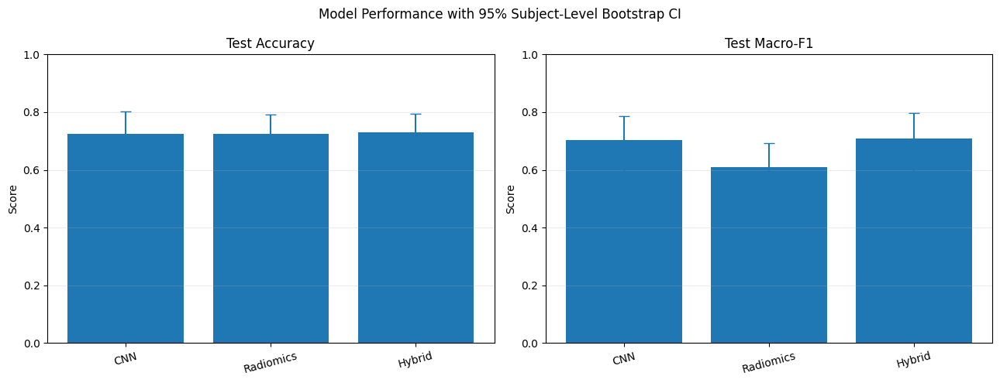

/tmp/ipykernel_2813/138945.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


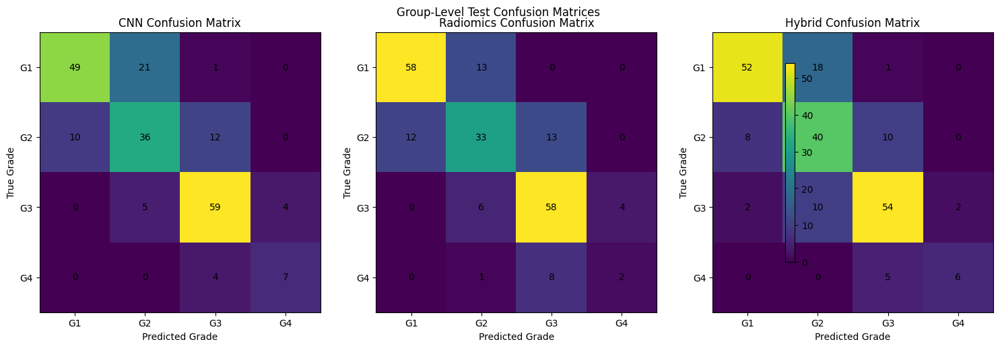

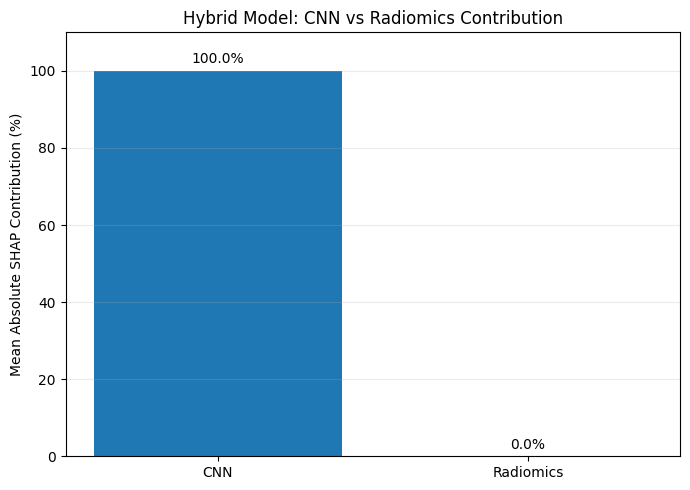


SAVED FIGURES:
Figure_1_Model_Performance_Confidence_Intervals.png | Size: 110.06 KB
Figure_2_Group_Level_Confusion_Matrices.png | Size: 165.1 KB
Figure_3_SHAP_Modality_Contribution.png | Size: 87.08 KB

FIGURE GENERATION STATUS: PASS
Output directory: /content/drive/MyDrive/Muscular_Dystrophy_Project/09_Figures/Dataset_B_Final_Research_Figures


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIGURE_DIR = os.path.join(
    PROJECT_DIR,
    "09_Figures",
    "Dataset_B_Final_Research_Figures"
)
os.makedirs(FIGURE_DIR, exist_ok=True)

print("=" * 65)
print("GENERATING FINAL RESEARCH FIGURES")
print("=" * 65)

# --------------------------------------------------
# FIGURE 1: Model performance with 95% confidence intervals
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric, title in [
    (axes[0], "accuracy", "Test Accuracy"),
    (axes[1], "macro_f1", "Test Macro-F1")
]:

    data = summary_df[summary_df["Metric"] == metric].copy()

    x = np.arange(len(data))

    values = data["Test_Estimate"].to_numpy()
    lower = values - data["CI_95_Lower"].to_numpy()
    upper = data["CI_95_Upper"].to_numpy() - values

    ax.bar(x, values)
    ax.errorbar(
        x,
        values,
        yerr=[lower, upper],
        fmt="none",
        capsize=5
    )

    ax.set_xticks(x)
    ax.set_xticklabels(data["Model"], rotation=15)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Model Performance with 95% Subject-Level Bootstrap CI"
)
plt.tight_layout()

performance_path = os.path.join(
    FIGURE_DIR,
    "Figure_1_Model_Performance_Confidence_Intervals.png"
)

fig.savefig(performance_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# --------------------------------------------------
# FIGURE 2: Three group-level confusion matrices
# --------------------------------------------------

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

for ax, model_name, prediction_column in [
    (axes[0], "CNN", "cnn_prediction"),
    (axes[1], "Radiomics", "radiomics_prediction"),
    (axes[2], "Hybrid", "hybrid_prediction")
]:

    cm = confusion_matrix(
        bootstrap_eval_df["true_grade"],
        bootstrap_eval_df[prediction_column],
        labels=[1, 2, 3, 4]
    )

    image = ax.imshow(cm, interpolation="nearest")

    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xlabel("Predicted Grade")
    ax.set_ylabel("True Grade")

    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.set_xticklabels(["G1", "G2", "G3", "G4"])
    ax.set_yticklabels(["G1", "G2", "G3", "G4"])

    for i in range(4):
        for j in range(4):
            ax.text(j, i, str(cm[i, j]),
                    ha="center", va="center")

fig.colorbar(image, ax=axes, shrink=0.8)
fig.suptitle("Group-Level Test Confusion Matrices")
plt.tight_layout()

confusion_path = os.path.join(
    FIGURE_DIR,
    "Figure_2_Group_Level_Confusion_Matrices.png"
)

fig.savefig(confusion_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# --------------------------------------------------
# FIGURE 3: SHAP modality contribution
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

modalities = modality_importance["modality"].tolist()
contributions = modality_importance[
    "contribution_percent"
].to_numpy()

ax.bar(modalities, contributions)
ax.set_ylabel("Mean Absolute SHAP Contribution (%)")
ax.set_title("Hybrid Model: CNN vs Radiomics Contribution")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.25)

for i, value in enumerate(contributions):
    ax.text(i, value + 2, f"{value:.1f}%", ha="center")

plt.tight_layout()

shap_path = os.path.join(
    FIGURE_DIR,
    "Figure_3_SHAP_Modality_Contribution.png"
)

fig.savefig(shap_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# --------------------------------------------------
# VERIFY FIGURES
# --------------------------------------------------

print("\nSAVED FIGURES:")

for path in [
    performance_path,
    confusion_path,
    shap_path
]:
    assert os.path.exists(path)
    print(
        os.path.basename(path),
        "| Size:",
        round(os.path.getsize(path) / 1024, 2),
        "KB"
    )

print("\nFIGURE GENERATION STATUS: PASS")
print("Output directory:", FIGURE_DIR)

In [ ]:
import os
import json
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

BASE = PROJECT_DIR / "05_Model_Development" / "Dataset_B_Hybrid_Fusion"

print("=" * 65)
print("STEP 41: FINAL RESEARCH ARTIFACT AUDIT")
print("=" * 65)

files_to_check = {
    "Hybrid model": BASE / "Model" / "Dataset_B_CNN_Radiomics_Hybrid_XGBoost.json",
    "Selected 13-round model": BASE / "Model" / "Dataset_B_Hybrid_Fusion_Selected_13_Rounds.json",
    "Hybrid test metrics": BASE / "Evaluation_Results" / "Hybrid_Test_Metrics.json",
    "Hybrid confusion matrix": BASE / "Evaluation_Results" / "Hybrid_Test_Confusion_Matrix.csv",
    "Hybrid predictions": BASE / "Evaluation_Results" / "Hybrid_Test_Group_Predictions.csv",
    "SHAP global importance": BASE / "SHAP_Analysis" / "Hybrid_SHAP_Global_Classwise_Importance.csv",
    "SHAP modality contribution": BASE / "SHAP_Analysis" / "Hybrid_SHAP_Modality_Contribution.csv",
    "Feature usage audit": BASE / "SHAP_Analysis" / "Hybrid_XGBoost_Corrected_Feature_Usage.csv",
    "Bootstrap confidence intervals": BASE / "Statistical_Analysis" / "Subject_Bootstrap_Model_Confidence_Intervals.csv",
    "Paired model differences": BASE / "Statistical_Analysis" / "Subject_Bootstrap_Paired_Model_Differences.csv",
    "Bootstrap methodology": BASE / "Statistical_Analysis" / "Subject_Bootstrap_Methodology_and_Findings.json",
}

all_pass = True

for name, path in files_to_check.items():
    exists = path.exists()
    size = f"{path.stat().st_size / 1024:.2f} KB" if exists else "MISSING"

    print(f"{'PASS' if exists else 'FAIL'} | {name} | {size}")

    if not exists:
        all_pass = False

figure_dir = PROJECT_DIR / "09_Figures" / "Dataset_B_Final_Research_Figures"

print("\nFINAL FIGURES")

for filename in [
    "Figure_1_Model_Performance_Confidence_Intervals.png",
    "Figure_2_Group_Level_Confusion_Matrices.png",
    "Figure_3_SHAP_Modality_Contribution.png"
]:
    path = figure_dir / filename
    exists = path.exists()
    print(f"{'PASS' if exists else 'FAIL'} | {filename}")

    if not exists:
        all_pass = False

print("\n" + "=" * 65)

if all_pass:
    print("FINAL ARTIFACT AUDIT: PASS")
    print("All expected research artifacts are present.")
else:
    print("FINAL ARTIFACT AUDIT: INCOMPLETE")
    print("Review the missing files before proceeding.")

print("=" * 65)

STEP 41: FINAL RESEARCH ARTIFACT AUDIT
PASS | Hybrid model | 341.43 KB
PASS | Selected 13-round model | 34.34 KB
PASS | Hybrid test metrics | 1.34 KB
PASS | Hybrid confusion matrix | 0.11 KB
PASS | Hybrid predictions | 13.54 KB
PASS | SHAP global importance | 27.19 KB
PASS | SHAP modality contribution | 0.08 KB
PASS | Feature usage audit | 1.75 KB
PASS | Bootstrap confidence intervals | 0.47 KB
PASS | Paired model differences | 0.43 KB
PASS | Bootstrap methodology | 0.90 KB

FINAL FIGURES
PASS | Figure_1_Model_Performance_Confidence_Intervals.png
PASS | Figure_2_Group_Level_Confusion_Matrices.png
PASS | Figure_3_SHAP_Modality_Contribution.png

FINAL ARTIFACT AUDIT: PASS
All expected research artifacts are present.


In [ ]:
import json
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

BASE = PROJECT_DIR / "05_Model_Development" / "Dataset_B_Hybrid_Fusion"

print("=" * 70)
print("STEP 42: FINAL RESULTS EXTRACTION")
print("=" * 70)

# 1. Hybrid model test metrics
metrics_path = BASE / "Evaluation_Results" / "Hybrid_Test_Metrics.json"

print("\n1. HYBRID MODEL — TEST METRICS")
with open(metrics_path, "r") as f:
    hybrid_metrics = json.load(f)

print(json.dumps(hybrid_metrics, indent=4, default=str))

# 2. Subject-level bootstrap confidence intervals
bootstrap_path = (
    BASE / "Statistical_Analysis" /
    "Subject_Bootstrap_Model_Confidence_Intervals.csv"
)

print("\n2. SUBJECT-LEVEL BOOTSTRAP CONFIDENCE INTERVALS")
bootstrap_df = pd.read_csv(bootstrap_path)
print(bootstrap_df.to_string(index=False))

# 3. Paired model differences
paired_path = (
    BASE / "Statistical_Analysis" /
    "Subject_Bootstrap_Paired_Model_Differences.csv"
)

print("\n3. PAIRED MODEL COMPARISONS")
paired_df = pd.read_csv(paired_path)
print(paired_df.to_string(index=False))

# 4. SHAP modality contribution
shap_path = (
    BASE / "SHAP_Analysis" /
    "Hybrid_SHAP_Modality_Contribution.csv"
)

print("\n4. SHAP MODALITY CONTRIBUTION")
shap_df = pd.read_csv(shap_path)
print(shap_df.to_string(index=False))

# 5. Corrected feature usage
usage_path = (
    BASE / "SHAP_Analysis" /
    "Hybrid_XGBoost_Corrected_Feature_Usage.csv"
)

print("\n5. CORRECTED TREE FEATURE USAGE")
usage_df = pd.read_csv(usage_path)

if "split_count" in usage_df.columns:
    usage_df = usage_df.sort_values(
        "split_count", ascending=False
    )

print(usage_df.head(15).to_string(index=False))

# 6. Hybrid confusion matrix
confusion_path = (
    BASE / "Evaluation_Results" /
    "Hybrid_Test_Confusion_Matrix.csv"
)

print("\n6. HYBRID TEST CONFUSION MATRIX")
confusion_df = pd.read_csv(confusion_path)
print(confusion_df.to_string(index=False))

print("\n" + "=" * 70)
print("STEP 42 EXTRACTION COMPLETE")
print("Send the complete output for final report preparation.")
print("=" * 70)

STEP 42: FINAL RESULTS EXTRACTION

1. HYBRID MODEL — TEST METRICS
{
    "test_groups": 208,
    "selected_boosting_rounds": 13,
    "accuracy": 0.7307692307692307,
    "macro_f1": 0.7077657912898188,
    "balanced_accuracy": 0.6904054327810862,
    "classification_report": {
        "G1": {
            "precision": 0.8387096774193549,
            "recall": 0.7323943661971831,
            "f1-score": 0.7819548872180451,
            "support": 71.0
        },
        "G2": {
            "precision": 0.5882352941176471,
            "recall": 0.6896551724137931,
            "f1-score": 0.6349206349206349,
            "support": 58.0
        },
        "G3": {
            "precision": 0.7714285714285715,
            "recall": 0.7941176470588235,
            "f1-score": 0.782608695652174,
            "support": 68.0
        },
        "G4": {
            "precision": 0.75,
            "recall": 0.5454545454545454,
            "f1-score": 0.631578947368421,
            "support": 11.0
       

In [ ]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

MANIFEST_PATH = (
    PROJECT_ROOT
    / "02_Dataset_Audit"
    / "Dataset_B_FSHD_Ultrasound"
    / "Audit_Results"
    / "Dataset_B_Image_Mask_Manifest.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

print("=" * 65)
print("RADIOMICS MASK PATH INVESTIGATION")
print("=" * 65)

print("\nManifest shape:", manifest.shape)
print("Manifest columns:", manifest.columns.tolist())

# Check whether the manifest contains explicit mask paths
if "mask_path" in manifest.columns:

    print("\nExplicit mask_path column FOUND.")

    sample_paths = manifest["mask_path"].dropna().astype(str).head(10)

    for p in sample_paths:
        path = Path(p)
        print(
            f"{'EXISTS' if path.is_file() else 'MISSING'} | {p}"
        )

    valid_paths = manifest["mask_path"].dropna().astype(str)

    existing_count = sum(Path(p).is_file() for p in valid_paths)

    print("\nTotal mask paths:", len(valid_paths))
    print("Existing mask files:", existing_count)
    print("Missing mask files:", len(valid_paths) - existing_count)

else:
    print("\nNo mask_path column in manifest.")

# Inspect the actual preprocessing directory
PREPROCESS_DIR = (
    PROJECT_ROOT
    / "04_Preprocessing"
    / "Dataset_B_FSHD_Preprocessing"
)

print("\n" + "=" * 65)
print("PREPROCESSING DIRECTORY CONTENTS")
print("=" * 65)

for item in PREPROCESS_DIR.iterdir():
    print(
        "FOLDER" if item.is_dir() else "FILE",
        "|",
        item.name
    )

    if item.is_dir():
        png_count = sum(
            1 for p in item.rglob("*")
            if p.is_file() and p.suffix.lower() == ".png"
        )
        print("  PNG files:", png_count)

print("\nInvestigation complete.")

RADIOMICS MASK PATH INVESTIGATION

Manifest shape: (25005, 11)
Manifest columns: ['filename', 'image_path', 'mask_path', 'mask_exists', 'subject_id', 'muscle_code', 'side_code', 'side', 'image_index', 'heckmatt_grade', 'metadata_available']

Explicit mask_path column FOUND.
EXISTS | /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Masks/masks/00006_001_00_1.png
EXISTS | /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Masks/masks/00006_001_00_2.png
EXISTS | /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Masks/masks/00006_001_00_3.png
EXISTS | /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Masks/masks/00006_001_01_1.png
EXISTS | /content/drive/MyDrive/Muscular_Dystrophy_Project/02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Masks/masks

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np

MASK_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "04_Preprocessing/Dataset_B_FSHD_Preprocessing/processed_masks"
)

mask_files = sorted(MASK_DIR.glob("*.png"))

print("=" * 65)
print("PROCESSED MASK ENCODING AUDIT")
print("=" * 65)
print("Total masks found:", len(mask_files))

if not mask_files:
    raise ValueError("No processed masks found.")

# Inspect 20 masks
sample_files = mask_files[:20]

for path in sample_files:
    try:
        with Image.open(path) as img:
            mask = np.array(img)

        values, counts = np.unique(mask, return_counts=True)

        print(f"\n{path.name}")
        print("Shape:", mask.shape)
        print("Unique pixel values:", values.tolist())
        print("Pixel counts:", dict(zip(values.tolist(), counts.tolist())))
        print("Label 1 present:", 1 in values)
        print("Label 255 present:", 255 in values)

    except Exception as e:
        print(f"\nERROR reading {path.name}: {e}")

print("\n" + "=" * 65)
print("AUDIT COMPLETE")
print("=" * 65)

PROCESSED MASK ENCODING AUDIT
Total masks found: 25005

00006_001_00_1.png
Shape: (512, 512)
Unique pixel values: [0, 1]
Pixel counts: {0: 190756, 1: 71388}
Label 1 present: True
Label 255 present: False

00006_001_00_2.png
Shape: (512, 512)
Unique pixel values: [0, 1]
Pixel counts: {0: 180118, 1: 82026}
Label 1 present: True
Label 255 present: False

00006_001_00_3.png
Shape: (512, 512)
Unique pixel values: [0, 1]
Pixel counts: {0: 187392, 1: 74752}
Label 1 present: True
Label 255 present: False

00006_001_01_1.png
Shape: (512, 512)
Unique pixel values: [0, 1]
Pixel counts: {0: 217439, 1: 44705}
Label 1 present: True
Label 255 present: False

00006_001_01_2.png
Shape: (512, 512)
Unique pixel values: [0, 1]
Pixel counts: {0: 223360, 1: 38784}
Label 1 present: True
Label 255 present: False

00006_001_01_3.png
Shape: (512, 512)
Unique pixel values: [0, 1]
Pixel counts: {0: 218394, 1: 43750}
Label 1 present: True
Label 255 present: False

00006_001_01_4.png
Shape: (512, 512)
Unique pixel 

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

MANIFEST_PATH = (
    PROJECT_ROOT / "02_Dataset_Audit" /
    "Dataset_B_FSHD_Ultrasound" / "Audit_Results" /
    "Dataset_B_Image_Mask_Manifest.csv"
)

IMAGE_DIR = (
    PROJECT_ROOT / "02_Dataset_Audit" /
    "Dataset_B_FSHD_Ultrasound" /
    "Extracted_Files" / "Images" / "images"
)

MASK_DIR = (
    PROJECT_ROOT / "04_Preprocessing" /
    "Dataset_B_FSHD_Preprocessing" / "processed_masks"
)

manifest = pd.read_csv(MANIFEST_PATH)

sample = manifest[
    manifest["metadata_available"].astype(str).str.lower()
    .isin(["true", "1"])
].head(20)

results = []

print("=" * 65)
print("IMAGE-MASK ALIGNMENT AND COVERAGE AUDIT")
print("=" * 65)

for _, row in sample.iterrows():

    filename = row["filename"]
    image_path = IMAGE_DIR / filename
    mask_path = MASK_DIR / filename

    try:
        image = np.array(Image.open(image_path).convert("L"))
        mask = np.array(Image.open(mask_path))

        if image.shape != mask.shape:
            alignment = "DIMENSION MISMATCH"
        else:
            alignment = "DIMENSIONS MATCH"

        muscle_pixels = np.count_nonzero(mask == 1)
        total_pixels = mask.size
        coverage = (muscle_pixels / total_pixels) * 100

        results.append({
            "filename": filename,
            "image_shape": str(image.shape),
            "mask_shape": str(mask.shape),
            "alignment": alignment,
            "muscle_pixels": muscle_pixels,
            "muscle_coverage_percent": round(coverage, 2),
            "image_min": int(image.min()),
            "image_max": int(image.max())
        })

    except Exception as e:
        print(f"Could not inspect {filename}: {e}")

result_df = pd.DataFrame(results)

print("\nSuccessfully inspected:", len(result_df))

if not result_df.empty:
    display(result_df)

    print("\nAlignment summary:")
    print(result_df["alignment"].value_counts())

    print("\nMuscle coverage statistics:")
    print(result_df["muscle_coverage_percent"].describe())

print("\nAudit complete.")

IMAGE-MASK ALIGNMENT AND COVERAGE AUDIT

Successfully inspected: 20


,filename,image_shape,mask_shape,alignment,muscle_pixels,muscle_coverage_percent,image_min,image_max
0,00006_001_00_1.png,"(512, 512)","(512, 512)",DIMENSIONS MATCH,71388,27.23,0,254
1,00006_001_00_2.png,"(512, 512)","(512, 512)",DIMENSIONS MATCH,82026,31.29,0,255
2,00006_001_00_3.png,"(512, 512)","(512, 512)",DIMENSIONS MATCH,74752,28.52,0,255
3,00006_001_01_1.png,"(512, 512)","(512, 512)",DIMENSIONS MATCH,44705,17.05,0,255
4,00006_001_01_2.png,"(512, 512)","(512, 512)",DIMENSIONS MATCH,38784,14.79,0,255
5,00006_001_01_3.png,"(512, 512)","(512, 512)",DIMENSIONS MATCH,43750,16.69,0,255
6,00006_001_01_4.png,"(512, 512)","(512, 512)",DIMENSIONS MATCH,36559,13.95,0,255
7,00006_004_00_1.png,"(512, 512)","(512, 512)",DIMENSIONS MATCH,13626,5.20,0,244
8,00006_004_00_2.png,"(512, 512)","(512, 512)",DIMENSIONS MATCH,13761,5.25,0,233
9,00006_004_00_3.png,"(512, 512)","(512, 512)",DIMENSIONS MATCH,12084,4.61,0,244



Alignment summary:
alignment
DIMENSIONS MATCH    20
Name: count, dtype: int64

Muscle coverage statistics:
count    20.000000
mean     20.228500
std      11.937277
min       4.610000
25%       5.452500
50%      22.140000
75%      31.020000
max      34.720000
Name: muscle_coverage_percent, dtype: float64

Audit complete.


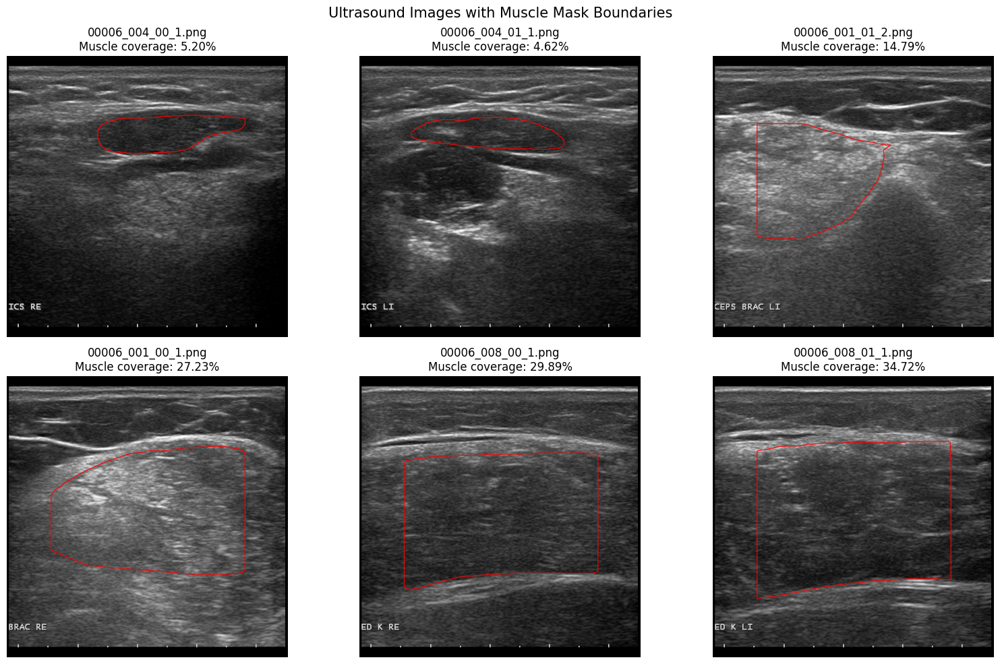

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

MANIFEST_PATH = (
    PROJECT_ROOT / "02_Dataset_Audit" /
    "Dataset_B_FSHD_Ultrasound" / "Audit_Results" /
    "Dataset_B_Image_Mask_Manifest.csv"
)

IMAGE_DIR = (
    PROJECT_ROOT / "02_Dataset_Audit" /
    "Dataset_B_FSHD_Ultrasound" /
    "Extracted_Files" / "Images" / "images"
)

MASK_DIR = (
    PROJECT_ROOT / "04_Preprocessing" /
    "Dataset_B_FSHD_Preprocessing" / "processed_masks"
)

manifest = pd.read_csv(MANIFEST_PATH)

# Select six samples with different muscle coverage values
sample_names = [
    "00006_004_00_1.png",
    "00006_004_01_1.png",
    "00006_001_01_2.png",
    "00006_001_00_1.png",
    "00006_008_00_1.png",
    "00006_008_01_1.png"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, filename in zip(axes, sample_names):

    image_path = IMAGE_DIR / filename
    mask_path = MASK_DIR / filename

    image = np.array(Image.open(image_path).convert("L"))
    mask = np.array(Image.open(mask_path))

    ax.imshow(image, cmap="gray")

    # Draw muscle mask boundary
    ax.contour(
        mask == 1,
        levels=[0.5],
        colors=["red"],
        linewidths=0.8
    )

    coverage = np.mean(mask == 1) * 100

    ax.set_title(
        f"{filename}\nMuscle coverage: {coverage:.2f}%"
    )
    ax.axis("off")

plt.suptitle(
    "Ultrasound Images with Muscle Mask Boundaries",
    fontsize=15
)
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

RADIOMICS_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

print("=" * 75)
print("RADIOMICS FEATURE QUALITY AUDIT")
print("=" * 75)

csv_files = list(RADIOMICS_DIR.rglob("*.csv"))

print("\nCSV files found:")
for i, file in enumerate(csv_files, 1):
    print(f"{i}. {file.relative_to(RADIOMICS_DIR)}")

# Identify feature tables by their names
feature_files = [
    f for f in csv_files
    if any(word in f.name.lower() for word in ["train", "validation", "test"])
    and "feature" in f.name.lower()
]

if not feature_files:
    raise FileNotFoundError(
        "No train/validation/test feature CSV files identified."
    )

for file in feature_files:

    print("\n" + "=" * 75)
    print("FILE:", file.name)
    print("=" * 75)

    df = pd.read_csv(file)

    metadata_cols = [
        c for c in df.columns
        if c.lower() in [
            "filename", "subject_id", "muscle_code",
            "side_code", "side", "group_id",
            "heckmatt_grade", "partition"
        ]
    ]

    feature_cols = [
        c for c in df.columns if c not in metadata_cols
    ]

    features = df[feature_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    print("Dataset shape:", df.shape)
    print("Metadata columns:", len(metadata_cols))
    print("Feature columns:", len(feature_cols))

    print("\nMissing values:", int(features.isna().sum().sum()))
    print("Infinite values:", int(np.isinf(
        features.to_numpy(dtype=float)
    ).sum()))

    variance = features.var()
    unique_counts = features.nunique(dropna=False)

    constant_features = unique_counts[unique_counts <= 1].index.tolist()
    near_constant = variance[
        (variance > 0) & (variance < 1e-10)
    ].index.tolist()

    duplicate_features = features.T.duplicated()
    duplicate_names = features.columns[duplicate_features].tolist()

    print("\nConstant features:", len(constant_features))
    print(constant_features[:20])

    print("\nNear-constant features:", len(near_constant))
    print(near_constant[:20])

    print("\nDuplicate feature columns:", len(duplicate_names))
    print(duplicate_names[:20])

    print("\nFeature variance summary:")
    print(variance.describe())

    print("\nTop 10 lowest-variance features:")
    print(variance.sort_values().head(10))

    print("\nTop 10 highest-variance features:")
    print(variance.sort_values(ascending=False).head(10))

print("\n" + "=" * 75)
print("FEATURE QUALITY AUDIT COMPLETED")
print("=" * 75)

RADIOMICS FEATURE QUALITY AUDIT

CSV files found:
1. Radiomics_10_Subject_Pilot.csv
2. Dataset_B_Radiomics_Training_Manifest.csv
3. Dataset_B_Radiomics_Training_Features.csv
4. Dataset_B_Radiomics_Validation_Features.csv
5. Dataset_B_Radiomics_Validation_Errors.csv
6. Dataset_B_Radiomics_Test_Features.csv
7. Dataset_B_Radiomics_Subject_Level_Split.csv
8. XGBoost/Dataset_B_Radiomics_XGBoost_Validation_Predictions.csv
9. XGBoost/Dataset_B_Radiomics_XGBoost_Test_Image_Predictions.csv
10. XGBoost/Dataset_B_Radiomics_XGBoost_Test_Group_Predictions.csv
11. XGBoost/Dataset_B_Radiomics_XGBoost_Test_Confusion_Matrix.csv
12. XGBoost/Dataset_B_Radiomics_XGBoost_Feature_Importance.csv
13. XGBoost/SHAP/Dataset_B_SHAP_Global_Feature_Importance.csv
14. XGBoost/SHAP/Dataset_B_SHAP_Classwise_Feature_Importance.csv
15. XGBoost/SHAP/Dataset_B_SHAP_Values_200_Test_Samples.csv

FILE: Dataset_B_Radiomics_Training_Features.csv
Dataset shape: (3342, 110)
Metadata columns: 8
Feature columns: 102

Missing value

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

CSV_PATH = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics/"
    "Dataset_B_Radiomics_Training_Features.csv"
)

df = pd.read_csv(CSV_PATH)

metadata_cols = [
    "filename", "subject_id", "muscle_code",
    "side_code", "side", "group_id",
    "heckmatt_grade", "partition"
]

feature_cols = [c for c in df.columns if c not in metadata_cols]
X = df[feature_cols].apply(pd.to_numeric, errors="coerce")

print("=" * 70)
print("DUPLICATE AND CORRELATION INVESTIGATION")
print("=" * 70)

# 1. Exact duplicate feature columns
print("\n1. EXACT DUPLICATE FEATURES")

duplicate_pairs = []

for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        a = X.iloc[:, i]
        b = X.iloc[:, j]

        if a.equals(b):
            duplicate_pairs.append((feature_cols[i], feature_cols[j]))

if duplicate_pairs:
    for a, b in duplicate_pairs:
        print(f"EXACT DUPLICATE: {a} == {b}")
else:
    print("No exact duplicate pairs found.")

# 2. Specifically inspect Energy and TotalEnergy
print("\n2. ENERGY FEATURE COMPARISON")

energy_cols = [
    c for c in feature_cols
    if "Energy" in c
]

for col in energy_cols:
    print(
        col,
        "| min:", X[col].min(),
        "| max:", X[col].max(),
        "| mean:", X[col].mean()
    )

if (
    "original_firstorder_Energy" in X.columns
    and "original_firstorder_TotalEnergy" in X.columns
):
    a = X["original_firstorder_Energy"]
    b = X["original_firstorder_TotalEnergy"]

    print(
        "Maximum absolute difference:",
        np.max(np.abs(a - b))
    )

# 3. Highly correlated features
print("\n3. HIGHLY CORRELATED FEATURE PAIRS")

corr = X.corr(method="pearson").abs()

high_corr_pairs = []

for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        value = corr.iloc[i, j]

        if pd.notna(value) and value >= 0.999:
            high_corr_pairs.append((
                feature_cols[i],
                feature_cols[j],
                value
            ))

high_corr_pairs.sort(key=lambda x: x[2], reverse=True)

print("Pairs with absolute correlation >= 0.999:",
      len(high_corr_pairs))

for a, b, value in high_corr_pairs[:30]:
    print(f"{a} <-> {b} | correlation: {value:.8f}")

print("\n" + "=" * 70)
print("INVESTIGATION COMPLETE")
print("=" * 70)

DUPLICATE AND CORRELATION INVESTIGATION

1. EXACT DUPLICATE FEATURES
EXACT DUPLICATE: original_firstorder_Energy == original_firstorder_TotalEnergy

2. ENERGY FEATURE COMPARISON
original_firstorder_Energy | min: 2171990.0 | max: 1171633369.0 | mean: 258402960.85906643
original_firstorder_TotalEnergy | min: 2171990.0 | max: 1171633369.0 | mean: 258402960.85906643
original_glcm_JointEnergy | min: 0.0431065980636338 | max: 0.366106752056571 | mean: 0.17847252266217392
Maximum absolute difference: 0.0

3. HIGHLY CORRELATED FEATURE PAIRS
Pairs with absolute correlation >= 0.999: 9
original_firstorder_Energy <-> original_firstorder_TotalEnergy | correlation: 1.00000000
original_glcm_JointAverage <-> original_glcm_SumAverage | correlation: 1.00000000
original_shape2D_MeshSurface <-> original_shape2D_PixelSurface | correlation: 1.00000000
original_glszm_LargeAreaEmphasis <-> original_glszm_ZoneVariance | correlation: 0.99999717
original_firstorder_Variance <-> original_gldm_GrayLevelVariance |

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

CSV_PATH = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics/"
    "Dataset_B_Radiomics_Training_Features.csv"
)

df = pd.read_csv(CSV_PATH)

metadata_cols = [
    "filename", "subject_id", "muscle_code",
    "side_code", "side", "group_id",
    "heckmatt_grade", "partition"
]

feature_cols = [c for c in df.columns if c not in metadata_cols]

# Remove exact duplicate feature columns for this exploratory analysis
X = df[feature_cols].apply(pd.to_numeric, errors="coerce")
X = X.loc[:, ~X.T.duplicated()]

df_clean = pd.concat(
    [df[["group_id", "heckmatt_grade"]], X],
    axis=1
)

# Aggregate image-level features into group-level means
group_df = (
    df_clean
    .groupby(["group_id", "heckmatt_grade"], as_index=False)
    .mean(numeric_only=True)
)

print("=" * 70)
print("RADIOMICS GRADE-DISCRIMINATION AUDIT")
print("=" * 70)

print("\nImage-level records:", len(df))
print("Group-level records:", len(group_df))
print("Unique radiomics features:", len(X.columns))

print("\nGroup counts by Heckmatt grade:")
print(group_df["heckmatt_grade"].value_counts().sort_index())

results = []

for feature in X.columns:

    grade_values = []
    valid = True

    for grade in sorted(group_df["heckmatt_grade"].dropna().unique()):
        values = group_df.loc[
            group_df["heckmatt_grade"] == grade, feature
        ].dropna().values

        if len(values) < 2:
            valid = False
            break

        grade_values.append(values)

    if not valid:
        continue

    try:
        statistic, p_value = kruskal(*grade_values)

        n = sum(len(values) for values in grade_values)
        effect_size = statistic / (n - 1) if n > 1 else np.nan

        results.append({
            "feature": feature,
            "kruskal_statistic": statistic,
            "p_value": p_value,
            "rank_effect_size": effect_size
        })

    except ValueError:
        continue

result_df = pd.DataFrame(results)

if result_df.empty:
    raise ValueError("No valid feature tests could be calculated.")

# Correct for testing multiple features
result_df["adjusted_p_value"] = multipletests(
    result_df["p_value"],
    method="fdr_bh"
)[1]

result_df = result_df.sort_values(
    "adjusted_p_value"
).reset_index(drop=True)

print("\nTop 20 features by adjusted p-value:")
display(result_df.head(20))

print("\nFeatures with FDR-adjusted p-value < 0.05:",
      int((result_df["adjusted_p_value"] < 0.05).sum()))

print("\n" + "=" * 70)
print("AUDIT COMPLETE")
print("=" * 70)

RADIOMICS GRADE-DISCRIMINATION AUDIT

Image-level records: 3342
Group-level records: 1029
Unique radiomics features: 101

Group counts by Heckmatt grade:
heckmatt_grade
1.0    359
2.0    378
3.0    252
4.0     40
Name: count, dtype: int64

Top 20 features by adjusted p-value:


,feature,kruskal_statistic,p_value,rank_effect_size,adjusted_p_value
0,original_firstorder_10Percentile,644.271696,2.542880e-139,0.626723,2.568309e-137
1,original_firstorder_Minimum,638.014833,5.779283e-138,0.620637,2.918538e-136
2,original_firstorder_Median,628.237760,7.613696e-136,0.611126,2.563278e-134
3,original_firstorder_Mean,597.433145,3.629532e-129,0.581161,9.164569e-128
4,original_firstorder_RootMeanSquared,570.919503,2.029510e-123,0.555369,4.099611e-122
5,original_firstorder_90Percentile,469.924110,1.570910e-101,0.457125,2.644364e-100
6,original_firstorder_Skewness,453.093646,6.965531e-98,0.440753,1.005027e-96
7,original_firstorder_Kurtosis,452.785681,8.122336e-98,0.440453,1.025445e-96
8,original_firstorder_Range,399.115804,3.440947e-86,0.388245,3.861507e-85
9,original_ngtdm_Complexity,341.013210,1.316788e-73,0.331725,1.329956e-72



Features with FDR-adjusted p-value < 0.05: 99

AUDIT COMPLETE


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

BASE_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

FILES = {
    "TRAIN": BASE_DIR / "Dataset_B_Radiomics_Training_Features.csv",
    "VALIDATION": BASE_DIR / "Dataset_B_Radiomics_Validation_Features.csv",
    "TEST": BASE_DIR / "Dataset_B_Radiomics_Test_Features.csv"
}

METADATA = [
    "filename", "subject_id", "muscle_code",
    "side_code", "side", "group_id",
    "heckmatt_grade", "partition"
]

def analyse_partition(path, name):

    df = pd.read_csv(path)

    feature_cols = [c for c in df.columns if c not in METADATA]

    X = df[feature_cols].apply(pd.to_numeric, errors="coerce")

    # Remove exact duplicate columns
    X = X.loc[:, ~X.T.duplicated()]

    data = pd.concat(
        [df[["group_id", "heckmatt_grade"]], X],
        axis=1
    )

    # Aggregate images within each subject-muscle-side group
    grouped = (
        data.groupby(
            ["group_id", "heckmatt_grade"],
            as_index=False
        ).mean(numeric_only=True)
    )

    results = []

    for feature in X.columns:

        grade_arrays = []

        for grade in [1, 2, 3, 4]:

            values = grouped.loc[
                grouped["heckmatt_grade"] == grade,
                feature
            ].dropna().values

            if len(values) < 2:
                grade_arrays = []
                break

            grade_arrays.append(values)

        if not grade_arrays:
            continue

        try:
            statistic, p_value = kruskal(*grade_arrays)

            results.append({
                "feature": feature,
                "p_value": p_value,
                "rank_effect_size": statistic / (len(grouped) - 1)
            })

        except ValueError:
            continue

    result = pd.DataFrame(results)

    result["adjusted_p_value"] = multipletests(
        result["p_value"],
        method="fdr_bh"
    )[1]

    result = result.sort_values(
        "adjusted_p_value"
    ).reset_index(drop=True)

    print("\n" + "=" * 70)
    print(name, "RESULTS")
    print("=" * 70)

    print("Image records:", len(df))
    print("Independent subject-muscle-side groups:", len(grouped))
    print("Features tested:", len(result))
    print(
        "Features with adjusted p < 0.05:",
        (result["adjusted_p_value"] < 0.05).sum()
    )

    return grouped, result


all_results = {}

for name, path in FILES.items():
    grouped, result = analyse_partition(path, name)
    all_results[name] = {
        "groups": grouped,
        "results": result
    }


# Compare the 10 strongest training features across all partitions
train_top = (
    all_results["TRAIN"]["results"]
    .head(10)["feature"]
    .tolist()
)

comparison = []

for feature in train_top:

    row = {"feature": feature}

    for split in ["TRAIN", "VALIDATION", "TEST"]:

        result = all_results[split]["results"]
        match = result[result["feature"] == feature]

        if not match.empty:
            row[f"{split}_adjusted_p"] = match.iloc[0]["adjusted_p_value"]
            row[f"{split}_effect_size"] = match.iloc[0]["rank_effect_size"]

    comparison.append(row)

comparison_df = pd.DataFrame(comparison)

print("\n" + "=" * 70)
print("TOP TRAINING FEATURES: GENERALISATION CHECK")
print("=" * 70)

display(comparison_df)

print("\nAudit complete.")


TRAIN RESULTS
Image records: 3342
Independent subject-muscle-side groups: 1029
Features tested: 101
Features with adjusted p < 0.05: 99

VALIDATION RESULTS
Image records: 741
Independent subject-muscle-side groups: 231
Features tested: 101
Features with adjusted p < 0.05: 89

TEST RESULTS
Image records: 644
Independent subject-muscle-side groups: 208
Features tested: 101
Features with adjusted p < 0.05: 52

TOP TRAINING FEATURES: GENERALISATION CHECK


,feature,TRAIN_adjusted_p,TRAIN_effect_size,VALIDATION_adjusted_p,VALIDATION_effect_size,TEST_adjusted_p,TEST_effect_size
0,original_firstorder_10Percentile,2.568309e-137,0.626723,1.065080e-29,0.640034,6.251741e-26,0.626706
1,original_firstorder_Minimum,2.918538e-136,0.620637,2.408904e-29,0.626820,8.757010e-26,0.616676
2,original_firstorder_Median,2.563278e-134,0.611126,6.990814e-29,0.613941,9.552173e-26,0.611881
3,original_firstorder_Mean,9.164569e-128,0.581161,2.468795e-27,0.580203,1.947352e-24,0.579716
4,original_firstorder_RootMeanSquared,4.099611e-122,0.555369,1.400136e-25,0.542865,1.892734e-23,0.555384
5,original_firstorder_90Percentile,2.644364e-100,0.457125,3.819847e-20,0.428932,9.755122e-20,0.468744
6,original_firstorder_Skewness,1.005027e-96,0.440753,5.142250e-21,0.447713,3.046457e-19,0.456324
7,original_firstorder_Kurtosis,1.025445e-96,0.440453,3.986974e-23,0.491712,1.739457e-21,0.509535
8,original_firstorder_Range,3.861507e-85,0.388245,6.253545e-19,0.403337,1.565593e-16,0.394185
9,original_ngtdm_Complexity,1.329956e-72,0.331725,1.623850e-16,0.353518,9.742949e-16,0.375271



Audit complete.


In [ ]:
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

SEARCH_DIRS = [
    ROOT / "04_Preprocessing" / "Dataset_B_FSHD_Preprocessing",
    ROOT / "05_Model_Development" / "Dataset_B_Radiomics"
]

KEYWORDS = [
    "RadiomicsFeatureExtractor",
    "binWidth",
    "resampledPixelSpacing",
    "normalize",
    "normalizeScale",
    "force2D",
    "imageType",
    "featureClass",
    "correctMask",
    "interpolator",
    "label=",
    "extractor.execute"
]

print("=" * 75)
print("RADIOMICS EXTRACTION CONFIGURATION AUDIT")
print("=" * 75)

for folder in SEARCH_DIRS:

    print("\nSEARCHING:", folder)

    if not folder.exists():
        print("Directory not found.")
        continue

    files = [
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in [".py", ".yaml", ".yml", ".json"]
    ]

    print("Configuration/script files found:", len(files))

    for file in files:

        try:
            content = file.read_text(
                encoding="utf-8",
                errors="ignore"
            ).splitlines()

            matches = []

            for i, line in enumerate(content):
                if any(keyword.lower() in line.lower()
                       for keyword in KEYWORDS):
                    start = max(0, i - 1)
                    end = min(len(content), i + 2)

                    matches.append((i, content[start:end]))

            if matches:
                print("\n" + "-" * 65)
                print("FILE:", file.name)
                print("PATH:", file)

                for line_number, context in matches:
                    print(f"\nAround line {line_number + 1}:")
                    for text_line in context:
                        print(text_line)

        except Exception as error:
            print("Could not read:", file.name, "|", error)

print("\n" + "=" * 75)
print("CONFIGURATION AUDIT COMPLETE")
print("=" * 75)

RADIOMICS EXTRACTION CONFIGURATION AUDIT

SEARCHING: /content/drive/MyDrive/Muscular_Dystrophy_Project/04_Preprocessing/Dataset_B_FSHD_Preprocessing
Configuration/script files found: 0

SEARCHING: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics
Configuration/script files found: 9

-----------------------------------------------------------------
FILE: Dataset_B_Radiomics_Experiment_Config (1).json
PATH: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Experiment_Config (1).json

Around line 17:
    "radiomics_settings": {
        "binWidth": 25,
        "label": 1,

Around line 19:
        "label": 1,
        "normalize": false,
        "resampledPixelSpacing": null,

Around line 20:
        "normalize": false,
        "resampledPixelSpacing": null,
        "image_type": "Original",

-----------------------------------------------------------------
FILE: Dataset_B_Radiomics_Extracti

In [ ]:
import SimpleITK as sitk
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

IMAGE_DIR = (
    PROJECT_ROOT / "02_Dataset_Audit" /
    "Dataset_B_FSHD_Ultrasound" /
    "Extracted_Files" / "Images" / "images"
)

MASK_DIR = (
    PROJECT_ROOT / "04_Preprocessing" /
    "Dataset_B_FSHD_Preprocessing" /
    "processed_masks"
)

samples = [
    "00006_001_00_1.png",
    "00006_004_00_1.png",
    "00006_008_00_1.png"
]

print("=" * 70)
print("ULTRASOUND IMAGE METADATA AUDIT")
print("=" * 70)

for filename in samples:

    image_path = IMAGE_DIR / filename
    mask_path = MASK_DIR / filename

    image = sitk.ReadImage(str(image_path))
    mask = sitk.ReadImage(str(mask_path))

    image_array = sitk.GetArrayFromImage(image)
    mask_array = sitk.GetArrayFromImage(mask)

    muscle_values = image_array[mask_array == 1]

    print("\nFILE:", filename)

    print("\nIMAGE METADATA")
    print("Dimension:", image.GetDimension())
    print("Size:", image.GetSize())
    print("Spacing:", image.GetSpacing())
    print("Origin:", image.GetOrigin())
    print("Direction:", image.GetDirection())
    print("Pixel type:", image.GetPixelIDTypeAsString())

    print("\nMASK METADATA")
    print("Dimension:", mask.GetDimension())
    print("Size:", mask.GetSize())
    print("Spacing:", mask.GetSpacing())
    print("Origin:", mask.GetOrigin())
    print("Direction:", mask.GetDirection())

    print("\nMUSCLE REGION INTENSITY")
    print("Minimum:", float(muscle_values.min()))
    print("Maximum:", float(muscle_values.max()))
    print("Mean:", float(muscle_values.mean()))
    print("Standard deviation:", float(muscle_values.std()))

    print("\nImage-mask geometry matches:",
          image.GetSize() == mask.GetSize()
          and image.GetSpacing() == mask.GetSpacing()
          and image.GetOrigin() == mask.GetOrigin()
          and image.GetDirection() == mask.GetDirection())

print("\n" + "=" * 70)
print("METADATA AUDIT COMPLETE")
print("=" * 70)

ULTRASOUND IMAGE METADATA AUDIT

FILE: 00006_001_00_1.png

IMAGE METADATA
Dimension: 2
Size: (512, 512)
Spacing: (1.0, 1.0)
Origin: (0.0, 0.0)
Direction: (1.0, 0.0, 0.0, 1.0)
Pixel type: 8-bit unsigned integer

MASK METADATA
Dimension: 2
Size: (512, 512)
Spacing: (1.0, 1.0)
Origin: (0.0, 0.0)
Direction: (1.0, 0.0, 0.0, 1.0)

MUSCLE REGION INTENSITY
Minimum: 40.0
Maximum: 249.0
Mean: 104.19059225640163
Standard deviation: 29.882623426608554

Image-mask geometry matches: True

FILE: 00006_004_00_1.png

IMAGE METADATA
Dimension: 2
Size: (512, 512)
Spacing: (1.0, 1.0)
Origin: (0.0, 0.0)
Direction: (1.0, 0.0, 0.0, 1.0)
Pixel type: 8-bit unsigned integer

MASK METADATA
Dimension: 2
Size: (512, 512)
Spacing: (1.0, 1.0)
Origin: (0.0, 0.0)
Direction: (1.0, 0.0, 0.0, 1.0)

MUSCLE REGION INTENSITY
Minimum: 9.0
Maximum: 107.0
Mean: 41.70710406575664
Standard deviation: 10.633272984974822

Image-mask geometry matches: True

FILE: 00006_008_00_1.png

IMAGE METADATA
Dimension: 2
Size: (512, 512)
Spac

In [ ]:
from pathlib import Path
import re

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

RAD_DIR = (
    PROJECT_ROOT /
    "05_Model_Development" /
    "Dataset_B_Radiomics"
)

scripts = [
    RAD_DIR / "Dataset_B_Radiomics_Extraction.py",
    RAD_DIR / "Dataset_B_Radiomics_Extraction (1).py"
]

for script in scripts:
    print("\n" + "=" * 75)
    print("SCRIPT:", script.name)
    print("=" * 75)

    if not script.exists():
        print("File not found.")
        continue

    content = script.read_text(errors="ignore")

    for pattern in [
        r"feature_classes\s*=\s*\[.*?\]",
        r"enableFeatureClassByName.*",
        r"enableAllFeatures.*",
        r"disableAllFeatures.*",
        r"enableImageTypeByName.*",
        r"RadiomicsFeatureExtractor.*"
    ]:
        matches = re.findall(
            pattern,
            content,
            flags=re.DOTALL
        )

        for match in matches:
            print("\n", match[:3000])

print("\n" + "=" * 75)
print("FEATURE CLASS AUDIT COMPLETE")
print("=" * 75)


SCRIPT: Dataset_B_Radiomics_Extraction.py

 enableFeatureClassByName(feature_class)

    extractor.enableImageTypeByName("Original")
    return extractor


def extract_features(manifest_path, output_path, mask_dir):
    manifest = pd.read_csv(manifest_path)
    extractor = create_extractor()

    metadata_cols = [
        "filename", "subject_id", "muscle_code", "side_code",
        "side", "group_id", "heckmatt_grade", "partition"
    ]

    results, errors = [], []

    for _, row in manifest.iterrows():
        try:
            filename = str(row["filename"])
            image = sitk.ReadImage(str(row["image_path"]))
            mask = sitk.ReadImage(str(Path(mask_dir) / filename))
            image = sitk.Cast(image, sitk.sitkFloat32)

            extracted = extractor.execute(image, mask)

            record = {col: row[col] for col in metadata_cols}
            record.update({
                k: float(v) for k, v in extracted.items()
                if k.startswith("original_")


In [ ]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

RAD_DIR = (
    PROJECT_ROOT /
    "05_Model_Development" /
    "Dataset_B_Radiomics"
)

files = {
    "Train": RAD_DIR / "Dataset_B_Radiomics_Train_Features.csv",
    "Validation": RAD_DIR / "Dataset_B_Radiomics_Validation_Features.csv",
    "Test": RAD_DIR / "Dataset_B_Radiomics_Test_Features.csv"
}

for split, path in files.items():

    print("\n" + "=" * 65)
    print(split.upper())
    print("=" * 65)

    if not path.exists():
        print("File not found:", path.name)
        continue

    df = pd.read_csv(path)

    feature_cols = [
        c for c in df.columns
        if c.startswith("original_")
    ]

    print("Rows:", len(df))
    print("Total columns:", len(df.columns))
    print("Radiomics features:", len(feature_cols))

    classes = [
        "firstorder",
        "glcm",
        "glrlm",
        "glszm",
        "gldm",
        "ngtdm",
        "shape2D"
    ]

    for cls in classes:
        count = sum(
            c.startswith(f"original_{cls}_")
            for c in feature_cols
        )
        print(f"{cls}: {count}")

    print("Duplicate column names:",
          df.columns.duplicated().sum())

print("\nFEATURE COLUMN AUDIT COMPLETE")


TRAIN
File not found: Dataset_B_Radiomics_Train_Features.csv

VALIDATION
Rows: 741
Total columns: 110
Radiomics features: 102
firstorder: 18
glcm: 24
glrlm: 16
glszm: 16
gldm: 14
ngtdm: 5
shape2D: 9
Duplicate column names: 0

TEST
Rows: 644
Total columns: 110
Radiomics features: 102
firstorder: 18
glcm: 24
glrlm: 16
glszm: 16
gldm: 14
ngtdm: 5
shape2D: 9
Duplicate column names: 0

FEATURE COLUMN AUDIT COMPLETE


In [ ]:
from pathlib import Path

RAD_DIR = (
    Path("/content/drive/MyDrive/Muscular_Dystrophy_Project")
    / "05_Model_Development"
    / "Dataset_B_Radiomics"
)

print("CSV FILES IN RADIOMICS FOLDER")
print("=" * 65)

for path in sorted(RAD_DIR.rglob("*.csv")):
    print(path.relative_to(RAD_DIR))

CSV FILES IN RADIOMICS FOLDER
Dataset_B_Radiomics_Subject_Level_Split.csv
Dataset_B_Radiomics_Test_Features.csv
Dataset_B_Radiomics_Training_Features.csv
Dataset_B_Radiomics_Training_Manifest.csv
Dataset_B_Radiomics_Validation_Errors.csv
Dataset_B_Radiomics_Validation_Features.csv
Radiomics_10_Subject_Pilot.csv
XGBoost/Dataset_B_Radiomics_XGBoost_Feature_Importance.csv
XGBoost/Dataset_B_Radiomics_XGBoost_Test_Confusion_Matrix.csv
XGBoost/Dataset_B_Radiomics_XGBoost_Test_Group_Predictions.csv
XGBoost/Dataset_B_Radiomics_XGBoost_Test_Image_Predictions.csv
XGBoost/Dataset_B_Radiomics_XGBoost_Validation_Predictions.csv
XGBoost/SHAP/Dataset_B_SHAP_Classwise_Feature_Importance.csv
XGBoost/SHAP/Dataset_B_SHAP_Global_Feature_Importance.csv
XGBoost/SHAP/Dataset_B_SHAP_Values_200_Test_Samples.csv


In [ ]:
import pandas as pd
from pathlib import Path

RAD_DIR = (
    Path("/content/drive/MyDrive/Muscular_Dystrophy_Project")
    / "05_Model_Development"
    / "Dataset_B_Radiomics"
)

files = {
    "Train": RAD_DIR / "Dataset_B_Radiomics_Training_Features.csv",
    "Validation": RAD_DIR / "Dataset_B_Radiomics_Validation_Features.csv",
    "Test": RAD_DIR / "Dataset_B_Radiomics_Test_Features.csv"
}

for split, path in files.items():

    print("\n" + "=" * 65)
    print(split.upper())
    print("=" * 65)

    df = pd.read_csv(path)

    feature_cols = [
        c for c in df.columns
        if c.startswith("original_")
    ]

    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Radiomics features:", len(feature_cols))

    for cls in [
        "firstorder", "glcm", "glrlm",
        "glszm", "gldm", "ngtdm", "shape2D"
    ]:
        count = sum(
            c.startswith(f"original_{cls}_")
            for c in feature_cols
        )
        print(f"{cls}: {count}")

    print("Duplicate column names:",
          df.columns.duplicated().sum())

print("\nALL THREE SPLITS AUDITED")


TRAIN
Rows: 3342
Columns: 110
Radiomics features: 102
firstorder: 18
glcm: 24
glrlm: 16
glszm: 16
gldm: 14
ngtdm: 5
shape2D: 9
Duplicate column names: 0

VALIDATION
Rows: 741
Columns: 110
Radiomics features: 102
firstorder: 18
glcm: 24
glrlm: 16
glszm: 16
gldm: 14
ngtdm: 5
shape2D: 9
Duplicate column names: 0

TEST
Rows: 644
Columns: 110
Radiomics features: 102
firstorder: 18
glcm: 24
glrlm: 16
glszm: 16
gldm: 14
ngtdm: 5
shape2D: 9
Duplicate column names: 0

ALL THREE SPLITS AUDITED


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

RAD_DIR = (
    Path("/content/drive/MyDrive/Muscular_Dystrophy_Project")
    / "05_Model_Development"
    / "Dataset_B_Radiomics"
)

files = {
    "Train": RAD_DIR / "Dataset_B_Radiomics_Training_Features.csv",
    "Validation": RAD_DIR / "Dataset_B_Radiomics_Validation_Features.csv",
    "Test": RAD_DIR / "Dataset_B_Radiomics_Test_Features.csv"
}

feature_columns = {}

for split, path in files.items():

    df = pd.read_csv(path)

    features = [
        c for c in df.columns
        if c.startswith("original_")
    ]

    feature_columns[split] = features

    values = df[features].to_numpy(dtype=np.float64)

    print("\n" + "=" * 65)
    print(split.upper())
    print("=" * 65)

    print("Missing feature values:", np.isnan(values).sum())
    print("Infinite feature values:", np.isinf(values).sum())
    print("Duplicate filenames:", df["filename"].duplicated().sum())
    print("Duplicate group IDs:", df["group_id"].duplicated().sum())
    print("Partition labels:", df["partition"].value_counts().to_dict())

print("\n" + "=" * 65)
print("FEATURE COLUMN ORDER CHECK")
print("=" * 65)

print(
    "Train = Validation:",
    feature_columns["Train"] == feature_columns["Validation"]
)

print(
    "Train = Test:",
    feature_columns["Train"] == feature_columns["Test"]
)

print("\nAUDIT COMPLETE")


TRAIN
Missing feature values: 0
Infinite feature values: 0
Duplicate filenames: 0
Duplicate group IDs: 2313
Partition labels: {'train': 3342}

VALIDATION
Missing feature values: 0
Infinite feature values: 0
Duplicate filenames: 0
Duplicate group IDs: 510
Partition labels: {'validation': 741}

TEST
Missing feature values: 0
Infinite feature values: 0
Duplicate filenames: 0
Duplicate group IDs: 436
Partition labels: {'test': 644}

FEATURE COLUMN ORDER CHECK
Train = Validation: True
Train = Test: True

AUDIT COMPLETE


In [ ]:
import pandas as pd
from pathlib import Path

RAD_DIR = (
    Path("/content/drive/MyDrive/Muscular_Dystrophy_Project")
    / "05_Model_Development"
    / "Dataset_B_Radiomics"
)

files = {
    "Train": RAD_DIR / "Dataset_B_Radiomics_Training_Features.csv",
    "Validation": RAD_DIR / "Dataset_B_Radiomics_Validation_Features.csv",
    "Test": RAD_DIR / "Dataset_B_Radiomics_Test_Features.csv"
}

for split, path in files.items():

    df = pd.read_csv(path)

    print("\n" + "=" * 65)
    print(split.upper(), "GROUP CONSISTENCY")
    print("=" * 65)

    # Each group should have exactly one grade
    grade_counts = df.groupby("group_id")["heckmatt_grade"].nunique()

    # Each group should belong to one subject
    subject_counts = df.groupby("group_id")["subject_id"].nunique()

    # Each group should have one muscle and side
    muscle_counts = df.groupby("group_id")["muscle_code"].nunique()
    side_counts = df.groupby("group_id")["side_code"].nunique()

    print("Total groups:", df["group_id"].nunique())
    print("Groups with conflicting grades:", (grade_counts > 1).sum())
    print("Groups with multiple subjects:", (subject_counts > 1).sum())
    print("Groups with multiple muscles:", (muscle_counts > 1).sum())
    print("Groups with multiple sides:", (side_counts > 1).sum())

print("\nGROUP CONSISTENCY AUDIT COMPLETE")


TRAIN GROUP CONSISTENCY
Total groups: 1029
Groups with conflicting grades: 0
Groups with multiple subjects: 0
Groups with multiple muscles: 0
Groups with multiple sides: 0

VALIDATION GROUP CONSISTENCY
Total groups: 231
Groups with conflicting grades: 0
Groups with multiple subjects: 0
Groups with multiple muscles: 0
Groups with multiple sides: 0

TEST GROUP CONSISTENCY
Total groups: 208
Groups with conflicting grades: 0
Groups with multiple subjects: 0
Groups with multiple muscles: 0
Groups with multiple sides: 0

GROUP CONSISTENCY AUDIT COMPLETE


In [ ]:
import pandas as pd
from pathlib import Path

RAD_DIR = (
    Path("/content/drive/MyDrive/Muscular_Dystrophy_Project")
    / "05_Model_Development"
    / "Dataset_B_Radiomics"
)

files = {
    "Train": RAD_DIR / "Dataset_B_Radiomics_Training_Features.csv",
    "Validation": RAD_DIR / "Dataset_B_Radiomics_Validation_Features.csv",
    "Test": RAD_DIR / "Dataset_B_Radiomics_Test_Features.csv"
}

data = {
    split: pd.read_csv(path)
    for split, path in files.items()
}

subject_sets = {
    split: set(df["subject_id"].dropna().astype(str))
    for split, df in data.items()
}

group_sets = {
    split: set(df["group_id"].dropna().astype(str))
    for split, df in data.items()
}

pairs = [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]

for first, second in pairs:

    subject_overlap = subject_sets[first] & subject_sets[second]
    group_overlap = group_sets[first] & group_sets[second]

    print(f"\n{first} vs {second}")
    print("Overlapping subjects:", len(subject_overlap))
    print("Overlapping groups:", len(group_overlap))

    if subject_overlap:
        print("Subject examples:", list(subject_overlap)[:5])

print("\nSUBJECT-LEVEL LEAKAGE AUDIT COMPLETE")


Train vs Validation
Overlapping subjects: 0
Overlapping groups: 0

Train vs Test
Overlapping subjects: 0
Overlapping groups: 0

Validation vs Test
Overlapping subjects: 0
Overlapping groups: 0

SUBJECT-LEVEL LEAKAGE AUDIT COMPLETE


In [ ]:
import os
import pandas as pd

base = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

paths = {
    "Radiomics Split": os.path.join(
        base,
        "05_Model_Development/Dataset_B_Radiomics/",
        "Dataset_B_Radiomics_Subject_Level_Split.csv"
    ),
    "Preprocessing Split": os.path.join(
        base,
        "04_Preprocessing/Dataset_B_FSHD_Preprocessing/",
        "splits/Dataset_B_Subject_Level_Split.csv"
    )
}

for name, path in paths.items():
    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    if os.path.exists(path):
        df = pd.read_csv(path)

        print("File:", path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        print("\nFirst 5 rows:")
        display(df.head())

    else:
        print("FILE NOT FOUND:", path)


Radiomics Split
File: /content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Subject_Level_Split.csv
Shape: (109, 2)
Columns: ['subject_id', 'partition']

First 5 rows:


,subject_id,partition
0,6,train
1,13,test
2,19,test
3,25,train
4,76,validation



Preprocessing Split
File: /content/drive/MyDrive/Muscular_Dystrophy_Project/04_Preprocessing/Dataset_B_FSHD_Preprocessing/splits/Dataset_B_Subject_Level_Split.csv
Shape: (109, 2)
Columns: ['subject_id', 'partition']

First 5 rows:


,subject_id,partition
0,6,train
1,13,test
2,19,test
3,25,train
4,76,validation


In [ ]:
import os
import pandas as pd

base = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

radiomics_dir = os.path.join(
    base, "05_Model_Development/Dataset_B_Radiomics"
)

# Load both subject-level split files
original = pd.read_csv(
    os.path.join(
        base,
        "04_Preprocessing/Dataset_B_FSHD_Preprocessing/splits/"
        "Dataset_B_Subject_Level_Split.csv"
    )
)

saved = pd.read_csv(
    os.path.join(
        radiomics_dir,
        "Dataset_B_Radiomics_Subject_Level_Split.csv"
    )
)

# Normalize subject IDs and partition names
for df in [original, saved]:
    df["subject_id"] = df["subject_id"].astype(str).str.strip()
    df["partition"] = df["partition"].astype(str).str.strip().str.lower()

# Check duplicates
print("ORIGINAL SPLIT DUPLICATE SUBJECTS:",
      original["subject_id"].duplicated().sum())

print("RADIOMICS SPLIT DUPLICATE SUBJECTS:",
      saved["subject_id"].duplicated().sum())

# Compare complete subject-to-partition mappings
original_map = original.set_index("subject_id")["partition"].sort_index()
saved_map = saved.set_index("subject_id")["partition"].sort_index()

print("\nSUBJECT MAPPING CHECK")
print("Same subjects:", set(original_map.index) == set(saved_map.index))
print("Same assignments:", original_map.equals(saved_map))

# Check each feature CSV against the authoritative split
feature_files = {
    "train": "Dataset_B_Radiomics_Training_Features.csv",
    "validation": "Dataset_B_Radiomics_Validation_Features.csv",
    "test": "Dataset_B_Radiomics_Test_Features.csv"
}

print("\nFEATURE CSV PARTITION CHECK")

for partition, filename in feature_files.items():

    path = os.path.join(radiomics_dir, filename)
    df = pd.read_csv(path)

    actual_subjects = set(
        df["subject_id"].astype(str).str.strip().unique()
    )

    expected_subjects = set(
        original.loc[
            original["partition"] == partition, "subject_id"
        ]
    )

    print(f"\n{partition.upper()}")
    print("Feature CSV rows:", len(df))
    print("Expected subjects:", len(expected_subjects))
    print("Actual subjects:", len(actual_subjects))
    print("Missing subjects:", sorted(expected_subjects - actual_subjects))
    print("Unexpected subjects:", sorted(actual_subjects - expected_subjects))
    print("PASS:", actual_subjects == expected_subjects)

print("\nAUDIT COMPLETED")

ORIGINAL SPLIT DUPLICATE SUBJECTS: 0
RADIOMICS SPLIT DUPLICATE SUBJECTS: 0

SUBJECT MAPPING CHECK
Same subjects: True
Same assignments: True

FEATURE CSV PARTITION CHECK

TRAIN
Feature CSV rows: 3342
Expected subjects: 76
Actual subjects: 76
Missing subjects: []
Unexpected subjects: []
PASS: True

VALIDATION
Feature CSV rows: 741
Expected subjects: 17
Actual subjects: 17
Missing subjects: []
Unexpected subjects: []
PASS: True

TEST
Feature CSV rows: 644
Expected subjects: 16
Actual subjects: 16
Missing subjects: []
Unexpected subjects: []
PASS: True

AUDIT COMPLETED


In [ ]:
import os

base = "/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development"

folders = {
    "CNN Baseline": "Dataset_B_CNN_Baseline",
    "Radiomics Baseline": "Dataset_B_Radiomics",
    "Hybrid Fusion": "Dataset_B_Hybrid_Fusion"
}

extensions = (
    ".json", ".csv", ".png", ".jpg", ".txt",
    ".pdf", ".xlsx", ".pt", ".pth", ".pkl", ".npz"
)

for name, folder in folders.items():

    folder_path = os.path.join(base, folder)

    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)

    if not os.path.exists(folder_path):
        print("FOLDER NOT FOUND")
        continue

    files_found = []

    for root, dirs, files in os.walk(folder_path):

        # Skip large intermediate CNN feature chunks
        dirs[:] = [
            d for d in dirs
            if d != "CNN_Feature_Chunks"
        ]

        for file in files:
            if file.lower().endswith(extensions):
                full_path = os.path.join(root, file)
                size_mb = os.path.getsize(full_path) / (1024 * 1024)

                relative_path = os.path.relpath(
                    full_path, folder_path
                )

                files_found.append((relative_path, size_mb))

    print("Files found:", len(files_found))

    for file, size in sorted(files_found):
        print(f"{file}  ({size:.2f} MB)")


CNN Baseline
Files found: 17
checkpoints/resnet18_best_model.pth  (127.99 MB)
cnn_experiment_config.json  (0.00 MB)
evaluation_results/experiment_summary.json  (0.00 MB)
evaluation_results/test_classification_report.txt  (0.00 MB)
evaluation_results/test_confusion_matrix.csv  (0.00 MB)
evaluation_results/test_group_predictions.csv  (0.00 MB)
evaluation_results/test_image_classification_report.json  (0.00 MB)
evaluation_results/test_image_confusion_matrix.csv  (0.00 MB)
evaluation_results/test_image_predictions.csv  (0.15 MB)
evaluation_results/test_image_verified_metrics.json  (0.00 MB)
evaluation_results/validation_classification_report.txt  (0.00 MB)
evaluation_results/validation_confusion_matrix.csv  (0.00 MB)
evaluation_results/validation_test_metrics.csv  (0.00 MB)
training_graphs/training_accuracy.png  (0.11 MB)
training_graphs/training_loss.png  (0.11 MB)
training_graphs/validation_group_macro_f1.png  (0.16 MB)
training_history/training_history.csv  (0.00 MB)

Radiomics Baselin

In [ ]:
import os
import json
import pandas as pd
from datetime import datetime

BASE = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

submission_dir = os.path.join(BASE, "06_Final_Submission")
os.makedirs(submission_dir, exist_ok=True)

artifacts = [
    {
        "experiment": "CNN Baseline",
        "artifact": "ResNet18 trained checkpoint",
        "path": "05_Model_Development/Dataset_B_CNN_Baseline/checkpoints/resnet18_best_model.pth"
    },
    {
        "experiment": "CNN Baseline",
        "artifact": "Test group predictions",
        "path": "05_Model_Development/Dataset_B_CNN_Baseline/evaluation_results/test_group_predictions.csv"
    },
    {
        "experiment": "CNN Baseline",
        "artifact": "Experiment summary",
        "path": "05_Model_Development/Dataset_B_CNN_Baseline/evaluation_results/experiment_summary.json"
    },
    {
        "experiment": "Radiomics Baseline",
        "artifact": "Training features",
        "path": "05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Training_Features.csv"
    },
    {
        "experiment": "Radiomics Baseline",
        "artifact": "Validation features",
        "path": "05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Validation_Features.csv"
    },
    {
        "experiment": "Radiomics Baseline",
        "artifact": "Test features",
        "path": "05_Model_Development/Dataset_B_Radiomics/Dataset_B_Radiomics_Test_Features.csv"
    },
    {
        "experiment": "Radiomics Baseline",
        "artifact": "Trained XGBoost model",
        "path": "05_Model_Development/Dataset_B_Radiomics/XGBoost/Dataset_B_Radiomics_XGBoost.json"
    },
    {
        "experiment": "Radiomics Baseline",
        "artifact": "Test metrics",
        "path": "05_Model_Development/Dataset_B_Radiomics/XGBoost/Dataset_B_Radiomics_XGBoost_Test_Metrics.json"
    },
    {
        "experiment": "Hybrid Fusion",
        "artifact": "Selected 13-round model",
        "path": "05_Model_Development/Dataset_B_Hybrid_Fusion/Model/Dataset_B_Hybrid_Fusion_Selected_13_Rounds.json"
    },
    {
        "experiment": "Hybrid Fusion",
        "artifact": "Test metrics",
        "path": "05_Model_Development/Dataset_B_Hybrid_Fusion/Evaluation_Results/Hybrid_Test_Metrics.json"
    },
    {
        "experiment": "Hybrid Fusion",
        "artifact": "Test predictions",
        "path": "05_Model_Development/Dataset_B_Hybrid_Fusion/Evaluation_Results/Hybrid_Test_Group_Predictions.csv"
    },
    {
        "experiment": "Hybrid Fusion",
        "artifact": "SHAP feature usage audit",
        "path": "05_Model_Development/Dataset_B_Hybrid_Fusion/SHAP_Analysis/Hybrid_XGBoost_Corrected_Feature_Usage.csv"
    },
    {
        "experiment": "Hybrid Fusion",
        "artifact": "Bootstrap confidence intervals",
        "path": "05_Model_Development/Dataset_B_Hybrid_Fusion/Statistical_Analysis/Subject_Bootstrap_Model_Confidence_Intervals.csv"
    },
    {
        "experiment": "Hybrid Fusion",
        "artifact": "Bootstrap paired differences",
        "path": "05_Model_Development/Dataset_B_Hybrid_Fusion/Statistical_Analysis/Subject_Bootstrap_Paired_Model_Differences.csv"
    }
]

records = []

for item in artifacts:
    full_path = os.path.join(BASE, item["path"])
    exists = os.path.isfile(full_path)

    records.append({
        **item,
        "exists": exists,
        "size_MB": round(os.path.getsize(full_path) / (1024 * 1024), 3)
                   if exists else None
    })

manifest = pd.DataFrame(records)

csv_path = os.path.join(
    submission_dir, "Final_Experimental_Artifact_Manifest.csv"
)
manifest.to_csv(csv_path, index=False)

summary = {
    "project": "FSHD Ultrasound Heckmatt Grade Classification",
    "freeze_record_created": datetime.now().isoformat(),
    "experiments": ["CNN Baseline", "Radiomics Baseline", "Hybrid Fusion"],
    "total_critical_artifacts": len(records),
    "verified_artifacts": int(manifest["exists"].sum()),
    "missing_artifacts": manifest.loc[
        ~manifest["exists"], "path"
    ].tolist(),
    "results_frozen": bool(manifest["exists"].all()),
    "important_findings": [
        "Hybrid model used CNN features only according to corrected feature audit.",
        "Hybrid improvement over CNN was small and statistically inconclusive.",
        "Original radiomics training script and full protocol remain unverified."
    ]
}

json_path = os.path.join(
    submission_dir, "Final_Experiment_Freeze_Record.json"
)

with open(json_path, "w") as f:
    json.dump(summary, f, indent=4)

print("=" * 65)
print("FINAL EXPERIMENT FREEZE AUDIT")
print("=" * 65)
print("Critical artifacts:", summary["total_critical_artifacts"])
print("Verified:", summary["verified_artifacts"])
print("Missing:", len(summary["missing_artifacts"]))
print("Results frozen:", summary["results_frozen"])

if summary["missing_artifacts"]:
    print("\nMISSING FILES:")
    for path in summary["missing_artifacts"]:
        print("-", path)

print("\nSaved files:")
print(csv_path)
print(json_path)

FINAL EXPERIMENT FREEZE AUDIT
Critical artifacts: 14
Verified: 14
Missing: 0
Results frozen: True

Saved files:
/content/drive/MyDrive/Muscular_Dystrophy_Project/06_Final_Submission/Final_Experimental_Artifact_Manifest.csv
/content/drive/MyDrive/Muscular_Dystrophy_Project/06_Final_Submission/Final_Experiment_Freeze_Record.json


Total manifest records: 25005


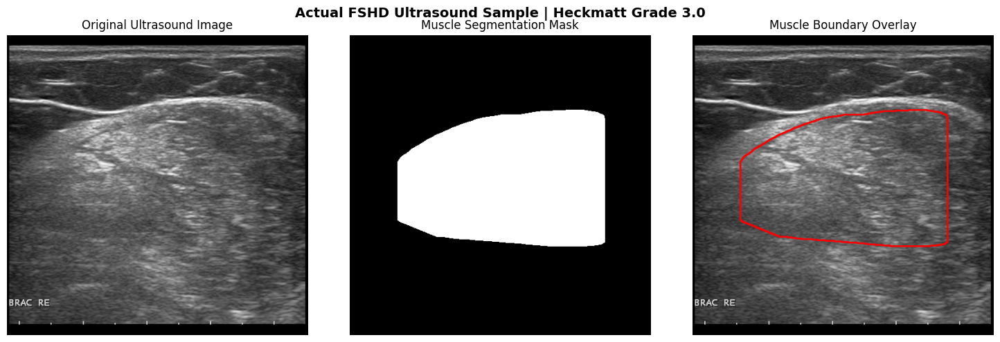


ACTUAL DATASET SAMPLE
Filename: 00006_001_00_1.png
Heckmatt Grade: 3.0
Image dimensions: (512, 512)
Mask dimensions: (512, 512)
Muscle pixels: 71388
Saved figure: /content/drive/MyDrive/Muscular_Dystrophy_Project/06_Final_Submission/Figures/Figure_3B_Actual_Ultrasound_Segmentation.png


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project directory
BASE = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

# Input paths
manifest_path = os.path.join(
    BASE,
    "02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/"
    "Audit_Results/Dataset_B_Image_Mask_Manifest.csv"
)

processed_mask_dir = os.path.join(
    BASE,
    "04_Preprocessing/Dataset_B_FSHD_Preprocessing/"
    "processed_masks"
)

# Output directory
output_dir = os.path.join(
    BASE, "06_Final_Submission/Figures"
)
os.makedirs(output_dir, exist_ok=True)

# Load manifest
df = pd.read_csv(manifest_path)

print("Total manifest records:", len(df))

# Select records with available labels
candidates = df[df["metadata_available"] == True].copy()

# Find a record with an existing original image and processed mask
selected = None

for _, row in candidates.iterrows():

    image_path = row["image_path"]

    mask_path = os.path.join(
        processed_mask_dir,
        os.path.basename(row["filename"])
    )

    if os.path.isfile(image_path) and os.path.isfile(mask_path):
        selected = row
        break

if selected is None:
    raise FileNotFoundError(
        "Could not find a matching image and processed mask."
    )

# Read actual image and mask
image_path = selected["image_path"]
mask_path = os.path.join(
    processed_mask_dir,
    os.path.basename(selected["filename"])
)

image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

if image is None or mask is None:
    raise ValueError("Could not read the selected image or mask.")

if image.shape != mask.shape:
    raise ValueError("Image and mask dimensions do not match.")

# Convert mask to binary
binary_mask = (mask > 0).astype(np.uint8)

if binary_mask.sum() == 0:
    raise ValueError("Selected mask is empty.")

# Create overlay with red muscle boundary
overlay = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)

contours, _ = cv2.findContours(
    binary_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

cv2.drawContours(
    overlay,
    contours,
    -1,
    (255, 0, 0),
    2
)

# Create three-panel research figure
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Ultrasound Image")

axes[1].imshow(binary_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Muscle Segmentation Mask")

axes[2].imshow(overlay)
axes[2].set_title("Muscle Boundary Overlay")

for ax in axes:
    ax.axis("off")

grade = selected["heckmatt_grade"]

fig.suptitle(
    f"Actual FSHD Ultrasound Sample | Heckmatt Grade {grade}",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

# Save high-resolution figure
figure_path = os.path.join(
    output_dir,
    "Figure_3B_Actual_Ultrasound_Segmentation.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nACTUAL DATASET SAMPLE")
print("Filename:", selected["filename"])
print("Heckmatt Grade:", grade)
print("Image dimensions:", image.shape)
print("Mask dimensions:", mask.shape)
print("Muscle pixels:", int(binary_mask.sum()))
print("Saved figure:", figure_path)

In [ ]:
import os
import pandas as pd
import json

BASE = "/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development"

files = {
    "CNN Confusion Matrix": (
        "Dataset_B_CNN_Baseline/evaluation_results/"
        "test_confusion_matrix.csv"
    ),
    "Radiomics Confusion Matrix": (
        "Dataset_B_Radiomics/XGBoost/"
        "Dataset_B_Radiomics_XGBoost_Test_Confusion_Matrix.csv"
    ),
    "Hybrid Confusion Matrix": (
        "Dataset_B_Hybrid_Fusion/Evaluation_Results/"
        "Hybrid_Test_Confusion_Matrix.csv"
    ),
    "CNN Classification Report": (
        "Dataset_B_CNN_Baseline/evaluation_results/"
        "test_classification_report.txt"
    ),
    "Radiomics Test Metrics": (
        "Dataset_B_Radiomics/XGBoost/"
        "Dataset_B_Radiomics_XGBoost_Test_Metrics.json"
    ),
    "Hybrid Test Metrics": (
        "Dataset_B_Hybrid_Fusion/Evaluation_Results/"
        "Hybrid_Test_Metrics.json"
    )
}

for name, relative_path in files.items():

    path = os.path.join(BASE, relative_path)

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    if not os.path.exists(path):
        print("FILE NOT FOUND:", path)
        continue

    if path.endswith(".csv"):
        display(pd.read_csv(path))

    elif path.endswith(".json"):
        with open(path, "r") as f:
            print(json.dumps(json.load(f), indent=4))

    elif path.endswith(".txt"):
        with open(path, "r") as f:
            print(f.read())


CNN Confusion Matrix


,Unnamed: 0,G1,G2,G3,G4
0,G1,49,21,1,0
1,G2,10,36,12,0
2,G3,0,5,59,4
3,G4,0,0,4,7



Radiomics Confusion Matrix


,Unnamed: 0,Pred_G1,Pred_G2,Pred_G3,Pred_G4
0,True_G1,175,44,0,0
1,True_G2,36,107,39,0
2,True_G3,2,22,168,18
3,True_G4,0,3,23,7



Hybrid Confusion Matrix


,Unnamed: 0,Pred_G1,Pred_G2,Pred_G3,Pred_G4
0,Actual_G1,52,18,1,0
1,Actual_G2,8,40,10,0
2,Actual_G3,2,10,54,2
3,Actual_G4,0,0,5,6



CNN Classification Report
              precision    recall  f1-score   support

          G1       0.83      0.69      0.75        71
          G2       0.58      0.62      0.60        58
          G3       0.78      0.87      0.82        68
          G4       0.64      0.64      0.64        11

    accuracy                           0.73       208
   macro avg       0.71      0.70      0.70       208
weighted avg       0.73      0.73      0.73       208


Radiomics Test Metrics
{
    "image_accuracy": 0.7096273291925466,
    "image_macro_f1": 0.603241555573717,
    "image_balanced_accuracy": 0.5997800145060419,
    "group_accuracy": 0.7259615384615384,
    "group_macro_f1": 0.6104248484902874,
    "group_balanced_accuracy": 0.6051565709952134,
    "test_images": 644,
    "test_groups": 208
}

Hybrid Test Metrics
{
    "test_groups": 208,
    "selected_boosting_rounds": 13,
    "accuracy": 0.7307692307692307,
    "macro_f1": 0.7077657912898188,
    "balanced_accuracy": 0.690405432781

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

print("PROJECT STRUCTURE")
print("=" * 80)

for root, dirs, files in os.walk(PROJECT):
    level = root.replace(PROJECT, "").count(os.sep)

    # Limit output depth to avoid listing thousands of dataset files
    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}📁 {os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    📄 {file}")

print("\nAUDIT COMPLETED")

Streaming output truncated to the last 5000 lines.
                📄 00201_001_00_1.png
                📄 00201_001_00_2.png
                📄 00201_001_00_3.png
                📄 00201_001_01_1.png
                📄 00201_001_01_2.png
                📄 00201_001_01_3.png
                📄 00201_002_00_1.png
                📄 00201_002_00_2.png
                📄 00201_002_00_3.png
                📄 00201_002_01_1.png
                📄 00201_002_01_2.png
                📄 00201_002_01_3.png
                📄 00201_003_00_1.png
                📄 00201_003_00_2.png
                📄 00201_003_00_3.png
                📄 00201_003_01_1.png
                📄 00201_003_01_2.png
                📄 00201_003_01_3.png
                📄 00201_004_00_1.png
                📄 00201_004_00_2.png
                📄 00201_004_00_3.png
                📄 00201_004_01_1.png
                📄 00201_004_01_2.png
                📄 00201_004_01_3.png
                📄 00201_008_00_1.png
                📄 00201_

In [3]:
import os

PROJECT = "/content/drive/MyDrive/Muscular_Dystrophy_Project"

extensions = (
    ".py", ".ipynb", ".json", ".yaml", ".yml",
    ".txt", ".md", ".sh"
)

print("CODE & DOCUMENTATION INVENTORY")
print("=" * 75)

for root, dirs, files in os.walk(PROJECT):

    # Ignore folders containing bulk image data
    dirs[:] = [
        d for d in dirs
        if d not in [
            "Images", "Masks", "processed_images",
            "processed_masks", "__pycache__"
        ]
    ]

    matching = [
        f for f in files
        if f.lower().endswith(extensions)
    ]

    if matching:
        relative = os.path.relpath(root, PROJECT)
        print(f"\n📁 {relative}/")

        for file in sorted(matching):
            print("   📄", file)

print("\nINVENTORY COMPLETED")

CODE & DOCUMENTATION INVENTORY

📁 ./
   📄 drive_write_test.txt

📁 02_Dataset_Audit/Dataset_A_MRI/Audit_Results/
   📄 Dataset_A_Initial_Audit_Report.txt

📁 02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Extracted_Files/Metadata/
   📄 README.txt

📁 02_Dataset_Audit/Dataset_B_FSHD_Ultrasound/Audit_Results/
   📄 Dataset_B_Experimental_Design_Protocol.md
   📄 Dataset_B_Final_Audit_Report.txt
   📄 Dataset_B_Split_Design_Record.json
   📄 Dataset_B_Subject_Mapping_Audit_Note.txt

📁 04_Preprocessing/
   📄 Dataset_B_FSHD_Preprocessing_Rupam.ipynb

📁 04_Preprocessing/Dataset_B_FSHD_Preprocessing/reports/
   📄 low_coverage_mask_review_decision.txt
   📄 preprocessing_progress.txt

📁 05_Model_Development/Dataset_B_CNN_Baseline/
   📄 CNN_Baseline_Methodology_and_Results.md
   📄 cnn_experiment_config.json

📁 05_Model_Development/Dataset_B_CNN_Baseline/evaluation_results/
   📄 experiment_summary.json
   📄 test_classification_report.txt
   📄 test_image_classification_report.json
   📄 test_image_verified_met

In [4]:
import os
import hashlib

BASE = "/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics"

files = [
    ("Dataset_B_Radiomics_Extraction.py",
     "Dataset_B_Radiomics_Extraction (1).py"),

    ("Dataset_B_Radiomics_Experiment_Config.json",
     "Dataset_B_Radiomics_Experiment_Config (1).json")
]

def get_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

for file1, file2 in files:
    path1 = os.path.join(BASE, file1)
    path2 = os.path.join(BASE, file2)

    print(f"\nComparing: {file1}")
    print(f"           {file2}")

    if os.path.exists(path1) and os.path.exists(path2):
        if get_hash(path1) == get_hash(path2):
            print("RESULT: Exact duplicates")
        else:
            print("RESULT: Different contents")
    else:
        print("RESULT: One or both files missing")


Comparing: Dataset_B_Radiomics_Extraction.py
           Dataset_B_Radiomics_Extraction (1).py
RESULT: Different contents

Comparing: Dataset_B_Radiomics_Experiment_Config.json
           Dataset_B_Radiomics_Experiment_Config (1).json
RESULT: Different contents


In [5]:
import os
import difflib

BASE = "/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development/Dataset_B_Radiomics"

pairs = [
    ("Dataset_B_Radiomics_Extraction.py",
     "Dataset_B_Radiomics_Extraction (1).py"),

    ("Dataset_B_Radiomics_Experiment_Config.json",
     "Dataset_B_Radiomics_Experiment_Config (1).json")
]

for file1, file2 in pairs:
    path1 = os.path.join(BASE, file1)
    path2 = os.path.join(BASE, file2)

    with open(path1, "r", encoding="utf-8") as f:
        text1 = f.readlines()

    with open(path2, "r", encoding="utf-8") as f:
        text2 = f.readlines()

    print("\n" + "=" * 80)
    print("COMPARISON:", file1, "vs", file2)
    print("=" * 80)

    diff = list(difflib.unified_diff(
        text1, text2,
        fromfile=file1,
        tofile=file2,
        n=3
    ))

    if diff:
        print("".join(diff[:250]))
        if len(diff) > 250:
            print("\n... Difference output truncated.")
    else:
        print("No textual differences.")


COMPARISON: Dataset_B_Radiomics_Extraction.py vs Dataset_B_Radiomics_Extraction (1).py
--- Dataset_B_Radiomics_Extraction.py
+++ Dataset_B_Radiomics_Extraction (1).py
@@ -1,81 +1,124 @@
 
 import pandas as pd
+import numpy as np
 import SimpleITK as sitk
+from pathlib import Path
 from radiomics import featureextractor
-from pathlib import Path
-import argparse
 
-def create_extractor():
-    settings = {
-        "binWidth": 25,
-        "label": 1,
-        "normalize": False,
-        "resampledPixelSpacing": None
-    }
+BASE = Path("/content/drive/MyDrive/Muscular_Dystrophy_Project/05_Model_Development")
 
-    extractor = featureextractor.RadiomicsFeatureExtractor(**settings)
-    extractor.disableAllFeatures()
+MANIFEST = BASE / "Dataset_B_Radiomics_Training_Manifest.csv"
+OUTPUT = BASE / "Dataset_B_Radiomics_Full_Training_Features.csv"
+ERRORS = BASE / "Dataset_B_Radiomics_Extraction_Errors.csv"
 
-    for feature_class in [
-        "firstorder", "glcm", "glrlm",
-        "gl

In [6]:
import pandas as pd
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

files = [
    "Dataset_B_Radiomics_Training_Features.csv",
    "Dataset_B_Radiomics_Validation_Features.csv",
    "Dataset_B_Radiomics_Test_Features.csv",
]

for filename in files:
    path = BASE / filename

    print("\n" + "=" * 65)
    print(filename)
    print("=" * 65)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(path, nrows=5)

    print("Columns:", len(df.columns))
    print("Sample rows:", len(df))
    print("First 20 columns:")
    print(df.columns[:20].tolist())

    feature_cols = [
        c for c in df.columns
        if c.startswith("original_")
    ]

    diagnostic_cols = [
        c for c in df.columns
        if c.startswith("diagnostics_")
    ]

    print("Original feature columns:", len(feature_cols))
    print("Diagnostic columns:", len(diagnostic_cols))


Dataset_B_Radiomics_Training_Features.csv
Columns: 110
Sample rows: 5
First 20 columns:
['filename', 'subject_id', 'muscle_code', 'side_code', 'side', 'group_id', 'heckmatt_grade', 'partition', 'original_shape2D_Elongation', 'original_shape2D_MajorAxisLength', 'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface', 'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter', 'original_shape2D_PerimeterSurfaceRatio', 'original_shape2D_PixelSurface', 'original_shape2D_Sphericity', 'original_firstorder_10Percentile', 'original_firstorder_90Percentile', 'original_firstorder_Energy']
Original feature columns: 102
Diagnostic columns: 0

Dataset_B_Radiomics_Validation_Features.csv
Columns: 110
Sample rows: 5
First 20 columns:
['filename', 'subject_id', 'muscle_code', 'side_code', 'side', 'group_id', 'heckmatt_grade', 'partition', 'original_shape2D_Elongation', 'original_shape2D_MajorAxisLength', 'original_shape2D_MaximumDiameter', 'original_shape2D_MeshSurface', 'original_sh

In [7]:
import pandas as pd
from pathlib import Path
from collections import Counter

BASE = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

files = [
    "Dataset_B_Radiomics_Training_Features.csv",
    "Dataset_B_Radiomics_Validation_Features.csv",
    "Dataset_B_Radiomics_Test_Features.csv"
]

feature_sets = {}

for filename in files:
    df = pd.read_csv(BASE / filename, nrows=0)

    features = [
        c for c in df.columns
        if c.startswith("original_")
    ]

    feature_sets[filename] = set(features)

    classes = Counter(
        c.split("_")[1]
        for c in features
    )

    print(f"\n{filename}")
    print("Feature count:", len(features))
    print("Feature classes:", dict(classes))

print("\n" + "=" * 60)
print("CROSS-SPLIT FEATURE CONSISTENCY")
print("=" * 60)

train = feature_sets[files[0]]

for filename in files[1:]:
    current = feature_sets[filename]

    print(filename)
    print("Same features:", train == current)
    print("Missing features:", len(train - current))
    print("Extra features:", len(current - train))


Dataset_B_Radiomics_Training_Features.csv
Feature count: 102
Feature classes: {'shape2D': 9, 'firstorder': 18, 'glcm': 24, 'glrlm': 16, 'glszm': 16, 'gldm': 14, 'ngtdm': 5}

Dataset_B_Radiomics_Validation_Features.csv
Feature count: 102
Feature classes: {'shape2D': 9, 'firstorder': 18, 'glcm': 24, 'glrlm': 16, 'glszm': 16, 'gldm': 14, 'ngtdm': 5}

Dataset_B_Radiomics_Test_Features.csv
Feature count: 102
Feature classes: {'shape2D': 9, 'firstorder': 18, 'glcm': 24, 'glrlm': 16, 'glszm': 16, 'gldm': 14, 'ngtdm': 5}

CROSS-SPLIT FEATURE CONSISTENCY
Dataset_B_Radiomics_Validation_Features.csv
Same features: True
Missing features: 0
Extra features: 0
Dataset_B_Radiomics_Test_Features.csv
Same features: True
Missing features: 0
Extra features: 0


In [10]:
import nbformat
from pathlib import Path

NOTEBOOK = Path(
    "/content/drive/MyDrive/Colab Notebooks/Step_2_Dataset_Audit.ipynb"
)

nb = nbformat.read(NOTEBOOK, as_version=4)

sections = {
    "CNN": range(99, 127),
    "Radiomics": range(127, 157),
    "Hybrid": range(157, 192),
    "SHAP": range(192, 201),
    "Statistics": range(201, 205)
}

for section, cell_range in sections.items():
    executed = 0
    with_output = 0

    for i in cell_range:
        if i >= len(nb.cells):
            continue

        cell = nb.cells[i]

        if cell.cell_type == "code":
            if cell.get("execution_count") is not None:
                executed += 1

            if cell.get("outputs"):
                with_output += 1

    print(
        f"{section}: "
        f"{executed} executed cells, "
        f"{with_output} cells with saved outputs"
    )

CNN: 0 executed cells, 27 cells with saved outputs
Radiomics: 0 executed cells, 30 cells with saved outputs
Hybrid: 0 executed cells, 35 cells with saved outputs
SHAP: 0 executed cells, 9 cells with saved outputs
Statistics: 0 executed cells, 4 cells with saved outputs


In [11]:
import shutil
from pathlib import Path

SOURCE = Path(
    "/content/drive/MyDrive/Colab Notebooks/Step_2_Dataset_Audit.ipynb"
)

DEST_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "06_Final_Submission/Original_Notebooks"
)

DEST_DIR.mkdir(parents=True, exist_ok=True)

DEST = DEST_DIR / "Step_2_Dataset_Audit_Original.ipynb"

shutil.copy2(SOURCE, DEST)

print("Original notebook preserved:", DEST.exists())
print("Backup location:", DEST)

Original notebook preserved: True
Backup location: /content/drive/MyDrive/Muscular_Dystrophy_Project/06_Final_Submission/Original_Notebooks/Step_2_Dataset_Audit_Original.ipynb


In [12]:
import nbformat
from pathlib import Path

NOTEBOOK = Path(
    "/content/drive/MyDrive/Colab Notebooks/Step_2_Dataset_Audit.ipynb"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "06_Final_Submission/Code_Review"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

nb = nbformat.read(NOTEBOOK, as_version=4)

output = []

for i in range(99, 127):
    cell = nb.cells[i]

    if cell.cell_type == "code" and cell.source.strip():
        output.append(
            f"\n# {'=' * 65}\n"
            f"# ORIGINAL NOTEBOOK CELL {i}\n"
            f"# {'=' * 65}\n\n"
            f"{cell.source}\n"
        )

output_path = OUTPUT_DIR / "CNN_Code_Review.py"
output_path.write_text("\n".join(output), encoding="utf-8")

print("CNN code extracted successfully.")
print("Code cells:", len(output))
print("Saved to:", output_path)

CNN code extracted successfully.
Code cells: 28
Saved to: /content/drive/MyDrive/Muscular_Dystrophy_Project/06_Final_Submission/Code_Review/CNN_Code_Review.py


In [13]:

import nbformat
from pathlib import Path

# Original notebook
notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/Step_2_Dataset_Audit.ipynb"
)

# Output location
output_path = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "06_Final_Submission/Code_Review/Radiomics_Code_Review.py"
)

# Load notebook
notebook = nbformat.read(notebook_path, as_version=4)

# Extract cells 127–156 (inclusive)
start_cell = 127
end_cell = 156

review_content = [
    '"""',
    "RADIOMICS CODE REVIEW",
    "Extracted from Step_2_Dataset_Audit.ipynb",
    f"Original notebook cells: {start_cell}–{end_cell}",
    "Original source preserved for code review.",
    '"""',
    ""
]

for index in range(start_cell, end_cell + 1):
    cell = notebook.cells[index]

    review_content.append(
        f"\n# {'=' * 70}\n"
        f"# ORIGINAL NOTEBOOK CELL {index} ({cell.cell_type.upper()})\n"
        f"# {'=' * 70}\n"
    )

    source = cell.source

    if cell.cell_type == "markdown":
        for line in source.splitlines():
            review_content.append("# " + line if line else "#")
    elif cell.cell_type == "code":
        review_content.append(source)

    review_content.append("\n")

# Save review file
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_text("\n".join(review_content), encoding="utf-8")

print("Radiomics review file created successfully!")
print("Location:", output_path)
print("Extracted cells:", start_cell, "to", end_cell)
print("Total cells:", end_cell - start_cell + 1)
print("File size:", output_path.stat().st_size, "bytes")


Radiomics review file created successfully!
Location: /content/drive/MyDrive/Muscular_Dystrophy_Project/06_Final_Submission/Code_Review/Radiomics_Code_Review.py
Extracted cells: 127 to 156
Total cells: 30
File size: 46524 bytes


In [14]:
from pathlib import Path

rad_dir = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

output_dir = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "06_Final_Submission/Code_Review"
)

scripts = [
    "Dataset_B_Radiomics_Extraction.py",
    "Dataset_B_Radiomics_Extraction (1).py"
]

output = []

for filename in scripts:
    path = rad_dir / filename

    output.append(f"\n{'='*80}")
    output.append(f"ORIGINAL FILE: {filename}")
    output.append(f"{'='*80}\n")

    output.append(path.read_text(encoding="utf-8"))

output_dir.mkdir(parents=True, exist_ok=True)

review_path = output_dir / "Radiomics_Extraction_Review.py"
review_path.write_text("\n".join(output), encoding="utf-8")

print("Created:", review_path)
print("Size:", review_path.stat().st_size, "bytes")

Created: /content/drive/MyDrive/Muscular_Dystrophy_Project/06_Final_Submission/Code_Review/Radiomics_Extraction_Review.py
Size: 6018 bytes


In [15]:

import nbformat
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/Step_2_Dataset_Audit.ipynb"
)

project_dir = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project"
)

notebook = nbformat.read(notebook_path, as_version=4)

keywords = [
    "XGBClassifier",
    "xgb.train",
    ".fit(",
    "early_stopping_rounds",
    "eval_metric",
    "best_iteration"
]

print("=" * 70)
print("XGBOOST TRAINING CODE SEARCH")
print("=" * 70)

for i, cell in enumerate(notebook.cells):
    if cell.cell_type != "code":
        continue

    source = cell.source
    matched = [word for word in keywords if word in source]

    if matched:
        print(f"\nCELL {i} | MATCHES: {matched}")
        print(source[:2500])
        print("-" * 70)

print("\nPYTHON FILES IN MODEL DEVELOPMENT")

model_dir = project_dir / "05_Model_Development"

for path in sorted(model_dir.rglob("*.py")):
    print(path)


XGBOOST TRAINING CODE SEARCH

CELL 145 | MATCHES: ['XGBClassifier', 'best_iteration']
import json
import os

MODEL_PATH = os.path.join(
    XGB_DIR,
    "Dataset_B_Radiomics_XGBoost.json"
)

import xgboost as xgb

model = xgb.XGBClassifier()
model.load_model(MODEL_PATH)

print("XGBOOST MODEL CONFIGURATION")
print("=" * 70)

config = json.loads(model.get_booster().save_config())

print(json.dumps(config, indent=2))

print("\nBEST ITERATION:", getattr(model, "best_iteration", "Not stored"))
print("BEST SCORE:", getattr(model, "best_score", "Not stored"))
print("NUMBER OF FEATURES:", model.n_features_in_)
print("NUMBER OF CLASSES:", model.n_classes_)
----------------------------------------------------------------------

CELL 185 | MATCHES: ['XGBClassifier', '.fit(', 'early_stopping_rounds', 'eval_metric', 'best_iteration']
import xgboost as xgb
import time

print("=" * 70)
print("CNN + RADIOMICS HYBRID MODEL TRAINING")
print("=" * 70)

fusion_model = xgb.XGBClassifier(
    objective="mul

In [16]:

import json
from pathlib import Path
import xgboost as xgb

rad_dir = Path(
    "/content/drive/MyDrive/Muscular_Dystrophy_Project/"
    "05_Model_Development/Dataset_B_Radiomics"
)

config_files = [
    "Dataset_B_Radiomics_Experiment_Config.json",
    "Dataset_B_Radiomics_Experiment_Config (1).json"
]

for filename in config_files:
    path = rad_dir / filename

    print("\n" + "=" * 70)
    print("CONFIGURATION:", filename)
    print("=" * 70)

    if path.exists():
        print(json.dumps(json.loads(path.read_text()), indent=2))
    else:
        print("FILE NOT FOUND")

model_path = (
    rad_dir / "XGBoost" /
    "Dataset_B_Radiomics_XGBoost.json"
)

print("\n" + "=" * 70)
print("SAVED RADIOMICS XGBOOST MODEL")
print("=" * 70)

if model_path.exists():
    model = xgb.XGBClassifier()
    model.load_model(str(model_path))

    print("Features:", model.n_features_in_)
    print("Classes:", model.n_classes_)
    print("Boosting rounds:", model.get_booster().num_boosted_rounds())
    print(json.dumps(json.loads(model.get_booster().save_config()), indent=2))
else:
    print("Saved model not found.")



CONFIGURATION: Dataset_B_Radiomics_Experiment_Config.json
{
  "dataset": "Dataset B - FSHD Ultrasound",
  "task": "Heckmatt grade classification",
  "image_count": 3342,
  "subjects": 76,
  "partition": "train",
  "label_column": "heckmatt_grade",
  "identifiers": [
    "subject_id",
    "muscle_code",
    "side_code",
    "group_id",
    "filename"
  ],
  "settings": {
    "binWidth": 25,
    "label": 1,
    "normalize": false,
    "resampledPixelSpacing": null
  },
  "feature_classes": [
    "firstorder",
    "glcm",
    "glrlm",
    "glszm",
    "gldm",
    "ngtdm",
    "shape2D"
  ]
}

CONFIGURATION: Dataset_B_Radiomics_Experiment_Config (1).json
{
  "dataset": "Dataset B - FSHD Ultrasound",
  "task": "Heckmatt grade classification",
  "image_count": 3342,
  "subjects": 76,
  "groups": 1029,
  "partition": "train",
  "label_column": "heckmatt_grade",
  "identifiers": [
    "subject_id",
    "muscle_code",
    "side_code",
    "group_id",
    "filename"
  ],
  "radiomics_settings":